<div style="background-color: #1a1a2e; padding: 20px; border-radius: 10px; text-align:center">

<h1 style="color:#f39c12">Global Economic Profiling</h1>
<h3 style="color:#aaaaaa">A Structural & Dynamic Analysis</h3>
</div>

<div style="background-color: #eaf2f8; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
# A. INTRODUCTION
</div>

**Context**

Economic indicators are the primary lens through which countries'
structural positions, growth dynamics, and relative performance are assessed.
This notebook analyzes a curated set of macroeconomic indicators across
the majority of the world's economies over a decade, sourced from
the World Bank Gold layer.

**Objective**

Build a comprehensive analytical framework covering five dimensions:

- **Descriptive** — global trends, distributions, stability, concentration
- **Comparative** — World vs countries, country vs country, multi-country
- **Structural** — correlations, PCA, clustering, convergence
- **Predictive** — Holt-Winters time series forecasting
- **Normative** — composite scoring combining value position and growth momentum

**This notebook is the second analytical layer** of the Global Economic
Profiling project — it feeds directly into the Trade × Economy synthesis,
where economic profiles are crossed with bilateral trade structures.

<div style="background-color: #eaf2f8; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
# B. Executive Summary
</div>

**Scope**

A curated set of macroeconomic indicators · ~180 countries · 2015–2024 · World Bank Gold layer

**Key Findings**

| Section | Key Finding |
|---|---|
| **E — Global** | Economic indicators are highly concentrated — a small number of countries dominates absolute levels. Cross-indicator stability varies widely between level and flow indicators. |
| **F — World Profile** | The World aggregate masks heterogeneity — global trends are driven by a handful of large economies whose cycles dominate the average. |
| **G — Country Profile** | Country-level profiles reveal structural divergences invisible at the global level — same indicator, very different trajectories depending on size and development stage. |
| **H — Comparisons** | Cross-country comparisons on index-100 and z-score reveal catch-up dynamics and structural outliers that absolute rankings miss. |
| **I — Growth** | The fastest-growing economies are not the largest. Eastern European economies consistently lead growth rankings across all scoring dimensions. |
| **J — Structure** | Two structural axes explain the majority of cross-country variance: development & openness (PC1) and monetary stability (PC2). The Fisher effect is clearly visible in the data. |
| **K — Convergence** | Both sigma and beta analyses point to divergence — the gap between Emerging and Developed economies is widening, not narrowing. |
| **L — Clusters** | Countries cluster into stable structural profiles. Growth-feature clustering (Mode A) produces sharper separation than PCA-based clustering (Mode B). |
| **M — Forecasting** | Holt-Winters time series forecasting projects indicator trajectories. Multi-indicator regression reveals which economic dimensions structurally predict others. |
| **N — Scoring** | Value and growth scores systematically diverge for the most analytically interesting economies. France (structural deceleration) and India (catch-up) are the clearest contrasting cases. |

**Central Finding**

> The most analytically valuable insight from this framework is not
> the absolute ranking of countries, but the **divergence between
> structural position (value) and momentum (growth)** — countries where
> these two dimensions point in opposite directions reveal the structural
> dynamics that standard rankings miss.

**Forward**

> These profiles feed directly into the Trade × Economy synthesis,
> where economic scoring is crossed with bilateral trade vulnerability
> to identify which macro fundamentals drive trade behavior.

<div style="background-color: #eaf2f8; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
# C. Data & Methodology
</div>

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 1. Data Scope
</div>

| Dimension | Details |
|---|---|
| **Source** | World Bank — Gold layer |
| **Period** | 2015 – 2024 |
| **Countries** | ~180 (COUNTRY entities only) |
| **Aggregates** | World + regional groups (excluded from most analyses) |
| **Indicators** | 16 macroeconomic indicators |
| **Coverage threshold** | 70% minimum non-null values per indicator |
| **Pipeline** | World Bank API → ETL (Bronze / Silver / Gold) → Gold layer consumed here |

**Indicators covered:**

| Family | Indicators |
|---|---|
| **Activity & Growth** | `GDP (current US$)`, `GDP per capita (current US\$)` |
| **Prices & Monetary** | `Inflation`, `consumer prices (annual %)`, `Real interest rate (%)` |
| **Labor market** | `Unemployment`, `total (% of total labor force, ILO)` |
| **Public finances** | `Expense (% of GDP)` |
| **External sector** | `Current account balance (BoP, US$)`, `Current account balance (% of GDP)`, `Trade (% of GDP), Exports (US$)`, `Exports (% of GDP)`, `Imports (US$)`, `Imports (% of GDP)` |
| **Investment & Debt** | `FDI net inflows (BoP, US$)`, `External debt stocks (DOD, US$)` |
| **Demographics** | `Population`, `total` |

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 2. Methodology Overview
</div>

| Section | Method | Output |
|---|---|---|
| **E** | CV, Gini, trend + structural breaks | Global stability & concentration |
| **F–G** | Entity-level stats, CAGR, growth profile | World & country profiles |
| **H** | Bilateral comparison, index-100, z-score | Positioning |
| **I** | CAGR, volatility, regimes, z-score shocks | `growth_df` |
| **J** | Pearson/Spearman correlation, PCA | Structure & latent axes |
| **L** | KMeans (growth features or PCA scores) | `cluster_df` |
| **K** | Sigma & beta convergence (intra + inter) | Convergence verdicts |
| **M** | Holt-Winters forecast, multi-indicator regression | Forecasts + feature importance |
| **N** | Weighted z-score (value) + weighted Min-Max (growth) | `multi_score_df` |

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 3. Design Choices
</div>

**Parametric design** — all analyses run on a single `indicator` parameter.
Changing it re-runs the full section on any indicator without code changes.

**COUNTRY entities only** — World and regional aggregates are excluded
from cross-country analyses (correlation, PCA, clustering, convergence)
to preserve statistical validity. World is analyzed separately in Section F.

**Double reading in scoring (Section N)** — each score is computed twice:
on indicator values (current position) and on growth_scores (momentum).
Same indicators, same weights — only the data changes.
This distinguishes structural position from directional momentum —
two countries with identical scores can be on opposite trajectories.

**Per-country median for full-period aggregation** — when reducing a
10-year panel to a single value per country, the median is used rather
than the mean. This is robust to the COVID 2020 outlier and consistent
with the full-period aggregation strategy applied in the Trade notebook.

**Indicator sample (16 indicators)** — the analysis covers a curated
subset of World Bank indicators chosen for broad coverage (>70% of countries)
and analytical complementarity across the five scoring dimensions.
This is a deliberate design choice, not a data limitation.

<div style="background-color: #eaf2f8; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
# D. Analytical Dataset Preparation
</div>

This section prepares the analytical dataset used throughout the notebook.
It covers data loading, dimension merging, quality assessment, and feature engineering.
All downstream analyses depend on the enriched dataframe `df` produced here.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 1. Imports & Configuration
</div>

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 1.1 Imports
</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy.stats import zscore, spearmanr
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:.4f}'.format)

from typing import Optional, List
#from adjustText import adjust_text
from pathlib import Path
from sklearn.preprocessing import RobustScaler, StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 1.2 Configuration
</div>

In [2]:
# ─── Paths ────────────────────────────────────────────────────────────────────
GOLD_ENTITIES_PATH          = "../../data/gold/entities/entities.csv"
GOLD_INDICATORS_PATH        = "../../data/gold/indicators/indicators.csv"
GOLD_INDICATORS_VALUES_PATH = "../../data/gold/indicators_values/indicators_values.csv"

# Folders
import os
os.makedirs("../Figures/Indicators", exist_ok=True)
os.makedirs("../Analysis_files/Indicators", exist_ok=True)

# ─── Working parameters (edit as needed) ──────────────────────────────────────
COVERAGE_THRESHOLD = 0.70   # minimum acceptable coverage rate per indicator
MIN_YEARS          = 5      # minimum years needed for growth analysis

# ─── Global visual style (dark theme — consistent with Trade notebook) ─────────
mpl.rcParams.update({
    "figure.figsize"    : (12, 6),
    "axes.titlesize"    : 14,
    "axes.titleweight"  : "bold",
    "axes.labelsize"    : 11,
    "xtick.labelsize"   : 9,
    "ytick.labelsize"   : 9,
    "lines.linewidth"   : 2,
    "axes.grid"         : True,
    "grid.alpha"        : 0.3,
})

# ─── Color palette ────────────────────────────────────────────────────────────
C = {
    "blue"   : "#3498db",
    "red"    : "#e74c3c",
    "green"  : "#2ecc71",
    "orange" : "#f39c12",
    "purple" : "#9b59b6",
    "teal"   : "#1abc9c",
    "grey"   : "#aaaaaa",
    "bg"     : "#1a1a2e",
    "ax_bg"  : "#16213e",
    "spine"  : "#444466",
}

# ─── Style helpers ────────────────────────────────────────────────────────────
def apply_dark_style(ax, fig=None):
    """Apply dark theme to a single axis."""
    if fig:  fig.patch.set_facecolor(C["bg"])
    ax.set_facecolor(C["ax_bg"])
    ax.tick_params(colors="white")
    ax.xaxis.label.set_color("white")
    ax.yaxis.label.set_color("white")
    ax.title.set_color("white")
    for spine in ax.spines.values():   spine.set_edgecolor(C["spine"])

def styled_figure(figsize=(12, 6)):
    """Single-axis dark figure."""
    fig, ax = plt.subplots(figsize=figsize)
    apply_dark_style(ax, fig)
    return fig, ax

def styled_subplots(nrows=1, ncols=2, figsize=(18, 6)):
    """Multi-axis dark figure."""
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    fig.patch.set_facecolor(C["bg"])
    axes_flat = axes.flatten() if hasattr(axes, "flatten") else [axes]
    for ax in axes_flat:        apply_dark_style(ax)
    return fig, axes

def add_legend(ax, **kwargs):
    """Styled dark legend."""
    defaults = dict(fontsize=9, facecolor=C["bg"], edgecolor=C["spine"], labelcolor="white")
    defaults.update(kwargs)
    ax.legend(**defaults)

def _format_value(x):
    """Human-readable number formatting."""
    if abs(x) >= 1e12: return f"{x/1e12:.2f}T"
    if abs(x) >= 1e9:  return f"{x/1e9:.2f}B"
    if abs(x) >= 1e6:  return f"{x/1e6:.1f}M"
    if abs(x) >= 1e3:  return f"{x/1e3:.1f}K"
    return f"{x:.2f}"

def save_figure(fig, filename, dpi=150):
    """Save figure with consistent settings"""
    plt.tight_layout()
    plt.savefig(filename, dpi=dpi, bbox_inches='tight', facecolor=fig.get_facecolor())
    plt.show()

def _set_plot_style():
    sns.set_theme(style="whitegrid", context="talk")
    plt.rcParams["axes.titleweight"] = "bold"
    plt.rcParams["axes.labelweight"] = "bold"

# Indicator safe names
INDICATOR_SAFE_NAMES = {
    "GDP (current US$)"                                          : "GDP_USD",
    "GDP per capita (current US$)"                               : "GDP_per_capita_USD",
    "Inflation, consumer prices (annual %)"                      : "Inflation_pct",
    "Exports of goods and services (current US$)"                : "Exports_USD",
    "Imports of goods and services (current US$)"                : "Imports_USD",
    "Exports of goods and services (% of GDP)"                   : "Exports_pct_GDP",
    "Imports of goods and services (% of GDP)"                   : "Imports_pct_GDP",
    "Trade (% of GDP)"                                           : "Trade_pct_GDP",
    "Current account balance (BoP, current US$)"                 : "Current_account_USD",
    "Current account balance (% of GDP)"                         : "Current_account_pct_GDP",
    "Foreign direct investment, net inflows (BoP, current US$)"  : "FDI_USD",
    "Unemployment, total (% of total labor force) (modeled ILO estimate)" : "Unemployment_pct",
    "Population, total"                                          : "Population",
    "Real interest rate (%)"                                     : "Real_interest_rate",
    "Expense (% of GDP)"                                         : "Expense_pct_GDP",
    "External debt stocks, total (DOD, current US$)"             : "External_debt_USD",
}

def safe_indicator_name(indicator_name: str) -> str:
    """Return filesystem-safe short name for an indicator."""
    return INDICATOR_SAFE_NAMES.get(indicator_name)

# ── Annotation style ──────────────────────────────────────────────────────────
ANNOT_STYLE = dict(textcoords='offset points', fontsize=9, ha='center')
ANNOT_POS   = dict(above=dict(xytext=(0,  10), **ANNOT_STYLE), below=dict(xytext=(0, -15), **ANNOT_STYLE))

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 2. Loading Gold Datasets
</div>

In [3]:
entities = pd.read_csv(GOLD_ENTITIES_PATH)
indicators = pd.read_csv(GOLD_INDICATORS_PATH)
indicators_values = pd.read_csv(GOLD_INDICATORS_VALUES_PATH)

print(f"📦 entities          : {entities.shape}")
print(f"📦 indicators        : {indicators.shape}")
print(f"📦 indicators_values : {indicators_values.shape}")

📦 entities          : (312, 9)
📦 indicators        : (16, 5)
📦 indicators_values : (42560, 5)


In [4]:
entities.sample()

,entity_key,country_id,country_code,country_iso3,country_name,wb_country_code,wb_country_iso3,wb_country_name,entity_type
36,37,BZ,84.0000,BLZ,Belize,84.0000,BLZ,Belize,COUNTRY


In [5]:
indicators.sample()

,indicator_key,indicator_code,indicator_name,indicator_description,indicator_unit
12,13,NY.GDP.MKTP.CD,GDP (current US$),Total value of goods and services produced wit...,USD


In [6]:
indicators_values.sample()

,indicator_value_key,indicator_key,entity_key,year,value
27694,27695,11,133,2019,126.4283


<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 3. Merging Dimensions
</div>

In [30]:
# ─── Join indicator metadata ───────────────────────────────────────────────────
df = indicators_values.merge(indicators, on="indicator_key", how="left", validate="many_to_one")

# ─── Join entity metadata ──────────────────────────────────────────────────────
df = df.merge(entities, on="entity_key", how="left", validate="many_to_one")

# ─── Select & order columns ────────────────────────────────────────────────────
df = df[["entity_key", "entity_type", "country_code", "wb_country_code", "country_name", "wb_country_name", "country_iso3", "wb_country_iso3", 
         "indicator_code", "indicator_name", "indicator_unit", "year", "value"]]

# ─── Sort ──────────────────────────────────────────────────────────────────────
df = df.sort_values(["indicator_code", "country_name", "year"]).reset_index(drop=True)

print(f"✅ Final shape  : {df.shape}")
print(f"📅 Period       : {df['year'].min()} – {df['year'].max()}")
print(f"🌍 Entities     : {df['entity_key'].nunique()}")
print(f"📊 Indicators   : {df['indicator_code'].nunique()}")

✅ Final shape  : (42560, 13)
📅 Period       : 2015 – 2024
🌍 Entities     : 266
📊 Indicators   : 16


In [8]:
df.sample()

,entity_key,entity_type,country_code,wb_country_code,country_name,wb_country_name,country_iso3,wb_country_iso3,indicator_code,indicator_name,indicator_unit,year,value
1524,149,COUNTRY,410.0000,410.0000,Rep. of Korea,South Korea,KOR,KOR,BN.CAB.XOKA.CD,"Current account balance (BoP, current US$)",USD,2019,59676100000.0000


<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 4. Data Quality Checks
</div>

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 4.1 Descriptive Statistics by Indicator
</div>

In [31]:
stats_df = (df.dropna(subset=["value"]).groupby(["indicator_code", "indicator_name", "indicator_unit"])["value"]
            .describe().round(2).reset_index())
stats_df.style.format({col: _format_value for col in ["mean", "std", "min", "25%", "50%", "75%", "max"]}
                     ).background_gradient(subset=["mean", "std"], cmap="Blues")

,indicator_code,indicator_name,indicator_unit,count,mean,std,min,25%,50%,75%,max
0,BN.CAB.XOKA.CD,"Current account balance (BoP, current US$)",USD,1821.000000,3.34B,70.62B,-1.19T,-2.04B,-339.1M,857.1M,446.38B
1,BN.CAB.XOKA.GD.ZS,Current account balance (% of GDP),%,1810.000000,-2.31,10.13,-57.11,-6.77,-2.26,2.13,60.92
2,BX.KLT.DINV.CD.WD,"Foreign direct investment, net inflows (BoP, current US$)",USD,2454.000000,60.33B,221.27B,-343.40B,178.5M,1.52B,19.09B,2.79T
3,DT.DOD.DECT.CD,"External debt stocks, total (DOD, current US$)",USD,1324.000000,297.36B,1.12T,80.9M,3.34B,13.56B,62.96B,8.94T
4,FP.CPI.TOTL.ZG,"Inflation, consumer prices (annual %)",%,1832.000000,7.26,24.46,-12.30,1.25,3.05,6.28,557.20
5,FR.INR.RINR,Real interest rate (%),%,1126.000000,4.82,11.84,-89.47,1.60,4.93,8.63,57.63
6,GC.XPN.TOTL.GD.ZS,Expense (% of GDP),% of GDP,1369.000000,27.38,11.96,3.14,18.17,26.98,34.46,103.60
7,NE.EXP.GNFS.CD,Exports of goods and services (current US$),USD,2231.000000,945.85B,3.06T,10.8M,4.68B,34.29B,366.29B,32.30T
8,NE.EXP.GNFS.ZS,Exports of goods and services (% of GDP),% of GDP,2235.000000,40.29,30.06,0.72,22.02,31.50,49.14,222.31
9,NE.IMP.GNFS.CD,Imports of goods and services (current US$),USD,2242.000000,920.04B,2.96T,89.7M,6.22B,33.25B,368.21B,31.28T


<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">

### 4.2 Data Coverage Analysis
</div>

In [32]:
def compute_coverage(df: pd.DataFrame, threshold: float = COVERAGE_THRESHOLD) -> pd.DataFrame:
    """    Compute data coverage per indicator × country. Returns summary with avg coverage and low-coverage flag.    """
    # Coverage rate per indicator × country
    coverage_df = (df.groupby(["indicator_name", "country_name"])["value"].apply(lambda x: x.notna().mean()).reset_index(name="coverage_rate"))

    # Summary per indicator
    summary_df = (coverage_df.groupby("indicator_name")
                  .agg(avg_coverage   = ("coverage_rate", "mean"),pct_countries  = ("coverage_rate", lambda x: (x >= threshold).mean())).reset_index())
    summary_df["low_coverage_flag"] = summary_df["avg_coverage"] < threshold
    summary_df = summary_df.sort_values("avg_coverage", ascending=False)
    return coverage_df, summary_df

In [33]:
coverage_df, summary_df = compute_coverage(df)

In [34]:
n_low = summary_df["low_coverage_flag"].sum()
print(f"⚠️  Indicators below {COVERAGE_THRESHOLD:.0%} coverage threshold : {n_low} / {len(summary_df)}")

summary_df.style.format({"avg_coverage": "{:.1%}", "pct_countries": "{:.1%}"}).background_gradient(subset=["avg_coverage"], cmap="RdYlGn")

⚠️  Indicators below 70% coverage threshold : 3 / 16


,indicator_name,avg_coverage,pct_countries,low_coverage_flag
12,"Population, total",100.0%,100.0%,False
7,GDP (current US$),96.4%,96.7%,False
8,GDP per capita (current US$),96.4%,96.7%,False
6,"Foreign direct investment, net inflows (BoP, current US$)",93.8%,93.3%,False
15,"Unemployment, total (% of total labor force) (modeled ILO estimate)",87.7%,88.1%,False
11,"Inflation, consumer prices (annual %)",85.8%,84.8%,False
1,"Current account balance (BoP, current US$)",85.8%,84.8%,False
0,Current account balance (% of GDP),85.7%,84.8%,False
14,Trade (% of GDP),84.7%,85.2%,False
9,Imports of goods and services (% of GDP),84.7%,85.2%,False


<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">

#### 4.2.1 Coverage Heatmap — Indicator × Year
</div>

In [35]:
def plot_coverage_heatmap(df: pd.DataFrame, threshold: float = COVERAGE_THRESHOLD) -> None:
    """    Heatmap of data coverage (%) per indicator × year.    Flags indicators with low coverage on the right margin.    """
    total_countries = df[df["entity_type"] == "COUNTRY"]["country_name"].nunique()

    # Pivot: indicator × year → coverage %
    coverage_pivot = (df[df["entity_type"] == "COUNTRY"].dropna(subset=["value"])
        .groupby(["indicator_code", "year"])["country_name"].nunique().reset_index(name="n_countries"))
    coverage_pivot["coverage_pct"] = coverage_pivot["n_countries"] / total_countries * 100
    pivot = coverage_pivot.pivot(index="indicator_code", columns="year", values="coverage_pct")

    # Weak indicator set
    weak = set(coverage_pivot.loc[coverage_pivot["coverage_pct"] < threshold * 100, "indicator_code"])

    # ── Plot ──────────────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(14, max(6, len(pivot) * 0.45)))
    fig.patch.set_facecolor(C["bg"])
    ax.set_facecolor(C["ax_bg"])

    sns.heatmap(pivot, ax=ax, cmap="YlGnBu", linewidths=0.4, linecolor="#1a1a2e", cbar_kws={"label": "Coverage (%)", "shrink": 0.7}, vmin=0, vmax=100)

    ax.set_title("Data Coverage by Indicator & Year\n(% of countries with non-missing values)", fontsize=13, color="white", pad=14)
    ax.set_xlabel("Year", color="white")
    ax.set_ylabel("", color="white")
    ax.tick_params(colors="white", labelsize=8)
    ax.tick_params(axis="x", rotation=45)

    # Colorbar style
    cbar = ax.collections[0].colorbar
    cbar.ax.yaxis.label.set_color("white")
    cbar.ax.tick_params(colors="white")

    # Flag weak indicators
    for idx, ind_code in enumerate(pivot.index):
        if ind_code in weak:
            ax.text(pivot.shape[1] + 0.2, idx + 0.5, "⚠ low", va="center", fontsize=8, color="#e74c3c")

    plt.tight_layout()
    save_figure(fig, '../Figures/Indicators/D_4_2_1_coverage_heatmap.png')
    plt.show()
    return pivot

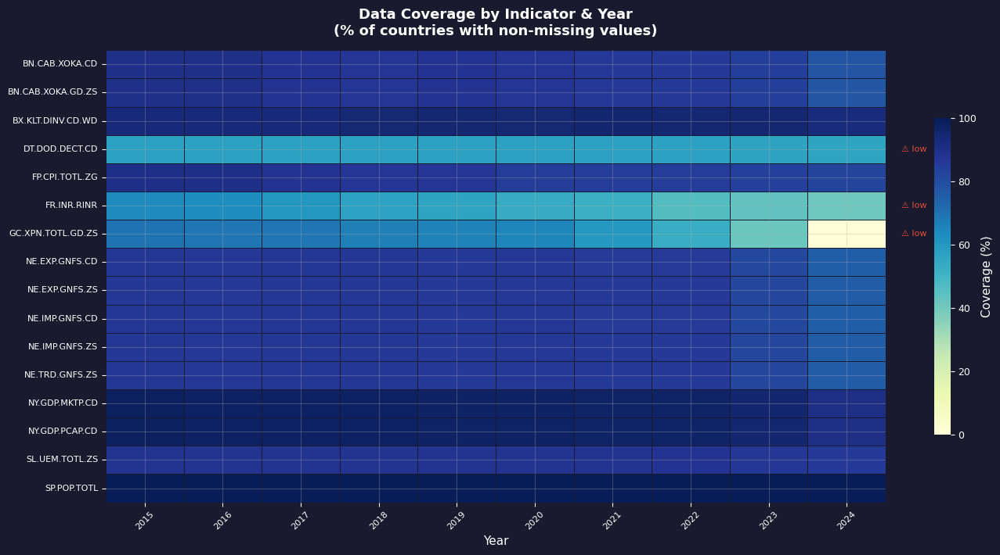

In [36]:
pivot = plot_coverage_heatmap(df)

In [37]:
pivot.sample()

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
indicator_code,,,,,,,,,,
NE.IMP.GNFS.ZS,86.6029,86.1244,86.6029,86.6029,85.6459,86.1244,85.6459,85.6459,81.8182,75.5981


**Coverage Insights**

- Most indicators show stable, high coverage (>80%) throughout the 2015–2024 period — confirming reliable World Bank data sourcing.
- Indicators flagged ⚠ with coverage below the threshold should be interpreted with caution in country-level comparisons.
- Coverage is generally consistent year-over-year, with no structural data gap
  after 2020 — suggesting the COVID period is well-represented in the dataset
  and does not introduce systematic missing-data bias.

<div style="background-color: #fef9e7; padding-left: 20px; border: 1px solid; border-radius: 5px;">

#### 4.2.2 Coverage Distribution — All Indicators
</div>

In [38]:
def plot_coverage_distribution(summary_df: pd.DataFrame, threshold: float = COVERAGE_THRESHOLD) -> None:
    """   Bar chart of average coverage per indicator.   Color-coded by coverage quality.    """
    df_plot = summary_df.sort_values("avg_coverage")
    colors  = [C["red"] if x < threshold else C["green"] for x in df_plot["avg_coverage"]]

    fig, ax = styled_figure(figsize=(13, max(5, len(df_plot) * 0.45)))
    ax.set_title("Average Data Coverage per Indicator", fontsize=13, color="white", pad=12)

    bars = ax.barh(df_plot["indicator_name"], df_plot["avg_coverage"] * 100, color=colors, edgecolor="none", height=0.7)

    # Threshold line
    ax.axvline(threshold * 100, color=C["orange"], linewidth=1.5, linestyle="--", label=f"Threshold ({threshold:.0%})")

    # Value annotations
    for bar, val in zip(bars, df_plot["avg_coverage"]):
        ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2, f"{val:.0%}", va="center", color="white", fontsize=8)

    ax.set_xlabel("Average Coverage (%)", color="white")
    ax.set_xlim(0, 110)
    add_legend(ax)
    plt.tight_layout()
    save_figure(fig, '../Figures/Indicators/D_4_2_2_coverage_distribution.png')
    plt.show()

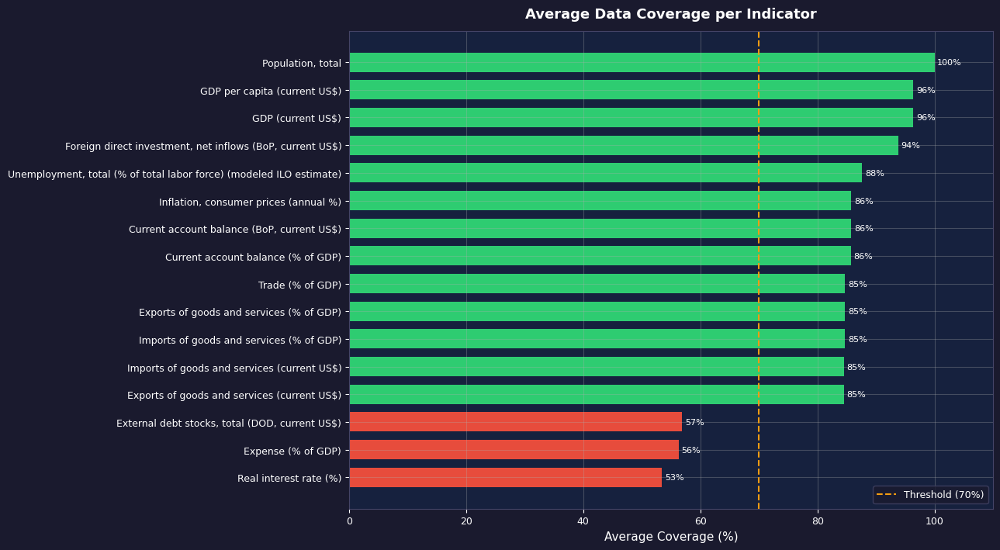

In [39]:
plot_coverage_distribution(summary_df)

**Coverage Distribution Insights**

- The majority of indicators have high average coverage, validating the dataset's robustness for cross-country analysis.
- Indicators below the threshold (red) should be used selectively — preferably for trend analysis rather than cross-country ranking.
- The orange threshold line provides a clear decision boundary for inclusion/exclusion in multi-indicator analyses.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
## 5. Feature Engineering
</div>

The following derived features are computed once here and used throughout all downstream analyses.

| Feature | Formula | Purpose |
|---|---|---|
| `yoy_growth` | `value.pct_change()` per entity × indicator | YoY growth rate |
| `abs_growth` | `value.diff()` per entity × indicator | Absolute change |
| `index_100` | `value / first_value × 100` | Comparable trend base |
| `z_score` | `(value − mean) / std` per indicator × year | Cross-country standardized comparison |

In [40]:
df = df.sort_values(["entity_key", "indicator_code", "year"]).copy()

# growth (% and absolute)
df["yoy_growth"] = (df.groupby(["entity_key", "indicator_code"])["value"].pct_change(fill_method=None))
df["abs_growth"] = (df.groupby(["entity_key", "indicator_code"])["value"].diff())

# Index base 100 (first non-null year)
df["index_100"] = (df["value"] / df.groupby(["entity_key", "indicator_code"])["value"].transform("first")) * 100

# Z-score (countries only, per indicator × year) 
df["z_score"] = np.nan
mask_country = df["entity_type"] == "COUNTRY"
df.loc[mask_country, "z_score"] = (df.loc[mask_country].groupby(["indicator_code", "year"])["value"].transform(lambda x: (x - x.mean()) / x.std()))

print(f"✅ Features added : yoy_growth | abs_growth | index_100 | z_score ")
print(f"📐 Final df shape : {df.shape}")

✅ Features added : yoy_growth | abs_growth | index_100 | z_score 
📐 Final df shape : (42560, 17)


In [41]:
df.sample()

,entity_key,entity_type,country_code,wb_country_code,country_name,wb_country_name,country_iso3,wb_country_iso3,indicator_code,indicator_name,indicator_unit,year,value,yoy_growth,abs_growth,index_100,z_score
29778,68,COUNTRY,196.0000,196.0000,Cyprus,Cyprus,CYP,CYP,NE.TRD.GNFS.ZS,Trade (% of GDP),%,2023,190.7408,-0.0730,-15.0128,138.9465,1.5728


<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">

### 5.1 Feature Completeness Check
</div>

In [42]:
def plot_feature_completeness(df: pd.DataFrame) -> None:
    """    Horizontal bar chart showing non-null rate for each column.    Separates base columns from engineered features.    """
    cols_of_interest  = ["value", "yoy_growth", "abs_growth", "index_100", "z_score"]
    completeness      = df[cols_of_interest].notna().mean().sort_values() * 100
    colors_bar        = [C["green"] if v >= 70 else C["orange"] if v >= 60 else C["red"] for v in completeness]

    fig, ax = styled_figure(figsize=(10, 4))
    ax.set_title("Feature Completeness (% non-null values)", fontsize=13, color="white", pad=12)

    bars = ax.barh(completeness.index, completeness.values, color=colors_bar, edgecolor="none", height=0.55)

    for bar, val in zip(bars, completeness.values):
        ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2, f"{val:.1f}%", va="center", color="white", fontsize=9)

    ax.axvline(80, color=C["orange"], linewidth=1.2, linestyle="--", alpha=0.7, label="70% threshold")
    ax.set_xlabel("Completeness (%)", color="white")
    ax.set_xlim(0, 115)
    add_legend(ax)
    plt.tight_layout()
    save_figure(fig, '../Figures/Indicators/D_5_1_feature_completeness.png')
    plt.show()

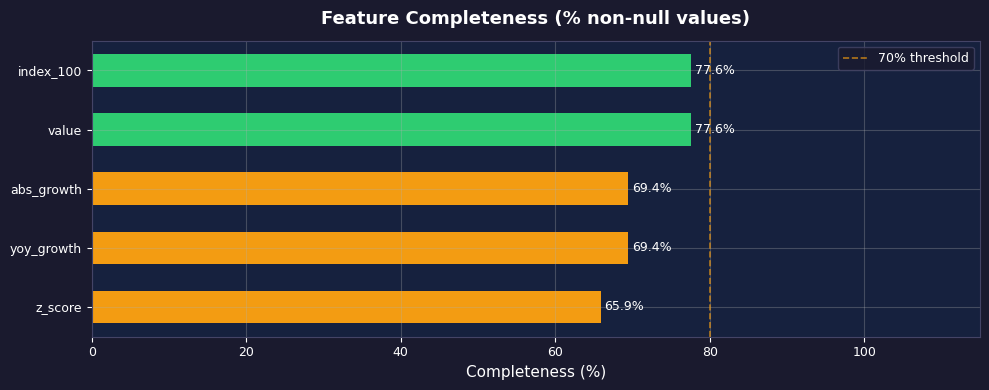

In [43]:
plot_feature_completeness(df)

**Feature Completeness Insights**

- `value` completeness reflects raw data quality — gaps here propagate to all derived features.
- `yoy_growth` and `abs_growth` will always have ~1 fewer year per series than `value`, explaining their slightly lower completeness.
- `z_score` is only computed for `COUNTRY` entities by design — lower completeness is expected and correct.
- `index_100` requires a valid first observation; any entity with a missing initial year will carry NaN — these are edge cases.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">

### 5.2 Save Table
</div>

In [44]:
df.to_csv("../Analysis_files/Indicators/df_indicators.csv", index=False)

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 6. Dataset Summary
</div>

In [45]:
def print_dataset_summary(df: pd.DataFrame) -> None:
    """Print a structured summary of the analytical dataset."""
    n_countries  = df[df["entity_type"] == "COUNTRY"]["country_name"].nunique()
    n_aggregates = df[df["entity_type"] != "COUNTRY"]["country_name"].nunique()
    n_indicators = df["indicator_code"].nunique()
    year_min, year_max = df["year"].min(), df["year"].max()
    n_obs        = len(df)
    missing_pct  = df["value"].isna().mean() * 100

    print("═" * 55)
    print("  ANALYTICAL DATASET — SUMMARY")
    print("═" * 55)
    print(f"  📅 Period          : {year_min} – {year_max}")
    print(f"  🌍 Countries       : {n_countries}")
    print(f"  🌐 Aggregates      : {n_aggregates}  (e.g. World, regions)")
    print(f"  📊 Indicators      : {n_indicators}")
    print(f"  📐 Total rows      : {n_obs:,}")
    print(f"  ⚠️  Missing values  : {missing_pct:.1f}%")
    print("═" * 55)
    print("  ENGINEERED FEATURES")
    print("  yoy_growth  │ abs_growth  │ index_100 │ z_score")
    print("═" * 55)

In [46]:
print_dataset_summary(df)

═══════════════════════════════════════════════════════
  ANALYTICAL DATASET — SUMMARY
═══════════════════════════════════════════════════════
  📅 Period          : 2015 – 2024
  🌍 Countries       : 209
  🌐 Aggregates      : 1  (e.g. World, regions)
  📊 Indicators      : 16
  📐 Total rows      : 42,560
  ⚠️  Missing values  : 22.4%
═══════════════════════════════════════════════════════
  ENGINEERED FEATURES
  yoy_growth  │ abs_growth  │ index_100 │ z_score
═══════════════════════════════════════════════════════


**Key Takeaways**

- The analytical dataset combines three gold-layer tables into a single enriched dataframe covering the full 2015–2024 period.
- Data quality is overall strong, with most indicators exceeding the 70% coverage threshold across countries and years.
- Four engineered features (`yoy_growth`, `abs_growth`, `index_100`, `z_score`) are ready for use in all downstream sections.
- Z-scores are computed at the indicator × year level across COUNTRY entities only —
  aggregate entities (World, regions) are excluded from normalization by design.
- The dataset is the single source of truth for all analyses in Sections F through O.

<div style="background-color: #eaf2f8; padding-left: 20px; border: 1px solid; border-radius: 5px;">

# E. Vision Globale
</div>

This section provides a global view of each indicator across all countries and years.
All analyses are **parametric** — set `indicator` below to run the full section on any indicator.
The focus is on aggregate behavior: trend, distribution, stability, concentration, growth dynamics, and ranking.

In [47]:
# Indicator parameter
indicator = "GDP (current US$)"
ind_name =  df.loc[df["indicator_name"] == indicator, "indicator_code"].dropna().iloc[0]
# countries to highlight
highlight_countries = ["USA", "China", "Germany", "France", "India"]

# Indicator unit for axis labels
unit = df.loc[df["indicator_name"] == indicator, "indicator_unit"].dropna().iloc[0]
print(f"📊 Indicator : {indicator}")
print(f"📐 Unit      : {unit}")

📊 Indicator : GDP (current US$)
📐 Unit      : USD


<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 1. Trend — Global Average over Time
</div>

In [48]:

def compute_global_trend(df: pd.DataFrame, indicator_name: str) -> pd.DataFrame:
    """    Compute cross-country average value per year for a given indicator.    Adds YoY growth rate column.    """
    
    df_c = df[(df["entity_type"] == "COUNTRY") & (df["indicator_name"] == indicator_name)]
    trend = (df_c.groupby("year")["value"].mean().reset_index().sort_values("year"))
    trend["growth_yoy"] = trend["value"].pct_change()
    
    return trend

In [49]:
def compute_average_growth(df_trend: pd.DataFrame, start_year: int | None = None, end_year:   int | None = None) -> float:
    """Mean of YoY growth over the specified period."""
    data = df_trend.copy()
    if start_year: data = data[data["year"] >= start_year]
    if end_year:   data = data[data["year"] <= end_year]
    
    return data["growth_yoy"].mean()

In [50]:
def detect_structural_breaks(df_trend: pd.DataFrame, threshold: float = 0.07) -> pd.DataFrame:
    """  Flag years where absolute YoY growth exceeds threshold.  """
    
    if df_trend.empty or "growth_yoy" not in df_trend.columns:       return pd.DataFrame()
    
    return df_trend.loc[df_trend["growth_yoy"].abs() >= threshold, ["year", "value", "growth_yoy"]].copy()

In [51]:
def plot_global_trend(df_trend: pd.DataFrame, indicator_name: str, indicator_unit: str, avg_growth: float | None = None, 
                      breaks: pd.DataFrame | None = None, figsize: tuple = (12, 5)) -> None:
    """    Line chart of global average trend.   Annotates structural breaks and average growth rate.    """
    
    if df_trend.empty:        return
    fig, ax = styled_figure(figsize=figsize)

    # Main line 
    ax.plot(df_trend["year"], df_trend["value"], color=C["blue"], linewidth=2.5, marker="o", markersize=6, zorder=3)
    ax.fill_between(df_trend["year"], df_trend["value"], alpha=0.15, color=C["blue"])

    # Structural breaks
    if breaks is not None and not breaks.empty:
        break_vals = df_trend.set_index("year").loc[breaks["year"], "value"]
        ax.scatter(breaks["year"], break_vals, color=C["red"], s=90, zorder=5, label="Structural break")
        for _, row in breaks.iterrows():
            y_val = df_trend.loc[df_trend["year"] == row["year"], "value"].values[0]
            ax.annotate(f"{row['growth_yoy']:+.1%}", xy=(row["year"], y_val), xytext=(0, 14), textcoords="offset points",
                        ha="center", fontsize=8.5, color=C["red"], fontweight="bold", arrowprops=dict(arrowstyle="->", color=C["red"], lw=0.9))

    # Average growth annotation 
    if avg_growth is not None and pd.notna(avg_growth):
        ax.text(0.8, 0.1, f"Avg annual growth : {avg_growth:+.2%}", transform=ax.transAxes, ha="left", va="top", fontsize=10, 
                color="white", bbox=dict(boxstyle="round,pad=0.4", facecolor=C["ax_bg"], edgecolor=C["spine"], alpha=0.85))

    ax.set_title(f"Global Average Trend — {indicator_name}", fontsize=13, color="white", pad=12)
    ax.set_xlabel("Year", color="white")
    ax.set_ylabel(indicator_unit, color="white")
    ax.set_xticks(df_trend["year"])
    ax.tick_params(axis="x", rotation=45)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x/1e12:.1f}T' if x >= 1e12 else f'${x/1e9:.0f}B'))
    if breaks is not None and not breaks.empty:     add_legend(ax)
    
    plt.tight_layout()
    save_figure(fig, '../Figures/Indicators/E_1_global_average_trend.png')
    plt.show()

In [52]:
df_trend   = compute_global_trend(df, indicator)
df_trend.sample()

,year,value,growth_yoy
9,2024,572196182381.0050,0.0931


In [53]:
avg_growth = compute_average_growth(df_trend)
avg_growth

np.float64(0.05521444165731743)

In [54]:
breaks  = detect_structural_breaks(df_trend, threshold=0.07)
breaks.sample()

,year,value,growth_yoy
6,2021,464976242868.9847,0.1409


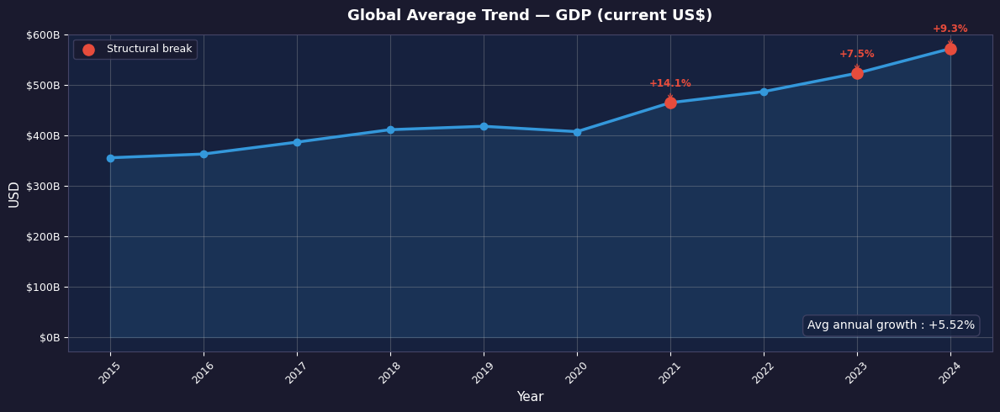

In [55]:
plot_global_trend(df_trend, indicator, unit, avg_growth, breaks)

**Trend Insights**

- The global average reflects cross-country mean behavior — not total volume — making it comparable across indicators of different scales.
- Structural breaks (red dots) identify years where growth deviated sharply from the average trajectory, signaling external shocks or structural shifts.
- The average annual growth rate provides a single-number summary of the indicator's global momentum over 2015–2024.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 2. Distribution — Cross-Country & Cross-Year
</div>

In [56]:
def plot_global_distribution(df: pd.DataFrame, indicator_name: str, indicator_unit: str, highlight_countries: list | None = None,
                             bins: int = 20,  figsize: tuple = (14, 5)) -> None:
    """   Two-panel distribution: histogram & KDE with mean line + country highlights + boxplot per year to show distributional shift over time   """
    
    df_c = df[(df["entity_type"] == "COUNTRY") & (df["indicator_name"] == indicator_name)].dropna(subset=["value"])
    df_agg = df_c.groupby("country_name")["value"].median().reset_index()
    if df_c.empty:
        print(f"No data for {indicator_name}")
        return

    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=figsize)
    fig.suptitle(f"Distribution — {indicator_name}", fontsize=13, color="white", y=1.01)

    # histogram without outliers + annotation ───────────────────
    values = df_agg["value"]
    mean_val   = values.mean()
    median_val = values.median()

    # Detect outliers 
    upper_fence = df_agg["value"].quantile(0.99) 
    mask_in    = values <= upper_fence
    mask_out   = values >  upper_fence
    
    values_in  = values[mask_in]
    outliers   = df_agg[mask_out][["country_name", "value"]].drop_duplicates("country_name")

    # Histogram 
    ax1.hist(values_in, bins=bins, color=C["blue"], alpha=0.6, edgecolor="none")

    # KDE
    from scipy.stats import gaussian_kde
    kde_vals = values_in.dropna()
    if len(kde_vals) > 2:
        kde      = gaussian_kde(kde_vals)
        x_range  = np.linspace(kde_vals.min(), kde_vals.max(), 300)
        ax1_twin = ax1.twinx()
        ax1_twin.plot(x_range, kde(x_range), color=C["teal"], linewidth=2, label="KDE")
        ax1_twin.set_yticks([])
        apply_dark_style(ax1_twin)

    # Mean & median lines
    ax1.axvline(mean_val,   color=C["blue"],  linewidth=1.8, linestyle="--", label=f"Mean = {_format_value(mean_val)}")
    ax1.axvline(median_val, color=C["green"], linewidth=1.8, linestyle=":", label=f"Median = {_format_value(median_val)}")

    # Annotate excluded outliers
    if not outliers.empty:
        excluded = ", ".join(f"{row['country_name']} ({_format_value(row['value'])})"
                             for _, row in outliers.head(5).iterrows())
        ax1.text(0.7, 0.9, f"Outliers excluded :\n{excluded}", transform=ax1.transAxes, fontsize=8, 
                 color="#aaaaaa", ha="right", va="top",
                 bbox=dict(boxstyle="round,pad=0.3", facecolor="#1a1a2e", alpha=0.7, edgecolor="#444466"))

    ax1.set_xlabel(indicator_unit, color="white")
    ax1.set_ylabel("Count", color="white")
    ax1.set_title(f"Distribution — excl. outliers (>{_format_value(upper_fence)})", fontsize=10, color="white")
    add_legend(ax1, fontsize=8.5)
    
   
    # boxplot per year 
    years = sorted(df_c["year"].unique())
    data_by_year = [
    df_c[(df_c["year"] == y) & (df_c["value"] <= upper_fence)]["value"].values  for y in years]
    bp = ax2.boxplot(data_by_year, labels=years, patch_artist=True, medianprops=dict(color=C["orange"], linewidth=2), whiskerprops=dict(color="white"),
                     capprops=dict(color="white"), flierprops=dict(marker="o", color=C["red"], markerfacecolor=C["red"], markersize=3, alpha=0.5))
    for patch in bp["boxes"]:
        patch.set_facecolor(C["blue"])
        patch.set_alpha(0.5)

    y_upper = df_c[df_c["value"] <= upper_fence]["value"].quantile(0.9)
    ax2.set_ylim(0, y_upper * 1.1)
    ax2.text(0.98, 0.98, f"Points > {_format_value(y_upper)} not shown",
             transform=ax2.transAxes, fontsize=7, color="#aaaaaa", ha="right", va="top")
    ax2.set_xlabel("Year", color="white")
    ax2.set_ylabel(indicator_unit, color="white")
    
    
    ax2.set_title("Distribution Shift per Year", fontsize=11, color="white")
    ax2.tick_params(axis="x", rotation=45)
    
    plt.tight_layout()
    save_figure(fig, '../Figures/Indicators/E_2_distribution.png')
    plt.show()

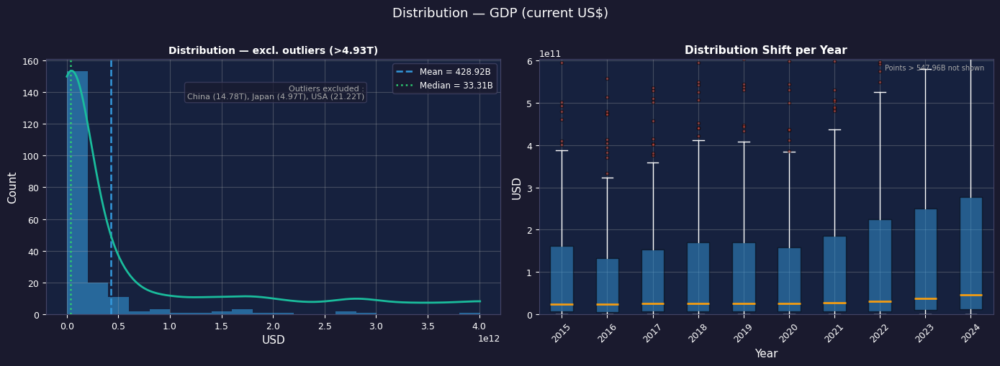

In [57]:
plot_global_distribution(df, indicator, unit, highlight_countries)

**Distribution Insights**
- `Distribution is computed on the per-country median across the full period`
  (2015–2024), not on the raw panel — each country contributes exactly one value.
- The left panel reveals the overall shape of the distribution — right-skewed distributions indicate a small number of countries dominate the indicator.
- Highlighted country lines show where specific economies sit relative to the global distribution — above or below the mean, and by how much.
- The right panel exposes distributional dynamics over time — a widening boxplot indicates growing inequality between countries; a narrowing one suggests convergence.

  


<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 3. Stability — Coefficient of Variation & Rolling Volatility
</div>

In [58]:
def compute_global_stability(df: pd.DataFrame, indicator_name: str, rolling_window: int = 3,) -> tuple[pd.DataFrame, float]:
    """    Compute global stability for a given indicator: CV (std / mean) over the full period — scalar & Rolling CV per year — time series
        - CV (std / mean) per year across countries  → time series  |  - Rolling CV  → smoothed trend  |  - Global CV   → scalar over full period   """
    
    df_c = df[(df["entity_type"]   == "COUNTRY") & (df["indicator_name"] == indicator_name)].dropna(subset=["value"])

    # Overall CV
    global_cv = df_c["value"].std() / df_c["value"].mean()

    # Rolling CV: per year → cv of countries, then rolling mean
    cv_per_year = (df_c.groupby("year")["value"].agg(lambda x: x.std() / x.mean()).reset_index().rename(columns={"value": "cv"}).sort_values("year"))
    cv_per_year["rolling_cv"] = (cv_per_year["cv"].rolling(window=rolling_window, center=True).mean())
    cv_per_year["indicator_name"] = indicator_name
    return cv_per_year, global_cv

In [59]:
# df_cv (all indicators)
df_cv = pd.DataFrame()
list_indicators = df["indicator_name"].unique().tolist()
for ind in list_indicators :
    cv_ind, _ = compute_global_stability(df, ind)
    df_cv = pd.concat([df_cv, cv_ind])

In [60]:
# GDP (current US$)
cv_per_year, global_cv = compute_global_stability(df, indicator)
cv_per_year

,year,cv,rolling_cv,indicator_name
0,2015,4.3706,NaN,GDP (current US$)
1,2016,4.4017,4.3771,GDP (current US$)
2,2017,4.3590,4.3849,GDP (current US$)
3,2018,4.3942,4.4070,GDP (current US$)
4,2019,4.4677,4.4792,GDP (current US$)
5,2020,4.5755,4.5378,GDP (current US$)
6,2021,4.5700,4.5889,GDP (current US$)
7,2022,4.6210,4.5812,GDP (current US$)
8,2023,4.5525,4.5427,GDP (current US$)
9,2024,4.4544,NaN,GDP (current US$)


In [61]:
global_cv

np.float64(4.535835859007994)

In [62]:
def compute_stability_all_indicators(df: pd.DataFrame, rolling_window: int = 3) -> pd.DataFrame:
    """    Compute global CV for ALL indicators     """
    results = []
    for ind in df[df["entity_type"] == "COUNTRY"]["indicator_name"].unique():
        df_c = df[(df["entity_type"]   == "COUNTRY") & (df["indicator_name"] == ind)].dropna(subset=["value"])
        if len(df_c) < 5:           continue
        
        mean_val = df_c["value"].mean()
        
        if mean_val == 0:           continue
        
        cv = df_c["value"].std() / mean_val
        
        results.append({"indicator_name": ind, "global_cv": cv})

    return (pd.DataFrame(results).sort_values("global_cv", ascending=False).reset_index(drop=True))

In [63]:
stability = compute_stability_all_indicators(df)
stability

,indicator_name,global_cv
0,"Current account balance (BoP, current US$)",42.2288
1,GDP (current US$),4.5358
2,"Foreign direct investment, net inflows (BoP, c...",4.4857
3,"Population, total",3.8698
4,"Inflation, consumer prices (annual %)",3.3714
5,"External debt stocks, total (DOD, current US$)",3.2725
6,Imports of goods and services (current US$),2.7154
7,Exports of goods and services (current US$),2.6011
8,Real interest rate (%),2.4566
9,GDP per capita (current US$),1.4946


In [64]:
def plot_stability_cross_indicators(stability: pd.DataFrame, highlight_ind: str | None = None, figsize: tuple = (13, 6)) -> None:
    """    Horizontal bar chart ranking all indicators by global CV. Answers: which indicator is the most/least stable across countries?    """
    
    df_plot = stability.sort_values("global_cv")
    colors  = [
                C["orange"] if row["indicator_name"] == highlight_ind
                else C["red"] if row["global_cv"] >= 1.0
                else C["blue"] if row["global_cv"] >= 0.5
                else C["green"]
                for _, row in df_plot.iterrows()
              ]

    fig, ax = styled_figure(figsize=figsize)
    ax.set_title("Stability Comparison — All Indicators (Global CV)",  fontsize=13, color="white", pad=12)
    bars = ax.barh(df_plot["indicator_name"], df_plot["global_cv"], color=colors, edgecolor="none", height=0.65)
    ax.axvline(0.5, color=C["orange"], linewidth=1.2, linestyle="--", alpha=0.7, label="Moderate threshold (0.5)")
    ax.axvline(1.0, color=C["red"], linewidth=1.2, linestyle="--", alpha=0.7, label="Low threshold (1.0)")

    for bar, val in zip(bars, df_plot["global_cv"]):
        ax.text(val + 0.01, bar.get_y() + bar.get_height() / 2, f"{val:.2f}", va="center", color="white", fontsize=8)

    ax.set_xlabel("Global CV (std / mean)", color="white")
    add_legend(ax, fontsize=8)
    plt.tight_layout()
    save_figure(fig, '../Figures/Indicators/E_3_cross_indicators_stability.png')
    plt.show()

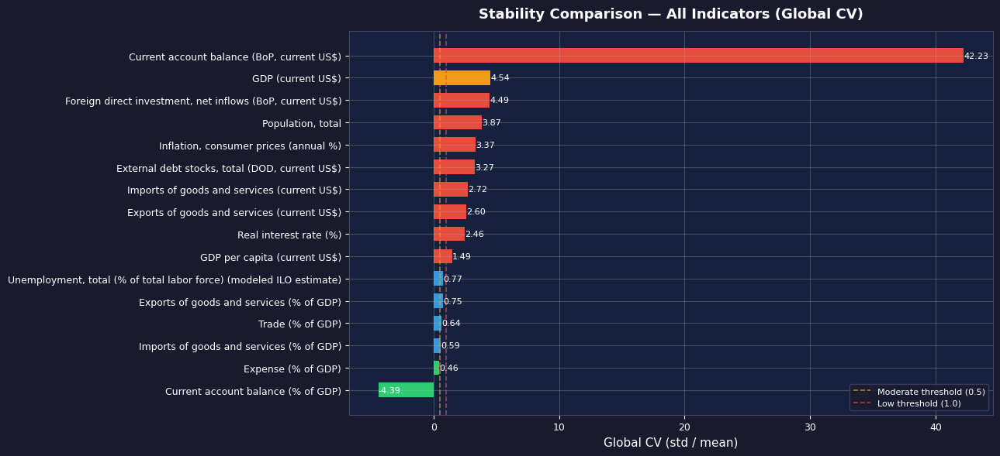

In [65]:
plot_stability_cross_indicators(stability, highlight_ind=indicator)

**Stability Insights**

- The Coefficient of Variation (CV = std / mean) is unit-free, making stability comparable across indicators of different scales.
- A rising CV over time signals increasing divergence between countries — convergence would appear as a declining CV.
- CV < 0.5 → high stability (countries behave similarly); 0.5–1.0 → moderate dispersion; >1.0 → high inequality between countries.
- The cross-indicator ranking reveals which economic dimensions are structurally more homogeneous across countries (low CV) and which are highly concentrated (high CV).
- The currently selected indicator (orange) is positioned relative to all others — useful to calibrate how "normal" its dispersion is.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 4. Concentration — Gini Coefficient over Time
</div>

In [66]:
def gini(values: np.ndarray) -> float:
    """Compute Gini coefficient for an array of non-negative values."""
    v = np.sort(np.abs(values[~np.isnan(values)]))
    n = len(v)
    if n == 0 or v.sum() == 0:        return np.nan
    cumv = np.cumsum(v)
    
    return (2 * np.sum((np.arange(1, n + 1)) * v) - (n + 1) * cumv[-1]) / (n * cumv[-1])

In [67]:
def compute_global_concentration(df: pd.DataFrame, indicator_name: str) -> pd.DataFrame:
    """    Compute Gini coefficient per year across countries    """
    
    df_c = df[(df["entity_type"]   == "COUNTRY") & (df["indicator_name"] == indicator_name)].dropna(subset=["value"])
    gini_df = (df_c.groupby("year")["value"].apply(lambda x: gini(x.values)).reset_index().rename(columns={"value": "gini"}).sort_values("year"))
    gini_df["indicator_name"] = indicator_name
    
    return gini_df

In [68]:
# df_gini (all indicators)
df_gini = pd.DataFrame()
list_indicators = df["indicator_name"].unique().tolist()
for ind in list_indicators :
    gini_ind = compute_global_concentration(df, ind)
    df_gini = pd.concat([df_gini, gini_ind])

In [69]:
# gini_df (one indicator)
gini_df = compute_global_concentration(df, indicator)
gini_df.sample()

,year,gini,indicator_name
9,2024,0.8688,GDP (current US$)


In [70]:
def plot_global_concentration(gini_df: pd.DataFrame, indicator_name: str, df: pd.DataFrame, figsize: tuple = (14, 5)) -> None:
    """    Two-panel concentration view:    Gini evolution over time   —   Lorenz curve for the last available year    """
    
    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=figsize)
    fig.suptitle(f"Global Concentration Analysis — {indicator_name}", fontsize=14, color="white", y=1.01, fontweight='bold')

    # Gini over time
    color_line = C["red"] if gini_df["gini"].iloc[-1] > gini_df["gini"].iloc[0] else C["green"]

    ax1.plot(gini_df["year"], gini_df["gini"], color=color_line, linewidth=2.5, marker="o", markersize=6, zorder=3)
    ax1.fill_between(gini_df["year"], gini_df["gini"], alpha=0.15, color=color_line)
    ax1.axhline(gini_df["gini"].mean(), color=C["grey"], linewidth=1.2, linestyle="--", label=f"Period mean = {gini_df['gini'].mean():.3f}")

    ## Annotate first and last
    for idx in [0, -1]:
        row = gini_df.iloc[idx]
        ax1.annotate(f"{row['gini']:.3f}", xy=(row["year"], row["gini"]), xytext=(0, 10), textcoords="offset points", ha="center", fontsize=9, color="white")

    ax1.set_ylim(0, 1)
    ax1.set_xlabel("Year", color="white")
    ax1.set_ylabel("Gini Coefficient", color="white")
    ax1.set_title("Concentration Evolution (Gini)", fontsize=11, color="white")
    ax1.set_xticks(gini_df["year"])
    ax1.tick_params(axis="x", rotation=45)
    add_legend(ax1)

    # Lorenz curve (last year) 
    last_year = gini_df["year"].max()
    vals = (df[(df["entity_type"]   == "COUNTRY") & (df["indicator_name"] == indicator_name) & (df["year"] == last_year)]["value"] \
            .dropna().sort_values().values)
    if len(vals) > 0:
        lorenz = np.cumsum(vals) / vals.sum()
        x_pop  = np.linspace(0, 1, len(lorenz))
        ax2.plot(x_pop, lorenz, color=C["blue"], linewidth=2.5, label=f"Lorenz {last_year}")
        ax2.plot([0, 1], [0, 1], color=C["grey"], linewidth=1.2, linestyle="--", label="Perfect equality")
        ax2.fill_between(x_pop, lorenz, x_pop, alpha=0.2, color=C["red"])
        ax2.set_xlabel("Cumulative share of countries", color="white")
        ax2.set_ylabel("Cumulative share of indicator", color="white")
        ax2.set_title(f"Lorenz Curve — {last_year}", fontsize=11, color="white")
        add_legend(ax2)

    plt.tight_layout()
    save_figure(fig, '../Figures/Indicators/E_4_global_concentration.png')
    plt.show()

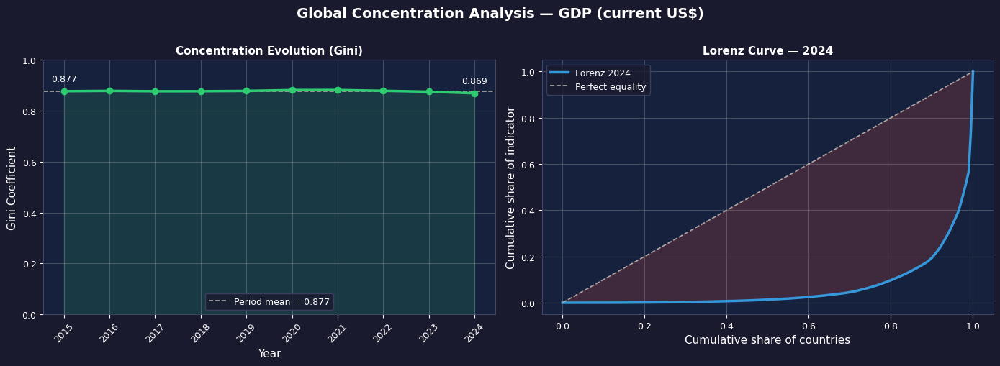

In [71]:
plot_global_concentration(gini_df, indicator, df)

In [72]:
def compute_concentration_all_indicators(df: pd.DataFrame) -> pd.DataFrame:
    """    Compute mean Gini over the full period for ALL indicators    """
    
    results = []
    for ind in df[df["entity_type"] == "COUNTRY"]["indicator_name"].unique():
        df_c = df[(df["entity_type"]   == "COUNTRY") & (df["indicator_name"] == ind)].dropna(subset=["value"])
        
        if len(df_c) < 5:            continue
        gini_by_year = (df_c.groupby("year")["value"].apply(lambda x: gini(x.values)))
        
        results.append({
                        "indicator_name": ind,
                        "mean_gini"     : gini_by_year.mean(),
                        "last_gini"     : gini_by_year.iloc[-1] if len(gini_by_year) else np.nan,
                        "trend_gini"    : gini_by_year.iloc[-1] - gini_by_year.iloc[0]  if len(gini_by_year) > 1 else np.nan,
        })

    return (pd.DataFrame(results).sort_values("mean_gini", ascending=False).reset_index(drop=True))

In [73]:
concentration = compute_concentration_all_indicators(df)
concentration.sample(3)

,indicator_name,mean_gini,last_gini,trend_gini
3,"Population, total",0.8180,0.8151,-0.0053
5,Exports of goods and services (current US$),0.8146,0.7964,-0.0253
9,Current account balance (% of GDP),0.5009,0.5114,0.0283


In [74]:
def plot_concentration_cross_indicators(concentration: pd.DataFrame, highlight_ind: str | None = None, figsize: tuple = (12, 12)) -> None:
    """    cross-indicator concentration comparison:    ranking by mean Gini  — trend direction (last Gini − first Gini) per indicator    """
    
    fig, (ax1, ax2) = styled_subplots(nrows=2, ncols=1, figsize=figsize)
    fig.suptitle("Concentration Comparison — All Indicators (Mean Gini)", fontsize=14, fontweight='bold', color="white", y=1.01)

    # ── LEFT : ranking by mean Gini ───────────────────────────────────────────
    df_plot = concentration.sort_values("mean_gini")
    colors  = [
                C["orange"] if row["indicator_name"] == highlight_ind
                else C["red"] if row["mean_gini"] >= 0.6
                else C["blue"] if row["mean_gini"] >= 0.4
                else C["green"]
                for _, row in df_plot.iterrows()
              ]
    bars = ax1.barh(df_plot["indicator_name"], df_plot["mean_gini"], color=colors, edgecolor="none", height=0.65)
    ax1.axvline(0.4, color=C["blue"], linewidth=1.1, linestyle="--", alpha=0.6, label="Moderate (0.4)")
    ax1.axvline(0.6, color=C["red"], linewidth=1.1, linestyle="--", alpha=0.6, label="High (0.6)")
    for bar, val in zip(bars, df_plot["mean_gini"]):
        ax1.text(val + 0.005, bar.get_y() + bar.get_height() / 2, f"{val:.2f}", va="center", color="white", fontsize=8)
    ax1.set_xlabel("Mean Gini", color="white")
    ax1.set_title("Ranking by Concentration", fontsize=11, color="white")
    add_legend(ax1, fontsize=8)

    # ── RIGHT : trend direction ────────────────────────────────────────────────
    df_trend = concentration.sort_values("trend_gini").dropna(subset=["trend_gini"])
    trend_colors = [ 
                        C["orange"] if row["indicator_name"] == highlight_ind
                        else C["red"] if row["trend_gini"] > 0
                        else C["green"]
                        for _, row in df_trend.iterrows()
                    ]
    ax2.barh(df_trend["indicator_name"], df_trend["trend_gini"], color=trend_colors, edgecolor="none", height=0.65)
    ax2.axvline(0, color=C["grey"], linewidth=1)
    ax2.set_xlabel("Gini trend (last − first)", color="white")
    ax2.set_title("Concentration Trend Direction", fontsize=11, color="white")

    # Legend manually
    patches = [mpatches.Patch(color=C["red"], label="↑ Increasing concentration"), mpatches.Patch(color=C["green"], label="↓ Decreasing concentration")]
    add_legend(ax2, handles=patches, fontsize=8)

    plt.tight_layout()
    save_figure(fig, '../Figures/Indicators/E_4_cross_indicators_concentration.png')
    plt.show()

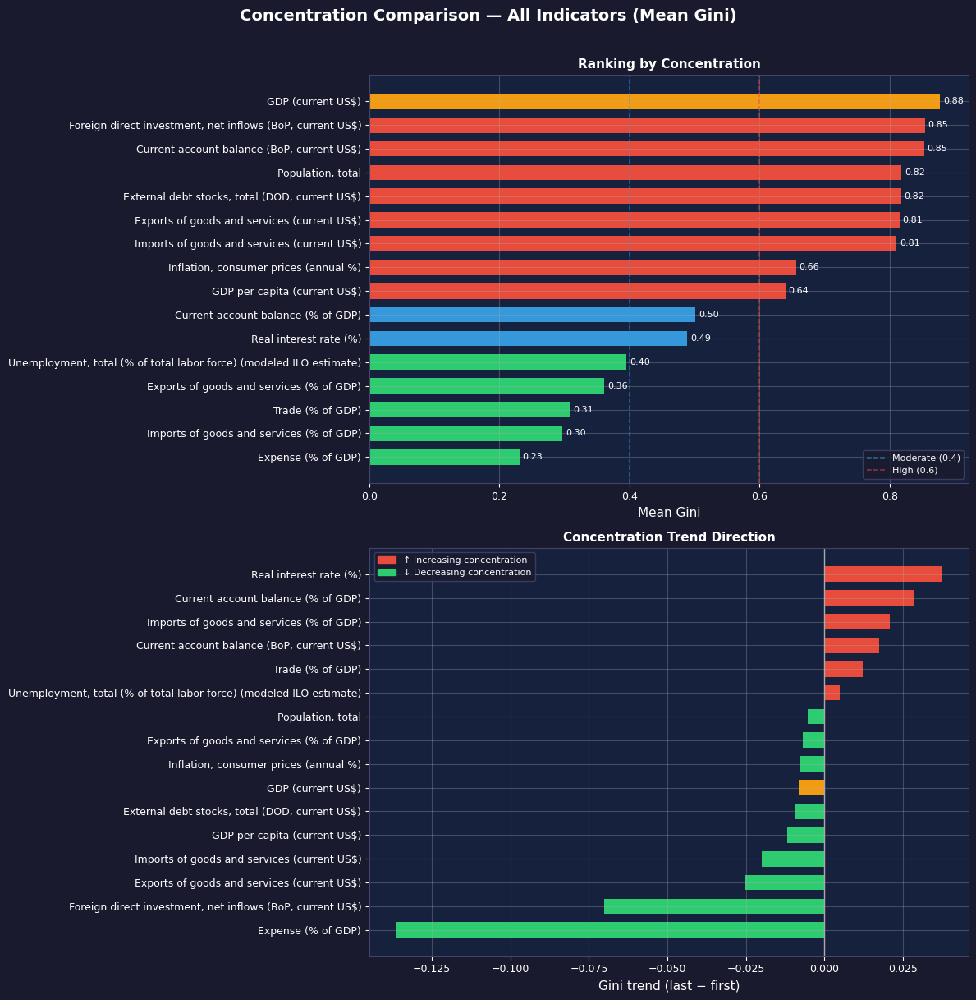

In [75]:
plot_concentration_cross_indicators(concentration, highlight_ind=indicator)

**Concentration Insights**

- The Gini coefficient ranges from 0 (perfect equality) to 1 (maximum concentration) — values above 0.5 indicate strong dominance by a small number of countries.
- A rising Gini over time signals increasing concentration — fewer countries capture a larger share of the indicator.
- The Lorenz curve visualizes how far the actual distribution deviates from perfect equality — the larger the shaded area, the more concentrated the indicator.
- The ranking by mean Gini reveals which economic dimensions are structurally most unequal between countries — absolute value indicators (GDP, debt) typically have higher Gini than ratio indicators (trade %, inflation).
- The trend direction panel (right) is analytically rich: a red bar = the indicator is becoming more concentrated over time — fewer countries capture an increasing share. A green bar = convergence.
- The currently selected indicator (orange) is positioned relative to all others — clarifying whether it is typically concentrated or dispersed in the global economy.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 5. Growth Dynamics — Global YoY by Indicator
</div>

In [76]:
def compute_indicator_growth_summary(df: pd.DataFrame) -> pd.DataFrame:
    """    For each indicator, compute period growth rate  (first → last global average value).  Used to rank indicators by overall growth momentum.    """
    
    df_c = df[df["entity_type"] == "COUNTRY"]
    agg = (df_c.groupby(["indicator_name", "year"])["value"].mean().reset_index().sort_values(["indicator_name", "year"]))
    summary = (agg.groupby("indicator_name").agg(first_value=("value", "first"), last_value=("value", "last")).reset_index())
    summary["growth_pct"] = ((summary["last_value"] - summary["first_value"]) / summary["first_value"] * 100)
    return summary.sort_values("growth_pct", ascending=False).reset_index(drop=True)

In [77]:
growth_summary = compute_indicator_growth_summary(df)
growth_summary.head()

,indicator_name,first_value,last_value,growth_pct
0,"Current account balance (BoP, current US$)",529245427.7979,2296076655.8130,333.8397
1,"Inflation, consumer prices (annual %)",4.0612,7.3897,81.9590
2,Exports of goods and services (current US$),112844686093.8332,193136107678.5369,71.1522
3,Imports of goods and services (current US$),110009960919.5038,188206490962.3695,71.0813
4,GDP (current US$),355715937147.7776,572196182381.0050,60.8576


In [78]:
def plot_indicator_growth_summary(growth_summary: pd.DataFrame, highlight_indicator: str | None = None, figsize: tuple = (13, 6)) -> None:
    """Horizontal bar chart ranking all indicators by period growth rate."""

    df_plot = growth_summary.sort_values("growth_pct")
    
    # ── Detect outliers (> P95 absolute value) ────────────────────────────────
    threshold  = df_plot["growth_pct"].abs().quantile(0.95)
    df_normal  = df_plot[df_plot["growth_pct"].abs() <= threshold]
    df_outlier = df_plot[df_plot["growth_pct"].abs() >  threshold]

    colors = [C["orange"] if row["indicator_name"] == highlight_indicator
              else C["green"] if row["growth_pct"] >= 0 else C["red"]
              for _, row in df_normal.iterrows()]

    fig, ax = styled_figure(figsize=figsize)
    ax.set_title("Global Growth Dynamics — All Indicators (Period %)",
                 fontsize=13, color="white", pad=12)

    bars = ax.barh(df_normal["indicator_name"], df_normal["growth_pct"],
                   color=colors, edgecolor="none", height=0.65)
    ax.axvline(0, color=C["grey"], linewidth=1, linestyle="-")

    # Annotate normal bars
    for bar, val in zip(bars, df_normal["growth_pct"]):
        offset = 1 if val >= 0 else -1
        ax.text(val + offset, bar.get_y() + bar.get_height() / 2,
                f"{val:+.1f}%", va="center", color="white", fontsize=10, fontweight="bold" )

    # Set axis limit based on normal range
    x_max = df_normal["growth_pct"].max() * 1.05
    ax.set_xlim(df_normal["growth_pct"].min() * 1.1, x_max)

    # Annotate outliers as truncated bars with real value label
    for _, row in df_outlier.iterrows():
        color = C["orange"] if row["indicator_name"] == highlight_indicator \
                else C["green"] if row["growth_pct"] >= 0 else C["red"]
        ax.barh(row["indicator_name"], x_max * 0.98,
                color=color, edgecolor="none", height=0.65, alpha=0.85)
        ax.annotate(f"{row['growth_pct']:+.0f}% (truncated)",
                    xy=(x_max * 0.98, row["indicator_name"]),
                    xytext=(-5, 0), textcoords="offset points",
                    fontsize=9, color="white", ha="right", va="center",
                    fontweight="bold")

    ax.set_xlabel("Period Growth Rate (%)", color="white")
    plt.tight_layout()
    save_figure(fig, '../Figures/Indicators/E_5_indicators_growth.png')
    plt.show()

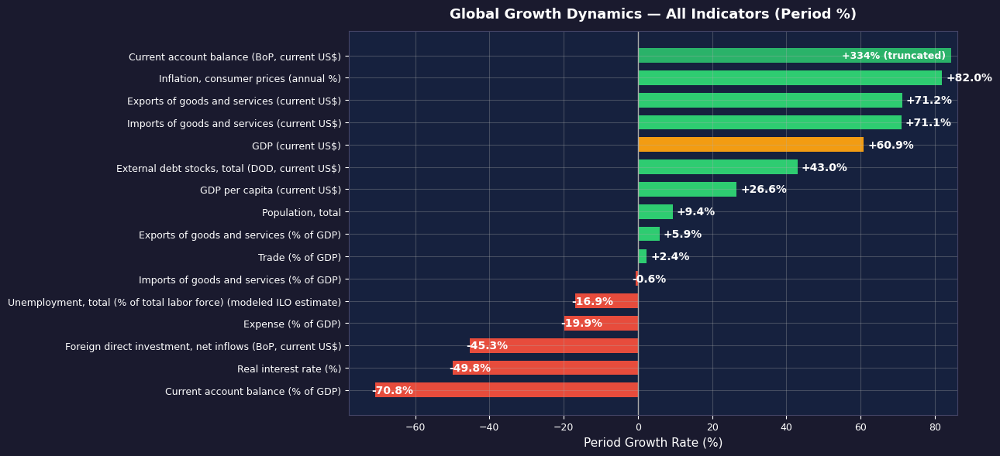

In [79]:
plot_indicator_growth_summary(growth_summary, highlight_indicator=indicator)

**Growth Dynamics Insights**

- This chart ranks all indicators by their total growth from the first to the last year of the period — providing a comparative view of which dimensions of the economy grew fastest globally.
- The highlighted indicator (orange) shows its relative position among all indicators — whether it outperformed or underperformed the global average dynamic.
- Negative growth rates (red) identify indicators that contracted globally over the period — structurally significant signals.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 6. Ranking — Top & Worst Countries
</div>

In [80]:
def compute_indicator_ranking(df: pd.DataFrame, indicator_name: str, metric: str = "value", year: int | None = None) -> pd.DataFrame:
    """    Rank countries by a given metric for a given indicator.    If year is None, uses each country's last available year.    """
    
    data = df[(df["entity_type"]   == "COUNTRY") & (df["indicator_name"] == indicator_name)].copy()
    if year is not None:        data = data[data["year"] == year]
    else: data = (data.sort_values("year", ascending=False).drop_duplicates(subset=["country_name"]))  # Keep last available year per country

    ranking = (data.dropna(subset=[metric]).sort_values(metric, ascending=False).reset_index(drop=True))
    ranking["rank"] = ranking.index + 1
    return ranking

In [81]:
ranking_df = compute_indicator_ranking(df, indicator, metric="value")
print(f"Total countries ranked : {len(ranking_df)}")
ranking_df.head(3)

Total countries ranked : 190


,entity_key,entity_type,country_code,wb_country_code,country_name,wb_country_name,country_iso3,wb_country_iso3,indicator_code,indicator_name,indicator_unit,year,value,yoy_growth,abs_growth,index_100,z_score,rank
0,287,COUNTRY,842.0000,840.0000,USA,United States,USA,USA,NY.GDP.MKTP.CD,GDP (current US$),USD,2024,28750956130731.1992,0.0535,1458785337516.8008,157.9200,11.0557,1
1,53,COUNTRY,156.0000,156.0000,China,China,CHN,CHN,NY.GDP.MKTP.CD,GDP (current US$),USD,2024,18743803170827.1992,0.0259,473446516294.0000,166.1565,7.1295,2
2,70,COUNTRY,276.0000,276.0000,Germany,Germany,DEU,DEU,NY.GDP.MKTP.CD,GDP (current US$),USD,2024,4685592577804.6904,0.0270,123385045314.4102,136.8016,1.6139,3


In [82]:
def plot_top_worst(ranking_df:pd.DataFrame, indicator_name:str, indicator_unit:str, metric:str = "value", top_n:int = 10, figsize:tuple = (16, 6)) -> None:
    """    Side-by-side horizontal bar charts:    Top N countries — Bottom N countries    """
    
    top   = ranking_df.head(top_n)
    worst = ranking_df.tail(top_n).sort_values(metric)
    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=figsize)
    fig.suptitle(f"Country Ranking — {indicator_name} ({metric})", fontsize=13, color="white", y=1.01)

    for ax, df_plot, color, title in [(ax1, top.sort_values(metric), C["green"], f"Top {top_n}"), (ax2, worst, C["red"], f"Bottom {top_n}")]:
        bars = ax.barh(df_plot["country_name"], df_plot[metric], color=color, alpha=0.75, edgecolor="none", height=0.65)
        for bar, val in zip(bars, df_plot[metric]):
            ax.text(bar.get_width() * 1.01, bar.get_y() + bar.get_height() / 2,  _format_value(val), va="center", color="white", fontsize=8.5)
        ax.set_xlabel(indicator_unit, color="white")
        ax.set_title(title, fontsize=11, color="white")
    
    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/E_6_top_worst_country_{ind_name}_{metric}.png')
    plt.show()

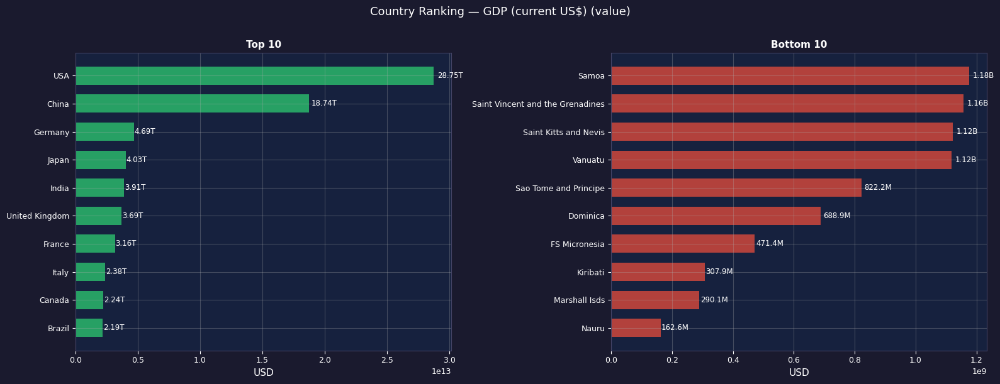

In [83]:
plot_top_worst(ranking_df, indicator, unit, metric="value", top_n=10)

In [84]:
# ranking on YoY growth (most/least dynamic countries)
ranking_growth_df = compute_indicator_ranking(df, indicator, metric="yoy_growth")
ranking_df.head(3)

,entity_key,entity_type,country_code,wb_country_code,country_name,wb_country_name,country_iso3,wb_country_iso3,indicator_code,indicator_name,indicator_unit,year,value,yoy_growth,abs_growth,index_100,z_score,rank
0,287,COUNTRY,842.0000,840.0000,USA,United States,USA,USA,NY.GDP.MKTP.CD,GDP (current US$),USD,2024,28750956130731.1992,0.0535,1458785337516.8008,157.9200,11.0557,1
1,53,COUNTRY,156.0000,156.0000,China,China,CHN,CHN,NY.GDP.MKTP.CD,GDP (current US$),USD,2024,18743803170827.1992,0.0259,473446516294.0000,166.1565,7.1295,2
2,70,COUNTRY,276.0000,276.0000,Germany,Germany,DEU,DEU,NY.GDP.MKTP.CD,GDP (current US$),USD,2024,4685592577804.6904,0.0270,123385045314.4102,136.8016,1.6139,3


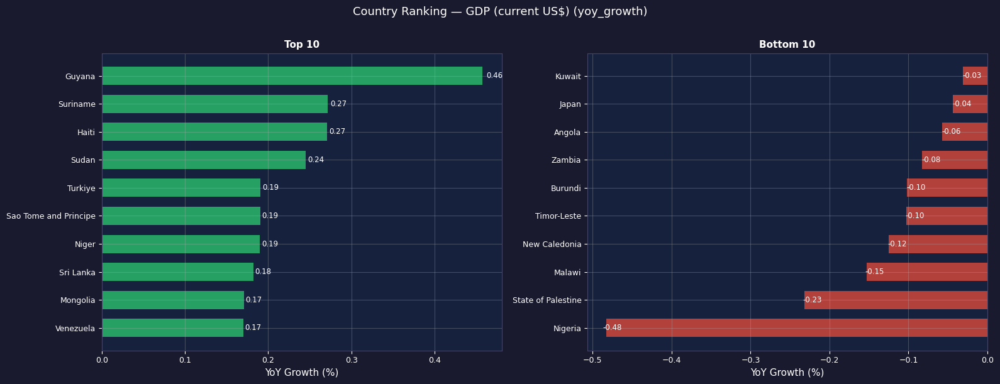

In [85]:
plot_top_worst(ranking_growth_df, indicator, "YoY Growth (%)", metric="yoy_growth", top_n=10)

**Ranking Insights**

- The value ranking reflects structural position — which countries lead or lag in absolute terms on the indicator.
- The growth ranking reveals dynamics — a country can rank low in absolute value but high in growth, signaling a catching-up trajectory.
- Comparing both rankings for the same country is analytically powerful: a top-value + bottom-growth country is stagnating at the top; a bottom-value + top-growth country is converging.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 7. Save Tables
</div>

In [86]:
df_cv.to_csv("../Analysis_files/Indicators/df_cv.csv", index=False)
stability.to_csv("../Analysis_files/Indicators/stability.csv", index=False)
df_gini.to_csv("../Analysis_files/indicators/df_gini.csv", index=False)
concentration.to_csv("../Analysis_files/Indicators/concentration.csv", index=False)

<div style="background-color: #eaf2f8; padding-left: 20px; border: 1px solid; border-radius: 5px;">

# F. Analyse World
</div>

This section analyzes the **World** entity as a single aggregate — distinct from the cross-country average computed in Section E.
The World value is the official World Bank aggregate, reflecting total or weighted global figures.
Where World data is unavailable for a given indicator, sections are skipped gracefully.

In [87]:
# Indicator parameter 
indicator = "GDP (current US$)"
unit      = df.loc[df["indicator_name"] == indicator, "indicator_unit"].dropna().iloc[0]
ind_name = "GDP"

In [88]:
# World data for this indicator
df_world = df[(df["country_name"]   == "World") & (df["indicator_name"] == indicator)].sort_values("year").reset_index(drop=True)

if df_world.empty:    print(f"⚠️  No World data available for : {indicator}")

else:
    print(f"📊 Indicator : {indicator}")
    print(f"📐 Unit      : {unit}")
    print(f"📅 Period    : {df_world['year'].min()} – {df_world['year'].max()}")
    print(f"📦 Non-null  : {df_world['value'].notna().sum()} / {len(df_world)}")

📊 Indicator : GDP (current US$)
📐 Unit      : USD
📅 Period    : 2015 – 2024
📦 Non-null  : 10 / 10


<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 1. Summary Statistics & CAGR
</div>

In [89]:
def compute_entity_stats(df: pd.DataFrame, entity_name: str, min_years: int = 3) -> pd.DataFrame :
    """    Compute descriptive statistics + CAGR for ALL indicators of a given entity (World, country, etc.).    """
    
    data = (df[df["country_name"]   == entity_name].dropna(subset=["value"]).sort_values(["indicator_name", "year"]))
    results = []
    
    for (ind_name, ind_unit), g in data.groupby(["indicator_name", "indicator_unit"]):
        g = g.sort_values("year")
        n_years   = g["year"].iloc[-1] - g["year"].iloc[0]
        first_val = g["value"].iloc[0]
        last_val  = g["value"].iloc[-1]

        cagr = np.nan
        if n_years >= min_years and first_val > 0 and last_val > 0:  cagr = (last_val / first_val) ** (1 / n_years) - 1

        results.append({
                        "indicator_name" : ind_name,                  "indicator_unit" : ind_unit,
                        "start_year"     : g["year"].iloc[0],         "end_year"       : g["year"].iloc[-1],
                        "n_obs"          : len(g),                    
                        "mean"           : g["value"].mean(),         "median"         : g["value"].median(),
                        "std"            : g["value"].std(),
                        "min"            : g["value"].min(),          "max"            : g["value"].max(),
                        "first_value"    : first_val,                 "last_value"     : last_val,
                        "cagr"           : cagr,
                        })

    return pd.DataFrame(results).sort_values("cagr", ascending=False).reset_index(drop=True)

In [90]:
world_stats = compute_entity_stats(df, "World")

if world_stats.empty:    print(f"⚠️  No World data available")
else:                    print(f"✅ {len(world_stats)} indicators computed for World")

✅ 11 indicators computed for World


In [91]:
world_stats.style.format({col: _format_value for col in ["mean","median","std", "min","max","first_value","last_value"]} | {"cagr": "{:+.2%}"}) \
                     .background_gradient(subset=["cagr"], cmap="RdYlGn")

,indicator_name,indicator_unit,start_year,end_year,n_obs,mean,median,std,min,max,first_value,last_value,cagr
0,Exports of goods and services (current US$),USD,2015,2024,10,26.07T,25.01T,4.39T,20.88T,32.30T,21.27T,32.30T,+4.75%
1,Imports of goods and services (current US$),USD,2015,2024,10,25.37T,24.46T,4.24T,20.30T,31.28T,20.70T,31.28T,+4.70%
2,GDP (current US$),USD,2015,2024,10,91.39T,87.77T,12.44T,75.62T,110.98T,75.62T,110.98T,+4.35%
3,GDP per capita (current US$),USD per capita,2015,2024,10,11.7K,11.3K,1.3K,10.2K,13.6K,10.2K,13.6K,+3.32%
4,"Population, total",Persons,2015,2024,10,7.80B,7.82B,232.7M,7.44B,8.14B,7.44B,8.14B,+1.00%
5,Expense (% of GDP),% of GDP,2015,2022,8,28.40,26.81,2.87,26.22,33.64,26.82,28.70,+0.97%
6,Exports of goods and services (% of GDP),% of GDP,2015,2024,10,28.43,28.39,1.27,26.14,30.89,28.13,29.11,+0.38%
7,Imports of goods and services (% of GDP),% of GDP,2015,2024,10,27.67,27.56,1.24,25.46,30.12,27.37,28.18,+0.33%
8,Trade (% of GDP),%,2015,2024,10,56.43,56.31,2.74,51.97,62.42,55.73,56.76,+0.20%
9,"Unemployment, total (% of total labor force) (modeled ILO estimate)",%,2015,2024,10,5.67,5.83,0.56,4.81,6.59,6.00,4.81,-2.43%


In [92]:
def plot_entity_stats(stats_df: pd.DataFrame, entity_name: str, indicator_name: str, figsize: tuple = (14, 6)) -> None:
    """    Visual summary card: key metrics bar chart  — CAGR ranking across ALL indicators (cross-indicator comparison)   """
    
    row = stats_df[stats_df["indicator_name"] == indicator_name]
    inds    = stats_df["indicator_name"].tolist()
    if row.empty:
        print(f"⚠️  No stats for {indicator_name}")
        return
    row = row.iloc[0]
    
    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=figsize)
    fig.suptitle(f"Summary Statistics — {entity_name} | {indicator_name}", fontsize=13, color="white", y=1.01)

    # Key metrics 
    metrics =   {
                    "Mean"  : row["mean"],         "Median": row["median"],
                    "Min"   : row["min"],          "Max"   : row["max"],
                    "First" : row["first_value"],  "Last": row["last_value"],
                }
    colors_m = [C["blue"], C["teal"], C["red"], C["green"], C["grey"], C["orange"]]
    bars = ax1.bar(list(metrics.keys()), list(metrics.values()), color=colors_m, edgecolor="none", width=0.6)
    for bar, val in zip(bars, metrics.values()):
        ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() * 1.02, _format_value(val), ha="center", va="bottom",
                 color="white", fontsize=8.5, fontweight="bold")
    
    cagr_txt = f"{row['cagr']:+.2%}" if pd.notna(row["cagr"]) else "N/A"
    ax1.text(0.45, 0.97, f"CAGR ({int(row['start_year'])}–{int(row['end_year'])}) : {cagr_txt}", transform=ax1.transAxes, ha="right", va="top",
             fontsize=9, fontweight= "bold",color="white", bbox=dict(boxstyle="round,pad=0.4", facecolor=C["ax_bg"], edgecolor=C["spine"], alpha=0.9))
    ax1.set_ylabel(row["indicator_unit"], color="white")
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x/1e12:.1f}T' if x >= 1e12 else f'${x/1e9:.0f}B'))
    ax1.set_title("Key Metrics", fontsize=11, color="white")

    # CAGR ranking
    cagr_plot = stats_df.dropna(subset=["cagr"]).sort_values("cagr")
    bar_colors = [ 
                    C["orange"] if n == indicator_name
                    else C["green"] if v >= 0
                    else C["red"]
                    for n, v in zip(cagr_plot["indicator_name"], cagr_plot["cagr"])
                ]
    ax2.barh(cagr_plot["indicator_name"], cagr_plot["cagr"] * 100, color=bar_colors, edgecolor="none", height=0.65)
    ax2.axvline(0, color=C["grey"], linewidth=1)
    ax2.set_xlabel("CAGR (%)", color="white")
    ax2.set_yticklabels([n[:35] + "…" if len(n) > 35 else n for n in inds], fontsize=7)
    ax2.set_title(f"CAGR Ranking — All Indicators ({entity_name})", fontsize=11, color="white")
    ax2.tick_params(labelsize=7)

    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/F_1_summary_stats_{entity_name}_{ind_name}.png')
    plt.show()

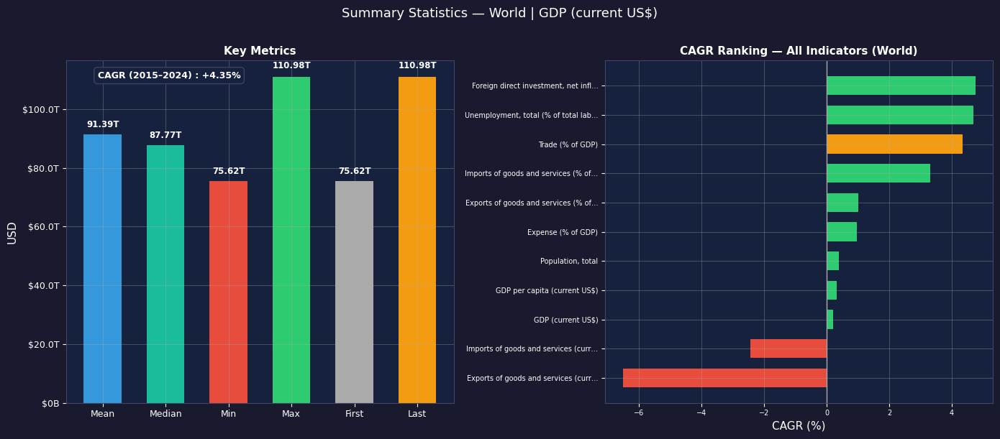

In [93]:
if not world_stats.empty:
    plot_entity_stats(world_stats, "World", indicator)

**Summary Insights**

- The CAGR reflects the compound annual growth rate of the World aggregate over the full available period — a single-number summary of global momentum.
- The gap between Mean and Median signals distributional skew in the time series — a mean well above median indicates a few peak years pull the average up.
- First vs Last values capture the net change over the full period —  combined with CAGR, they tell whether growth was front-loaded or back-loaded.


<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 2. Trend + Structural Breaks
</div>

In [94]:
def compute_entity_trend(df: pd.DataFrame, entity_name: str, indicator_name: str) -> pd.DataFrame:
    """    Extract time series for one entity × indicator    """
    
    data = (df[(df["country_name"]   == entity_name) & (df["indicator_name"] == indicator_name)].sort_values("year").reset_index(drop=True))
    
    if data.empty:     return pd.DataFrame()

    data["growth_yoy"]     = data["value"].pct_change()
    data["indicator_name"] = indicator_name   # ← ajout tracabilité

    return data[["year", "value", "growth_yoy", "indicator_name"]]

In [95]:
trend_world = compute_entity_trend(df, "World", indicator)
trend_world.sample().style.format(_format_value, subset="value")

,year,value,growth_yoy,indicator_name
4,2019,88.48T,0.016454,GDP (current US$)


In [96]:
def plot_entity_trend(df_trend: pd.DataFrame, entity_name: str, indicator_name: str, indicator_unit: str,
                      avg_growth: float | None = None, cagr: float | None = None, breaks: pd.DataFrame | None = None, figsize: tuple = (14, 5)) -> None:
    """    Two-panel trend view:  value trend with breaks and growth annotations  — YoY growth rate as bar chart with sign coloring    """
    
    if df_trend.empty:
        print(f"⚠️  No trend data for {entity_name} — {indicator_name}")
        return

    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=figsize)
    fig.suptitle(f"Trend — {entity_name} | {indicator_name}", fontsize=13, color="white", y=1.01)

    # value trend 
    ax1.plot(df_trend["year"], df_trend["value"], color=C["blue"], linewidth=2.5, marker="o", markersize=6, zorder=3)
    ax1.fill_between(df_trend["year"], df_trend["value"], alpha=0.15, color=C["blue"])

    # Structural breaks
    if breaks is not None and not breaks.empty:
        break_vals = df_trend.set_index("year").loc[breaks["year"], "value"]
        ax1.scatter(breaks["year"], break_vals, color=C["red"], s=90, zorder=5, label="Structural break")
        for _, row in breaks.iterrows():
            y_val = df_trend.loc[df_trend["year"] == row["year"], "value"].values[0]
            ax1.annotate(f"{row['growth_yoy']:+.1%}", xy=(row["year"], y_val), xytext=(0, 14), textcoords="offset points", ha="center", 
                         fontsize=8.5, color=C["red"], fontweight="bold", arrowprops=dict(arrowstyle="->", color=C["red"], lw=0.9))

    # Avg growth + CAGR box
    lines = []
    if avg_growth is not None and pd.notna(avg_growth):   lines.append(f"Avg growth : {avg_growth:+.2%}")
    if cagr is not None and pd.notna(cagr):               lines.append(f"CAGR       : {cagr:+.2%}")
    if lines:
        ax1.text(0.7, 0.3, "\n".join(lines), transform=ax1.transAxes, ha="left", va="top", fontsize=9, color="white",
                 bbox=dict(boxstyle="round,pad=0.4", facecolor=C["ax_bg"], edgecolor=C["spine"], alpha=0.85))

    ax1.set_xlabel("Year", color="white")
    ax1.set_ylabel(indicator_unit, color="white")
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x/1e12:.1f}T' if x >= 1e12 else f'${x/1e9:.0f}B'))
    ax1.set_title("Value Trend", fontsize=11, color="white")
    ax1.set_xticks(df_trend["year"])
    ax1.tick_params(axis="x", rotation=45)
    if breaks is not None and not breaks.empty:        add_legend(ax1)

    # YoY growth bars 
    growth = df_trend.dropna(subset=["growth_yoy"])
    bar_colors = [C["green"] if v >= 0 else C["red"] for v in growth["growth_yoy"]]

    ax2.bar(growth["year"], growth["growth_yoy"] * 100, color=bar_colors, edgecolor="none", width=0.7)
    ax2.axhline(0, color=C["grey"], linewidth=1)
    ax2.axhline(growth["growth_yoy"].mean() * 100, color=C["orange"], linewidth=1.4, linestyle="--", label=f"Mean = {growth['growth_yoy'].mean():+.2%}")
    ax2.set_xlabel("Year", color="white")
    ax2.set_ylabel("YoY Growth (%)", color="white")
    ax2.set_title("Year-on-Year Growth Rate", fontsize=11, color="white")
    ax2.set_xticks(growth["year"])
    ax2.tick_params(axis="x", rotation=45)
    add_legend(ax2)

    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/F_2_Trend_{entity_name}_{ind_name}.png')
    plt.show()

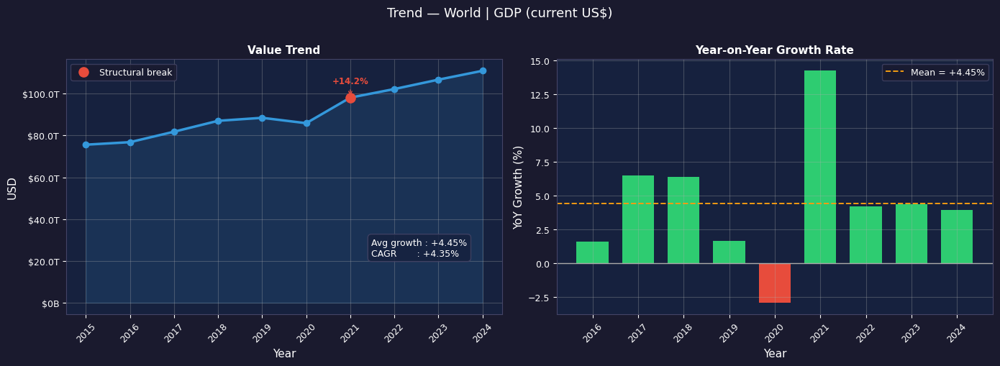

In [97]:
# Single indicator trend 
if not trend_world.empty:
    avg_growth_world = compute_average_growth(trend_world)
    breaks_world     = detect_structural_breaks(trend_world, threshold=0.07)
    cagr_world       = (world_stats.loc[world_stats["indicator_name"] == indicator, "cagr"].values[0] if not world_stats.empty else np.nan)
    
    plot_entity_trend(trend_world, "World", indicator, unit, avg_growth_world, cagr_world, breaks_world)

else:    print(f"⚠️  No trend data for World — {indicator}")

In [98]:
def plot_entity_trend_multi(df: pd.DataFrame, entity_name: str, stats_df: pd.DataFrame, figsize: tuple = (14, 7)) -> None:
    """Inter-indicator comparison for one entity:
       Heatmap of YoY growth per indicator × year.
       Reveals which indicators drove growth in each year."""
    
    indicators_avail = stats_df["indicator_name"].tolist()
    rows = []
    for ind in indicators_avail:
        sub = df[(df["country_name"] == entity_name) & (df["indicator_name"] == ind)].sort_values("year")
        if sub.empty: continue
        sub = sub.copy()
        sub["yoy"] = sub["value"].pct_change() * 100
        for _, r in sub.iterrows():
            rows.append({"indicator_name": ind, "year": r["year"], "yoy": r["yoy"]})

    if not rows:
        print(f"No trend data for {entity_name}")
        return

    pivot = pd.DataFrame(rows).pivot(index="indicator_name", columns="year", values="yoy")

    # ── Clip scale at ±50 and annotate extreme values separately ──────────────
    VMIN, VMAX = -50, 50
    pivot_clipped = pivot.clip(lower=VMIN, upper=VMAX)

    fig, ax = plt.subplots(figsize=(figsize[0], max(5, len(pivot) * 0.5)))
    fig.patch.set_facecolor(C["bg"])
    ax.set_facecolor(C["ax_bg"])

    sns.heatmap(pivot_clipped, ax=ax, cmap="RdYlGn", center=0,
                vmin=VMIN, vmax=VMAX,
                linewidths=0.3, linecolor=C["bg"],
                annot=True, fmt=".1f",
                annot_kws={"size": 7, "color": "black"},
                cbar_kws={"shrink": 0.6, "label": "YoY Growth (%)"})

    # Override annotations for extreme cells with real value + marker
    for row_idx, ind in enumerate(pivot.index):
        for col_idx, year in enumerate(pivot.columns):
            val = pivot.loc[ind, year]
            if pd.isna(val): continue
            if abs(val) > VMAX:
                ax.text(col_idx + 0.5, row_idx + 0.5,
                        f"{val:.1f}*",
                        ha="center", va="center",
                        fontsize=7, fontweight="bold", color="white")

    # Add footnote explaining * marker
    extremes = [(ind, yr, pivot.loc[ind, yr])
                for ind in pivot.index for yr in pivot.columns
                if not pd.isna(pivot.loc[ind, yr]) and abs(pivot.loc[ind, yr]) > VMAX]
    if extremes:
        note = "  |  ".join(f"{ind.split(',')[0]} {yr}: {val:+.1f}%"
                             for ind, yr, val in extremes[:4])
        fig.text(0.01, -0.02, f"* Values outside ±50% range: {note}",
                 fontsize=9, fontweight = "bold", color="#aaaaaa", ha="left")

    ax.set_title(f"YoY Growth Heatmap — {entity_name} | All Indicators",
                 fontsize=13, color="white", pad=12)
    ax.set_xlabel("Year", color="white")
    ax.set_ylabel("", color="white")
    ax.set_yticklabels([n[:35] + "…" if len(n) > 35 else n for n in indicators_avail], fontsize=9, fontweight ="bold")
    ax.tick_params(colors="white", labelsize=7)
    ax.tick_params(axis="x", rotation=45)

    cbar = ax.collections[0].colorbar
    cbar.ax.yaxis.label.set_color("white")
    cbar.ax.tick_params(colors="white")

    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/F_2_heatmap_trend_{entity_name}.png')
    plt.show()

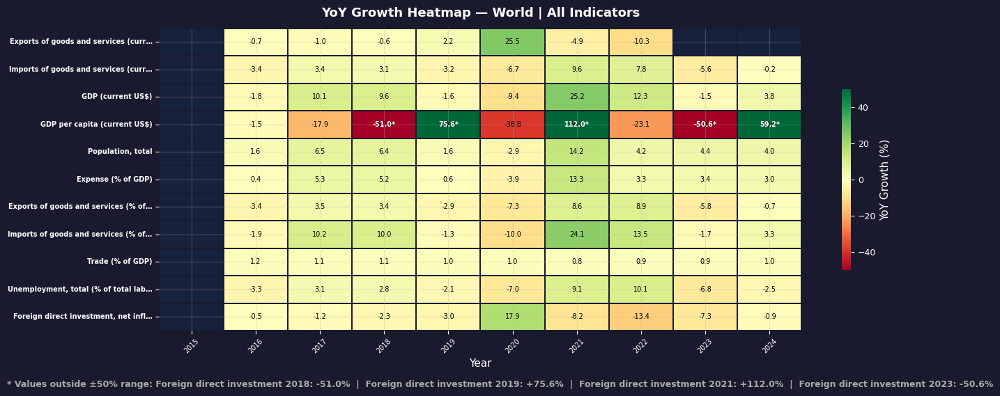

In [99]:
# Inter-indicator YoY heatmap 
if not world_stats.empty:    plot_entity_trend_multi(df, "World", world_stats)

**Trend Insights**

- The left panel shows the absolute World aggregate trajectory — structural breaks (red) flag years of significant deviation from the trend.
- The CAGR vs average growth comparison is meaningful: CAGR captures compounding and is less sensitive to a single bad year, while avg growth is arithmetic and more influenced by outlier years. CAGR captures compounding and is less sensitive to a single bad year,  while avg growth is arithmetic and more influenced by outlier years
  When they diverge significantly, it signals high inter-year volatility.

- The right panel reveals asymmetry in growth — persistent green bars indicate sustained expansion, while isolated red bars suggest punctual shocks rather than structural reversals.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 3. World vs Global Average
</div>

In [100]:
def plot_world_vs_global_avg(df: pd.DataFrame, indicator_name: str, indicator_unit: str, figsize: tuple = (16, 6)) -> None:
    """     Two-panel World vs countries comparison: 
            VALUE : World aggregate vs SUM of countries
                 → Tests data coherence: if World ≈ Sum, the dataset is consistent.
                 → A gap signals missing countries or WB aggregation methodology.
            GROWTH : World YoY vs MEAN of countries YoY
                → Tests dynamic alignment: if World growth > mean, large economies are growing faster than small ones (divergence).    """
    
    ## World series
    world = (df[(df["country_name"] == "World") & (df["indicator_name"] == indicator_name)].dropna(subset=["value"]).sort_values("year")
             .set_index("year")["value"])
    if world.empty:
        print(f"⚠️  No World data for : {indicator_name}")
        return

    ## Country-level aggregations
    ctry = df[(df["entity_type"]   == "COUNTRY") & (df["indicator_name"] == indicator_name)].dropna(subset=["value"])
    sum_countries  = ctry.groupby("year")["value"].sum()
    mean_countries = ctry.groupby("year")["value"].mean()

    ## YoY growth
    world_growth = world.pct_change() * 100
    mean_growth  = mean_countries.pct_change() * 100

    common_val    = world.index.intersection(sum_countries.index)
    common_growth = world_growth.index.intersection(mean_growth.index)

    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=figsize)
    fig.suptitle(f"World vs Countries — {indicator_name}", fontsize=13, color="white", y=1.01)

    # Value — coherence test 
    ax1.plot(common_val, world.loc[common_val], color=C["blue"], linewidth=2.5, marker="o", markersize=5, label="World (WB)", zorder=3)
    ax1.plot(common_val, sum_countries.loc[common_val], color=C["orange"], linewidth=2.2, marker="s", markersize=5, linestyle="--", 
             label="Sum of countries", zorder=3)
    ax1.fill_between(common_val, world.loc[common_val], sum_countries.loc[common_val], alpha=0.12, color=C["red"], label="Gap (coherence)")
    ax1.set_xlabel("Year", color="white")
    ax1.set_ylabel(indicator_unit, color="white")
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x/1e12:.1f}T' if x >= 1e12 else f'${x/1e9:.0f}B'))
    ax1.set_title("Value — World vs Sum of Countries\n(coherence check)", fontsize=11, color="white")
    ax1.set_xticks(common_val)
    ax1.tick_params(axis="x", rotation=45)
    add_legend(ax1, fontsize=8)

    # Growth — dynamic alignment 
    ax2.plot(common_growth, world_growth.loc[common_growth], color=C["blue"], linewidth=2.5, marker="o", markersize=5, label="World YoY growth", zorder=3)
    ax2.plot(common_growth, mean_growth.loc[common_growth], color=C["orange"], linewidth=2.2, marker="s", markersize=5, linestyle="--", 
             label="Mean country growth", zorder=3)
    ax2.fill_between(common_growth, world_growth.loc[common_growth], mean_growth.loc[common_growth], alpha=0.12, color=C["purple"], label="Divergence")
    ax2.axhline(0, color=C["grey"], linewidth=1)
    ax2.set_xlabel("Year", color="white")
    ax2.set_ylabel("YoY Growth (%)", color="white")
    ax2.set_title("Growth — World vs Mean of Countries\n(dynamic alignment)", fontsize=11, color="white")
    ax2.set_xticks(common_growth)
    ax2.tick_params(axis="x", rotation=45)
    add_legend(ax2, fontsize=8)

    # Coherence summary
    if len(common_val) > 0:
        gap_pct = ((world.loc[common_val] - sum_countries.loc[common_val]) / sum_countries.loc[common_val] * 100).mean()
        verdict = "Coherent" if abs(gap_pct) < 5 else "Gap detected"
        ax1.text(0.5, 0.96, f"Avg gap : {gap_pct:+.1f}%  →  {verdict}", transform=ax1.transAxes, ha="left", va="top", fontsize=8.5, color="white",
                 bbox=dict(boxstyle="round,pad=0.3", facecolor=C["ax_bg"], edgecolor=C["spine"], alpha=0.85))

    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/F_3_world_average_countries_{ind_name}.png')
    plt.show()

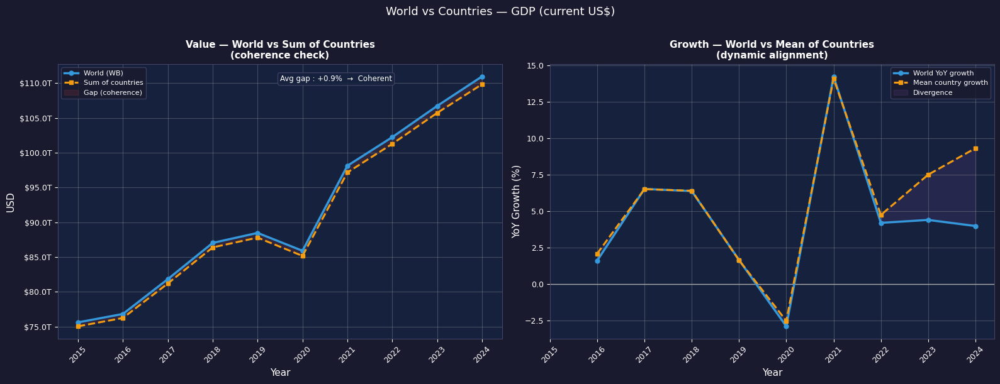

In [101]:
plot_world_vs_global_avg(df, indicator, unit)

**World vs Average Insights**

- The World aggregate (WB official) reflects a weighted total — it is dominated by large economies, while the cross-country mean treats all countries equally.
- A persistent gap between the two signals structural concentration: a few large countries drive the World figure far above the simple average.
- Divergence in growth rates (right panel) is particularly informative — if World growth outpaces the average, it means large economies grew faster than small ones in that year, increasing global inequality on this indicator.
- Divergence in YoY growth between World and the cross-country mean  reveals which years were driven by a few large economies vs
  broad-based global momentum.


<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 4. Growth Profile
</div>

In [102]:
def compute_growth_profile (df: pd.DataFrame, entity_name: str, z_threshold: float = 2.0) -> pd.DataFrame:
    """    Compute growth profile metrics for ALL indicators of one entity. Metrics: avg_growth, volatility, pct_positive, max_positive_shock, 
           max_negative_shock, shock_count, n_positive_shocks, n_negative_shocks, shock_balance    """
    
    data = (df[df["country_name"] == entity_name].dropna(subset=["yoy_growth"]).sort_values(["indicator_name", "year"]))
    results = []
    for ind_name, g in data.groupby("indicator_name"):
        growth = g["yoy_growth"]
        if len(growth) < 3:   continue

        # Shock detection (entity-relative z-score)
        mean_g, std_g = growth.mean(), growth.std()
        if std_g > 0:
                       z = (growth - mean_g) / std_g
                       n_pos_shock = int((z >  z_threshold).sum())
                       n_neg_shock = int((z < -z_threshold).sum())
        else:          n_pos_shock = n_neg_shock = 0

        n_years       = len(growth)
        shock_count   = n_pos_shock + n_neg_shock
        shock_balance = (n_pos_shock - n_neg_shock) / n_years

        results.append({
                        "indicator_name"    : ind_name,
                        "avg_growth"        : growth.mean(),
                        "volatility"        : growth.std(),
                        "pct_positive"      : (growth > 0).mean(),
                        "n_positive_years"  : int((growth > 0).sum()),
                        "n_negative_years"  : int((growth < 0).sum()),
                        "max_positive_shock": growth.max(),
                        "max_negative_shock": growth.min(),
                        "shock_count"       : shock_count,
                        "n_positive_shocks" : n_pos_shock,
                        "n_negative_shocks" : n_neg_shock,
                        "shock_balance"     : shock_balance,
                        })

    return (pd.DataFrame(results).sort_values("avg_growth", ascending=False).reset_index(drop=True))

In [103]:
if not trend_world.empty:
    world_profile = compute_growth_profile(df, "World")
      
    print(f"✅ Growth profile computed for {len(world_profile)} indicators")

✅ Growth profile computed for 11 indicators


In [104]:
world_profile.style.format({c: "{:+.2%}" for c in 
                            ["avg_growth", "volatility", "max_positive_shock", "max_negative_shock", "pct_positive"]} | {"shock_balance": "{:+.3f}"}
                            ).background_gradient(subset=["avg_growth"], cmap="RdYlGn")

,indicator_name,avg_growth,volatility,pct_positive,n_positive_years,n_negative_years,max_positive_shock,max_negative_shock,shock_count,n_positive_shocks,n_negative_shocks,shock_balance
0,"Foreign direct investment, net inflows (BoP, current US$)",+7.09%,+60.03%,+33.33%,3,6,+111.98%,-51.03%,0,0,0,+0.000
1,Exports of goods and services (current US$),+5.19%,+10.32%,+55.56%,5,4,+25.18%,-9.44%,0,0,0,+0.000
2,Imports of goods and services (current US$),+5.14%,+10.29%,+55.56%,5,4,+24.08%,-9.97%,0,0,0,+0.000
3,GDP (current US$),+4.45%,+4.66%,+88.89%,8,1,+14.23%,-2.91%,1,1,0,+0.111
4,GDP per capita (current US$),+3.41%,+4.67%,+88.89%,8,1,+13.28%,-3.85%,1,1,0,+0.111
5,Expense (% of GDP),+1.47%,+11.35%,+28.57%,2,5,+25.52%,-10.31%,1,1,0,+0.143
6,"Population, total",+1.00%,+0.12%,+100.00%,9,0,+1.17%,+0.84%,0,0,0,+0.000
7,Exports of goods and services (% of GDP),+0.53%,+5.82%,+44.44%,4,5,+9.59%,-6.73%,0,0,0,+0.000
8,Imports of goods and services (% of GDP),+0.48%,+5.95%,+44.44%,4,5,+8.92%,-7.28%,0,0,0,+0.000
9,Trade (% of GDP),+0.38%,+6.30%,+44.44%,4,5,+10.07%,-7.04%,0,0,0,+0.000


In [105]:
def plot_growth_profile(profile_df: pd.DataFrame, df_trend: pd.DataFrame, entity_name: str, indicator_name: str, figsize: tuple = (16, 6)) -> None:
    """   growth profile: key metrics scorecards + shock features for ONE indicator   |   YoY growth bar chart per year    """

    row = profile_df[profile_df["indicator_name"] == indicator_name]
    if row.empty:
        print(f"⚠️  No growth profile for {indicator_name}")
        return
    row = row.iloc[0]

    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=figsize)
    fig.suptitle(f"Growth Profile — {entity_name} | {indicator_name}", fontsize=13, color="white", y=1.01)

    # Scorecard metrics 
    metrics = {
                "Avg Growth"   : row["avg_growth"]         * 100,
                "Volatility"   : row["volatility"]          * 100,
                "Max Positive" : row["max_positive_shock"]  * 100,
                "Max Negative" : row["max_negative_shock"]  * 100,
              }
    colors_m = [ C["green"] if v >= 0 else C["red"] for v in metrics.values()]
    bars = ax1.bar(list(metrics.keys()), list(metrics.values()), color=colors_m, edgecolor="none", width=0.55)
    ax1.axhline(0, color=C["grey"], linewidth=1)
    for bar, val in zip(bars, metrics.values()):
        offset = 0.2 if val >= 0 else -0.5
        ax1.text(bar.get_x() + bar.get_width() / 2, val + offset, f"{val:+.1f}%", ha="center", va="bottom", color="white", 
                 fontsize=8.5, fontweight="bold")

    ## Shock info box
    ax1.text(0.98, 0.97, f"{row['pct_positive']:.0%} positive years  " f"({int(row['n_positive_years'])}+ / {int(row['n_negative_years'])}-)"
                         f"\nShocks : {int(row['shock_count'])}  "   f"(+{int(row['n_positive_shocks'])} / "
                         f"-{int(row['n_negative_shocks'])})"        f"\nBalance : {row['shock_balance']:+.3f}",
            transform=ax1.transAxes, ha="right", va="top", fontsize=8, color="white", 
            bbox=dict(boxstyle="round,pad=0.4", facecolor=C["ax_bg"], edgecolor=C["spine"], alpha=0.85))
    ax1.set_ylabel("(%)", color="white")
    ax1.set_title("Key Growth Metrics + Shocks", fontsize=11, color="white")

    # YoY bar chart per year
    growth_ts = df_trend.dropna(subset=["growth_yoy"])
    bar_colors = [C["green"] if v >= 0 else C["red"] for v in growth_ts["growth_yoy"]]
    ax2.bar(growth_ts["year"], growth_ts["growth_yoy"] * 100, color=bar_colors, edgecolor="none", width=0.7)
    ax2.axhline(0, color=C["grey"], linewidth=1)
    ax2.axhline(row["avg_growth"] * 100, color=C["orange"], linewidth=1.6, linestyle="--", label=f"Avg = {row['avg_growth']:+.2%}")
    
    ## Annotate each bar
    for _, r in growth_ts.iterrows():
        val = r["growth_yoy"] * 100
        ax2.text(r["year"], val + (0.3 if val >= 0 else -0.5), f"{val:+.1f}", ha="center", va="bottom", color="white", fontsize=7)
    ax2.set_xlabel("Year", color="white")
    ax2.set_ylabel("YoY Growth (%)", color="white")
    ax2.set_title("YoY Growth per Year", fontsize=11, color="white")
    ax2.set_xticks(growth_ts["year"])
    ax2.tick_params(axis="x", rotation=45)
    add_legend(ax2)

    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/F_4_growth_profile_{ind_name}.png')
    plt.show()

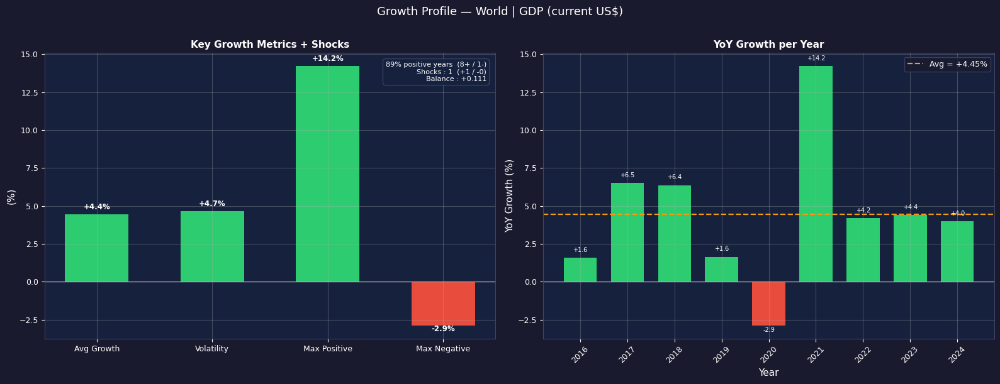

In [106]:
plot_growth_profile(world_profile, trend_world, "World", indicator)

In [107]:
def plot_growth_profile_cross(profile_df:  pd.DataFrame, entity_name: str, highlight_ind: str | None = None, figsize: tuple = (12, 12)) -> None:
    """    Cross-indicator growth profile comparison: avg growth ranking all indicators  — shock balance ranking (positive vs negative shock asymmetry)  """
    
    fig, (ax1, ax2) = styled_subplots(nrows=2, ncols=1, figsize=figsize)
    fig.suptitle(f"Growth Profile Comparison — {entity_name} | All Indicators", fontsize=13, fontweight="bold",color="white", y=1.01)

    # Avg growth ranking 
    df_g = profile_df.sort_values("avg_growth")
    colors_g = [
                C["orange"] if n == highlight_ind
                else C["green"] if v >= 0
                else C["red"]
                for n, v in zip(df_g["indicator_name"], df_g["avg_growth"])
               ]
    
    ax1.barh(df_g["indicator_name"], df_g["avg_growth"] * 100, color=colors_g, edgecolor="none", height=0.65)
    ax1.axvline(0, color=C["grey"], linewidth=1)
    ax1.set_xlabel("Avg YoY Growth (%)", color="white")
    ax1.set_title("Growth Ranking", fontsize=11, color="white")
    ax1.tick_params(labelsize=7)

    # Shock balance 
    df_s = profile_df.sort_values("shock_balance")
    colors_s = [
                C["orange"] if n == highlight_ind
                else C["green"] if v >= 0
                else C["red"]
                for n, v in zip(df_s["indicator_name"], df_s["shock_balance"])
                ]
    ax2.barh(df_s["indicator_name"], df_s["shock_balance"], color=colors_s, edgecolor="none", height=0.65)
    ax2.axvline(0, color=C["grey"], linewidth=1)
    ax2.set_xlabel("Shock Balance (pos − neg) / n_years", color="white")
    ax2.set_title("Shock Asymmetry", fontsize=11, color="white")
    ax2.tick_params(labelsize=7)

    plt.tight_layout()
    save_figure(fig, '../Figures/Indicators/F_4_growth_profile_comparison.png')
    plt.show()

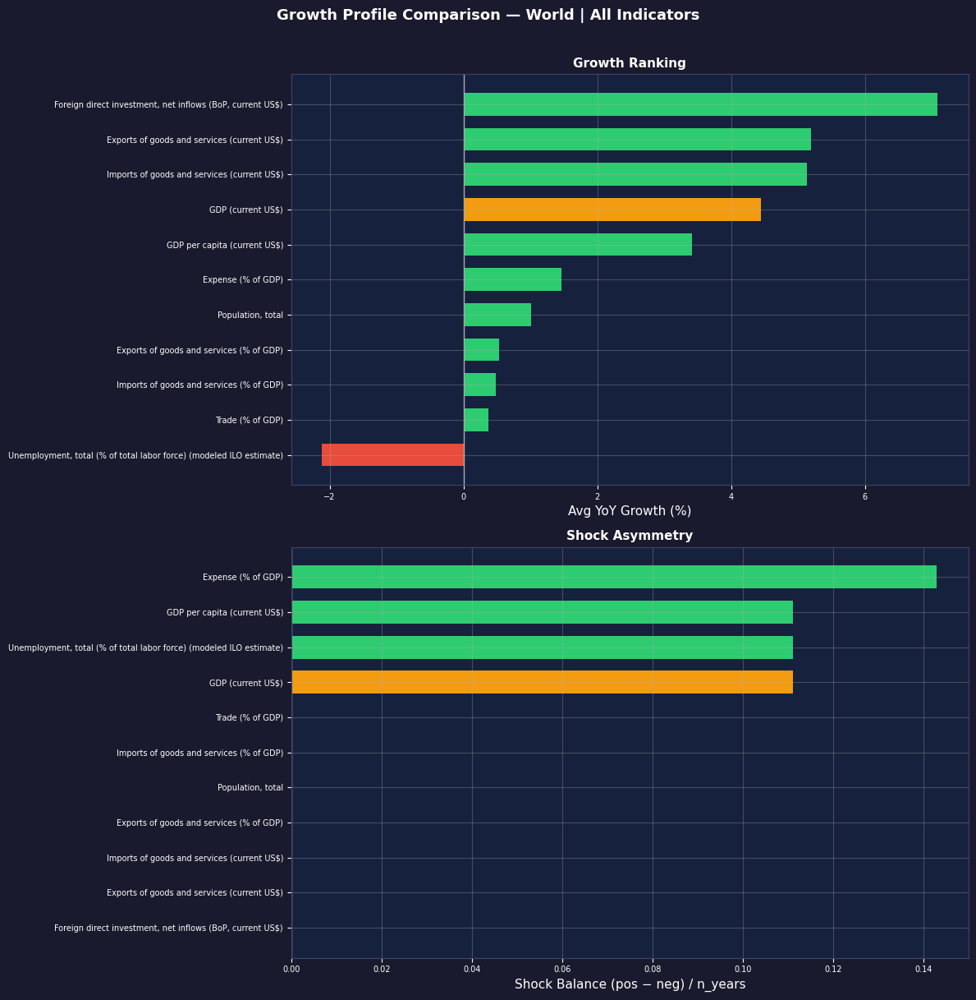

In [108]:
# Cross-indicator comparison 
plot_growth_profile_cross(world_profile, "World", highlight_ind=indicator)

**Growth Profile Insights**

- The shock info box consolidates the shock structure: count, direction asymmetry, and balance — a positive shock_balance means the entity experienced more positive extremes than negative one
- The YoY bar chart is analytically more informative than a histogram  for short series: each year is labeled, positive/negative years ar
  color-coded, and the average line provides a visual baselin.
nd.
- The cross-indicator comparison reveals which economic dimensions had the strongest and most asymmetric growth for World — directly comparable to country-level profiles in Section G.

<div style="background-color: #eaf2f8; padding-left: 20px; border: 1px solid; border-radius: 5px;">

# G. Analyse Country
</div>

This section applies the same analytical framework as Section F (World) to any individual country.
All functions are reused — only the `country` parameter changes.
Set `country` below to run the full section on any entity in the dataset.

In [109]:
#  Parameters
country   = "USA"
indicator = "GDP (current US$)"    

# Unit 
unit = df.loc[df["indicator_name"] == indicator, "indicator_unit"].dropna().iloc[0]

# Country data check 
df_country = df[(df["country_name"]   == country) & (df["indicator_name"] == indicator)].sort_values("year").reset_index(drop=True)

if df_country.empty: print(f"⚠️  No data for : {country} — {indicator}")
else:
    print(f"🌍 Country   : {country}")
    print(f"📊 Indicator : {indicator}")
    print(f"📐 Unit      : {unit}")
    print(f"📅 Period    : {df_country['year'].min()} – {df_country['year'].max()}")
    print(f"📦 Non-null  : {df_country['value'].notna().sum()} / {len(df_country)}")

🌍 Country   : USA
📊 Indicator : GDP (current US$)
📐 Unit      : USD
📅 Period    : 2015 – 2024
📦 Non-null  : 10 / 10


<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 1. Summary Statistics & CAGR
</div>

In [110]:
# Compute stats for ALL indicators of the selected country 
country_stats = compute_entity_stats(df, country)
country_stats.sample()

,indicator_name,indicator_unit,start_year,end_year,n_obs,mean,median,std,min,max,first_value,last_value,cagr
14,Real interest rate (%),%,2015,2021,7,2.2037,2.4752,1.5219,-1.0872,3.7197,2.4752,-1.0872,NaN


In [111]:
if country_stats.empty:
    print(f"⚠️  No data for : {country}")
else:
    print(f"✅ {len(country_stats)} indicators computed for {country}")
    display(country_stats.style.format(
        {col: _format_value for col in ["mean", "median", "std", "min", "max", "first_value", "last_value"]} | {"cagr": "{:+.2%}"}).background_gradient(subset=["cagr"], cmap="RdYlGn"))

✅ 15 indicators computed for USA


,indicator_name,indicator_unit,start_year,end_year,n_obs,mean,median,std,min,max,first_value,last_value,cagr
0,"Inflation, consumer prices (annual %)",%,2015,2024,10,2.88,2.29,2.26,0.12,8.00,0.12,2.95,+42.91%
1,GDP (current US$),USD,2015,2024,10,22.43T,21.22T,3.67T,18.21T,28.75T,18.21T,28.75T,+5.21%
2,GDP per capita (current US$),USD per capita,2015,2024,10,67.7K,64.1K,9.9K,56.6K,84.5K,56.6K,84.5K,+4.56%
3,Imports of goods and services (current US$),USD,2015,2024,10,3.28T,3.12T,522.42B,2.74T,4.10T,2.79T,4.10T,+4.36%
4,Exports of goods and services (current US$),USD,2015,2024,10,2.59T,2.54T,369.38B,2.15T,3.19T,2.27T,3.19T,+3.86%
5,Expense (% of GDP),% of GDP,2015,2023,9,25.15,22.68,4.05,22.29,32.27,22.48,24.90,+1.28%
6,"Population, total",Persons,2015,2024,10,330.6M,330.9M,5.6M,321.8M,340.1M,321.8M,340.1M,+0.62%
7,Imports of goods and services (% of GDP),% of GDP,2015,2024,10,14.66,14.65,0.70,13.19,15.53,15.35,14.27,-0.81%
8,Trade (% of GDP),%,2015,2024,10,26.28,26.53,1.37,23.40,27.82,27.82,25.38,-1.02%
9,Exports of goods and services (% of GDP),% of GDP,2015,2024,10,11.62,11.83,0.73,10.21,12.47,12.47,11.11,-1.28%


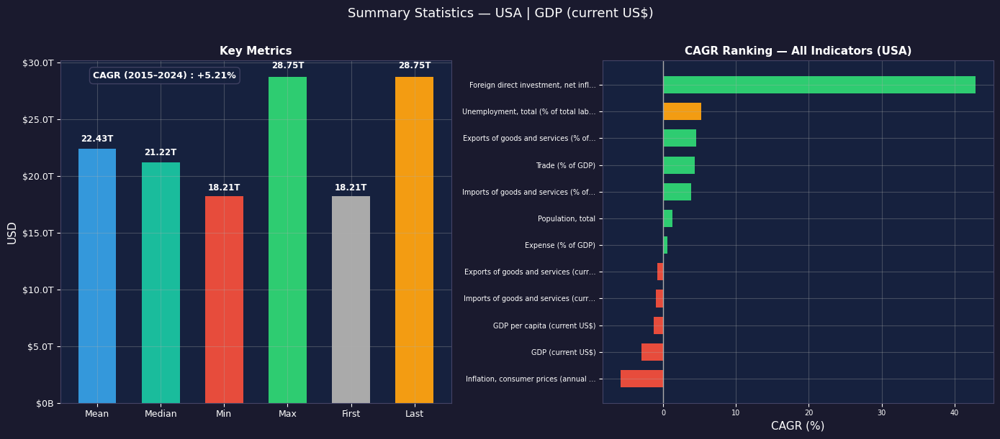

In [112]:
if not country_stats.empty:    plot_entity_stats(country_stats, country, indicator)

In [113]:
def plot_cagr_world_vs_country(country_stats: pd.DataFrame, world_stats: pd.DataFrame, country_name: str, highlight_ind: str | None = None, 
                               figsize: tuple = (14, 6)) -> None:
    """  Side-by-side CAGR comparison: Country vs World per indicator. Reveals on which dimensions the country outperformed or underperformed World. """
    # Merge on indicator_name
    merged = country_stats[["indicator_name", "cagr"]].rename(columns={"cagr": "cagr_country"}) \
                       .merge(world_stats[["indicator_name", "cagr"]].rename(columns={"cagr": "cagr_world"}), on="indicator_name", how="inner")  \
                       .dropna(subset=["cagr_country", "cagr_world"])

    merged["outperformance"] = merged["cagr_country"] - merged["cagr_world"]
    merged = merged.sort_values("outperformance")

    if merged.empty:
        print("⚠️  No common indicators between country and World")
        return

    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=figsize)
    fig.suptitle(f"CAGR Comparison — {country_name} vs World", fontsize=13, color="white", y=1.01)

    # Side-by-side bars
    inds    = merged["indicator_name"].tolist()
    x       = np.arange(len(inds))
    width   = 0.35

    ax1.barh(x + width / 2, merged["cagr_country"] * 100, width, color=C["orange"], alpha=0.85, label=country_name)
    ax1.barh(x - width / 2, merged["cagr_world"] * 100,   width, color=C["blue"], alpha=0.85, label="World")
    ax1.set_yticks(x)
    ax1.set_yticklabels([n[:35] + "…" if len(n) > 35 else n for n in inds], fontsize=7)
    ax1.axvline(0, color=C["grey"], linewidth=1)
    ax1.set_xlabel("CAGR (%)", color="white")
    ax1.set_title("CAGR per Indicator", fontsize=11, color="white")
    add_legend(ax1, fontsize=8)

    # Outperformance (country − world) ───────────────────────────────
    out_colors = [
                    C["orange"] if n == highlight_ind
                    else C["green"] if v >= 0
                    else C["red"]
                    for n, v in zip(merged["indicator_name"], merged["outperformance"])
                 ]
    bars = ax2.barh(merged["indicator_name"], merged["outperformance"] * 100, color=out_colors, edgecolor="none", height=0.65)
    ax2.axvline(0, color=C["grey"], linewidth=1)
    for bar, val in zip(bars, merged["outperformance"] * 100):
        offset = 0.05 if val >= 0 else -0.05
        ax2.text(val + offset, bar.get_y() + bar.get_height() / 2, f"{val:+.1f}pp", va="center", color="white", fontsize=7.5)
    ax2.set_xlabel("Country CAGR − World CAGR (pp)", color="white")
    ax2.set_title("Outperformance vs World", fontsize=11, color="white")
    ax2.tick_params(labelsize=7)

    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/G_1_cagr_world_vs_{country_name}.png')
    plt.show()

In [114]:
def plot_cagr_world_vs_country(country_stats: pd.DataFrame, world_stats: pd.DataFrame, country_name: str, highlight_ind: str | None = None,
                               figsize: tuple = (14, 12)) -> None:
    """  Side-by-side CAGR comparison: Country vs World per indicator.
         Reveals on which dimensions the country outperformed or underperformed World."""

    merged = (country_stats[["indicator_name", "cagr"]].rename(columns={"cagr": "cagr_country"})
              .merge(world_stats[["indicator_name", "cagr"]].rename(columns={"cagr": "cagr_world"}),
                     on="indicator_name", how="inner").dropna(subset=["cagr_country", "cagr_world"]))

    merged["outperformance"] = merged["cagr_country"] - merged["cagr_world"]
    merged = merged.sort_values("outperformance")

    if merged.empty:
        print(f"No common indicators between {country_name} and World")
        return

    # ── Detect outliers in each panel independently ───────────────────────────
    cagr_all   = pd.concat([merged["cagr_country"], merged["cagr_world"]]) * 100
    thresh_cagr = cagr_all.abs().quantile(0.95)
    out_all    = merged["outperformance"] * 100
    thresh_out  = out_all.abs().quantile(0.95)
    
    fig, (ax1, ax2) = styled_subplots(nrows=2, ncols=1, figsize=figsize)
    fig.suptitle(f"CAGR Comparison — {country_name} vs World", fontsize=13, color="white", y=1.01)

    # ── Panel 1 : side-by-side bars ───────────────────────────────────────────
    inds  = merged["indicator_name"].tolist()
    x     = np.arange(len(inds))
    width = 0.7

    c_vals = merged["cagr_country"] * 100
    w_vals = merged["cagr_world"]   * 100

    x_max = min(thresh_cagr, max(c_vals.abs().max(), w_vals.abs().max())) * 1.05
    ax1.set_xlim(-x_max, x_max)

    ax1.barh(x + width / 2, c_vals.clip(-x_max, x_max), width, color=C["orange"], alpha=0.85, label=country_name)
    ax1.barh(x - width / 2, w_vals.clip(-x_max, x_max), width, color=C["blue"],   alpha=0.85, label="World")

    # Annotate truncated outliers
    for idx, (cv, wv, ind) in enumerate(zip(c_vals, w_vals, inds)):
        for val, offset, color in [(cv, width/2, C["orange"]), (wv, -width/2, C["blue"])]:
            if abs(val) > thresh_cagr:
                ax1.text(x_max * 0.97, idx + offset, f"{val:+.1f}%*", va="center", ha="right",
                         fontsize=8.5, color="white", fontweight="bold")

    ax1.set_yticks(x)
    ax1.set_yticklabels([n[:35] + "…" if len(n) > 35 else n for n in inds], fontsize=7)
    ax1.axvline(0, color=C["grey"], linewidth=1)
    ax1.set_xlabel("CAGR (%)", color="white")
    ax1.set_title("CAGR per Indicator", fontsize=11, color="white")
    add_legend(ax1, fontsize=9)

    # ── Panel 2 : outperformance ──────────────────────────────────────────────
    out_vals   = merged["outperformance"] * 100
    out_colors = [C["orange"] if n == highlight_ind else C["green"] if v >= 0 else C["red"]
                  for n, v in zip(merged["indicator_name"], out_vals)]

    bars = ax2.barh(merged["indicator_name"], out_vals.clip(-x_max, x_max),
                    color=out_colors, edgecolor="none", height=0.65)


    for bar, val in zip(bars, out_vals):
        is_truncated = abs(val) > thresh_out
    
        if is_truncated:
            x_pos  = x_max * 0.97 if val > 0 else -x_max * 0.97
            ha     = "right" if val > 0 else "left"
            label  = f"{val:+.1f}pp →" if val > 0 else f"← {val:+.1f}pp"
            ax2.text(x_pos, bar.get_y() + bar.get_height() / 2, label, va="center", ha=ha,
                     fontsize=8.5, color="white", fontweight="bold")
        else:
            offset = 0.3 if val >= 0 else -0.3
            ax2.text(val + offset, bar.get_y() + bar.get_height() / 2, f"{val:+.1f}pp", va="center", 
                     ha="left" if val >= 0 else "right", fontsize=8.5, color="white")

    ax2.axvline(0, color=C["grey"], linewidth=1)
    ax2.set_xlabel("Country CAGR − World CAGR (pp)", color="white")
    ax2.set_yticklabels([n[:35] + "…" if len(n) > 35 else n for n in inds], fontsize=7)
    ax2.set_title("Outperformance vs World", fontsize=11, color="white")
    ax2.set_xlim(-x_max, x_max)
    ax2.tick_params(labelsize=7)

    # Footnote for truncated values
    extremes_1 = merged[c_vals.abs() > thresh_cagr]["indicator_name"].tolist()
    extremes_2 = merged[out_vals.abs() > thresh_out]["indicator_name"].tolist()
    all_ext    = list(set(extremes_1 + extremes_2))
    if all_ext:
        fig.text(0.01, -0.02, "* Truncated — values exceed axis range: " +
                 ", ".join(n.split(",")[0] for n in all_ext[:4]),
                 fontsize=10, fontweight = "bold", color="#aaaaaa", ha="left")

    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/G_1_cagr_world_vs_{country_name}.png')
    plt.show()

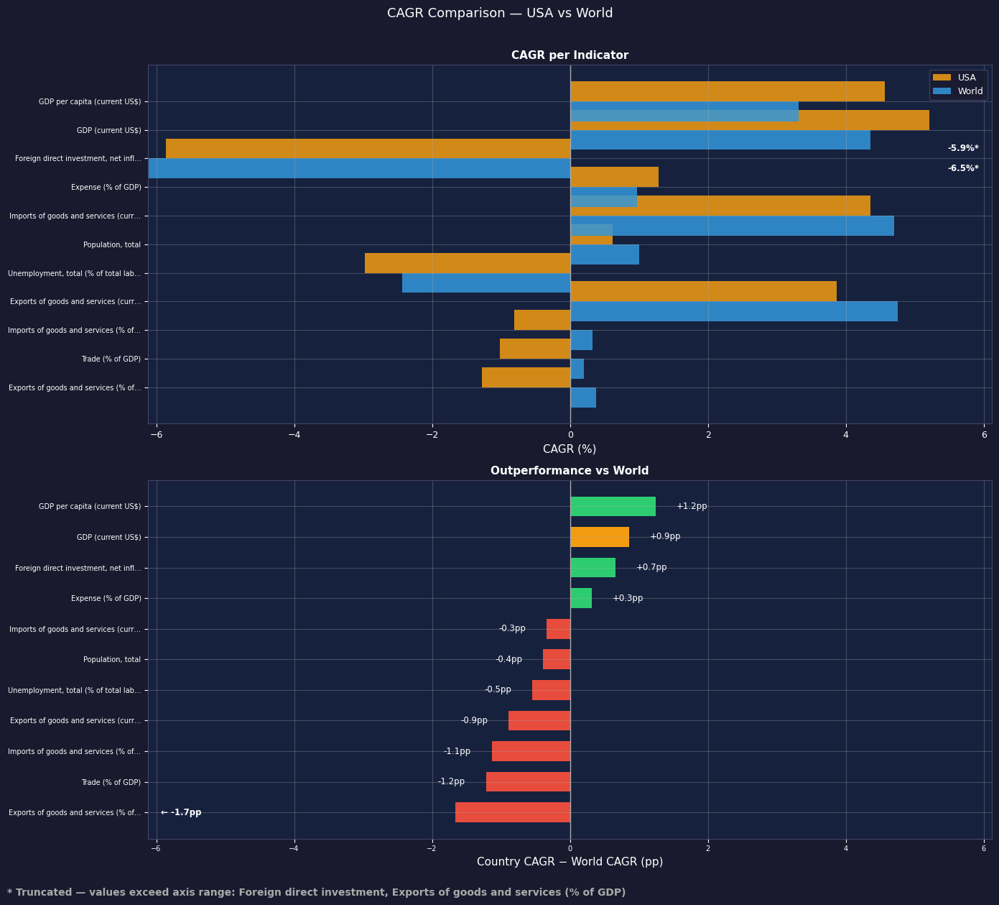

In [115]:
# CAGR: Country vs World cross-indicator 
if not country_stats.empty and not world_stats.empty:  plot_cagr_world_vs_country(country_stats, world_stats, country, highlight_ind=indicator)

**Summary Insights**

- CAGR provides a compound growth benchmark — compare it to the World CAGR (Section F) to assess whether this country grew faster or slower than the global aggregate.
- The Min/Max gap reflects the amplitude of variation over the period — a wide gap signals high sensitivity to shocks or structural transitions.
- First vs Last values show the net change over the full period —
  combined with CAGR, they indicat  whether growth was front-loade
  (early acceleration) or back-loaded (recent momentum).

- The CAGR ranking across all indicators reveals which economic dimensions grew fastest for this country — the structural growth engines.
- The outperformance chart (Country − World CAGR) shows on which dimensions the country exceeded or lagged global pace — green = faster than World, red = slower.
- A country systematically above zero on most indicators is structurally outperforming the global average; a mixed profile reveals dimension-specific strengths and weaknesses.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 2. Trend & Structural Breaks
</div>

In [116]:
trend_country = compute_entity_trend(df, country, indicator)
trend_country.sample().style.format(_format_value, subset="value")

,year,value,growth_yoy,indicator_name
4,2019,21.38T,0.041295,GDP (current US$)


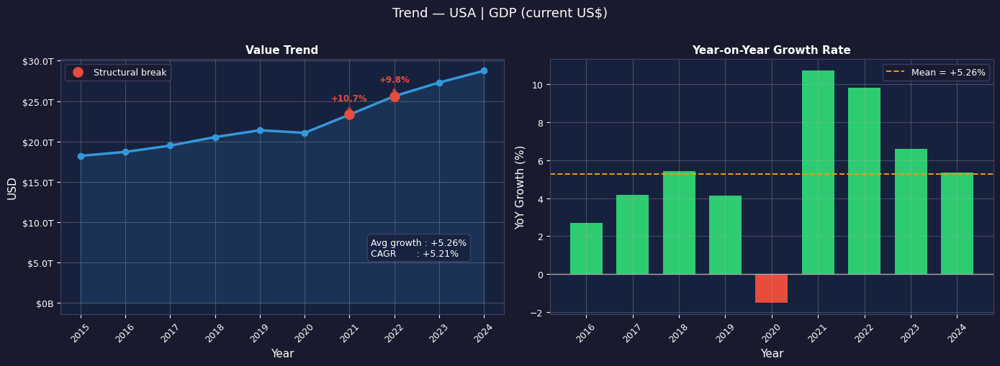

In [117]:
if not trend_country.empty:
    avg_growth_country = compute_average_growth(trend_country)
    breaks_country     = detect_structural_breaks(trend_country, threshold=0.07)
    cagr_country       = (country_stats.loc[country_stats["indicator_name"] == indicator, "cagr"].values[0] if not country_stats.empty else np.nan)
    
    plot_entity_trend(trend_country, country, indicator, unit, avg_growth_country, cagr_country, breaks_country)

else:    print(f"⚠️  No trend data for : {country} — {indicator}")

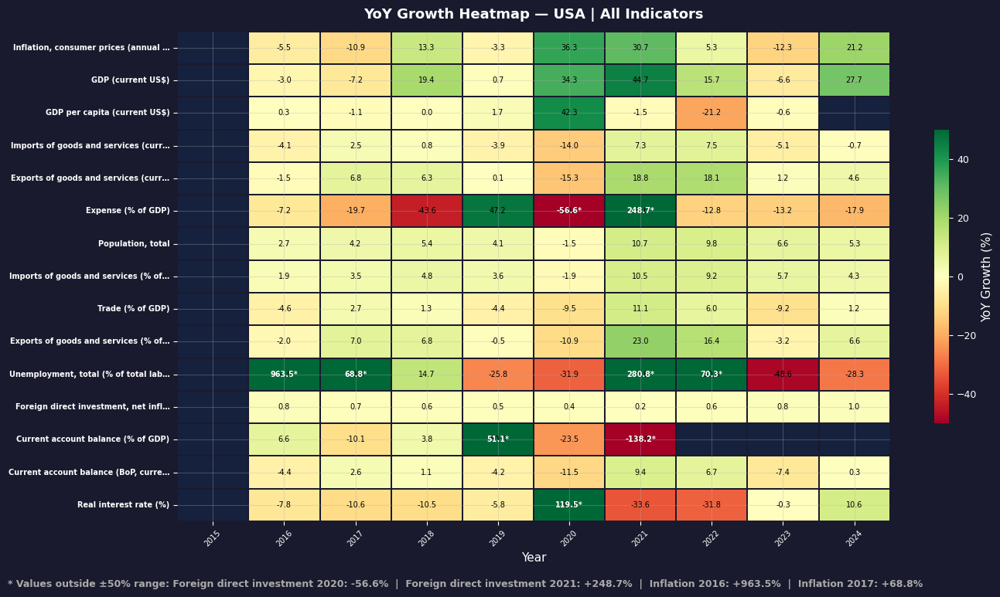

In [118]:
# Inter-indicator YoY heatmap 
if not country_stats.empty:    plot_entity_trend_multi(df, country, country_stats)

**Trend Insights**

- Structural breaks signal years of significant deviation from the country's own growth trajectory — compare their timing to global breaks identified in Section E to distinguish country-specific shocks from global ones.
- A consistently growing trend with few breaks indicates structural stability; frequent structural breaks suggest vulnerability to external shocks  or a transition economy undergoing structural transformation

- The YoY growth bars reveal recovery speed after negative shocks — a sharp rebound in the following year suggests resilience.
- Structural breaks identify country-specific shock years — compare their timing to global breaks (Section E) to distinguish local shocks from global ones.
- The heatmap gives a simultaneous view of all indicators' YoY dynamics — years with many red cells were broadly negative years for this country across all dimensions
- `Unemployment (USA) shows extreme YoY volatility` — +963.5% in 2016 and
  +280.8% in 2021 reflect the COVID shock (mass layoffs 2020, rapid rehiring 2021)
  amplified by the small base effect of the US unemployment rate.
  These are real economic signals, not data errors.
- `Expense (% of GDP) spike in 2021 (+248.7%)` reflects the post-COVID
  fiscal expansion — government spending surged as a share of GDP during
  stimulus programs, then normalized sharply (-56.6% in 2020 is the
  denominator effect of GDP contraction)..

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 3. Growth Profile
</div>

In [119]:
if not trend_country.empty:
    # ── Compute growth profile for ALL country indicators ──────────────────────
    country_profile = compute_growth_profile(df, country)

    print(f"✅ Growth profile computed for {len(country_profile)} indicators")
    
    display(country_profile.sample(3).style.format(
        {c: "{:+.2%}" for c in ["avg_growth", "volatility", "max_positive_shock", "max_negative_shock", "pct_positive"]} | {"shock_balance": "{:+.3f}"}
        ).background_gradient(subset=["avg_growth"], cmap="RdYlGn"))

✅ Growth profile computed for 15 indicators


,indicator_name,avg_growth,volatility,pct_positive,n_positive_years,n_negative_years,max_positive_shock,max_negative_shock,shock_count,n_positive_shocks,n_negative_shocks,shock_balance
8,"Unemployment, total (% of total labor force) (modeled ILO estimate)",+3.30%,+45.77%,+22.22%,2,7,+119.54%,-33.59%,1,1,0,+0.111
10,"Population, total",+0.62%,+0.25%,+100.00%,9,0,+0.98%,+0.16%,0,0,0,+0.000
6,GDP per capita (current US$),+4.62%,+3.70%,+88.89%,8,1,+10.53%,-1.90%,0,0,0,+0.000


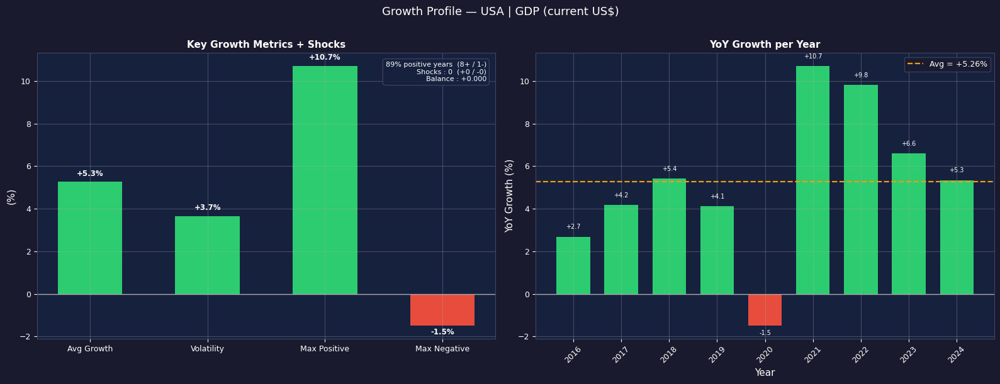

In [120]:
plot_growth_profile(country_profile, trend_country, country, indicator)

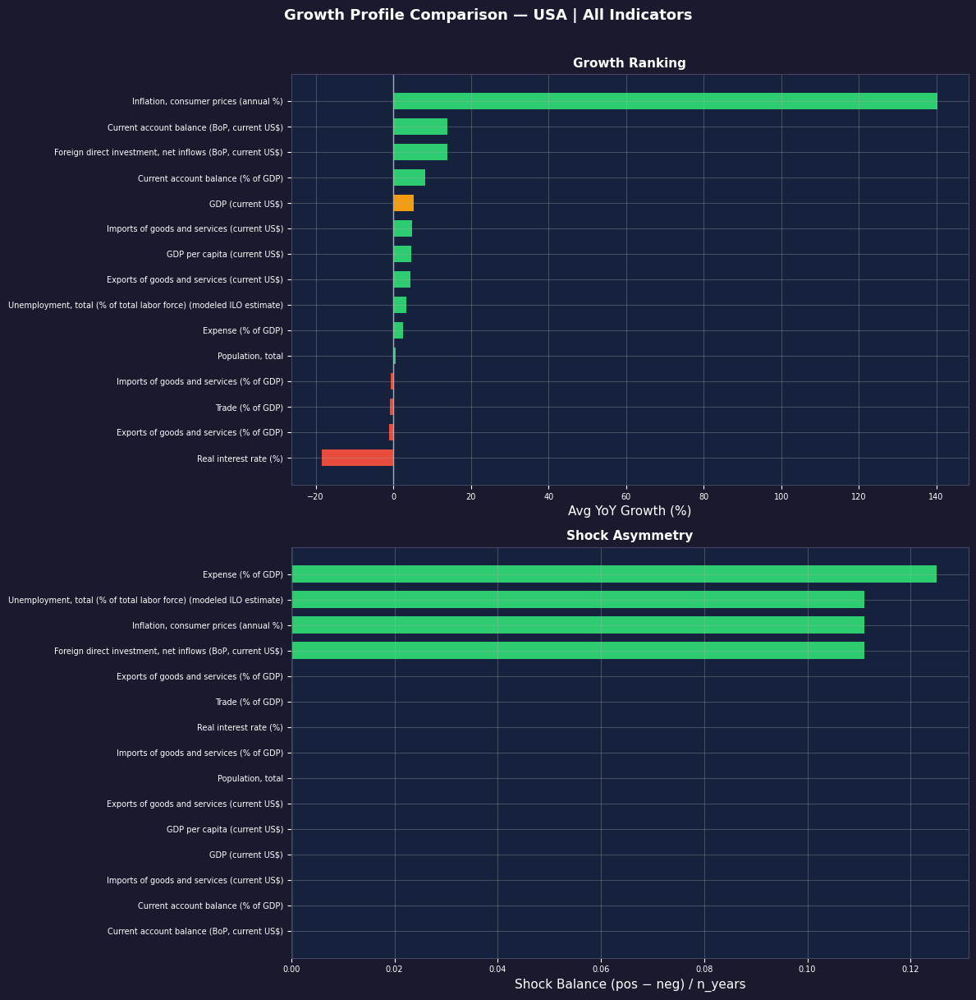

In [121]:
# Cross-indicator comparison 
plot_growth_profile_cross(country_profile, country, highlight_ind=indicator)

**Growth Profile Insights**

- High volatility relative to average growth signals an unstable growth pattern — gains and losses alternate without a clear directional trend.
- A high share of positive years combined with low volatility is the signature of a structurally stable growth regime.
- The max negative shock magnitude reveals worst-case exposure —  the deepest single-year contraction the country has experienced
  a key input for stress-testing scenarios.

- The shock info box now shows the full shock structure — compare `shock_balance` with World's (Section F.4) to see if the country has a more asymmetric shock profile..
- The cross-indicator comparison reveals the country's structural growth engines and most shock-prone dimensions — directly feeding the indicator dynamics analysis in G.4.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 4. Most Dynamic Indicators
</div>

This sub-section ranks all available indicators by their period growth rate for the selected country.
It gives a cross-indicator view of where this country has been most and least dynamic.

In [122]:
def compute_country_indicator_dynamics(df: pd.DataFrame, entity_name: str) -> pd.DataFrame:
    """    For a given country, compute period growth rate (first → last) across all available indicators.    """
    
    data = (df[df["country_name"] == entity_name].dropna(subset=["value"]).sort_values("year"))
    results = (data.groupby("indicator_name").agg(first_value=("value", "first"), last_value=("value", "last")).reset_index())
    results["growth_pct"] = ((results["last_value"] - results["first_value"]) / results["first_value"] * 100)
    
    return results.sort_values("growth_pct", ascending=False).reset_index(drop=True)

In [123]:
dynamics_df = compute_country_indicator_dynamics(df, country)
dynamics_df.sample()

,indicator_name,first_value,last_value,growth_pct
13,"Foreign direct investment, net inflows (BoP, c...",511434000000.0000,297058000000.0000,-41.9167


In [125]:
def plot_country_indicator_dynamics(dynamics_df: pd.DataFrame, entity_name: str, highlight_ind: str | None = None, figsize: tuple = (13, 6)) -> None:
    """   Horizontal bar chart ranking all indicators by period growth for one country.  Highlights the currently selected indicator.    """
    
    df_plot = dynamics_df.sort_values("growth_pct")
    colors  = [C["orange"] if row["indicator_name"] == highlight_ind else C["green"] if row["growth_pct"] >= 0     else C["red"]
               for _, row in df_plot.iterrows()]

    fig, ax = styled_figure(figsize=figsize)
    ax.set_title(f"Indicator Dynamics — {entity_name} (Period Growth %)", fontsize=13, color="white", pad=12)

    bars = ax.barh(df_plot["indicator_name"], df_plot["growth_pct"], color=colors, edgecolor="none", height=0.65)
    ax.axvline(0, color=C["grey"], linewidth=1)

    for bar, val in zip(bars, df_plot["growth_pct"]):
        offset = 1 if val >= 0 else -1
        ax.text(val + offset, bar.get_y() + bar.get_height() / 2, f"{val:+.1f}%", va="center", color="white", fontsize=8)

    ax.set_xlabel("Period Growth Rate (%)", color="white")
    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/G_4_{entity_name}_indicator_dynamics.png')
    plt.show()

In [126]:
print(f"Top 5 most dynamic indicators for {country}:")
display(dynamics_df.head(5))

Top 5 most dynamic indicators for USA:


,indicator_name,first_value,last_value,growth_pct
0,"Inflation, consumer prices (annual %)",0.1186,2.9495,2386.3832
1,"Current account balance (BoP, current US$)",-408447000000.0000,-1185294000000.0000,190.1953
2,Current account balance (% of GDP),-2.2435,-4.1226,83.7609
3,GDP (current US$),18206020741000.0000,28750956130731.1992,57.9200
4,GDP per capita (current US$),56572.9189,84534.0408,49.4249


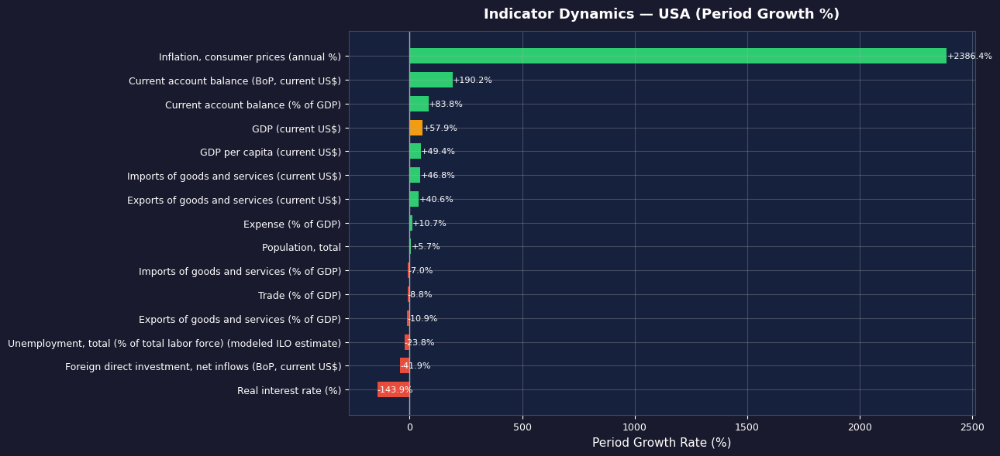

In [127]:
plot_country_indicator_dynamics(dynamics_df, country, highlight_ind=indicator)

In [128]:
def plot_country_indicator_dynamics(dynamics_df: pd.DataFrame, entity_name: str, highlight_ind: str | None = None, figsize: tuple = (13, 6)) -> None:
    """Horizontal bar chart ranking all indicators by period growth for one country.
       Highlights the currently selected indicator."""

    df_plot = dynamics_df.sort_values("growth_pct")

    # ── Detect and handle outliers ────────────────────────────────────────────
    threshold = df_plot["growth_pct"].abs().quantile(0.90)
    x_max     = threshold 

    df_normal  = df_plot[df_plot["growth_pct"].abs() <= threshold]
    df_outlier = df_plot[df_plot["growth_pct"].abs() >  threshold]

    colors_normal = [C["orange"] if row["indicator_name"] == highlight_ind
                     else C["green"] if row["growth_pct"] >= 0 else C["red"]
                     for _, row in df_normal.iterrows()]

    fig, ax = styled_figure(figsize=figsize)
    ax.set_title(f"Indicator Dynamics — {entity_name} (Period Growth %)",
                 fontsize=13, color="white", pad=12)

    # Normal bars
    bars = ax.barh(df_normal["indicator_name"], df_normal["growth_pct"],
                   color=colors_normal, edgecolor="none", height=0.65)
    ax.axvline(0, color=C["grey"], linewidth=1)

    for bar, val in zip(bars, df_normal["growth_pct"]):
        offset = 1 if val >= 0 else -1
        ax.text(val + offset, bar.get_y() + bar.get_height() / 2,
                f"{val:+.1f}%", va="center", color="white", fontsize=8)

    # Truncated outlier bars
    for _, row in df_outlier.iterrows():
        color    = C["orange"] if row["indicator_name"] == highlight_ind \
                   else C["green"] if row["growth_pct"] >= 0 else C["red"]
        bar_len  = x_max * 0.85 if row["growth_pct"] > 0 else -x_max * 0.85
        ax.barh(row["indicator_name"], bar_len,
                color=color, edgecolor="none", height=0.65, alpha=0.85)
        ax.barh(row["indicator_name"], bar_len,
                color="none", edgecolor="white", linewidth=0.5,
                hatch="///", height=0.65)
        x_pos = x_max * 0.97 if row["growth_pct"] > 0 else -x_max * 0.97
        ha    = "right" if row["growth_pct"] > 0 else "left"
        label = f"{row['growth_pct']:+.0f}% →" if row["growth_pct"] > 0 else f"← {row['growth_pct']:+.0f}%"
        #ax.text(x_pos, 0, label, va="center", ha=ha, fontsize=8, color="white", fontweight="bold")
        ax.annotate(label, xy=(bar_len, row["indicator_name"]), xytext=(x_pos, row["indicator_name"]),
                    fontsize=8, color="white", fontweight="bold", va="center", ha=ha)

    ax.set_xlim(-x_max, x_max)
    ax.set_xlabel("Period Growth Rate (%)", color="white")

    # Footnote
    if not df_outlier.empty:
        note = " | ".join(f"{r['indicator_name'].split(',')[0]}: {r['growth_pct']:+.0f}%"
                          for _, r in df_outlier.iterrows())
        fig.text(0.01, -0.02, f"* Truncated: {note}",
                 fontsize=8, fontweight = "bold", color="white", ha="left")

    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/G_4_{entity_name}_indicator_dynamics.png')
    plt.show()

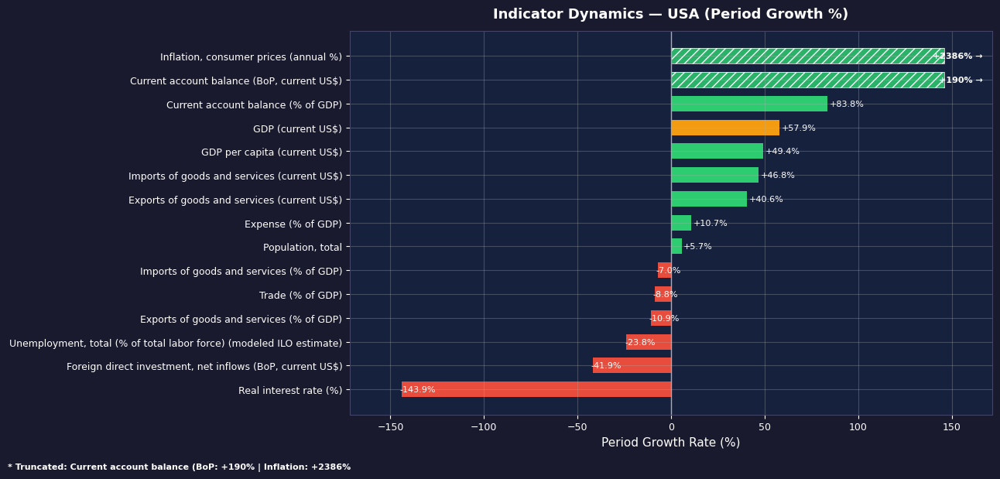

In [129]:
plot_country_indicator_dynamics(dynamics_df, country, highlight_ind=indicator)

**Indicator Dynamics Insights**

- This cross-indicator view reveals the country's structural growth engines —
  which economic dimensions expanded the most over the period.
- Indicators with negative growth (red) flag structural contractions or
  deteriorations specific to this country.
- The highlighted indicator (orange) shows where the currently selected
  indicator ranks relative to all others — useful for contextualizing
  whether the chosen indicator is a growth leader or laggard for this country.
- **Caution on rate indicators** — period growth on % indicators (Inflation,
  Unemployment, Real Interest Rate) reflects scaling effects from the base year,
  not structural momentum. Interpret alongside level indicators (USD) for context.

**For USA :**
- **Real Interest Rate (-143.9%)** signals a structural shift into negative
  real rates — a key macro signal for investment and borrowing conditions.
- **Inflation (+2386.4%)** reflects near-zero base in 2015 amplified by the
  2021–2022 surge — a scaling artifact, not a structural growth signal.
- **FDI (-41.9%) and Unemployment (-22.2%)** are structural decliners —
  FDI contraction reflects post-COVID domestic investment preference,
  unemployment improvement reflects labor market tightening.ngs.


<div style="background-color: #eaf2f8; padding-left: 20px; border: 1px solid; border-radius: 5px;">

# H. Comparisons
</div>

This section compares entities across three levels:
- **H1** — World vs one Country
- **H2** — Country vs Country (bilateral)
- **H3** — Multi-country trend (panel view across 4 metrics)

In [268]:
# Parameters
indicator  = "GDP (current US$)"
country    = "USA"       # reference country for H1 & H2
country_1  = "USA"       # H2 bilateral
country_2  = "China"               # H2 bilateral
countries  = ["USA", "China", "Germany", "France", "India", "Brazil"]   # H3 panel

unit = df.loc[df["indicator_name"] == indicator, "indicator_unit"].dropna().iloc[0]
print(f"📊 Indicator : {indicator}")
print(f"📐 Unit      : {unit}")

📊 Indicator : GDP (current US$)
📐 Unit      : USD


<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 1. World vs Country
</div>

In [271]:
def plot_world_vs_country(df: pd.DataFrame, country_name: str, indicator_name: str, indicator_unit: str, figsize: tuple = (16, 6)) -> None:
    """    Two-panel comparison — World vs Country: absolute value with start/end annotations  — YoY growth rate overlay    """
    
    entities = [country_name, "World"]
    palette  = {country_name: C["orange"], "World": C["blue"]}

    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=figsize)
    fig.suptitle(f"{country_name} vs World — {indicator_name}", fontsize=13, color="white", y=1.01)

    for metric, ax, ylabel, title in [("value", ax1, indicator_unit, "Value"), ("yoy_growth", ax2, "YoY Growth (%)", "Growth Rate")]:
        data = df[(df["indicator_name"] == indicator_name) & (df["country_name"].isin(entities))].dropna(subset=[metric]).sort_values("year")
        if data.empty:
            ax.text(0.5, 0.5, "No data", transform=ax.transAxes, ha="center", color=C["grey"])
            continue
        scale = 100 if metric == "yoy_growth" else 1

        for entity in entities:
            sub = data[data["country_name"] == entity].sort_values("year")
            if sub.empty:     continue
            vals = sub[metric] * scale
            color = palette[entity]

            ax.plot(sub["year"], vals, color=color, linewidth=2.3, marker="o", markersize=5, label=entity, zorder=3)

            # Start & end annotations
            for idx, label_offset in [(0, -14), (-1, 10)]:
                pt = sub.iloc[idx]
                v  = pt[metric] * scale
                fmt = f"{v:+.1f}%" if metric == "yoy_growth" else _format_value(pt[metric])
                ax.annotate(fmt, xy=(pt["year"], v), xytext=(0, label_offset), textcoords="offset points", 
                            ha="center", fontsize=7.5, color=color, fontweight="bold")

        if metric == "yoy_growth": ax.axhline(0, color=C["grey"], linewidth=1)

        ax.set_xlabel("Year", color="white")
        ax.set_ylabel(ylabel, color="white")
        ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x/1e12:.1f}T' if x >= 1e12 else f'${x/1e9:.0f}B'))
        ax.set_title(title, fontsize=11, color="white")
        ax.set_xticks(data["year"].unique())
        ax.tick_params(axis="x", rotation=45)
        add_legend(ax)

    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/H_1_world_vs_{country_name}_{safe_indicator_name(indicator_name)}.png')
    plt.show()

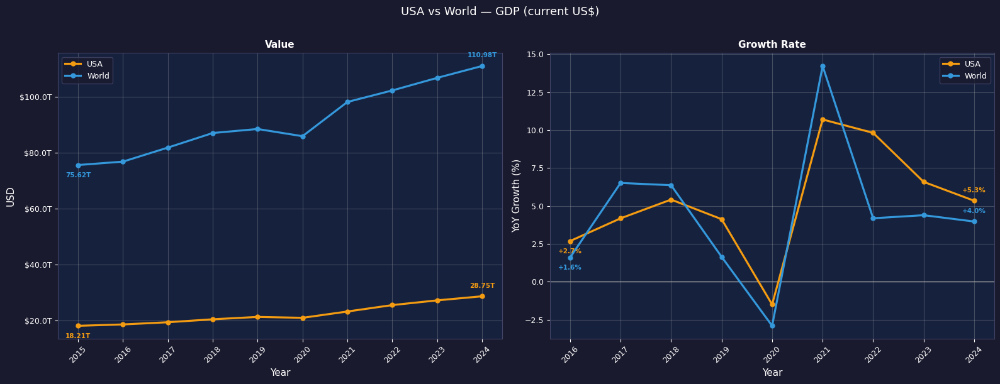

In [273]:
plot_world_vs_country(df, country, indicator, unit)

**World vs Country Insights**

- Start and end annotations quantify the absolute change for each entity over the period — directly comparable without reading axis values.
- when the country's growth rate (right panel) consistently exceeds World's, it signals a catching-up or leadership dynamic; when it lags, the country is growing below global pace — a structural underperformance signal
- Synchronized dips in both series (e.g. 2020) confirm exposure to the same global shocks; diverging dips suggest country-specific vulnerabilities.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 2. Country vs Country
</div>

In [277]:
def compute_country_comparison(df: pd.DataFrame, country_1: str, country_2: str, indicator_name: str, metric: str = "value") -> pd.DataFrame:
    """    Pivot table: year × [country_1, country_2, difference, ratio]    """
    
    data = df[(df["country_name"].isin([country_1, country_2])) & (df["indicator_name"] == indicator_name)].dropna(subset=[metric])
    if data.empty:  return pd.DataFrame()

    table = (data.pivot_table(index="year", columns="country_name", values=metric, aggfunc="mean").reset_index().rename_axis(None, axis=1))
    
    if country_1 in table.columns and country_2 in table.columns:
        table["difference"] = table[country_1] - table[country_2]
        table["ratio"]      = table[country_1] / table[country_2]
    
    table.insert(0, "indicator_name", indicator_name)  
    table.insert(1, "metric", metric)
    
    return table

In [279]:
# Comparison table 
comp_table = compute_country_comparison(df, country_1, country_2, indicator)

if not comp_table.empty:
    print(f"📊 Indicator : {comp_table['indicator_name'].iloc[0]}")
    print(f"📐 Metric    : {comp_table['metric'].iloc[0]}")

    display_cols = [c for c in comp_table.columns if c not in ["indicator_name", "metric"]]
    display(comp_table[display_cols].style.format({col: _format_value for col in [country_1, country_2, "difference"]} | {"ratio": "{:.3f}"}) \
    .background_gradient(subset=["difference"], cmap="RdYlGn"))

📊 Indicator : GDP (current US$)
📐 Metric    : value


,year,China,USA,difference,ratio
0,2015,11.28T,18.21T,6.93T,1.614
1,2016,11.46T,18.70T,7.24T,1.632
2,2017,12.54T,19.48T,6.94T,1.554
3,2018,14.15T,20.53T,6.39T,1.451
4,2019,14.56T,21.38T,6.82T,1.468
5,2020,15.00T,21.06T,6.06T,1.404
6,2021,18.20T,23.32T,5.11T,1.281
7,2022,18.32T,25.60T,7.29T,1.398
8,2023,18.27T,27.29T,9.02T,1.494
9,2024,18.74T,28.75T,10.01T,1.534


In [281]:
def plot_country_vs_country(df: pd.DataFrame, country_1: str, country_2: str, indicator_name: str, indicator_unit: str, figsize: tuple = (16, 12)) -> None:
    """   4 panel bilateral comparison: value trend overlay — YoY growth overlay — absolute gap (country_1 − country_2) — ratio (country_1 / country_2)  """
    
    palette = {country_1: C["orange"], country_2: C["teal"]}

    fig, axes = plt.subplots(2, 2, figsize=figsize)
    fig.patch.set_facecolor(C["bg"])
    for ax in axes.flatten():        apply_dark_style(ax)
    fig.suptitle(f"{country_1} vs {country_2} — {indicator_name}", fontsize=13, color="white", y=1.01)

    ax_val, ax_growth = axes[0]
    ax_gap, ax_ratio  = axes[1]

    # Top panels : value & growth overlay 
    for metric, ax, ylabel, title, scale in [("value", ax_val, indicator_unit,"Value", 1), ("yoy_growth", ax_growth, "YoY Growth (%)", "Growth Rate", 100)]:
        data = df[(df["country_name"].isin([country_1, country_2])) & (df["indicator_name"] == indicator_name)].dropna(subset=[metric]).sort_values("year")

        for entity in [country_1, country_2]:
            sub  = data[data["country_name"] == entity]
            vals = sub[metric] * scale
            ax.plot(sub["year"], vals, color=palette[entity], linewidth=2.2, marker="o", markersize=5, label=entity)
            # End annotation
            if not sub.empty:
                last = sub.iloc[-1]
                v    = last[metric] * scale
                fmt  = f"{v:+.1f}%" if metric == "yoy_growth" else _format_value(last[metric])
                ax.annotate(fmt, xy=(last["year"], v), xytext=(4, 0), textcoords="offset points", fontsize=8, color=palette[entity], fontweight="bold", va="center")

        if metric == "yoy_growth":       ax.axhline(0, color=C["grey"], linewidth=1)
        ax.set_xlabel("Year", color="white")
        ax.set_ylabel(ylabel, color="white")
        ax_val.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x/1e12:.1f}T' if x >= 1e12 else f'${x/1e9:.0f}B'))
        ax.set_title(title, fontsize=11, color="white")
        ax.set_xticks(data["year"].unique())
        ax.tick_params(axis="x", rotation=45)
        add_legend(ax)

    # Bottom-left : gap 
    comp = compute_country_comparison(df, country_1, country_2, indicator_name)
    if not comp.empty and "difference" in comp.columns:
        gap_colors = [C["green"] if v >= 0 else C["red"] for v in comp["difference"]]
        ax_gap.bar(comp["year"], comp["difference"], color=gap_colors, edgecolor="none", width=0.7)
        ax_gap.axhline(0, color=C["grey"], linewidth=1)
        ax_gap.set_xlabel("Year", color="white")
        ax_gap.set_ylabel(f"Gap ({indicator_unit})", color="white")
        ax_gap.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x/1e12:.1f}T' if x >= 1e12 else f'${x/1e9:.0f}B'))
        ax_gap.set_title(f"Absolute Gap — {country_1} minus {country_2}", fontsize=11, color="white")
        ax_gap.set_xticks(comp["year"])
        ax_gap.tick_params(axis="x", rotation=45)

    # ── Bottom-right : ratio ──────────────────────────────────────────────────
    if not comp.empty and "ratio" in comp.columns:
        ax_ratio.plot(comp["year"], comp["ratio"], color=C["purple"], linewidth=2.3, marker="o", markersize=5)
        ax_ratio.axhline(1, color=C["grey"], linewidth=1, linestyle="--", label="Ratio = 1 (parity)")
        ax_ratio.fill_between(comp["year"], comp["ratio"], 1, where=comp["ratio"] >= 1, alpha=0.15, color=C["green"])
        ax_ratio.fill_between(comp["year"], comp["ratio"], 1, where=comp["ratio"] < 1,  alpha=0.15, color=C["red"])
        ax_ratio.set_xlabel("Year", color="white")
        ax_ratio.set_ylabel(f"Ratio ({country_1} / {country_2})", color="white")
        ax_ratio.set_title(f"Relative Position — {country_1} / {country_2}", fontsize=11, color="white")
        ax_ratio.set_xticks(comp["year"])
        ax_ratio.tick_params(axis="x", rotation=45)
        add_legend(ax_ratio)

    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/H_2_{country_1}_vs_{country_2}_{safe_indicator_name(indicator_name)}_trend.png')
    plt.show()

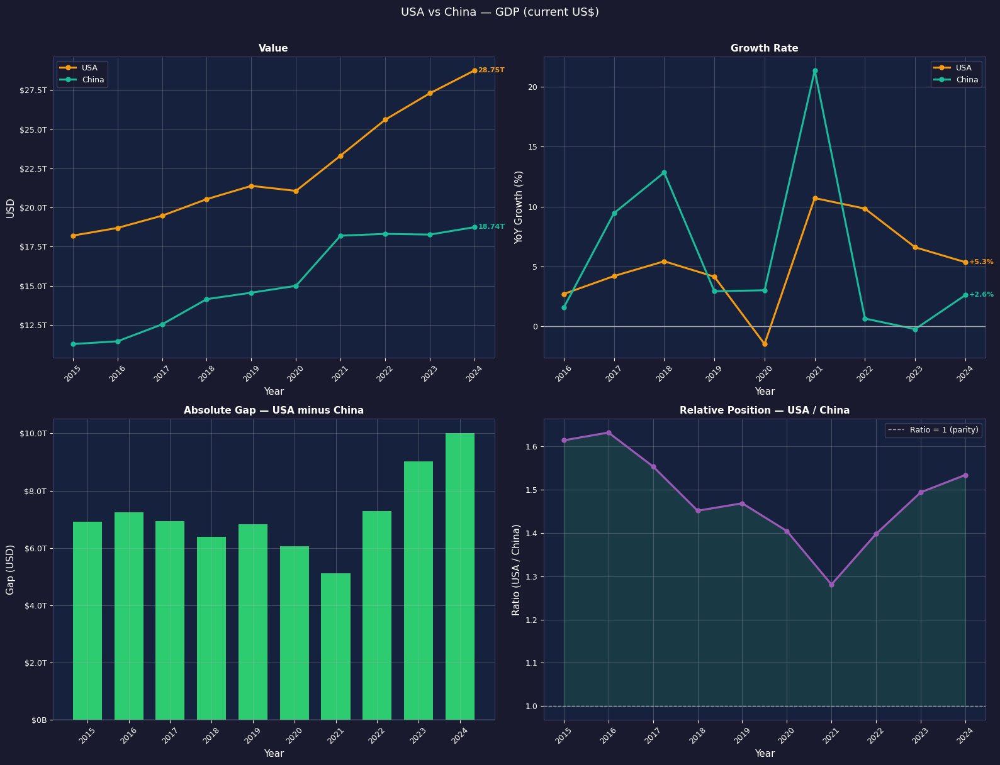

In [283]:
plot_country_vs_country(df, country_1, country_2, indicator, unit)

**Country vs Country Insights**

- The absolute gap panel reveals whether the distance between the two countries is widening or narrowing — a shrinking gap signals convergence.
- The ratio panel is particularly powerful: a ratio trending toward 1 indicates catch-up; a ratio moving away from 1 signals structural divergence.
- Growth rate comparison (top-right) decouples dynamics from levels — a country can have a lower absolute value but consistently higher growth, signaling a structural transition in relative positioning.
- `USA vs China GDP ratio` compressed from 1.61 (2015) to 1.28 (2021) before
  re-widening to 1.54 (2024) — a convergence-then-reversal pattern driven by
  China's post-COVID slowdown.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 3. Multi-Country Trend
</div>

Four metrics are compared across the panel of selected countries.
Each metric provides a different analytical reading of the same indicator:

| Metric | What it reveals |
|---|---|
| `value` | Absolute level — structural size/position |
| `yoy_growth` | Growth rhythm — speed and direction |
| `index_100` | Relative dynamics from a common base (2015 = 100) |
| `z_score` | Deviation from cross-country mean — structural position |

In [287]:
def plot_multi_country(df: pd.DataFrame, countries: list[str], indicator_name: str, indicator_unit: str, metric: str  = "value", 
                       include_world: bool = False, figsize: tuple = (14, 6)) -> None:
    """    Multi-country line chart for a given metric.    Annotates last value for each country on the right margin    """
    
    entities = list(countries)
    if include_world and "World" not in entities:        entities.append("World")

    data = df[(df["country_name"].isin(entities)) & (df["indicator_name"] == indicator_name)].dropna(subset=[metric]).sort_values("year")

    if data.empty:
        print(f"⚠️  No data for metric '{metric}' — {indicator_name}")
        return

    ylabel_map = {"value" : indicator_unit, "yoy_growth" : "YoY Growth (%)", "index_100"  : "Index (base 100)", "z_score"    : "Z-score"}
    scale  = 100 if metric == "yoy_growth" else 1
    ylabel = ylabel_map.get(metric, metric)

    palette = plt.cm.tab10.colors
    color_map = {e: palette[i % 10] for i, e in enumerate(entities)}

    fig, ax = styled_figure(figsize=figsize)
    ax.set_title(f"Multi-Country — {indicator_name} [{metric}]", fontsize=13, color="white", pad=12)

    for entity in entities:
        sub  = data[data["country_name"] == entity].sort_values("year")
        if sub.empty:            continue
        vals  = sub[metric] * scale
        color = color_map[entity]
        ls    = "--" if entity == "World" else "-"

        ax.plot(sub["year"], vals, color=color, linewidth=2.0, linestyle=ls, marker="o", markersize=4, label=entity, zorder=3)
        # Right-margin label
        last = sub.iloc[-1]
        v    = last[metric] * scale
        ax.annotate(f" {entity}  {_format_value(v) if metric == 'value' else f'{v:.1f}'}" , xy=(last["year"], v), xytext=(6, 0),
                    textcoords="offset points", fontsize=7.5, color=color, va="center")

    if metric in ["yoy_growth", "z_score"]:    ax.axhline(0, color=C["grey"], linewidth=1)
    if metric == "index_100":                  ax.axhline(100, color=C["grey"], linewidth=1, linestyle="--")

    ax.set_xlabel("Year", color="white")
    ax.set_ylabel(ylabel, color="white")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x/1e12:.1f}T' if x >= 1e12 else f'${x/1e9:.0f}B'))
    ax.set_xticks(data["year"].unique())
    ax.tick_params(axis="x", rotation=45)
    add_legend(ax, fontsize=7.5)

    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/H_3_{safe_indicator_name(indicator_name)}_{metric}_trend.png')
    plt.show()

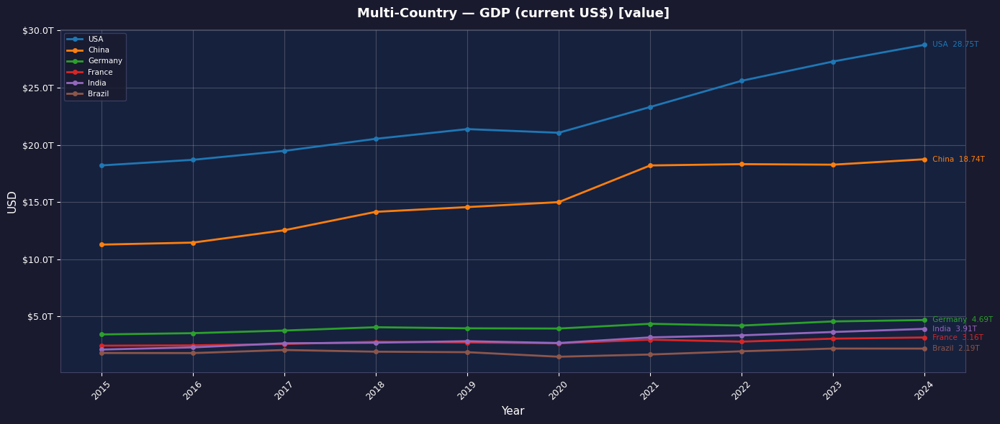

In [288]:
# Value — absolute level
plot_multi_country(df, countries, indicator, unit, metric="value")

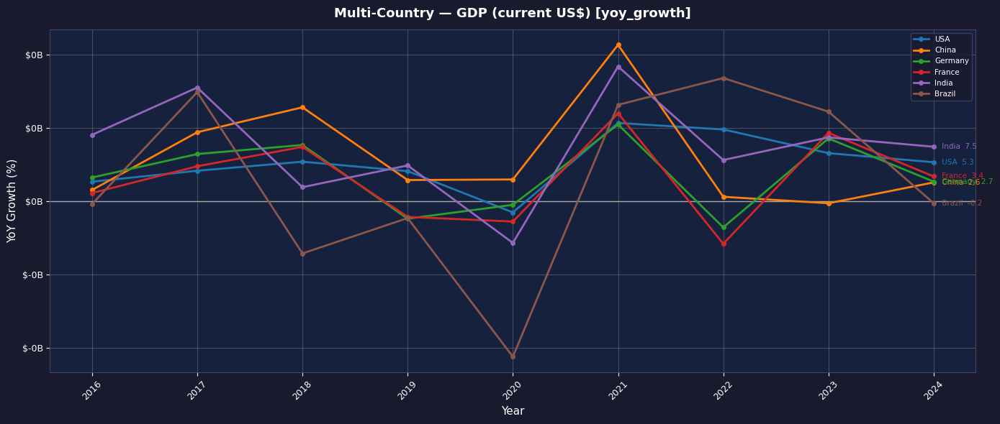

In [290]:
# YoY growth — growth rhythm 
plot_multi_country(df, countries, indicator, unit, metric="yoy_growth")

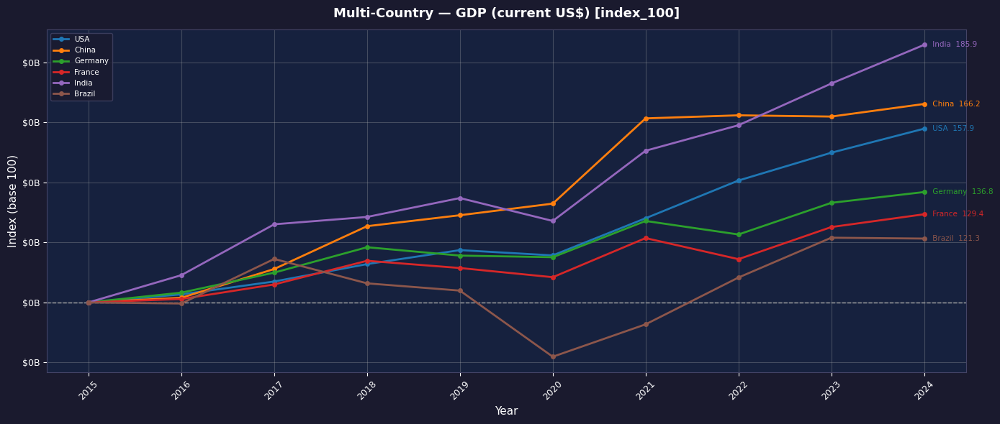

In [292]:
# Index 100 — relative dynamics from same base 
plot_multi_country(df, countries, indicator, unit, metric="index_100")

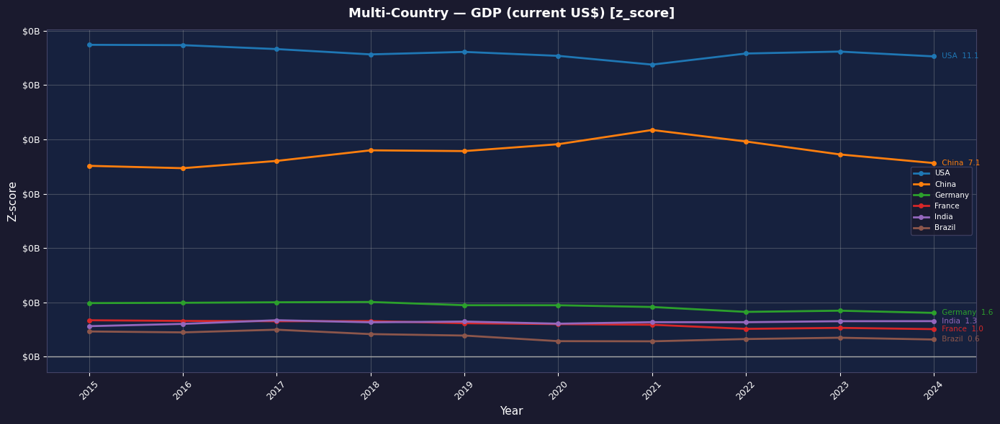

In [293]:
# Z-score — deviation from cross-country mean 
plot_multi_country(df, countries, indicator, unit, metric="z_score")

**Multi-Country Insights**

- `Value` — reveals structural hierarchy: which countries dominate in absolute
  terms and whether the gap is widening or narrowing.
- `YoY Growth` — decouples level from momentum: a country with a low value
  but high growth is on a convergence path; synchronized dips across countries
  confirm global shock exposure (2020 COVID visible in all panels).
- `Index 100` — removes scale differences and shows relative growth from the
  same starting point. India (185.9) and China (166.2) are the fastest growers
  from the 2015 base; France (129.4) shows the most modest trajectory.
- `Z-score` — reveals structural position relative to the cross-country mean.
  China's persistent z > 7 confirms outlier status; France, India, and Brazil
  cluster around z ≈ 1 despite very different absolute levels.
- `Brazil dips below index 100 in 2020` — the only country in this panel to
  record a net GDP contraction in USD terms, reflecting both economic weakness
  and currency depreciation.

<div style="background-color: #eaf2f8; padding-left: 20px; border: 1px solid; border-radius: 5px;">

# I. Growth Analysis
</div>

This section builds a structural growth characterization for each entity × indicator combination.
It progresses from individual metrics (CAGR, volatility) to composite features (regimes, shocks)
and synthesizes them into a **Growth Score** and **Growth Feature Dataset** — the input for Section J (Clustering).

| Sub-section | What it computes |
|---|---|
| I.1 — CAGR | Compound annual growth rate per entity × indicator |
| I.2 — Volatility | YoY growth standard deviation |
| I.3 — Growth Regimes | Classification into Dynamic / Stable / Under Pressure / Declining |
| I.4 — Shocks | Extreme growth events (z-score based) |
| I.5 — Growth Score | Composite score combining all features |
| I.6 — Output | Growth Feature Dataset → input for J & O |

In [131]:
# Parameters 
indicator = "GDP (current US$)"
ind_name = "GDP"
unit = df.loc[df["indicator_name"] == indicator, "indicator_unit"].dropna().iloc[0]
countries = ["USA", "China", "Germany", "France", "India", "Brazil"]
MIN_YEARS   = 5     # minimum observations for CAGR / volatility
Z_THRESHOLD = 2.0   # z-score threshold for shock detection

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 1. CAGR — Compound Annual Growth Rate
</div>

In [133]:
def compute_cagr(df: pd.DataFrame, min_years: int = MIN_YEARS) -> pd.DataFrame:
    """CAGR over full available period per entity x indicator.
    For indicators with sign changes or zero start/end values (e.g. current account balance),
    falls back to OLS slope proxy: slope / |mean_value| — a dimensionless annual rate of change
    comparable in scale to CAGR and always defined regardless of sign.
    """
    from sklearn.linear_model import LinearRegression

    df_valid = df.dropna(subset=["value"]).sort_values("year")

    def _cagr(group):
        if len(group) < min_years:
            return np.nan
        v0 = group["value"].iloc[0]
        vT = group["value"].iloc[-1]
        n  = group["year"].iloc[-1] - group["year"].iloc[0]
        if n <= 0:
            return np.nan

        # Standard CAGR — valid only when both endpoints are strictly positive
        if v0 > 0 and vT > 0:
            return (vT / v0) ** (1 / n) - 1

        # Fallback for signed indicators (sign change, or zero endpoint):
        # OLS slope normalised by mean absolute value → dimensionless rate/year
        X = group["year"].values.reshape(-1, 1).astype(float)
        y = group["value"].values.astype(float)
        slope    = LinearRegression().fit(X, y).coef_[0]
        mean_abs = np.abs(y).mean()
        return slope / mean_abs if mean_abs > 1e-9 else np.nan

    cagr_df = (df_valid
               .groupby(["entity_key", "entity_type", "country_name",
                         "indicator_code", "indicator_name"])
               .apply(_cagr)
               .reset_index(name="cagr"))
    return cagr_df

In [134]:
cagr_df = compute_cagr(df)
print(f"✅ CAGR computed : {len(cagr_df):,} entity × indicator combinations")
cagr_df.sample(3)

✅ CAGR computed : 2,909 entity × indicator combinations


,entity_key,entity_type,country_name,indicator_code,indicator_name,cagr
1978,204,COUNTRY,Nepal,NE.IMP.GNFS.ZS,Imports of goods and services (% of GDP),-0.0113
2897,311,COUNTRY,Zimbabwe,FP.CPI.TOTL.ZG,"Inflation, consumer prices (annual %)",0.2922
2415,253,COUNTRY,Sao Tome and Principe,SP.POP.TOTL,"Population, total",0.0182


In [135]:
def plot_cagr_ranking(cagr_df: pd.DataFrame, indicator_name: str, countries: list[str] | None = None, top_n: int = 10, figsize: tuple = (14, 6)) -> None:
    """    Single horizontal bar chart — countries ranked by CAGR for one indicator.    """
    
    data = cagr_df[(cagr_df["indicator_name"] == indicator_name) & (cagr_df["entity_type"] == "COUNTRY")].dropna(subset=["cagr"])
    if countries: 
        data = data[data["country_name"].isin(countries)]
        title   = f"CAGR — {indicator_name} | Selected Countries"
    else:
        data    = data.nlargest(top_n, "cagr")  # Global top N
        title   = f"CAGR Ranking — {indicator_name} | Top {top_n}"
        
    data = data.sort_values("cagr")
    bar_colors = [C["green"] if v >= 0 else C["red"] for v in data["cagr"]]
 
    fig, ax = styled_figure(figsize=figsize)
    ax.set_title(title, fontsize=13, color="white", pad=12)

    bars = ax.barh(data["country_name"], data["cagr"] * 100, color=bar_colors, edgecolor="none", height=0.65)
    ax.axvline(0, color=C["grey"], linewidth=1)
    ax.axvline(data["cagr"].mean() * 100, color=C["orange"], linewidth=1.4, linestyle="--", label=f"Mean = {data['cagr'].mean():+.2%}")

    for bar, val in zip(bars, data["cagr"] * 100):
        offset = 0.1 if val >= 0 else -0.1
        ax.text(val + offset, bar.get_y() + bar.get_height() / 2, f"{val:+.1f}%", va="center", color="white", fontsize=8.5)

    ax.set_xlabel("CAGR (%)", color="white")
    add_legend(ax)
    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/I_1_CAGR Ranking_{safe_indicator_name(indicator_name)}_Top{top_n}.png')
    plt.show()

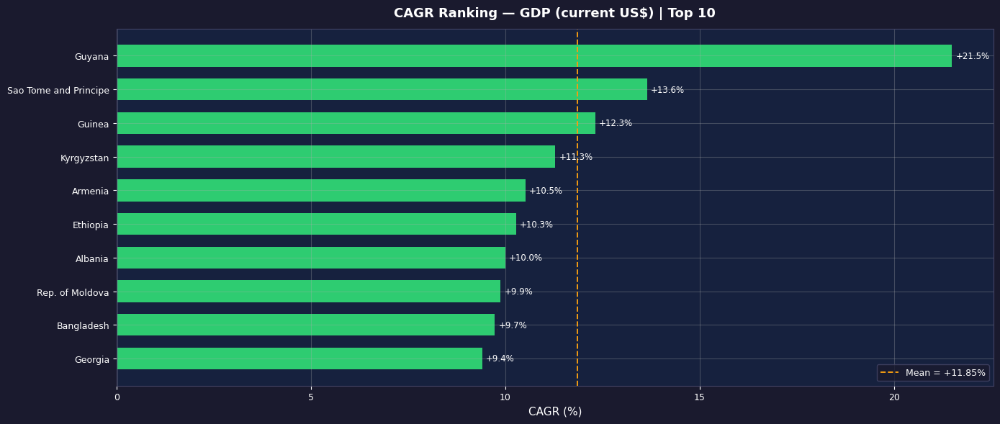

In [136]:
plot_cagr_ranking(cagr_df, indicator, countries=None, top_n=10)

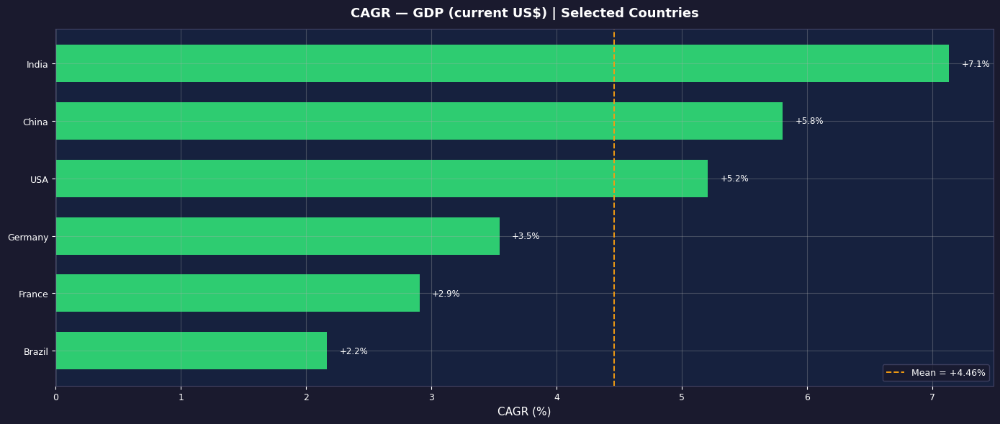

In [137]:
# CAGR for selected countries panel
plot_cagr_ranking(cagr_df, indicator, countries=countries, top_n=len(countries))

**CAGR Insights**

- CAGR smooths year-to-year volatility and provides a single compound rate — more meaningful than average growth when the series has significant swings.
- The mean line (orange) shows whether the selected countries are above
  or below the panel average — useful to contextualize relative performance
  without having to read each bar individually.
- Negative CAGR (red) signals a structural contraction over the full period, not a cyclical dip.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 2. Volatility
</div>

In [138]:
def compute_volatility(df: pd.DataFrame, min_years: int = MIN_YEARS) -> pd.DataFrame:
    """    YoY growth standard deviation per entity × indicator.  Requires at least min_years of non-null YoY growth observations.   """
    
    df_valid = df.dropna(subset=["yoy_growth"]).copy()
    counts   = (df_valid.groupby(["entity_key", "indicator_code"])["yoy_growth"].count().reset_index(name="n_obs"))
    df_valid = df_valid.merge(counts, on=["entity_key", "indicator_code"], how="left")
    df_valid = df_valid[df_valid["n_obs"] >= min_years]

    volatility_df = (df_valid.groupby(["entity_key", "entity_type", "country_name", "indicator_code", "indicator_name", "n_obs"])["yoy_growth"].std()
                     .reset_index(name="volatility"))
    
    return volatility_df

In [140]:
volatility_df = compute_volatility(df)
print(f"✅ Volatility computed : {len(volatility_df):,} entity × indicator combinations")
volatility_df.sample(3)

✅ Volatility computed : 2,800 entity × indicator combinations


,entity_key,entity_type,country_name,indicator_code,indicator_name,n_obs,volatility
375,41,COUNTRY,Barbados,NY.GDP.MKTP.CD,GDP (current US$),9,0.0770
1253,139,COUNTRY,Jamaica,BN.CAB.XOKA.GD.ZS,Current account balance (% of GDP),9,3.3086
487,53,COUNTRY,China,NE.EXP.GNFS.CD,Exports of goods and services (current US$),9,0.1110


In [141]:
def plot_volatility_heatmap(volatility_df:  pd.DataFrame, countries: list[str] | None = None, max_countries: int = 20, quantile_alert: float = 0.9,
                            figsize: tuple = (14, 12)) -> None:
    """    Heatmap: country × indicator → YoY growth volatility.    High-volatility countries flagged on the right margin.    """
    
    data = volatility_df[volatility_df["entity_type"] == "COUNTRY"].copy()
    if countries: data = data[data["country_name"].isin(countries)]
    pivot = data.pivot_table(index="country_name", columns="indicator_name", values="volatility", aggfunc="mean")

    # Trim to most volatile countries if no filter provided
    if not countries and pivot.shape[0] > max_countries:  pivot = pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).head(max_countries).index]
    alert_threshold = np.nanquantile(pivot.values.flatten(), quantile_alert)
    fig, ax = plt.subplots(figsize=figsize)
    fig.patch.set_facecolor(C["bg"])
    ax.set_facecolor(C["ax_bg"])
    
    sns.heatmap(pivot, ax=ax, cmap="RdBu_r", linewidths=0.3, linecolor=C["bg"], robust=True, cbar_kws={"label": "YoY Growth Volatility (std)", "shrink": 0.7})
    ax.set_title("Growth Volatility Heatmap — Country × Indicator", fontsize=13, color="white", pad=12)
    ax.set_xlabel("", color="white")
    ax.set_ylabel("", color="white")
    ax.tick_params(colors="white", labelsize=8)
    ax.tick_params(axis="x", rotation=90)
    inds = data["indicator_name"].unique().tolist()
    ax.set_xticklabels([n[:25] + "…" if len(n) > 35 else n for n in inds], fontsize=8)

    cbar = ax.collections[0].colorbar
    cbar.ax.yaxis.label.set_color("white")
    cbar.ax.tick_params(colors="white")

    # Flag high-volatility countries
    for i, country in enumerate(pivot.index):
        if pivot.loc[country].max() >= alert_threshold: ax.text(pivot.shape[1] + 0.2, i + 0.5, "⚠", va="center", fontsize=9, color=C["red"])

    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/I_2_volatility_heatmap.png')
    plt.show()

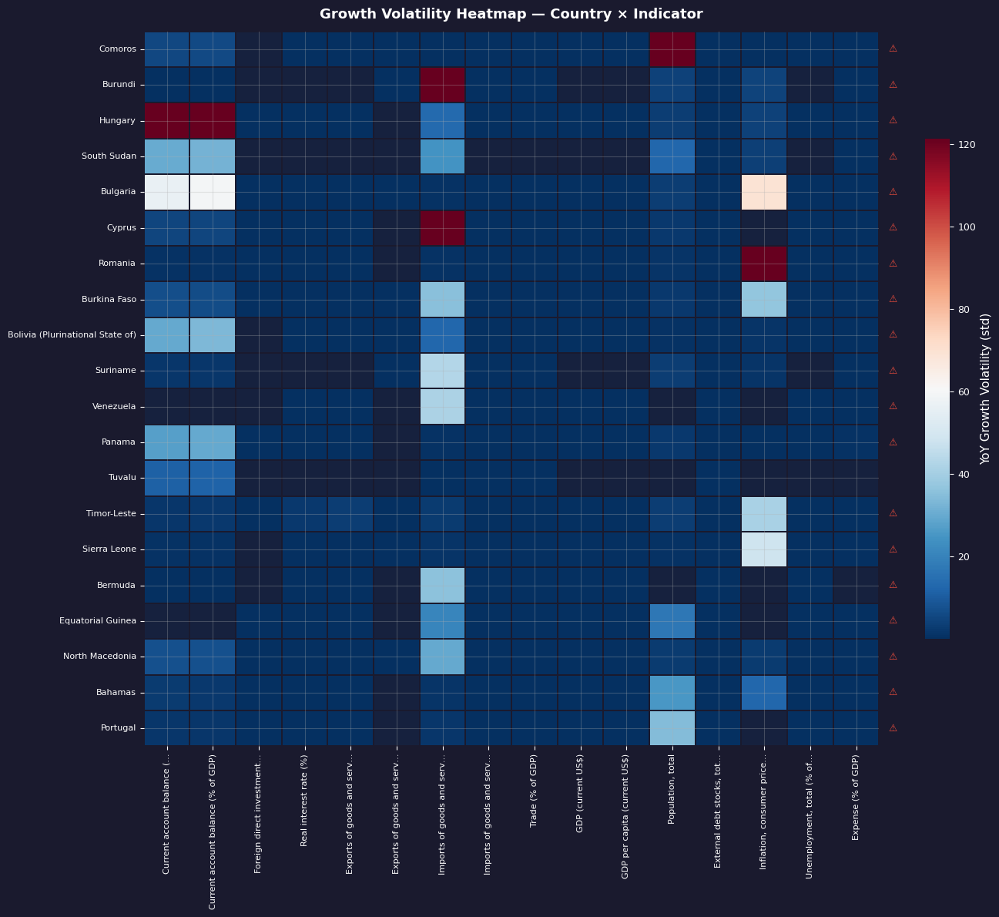

In [142]:
# Full heatmap (top 20 most volatile) 
plot_volatility_heatmap(volatility_df, countries=None, max_countries=20)

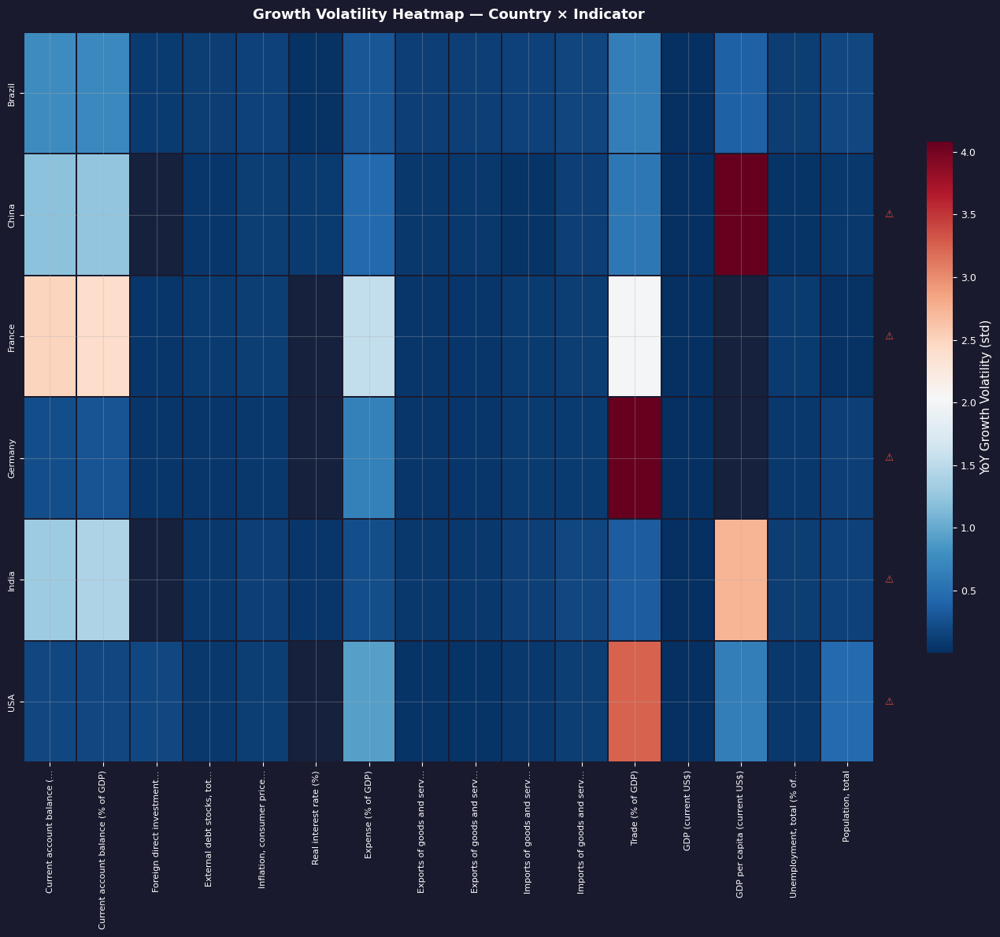

In [143]:
# Selected countries panel 
plot_volatility_heatmap(volatility_df, countries=countries)

**Volatility Insights**

- High volatility on a specific indicator (hot column) signals global instability in that economic dimension — likely a commodity-linked or externally driven indicator.
- A country with high volatility across all indicators (hot row, flagged ⚠) has structurally unstable economic dynamics — high exposure to shocks regardless of the dimension.
- Low CAGR + high volatility is the most fragile profile — a country
  growing slowly but erratically is structurally unstable and highly
  exposed to downside shocks.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 3. Growth Regimes
</div>

In [144]:
def compute_growth_regimes(df: pd.DataFrame) -> pd.DataFrame:
    """    Classify each observation into a growth regime using RELATIVE thresholds. Thresholds are quantile-based on the full YoY growth distribution.
        Regimes:
            dynamic       : yoy_growth >= Q60  (top 40% of growth distribution)
            moderate      : Q25 <= yoy_growth < Q60
            under_pressure: yoy_growth < Q25   (bottom 25% — contraction or very low)
        Aggregated per entity × indicator: share_dynamic, share_moderate, share_under_pressure, negative_phase_duration, high_phase_duration    """
    
    df_valid = df.dropna(subset=["yoy_growth"]).copy()

    # ── Relative thresholds ───────────────────────────────────────────────────
    q_high = df_valid["yoy_growth"].quantile(0.60)
    q_low  = df_valid["yoy_growth"].quantile(0.25)

    df_valid["regime"] = np.select(
                                    [df_valid["yoy_growth"] >= q_high, df_valid["yoy_growth"] >= q_low, df_valid["yoy_growth"] <  q_low,],
                                    ["dynamic", "moderate", "under_pressure"], default="no_data")

    df_valid["is_under_pressure"] = df_valid["yoy_growth"] <  q_low
    df_valid["is_dynamic"]        = df_valid["yoy_growth"] >= q_high

    neg_dur  = (df_valid.groupby(["entity_key", "indicator_code"])["is_under_pressure"].sum().reset_index(name="under_pressure_duration"))
    high_dur = (df_valid.groupby(["entity_key", "indicator_code"])["is_dynamic"].sum().reset_index(name="dynamic_phase_duration"))

    regimes_df = (df_valid.groupby(["entity_key", "country_name", "indicator_code", "indicator_name"])
                  .agg(
                        share_dynamic      = ("regime", lambda x: (x == "dynamic").mean()),
                        share_moderate     = ("regime", lambda x: (x == "moderate").mean()),
                        share_under_pressure=("regime",lambda x: (x == "under_pressure").mean()),
                      ).reset_index()
                 .merge(neg_dur,  on=["entity_key", "indicator_code"], how="left")
                 .merge(high_dur, on=["entity_key", "indicator_code"], how="left"))

    # Store thresholds as metadata
    regimes_df["q_high_threshold"] = q_high
    regimes_df["q_low_threshold"]  = q_low

    return regimes_df

In [145]:
regimes_df = compute_growth_regimes(df)

print(f"✅ Regimes computed : {len(regimes_df):,} entity × indicator combinations")

q_h = regimes_df["q_high_threshold"].iloc[0]
q_l = regimes_df["q_low_threshold"].iloc[0]
print(f"   Dynamic threshold     : YoY ≥ {q_h:+.2%}  (Q60 of full distribution)")
print(f"   Under-pressure thresh : YoY < {q_l:+.2%}  (Q25 of full distribution)")

regimes_df.sample()

✅ Regimes computed : 2,896 entity × indicator combinations
   Dynamic threshold     : YoY ≥ +3.51%  (Q60 of full distribution)
   Under-pressure thresh : YoY < -6.90%  (Q25 of full distribution)


,entity_key,country_name,indicator_code,indicator_name,share_dynamic,share_moderate,share_under_pressure,under_pressure_duration,dynamic_phase_duration,q_high_threshold,q_low_threshold
2756,290,Saint Vincent and the Grenadines,GC.XPN.TOTL.GD.ZS,Expense (% of GDP),0.5000,0.5000,0.0000,0,1,0.0351,-0.0690


In [146]:
def plot_regime_scatter(regimes_df: pd.DataFrame, indicator_name: str | None = None,
                        countries: list[str] | None = None, figsize: tuple = (12, 6)) -> None:
    """Scatter: share of under-pressure years (x) vs share of dynamic years (y).
       Four quadrants define structural growth profiles."""

    data = regimes_df.dropna(subset=["share_dynamic", "share_under_pressure"]).copy()
    if indicator_name: data = data[data["indicator_name"] == indicator_name]
    
    # ── Quadrant medians ──────────────────────────────────────────────────────
    if not(data.empty):
        x_med = data["share_under_pressure"].median()
        y_med = data["share_dynamic"].median()
    
    if countries:      data = data[data["country_name"].isin(countries)]
    if data.empty:
        print("No data for regime scatter.")
        return

    # ── Dynamic axis limits — zoom on populated zone ──────────────────────────
    x_max = max(data["share_under_pressure"].max() * 1.3, 0.5)
    y_max = min(data["share_dynamic"].max() * 1.15 + 0.05, 1.02)

    fig, ax = styled_figure(figsize=figsize)
    ax.set_title(f"Growth Regime Profile" f"{' — ' + indicator_name if indicator_name else ''}",
                 fontsize=13, color="white", pad=12)

    # ── Quadrant lines ────────────────────────────────────────────────────────
    ax.axvline(x_med, color=C["grey"], linewidth=2, linestyle="--", alpha=0.5)
    ax.axhline(y_med, color=C["grey"], linewidth=2, linestyle="--", alpha=0.5)

    # ── Quadrant labels ───────────────────────────────────────────────────────
    for tx, ty, label, color in [
        (0.01, 0.95, "Dynamic", C["green"]), (0.5, 0.95, "Volatile", C["orange"]),
        (0.01, 0.05, "Mature & Stable",C["blue"]), (0.5, 0.05, "Under Pressure", C["red"])]:
        ax.text(tx, ty, label, transform=ax.transAxes, fontsize=8.5, color=color, alpha=0.85,
                bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="none")) # C["ax_bg"]

    # ── Threshold note ────────────────────────────────────────────────────────
    if "q_high_threshold" in data.columns:
        q_h = data["q_high_threshold"].iloc[0]
        q_l = data["q_low_threshold"].iloc[0]
        ax.text(0.95, 0.05, f"Thresholds (relative):\nDynamic ≥ {q_h:+.1%}  |  Under pressure < {q_l:+.1%}",
                transform=ax.transAxes, ha="right", va="bottom", fontsize=7, color=C["grey"],
                bbox=dict(boxstyle="round,pad=0.3", facecolor=C["ax_bg"], edgecolor=C["spine"], alpha=0.7))

    # ── Scatter + labels with adjustText ─────────────────────────────────────
    palette = plt.cm.tab10.colors
    # texts   = []
    for i, (_, row) in enumerate(data.iterrows()):
        color = palette[i % 10]
        ax.scatter(row["share_under_pressure"], row["share_dynamic"], color=color, s=80, alpha=0.85, zorder=3,
                   edgecolors="white", linewidths=0.4)
        ax.text(row["share_under_pressure"] + 0.005, row["share_dynamic"], row["country_name"], fontsize=7.5, color=color, va="center")
        # t = ax.text(row["share_under_pressure"], row["share_dynamic"], row["country_name"], fontsize=8, color=color, va="center")
        # texts.append(t)

    # adjust_text(texts, ax=ax, expand_points=(1.5, 1.5), arrowprops=dict(arrowstyle="-", color="#666688", lw=0.6))

    ax.set_xlabel("Share of Under-Pressure Years", color="white")
    ax.set_ylabel("Share of Dynamic Years", color="white")
    ax.set_xlim(-0.02, x_max)
    ax.set_ylim(-0.02, y_max)

    plt.tight_layout()
    safe_ind = safe_indicator_name(indicator_name) if indicator_name else "all"
    save_figure(fig, f'../Figures/Indicators/I_3_regimes_scatter_{safe_ind}.png')
    plt.show()

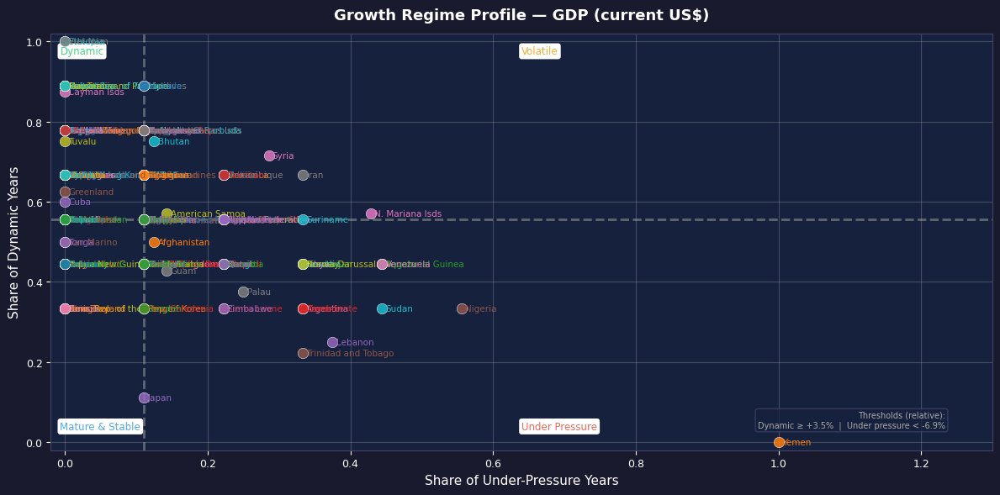

In [147]:
# Regime scatter
plot_regime_scatter(regimes_df, indicator_name=indicator, countries=None)

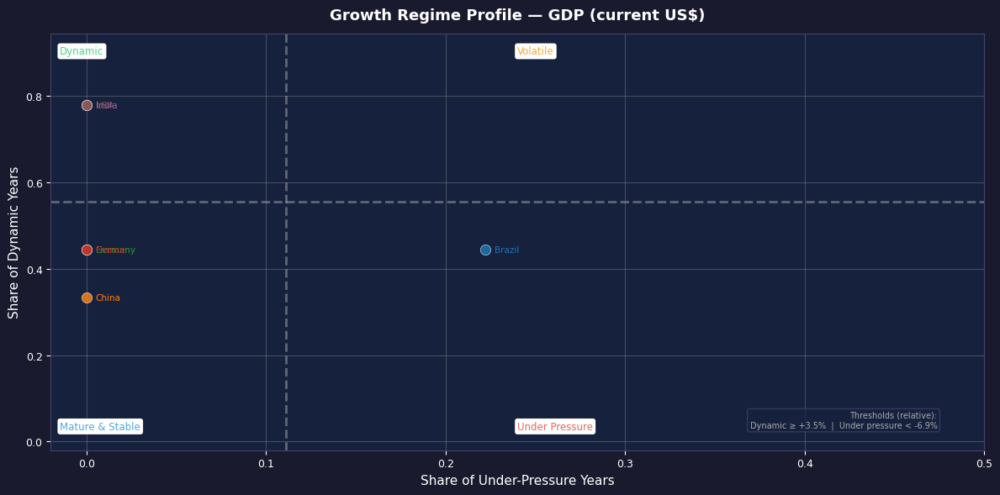

In [148]:
# Regime scatter — selected countries panel
plot_regime_scatter(regimes_df, indicator_name=indicator, countries=countries)

**Regime Insights**

- `Top-left quadrant` (low negative, high growth) — Growth leaders: sustained expansion with few contractions.
- `Top-right quadrant` (high negative, high growth) — Volatile growers: alternating booms and busts, high amplitude but no clear direction.
- `Bottom-left quadrant` (low negative, low high growth) — Stable slow: moderate and consistent growth without extremes.
- `Bottom-right quadrant` (high negative, low high growth) — Fragile: Chronic
  underperformers: frequent contractions without compensating high-growth years.
- The quadrant lines are set at the `medians of the filtered dataset` — half the countries fall above, half below each line. This makes the four quadrants balanced by construction.
- The threshold note in the corner shows the actual applied cutoffs — making the classification transparent and reproducible across different indicators.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 4. Shocks — Detection & Features
</div>

In [149]:
def detect_growth_shocks(df: pd.DataFrame, z_threshold: float = Z_THRESHOLD, min_years: int = MIN_YEARS) -> pd.DataFrame:
    """    Detect extreme YoY growth events using entity-level z-score.    Returns rows classified as positive_shock or negative_shock.    """
    
    df_valid = df.dropna(subset=["yoy_growth"]).copy()
    shocks   = []

    for (entity, ind_code), g in df_valid.groupby(["entity_key", "indicator_code"]):
        if len(g) < min_years:            continue
        mean, std = g["yoy_growth"].mean(), g["yoy_growth"].std()
        if std == 0 or np.isnan(std):            continue
        g = g.copy()
        g["z_growth"]   = (g["yoy_growth"] - mean) / std
        g["shock_type"] = np.where(g["z_growth"] >=  z_threshold, "positive_shock", np.where(g["z_growth"] <= -z_threshold, "negative_shock", "normal"))
        shocks.append(g[g["shock_type"] != "normal"])

    return pd.concat(shocks, ignore_index=True) if shocks else pd.DataFrame()

In [150]:
shock_df = detect_growth_shocks(df, z_threshold=Z_THRESHOLD)
print(f"✅ Shocks detected : {len(shock_df):,} events")
print(f"   Positive : {(shock_df['shock_type']=='positive_shock').sum()}")
print(f"   Negative : {(shock_df['shock_type']=='negative_shock').sum()}")
shock_df.sample()

✅ Shocks detected : 1,199 events
   Positive : 825
   Negative : 374


,entity_key,entity_type,country_code,wb_country_code,country_name,wb_country_name,country_iso3,wb_country_iso3,indicator_code,indicator_name,indicator_unit,year,value,yoy_growth,abs_growth,index_100,z_score,z_growth,shock_type
874,215,COUNTRY,608.0000,608.0000,Philippines,Philippines,PHL,PHL,GC.XPN.TOTL.GD.ZS,Expense (% of GDP),% of GDP,2020,19.5603,0.3210,4.7530,145.1412,-0.7779,2.3150,positive_shock


In [151]:
def compute_shock_features(shock_df: pd.DataFrame, df_base: pd.DataFrame) -> pd.DataFrame:
    """    Aggregate shock events into features per entity × indicator:  frequency, balance, intensity.  """
    
    if shock_df.empty:   return pd.DataFrame()
    n_years_df = (df_base.dropna(subset=["yoy_growth"]).groupby(["entity_key", "indicator_code"])["year"].count().reset_index(name="n_years"))

    feats = (shock_df.groupby(["entity_key", "country_name", "indicator_code", "indicator_name"]).agg(
                    shock_count       = ("shock_type", "count"), 
                    n_positive_shocks = ("shock_type", lambda x: (x == "positive_shock").sum()),
                    n_negative_shocks = ("shock_type", lambda x: (x == "negative_shock").sum()),
                    mean_abs_z        = ("z_growth",   lambda x: x.abs().mean()),
                    max_abs_z         = ("z_growth",   lambda x: x.abs().max())  )
        .reset_index().merge(n_years_df, on=["entity_key", "indicator_code"], how="left"))

    feats["shock_frequency"] = feats["shock_count"] / feats["n_years"]
    feats["shock_balance"]   = ((feats["n_positive_shocks"] - feats["n_negative_shocks"]) / feats["n_years"])

    return feats.drop(columns=["n_years"])

In [152]:
shock_features = compute_shock_features(shock_df, df)
print(f"✅ Shock features : {len(shock_features):,} entity × indicator combinations")
shock_features.sample()

✅ Shock features : 1,071 entity × indicator combinations


,entity_key,country_name,indicator_code,indicator_name,shock_count,n_positive_shocks,n_negative_shocks,mean_abs_z,max_abs_z,shock_frequency,shock_balance
882,245,San Marino,FP.CPI.TOTL.ZG,"Inflation, consumer prices (annual %)",1,0,1,2.5311,2.5311,0.1111,-0.1111


In [153]:
def plot_shock_timeline(df: pd.DataFrame, country_name: str, indicator_name: str, z_threshold: float = Z_THRESHOLD, figsize: tuple = (13, 4)) -> None:
    """   YoY growth timeline with shock events annotated for one entity × indicator    """
    
    data = df[(df["country_name"]   == country_name) & (df["indicator_name"] == indicator_name)].dropna(subset=["yoy_growth"]).sort_values("year")
    if data.empty:
        print(f"⚠️  No data for {country_name} — {indicator_name}")
        return

    mean, std = data["yoy_growth"].mean(), data["yoy_growth"].std()
    data      = data.copy()
    data["z_growth"] = (data["yoy_growth"] - mean) / std
    shocks    = data[data["z_growth"].abs() >= z_threshold]

    fig, ax = styled_figure(figsize=figsize)
    ax.plot(data["year"], data["yoy_growth"] * 100, color=C["blue"], linewidth=2.2, marker="o", markersize=4, zorder=2)
    ax.fill_between(data["year"], data["yoy_growth"] * 100, 0, where=data["yoy_growth"] >= 0, alpha=0.1, color=C["green"])
    ax.fill_between(data["year"], data["yoy_growth"] * 100, 0, where=data["yoy_growth"] < 0,  alpha=0.1, color=C["red"])
    ax.axhline(0, color=C["grey"], linewidth=1)

    if shocks.empty: ax.text(0.5, 0.92, "No significant shocks detected", transform=ax.transAxes, ha="center", fontsize=10, color=C["grey"])
    else:
        for _, row in shocks.iterrows():
            color = C["green"] if row["z_growth"] > 0 else C["red"]
            ax.scatter(row["year"], row["yoy_growth"] * 100, color=color, s=90, zorder=5)
            ax.annotate(f"{row['yoy_growth']:+.1%}", xy=(row["year"], row["yoy_growth"] * 100), xytext=(0, 14 if row["yoy_growth"] >= 0 else -18),
                        textcoords="offset points",  ha="center", fontsize=8.5, color=color, fontweight="bold",
                        arrowprops=dict(arrowstyle="->", color=color, lw=0.8))

    ax.set_title(f"Growth Shocks — {country_name} | {indicator_name}", fontsize=13, color="white", pad=12)
    ax.set_xlabel("Year", color="white")
    ax.set_ylabel("YoY Growth (%)", color="white")
    ax.set_xticks(data["year"])
    ax.tick_params(axis="x", rotation=45)

    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/I_4_shock_timeline_{country_name}_{ind_name}.png')
    plt.show()

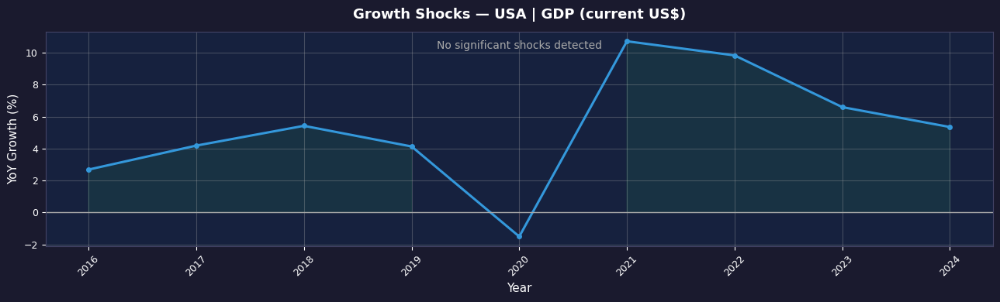

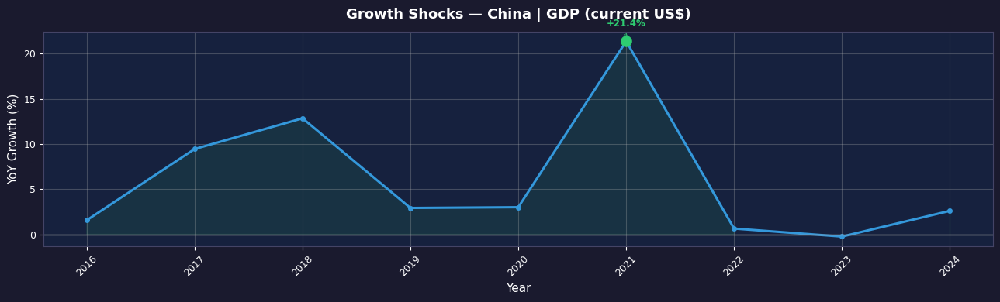

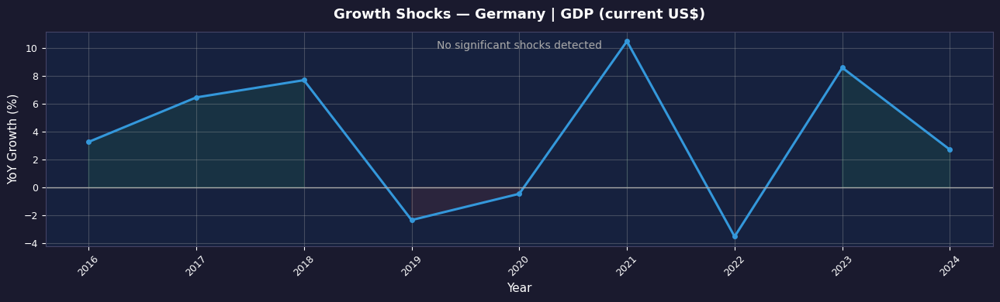

In [154]:
# Shock timeline for selected countries 
for c in countries[:3]:    plot_shock_timeline(df, c, indicator)

**Shock Insights**

- Shock detection is entity-relative (z-score within each series), not absolute — a 3% drop is a shock for a stable economy but normal for a volatile one.
- `shock_balance` > 0 means positive shocks outweigh negative ones — an asymmetric upside profile; < 0 indicates chronic downside pressure.
- `mean_abs_z` measures average shock intensity — a high value combined with
  low frequency means rare but violent shocks; high frequency + low intensity
  means chronic instability. Both are risk signals but with different profiles.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 5. Growth Score
</div>

In [155]:
def compute_growth_score(cagr_df: pd.DataFrame, volatility_df: pd.DataFrame, regimes_df: pd.DataFrame, shock_features:pd.DataFrame, 
                         weights: dict | None = None) -> pd.DataFrame:
    """    Composite growth score per entity × indicator
    Score = w_cagr × z_cagr  - w_vol  × z_volatility - w_neg  × z_share_under_pressure - w_shock_freq × z_shock_frequency 	
    Higher score = better growth profile (high CAGR, low volatility, few negative phases)    """
    
    if weights is None:  weights = {"cagr" : 0.5, "volatility" : 0.2, "share_under_pressure" : 0.15, "shock_frequency" : 0.15}

    merge_keys = ["entity_key", "country_name", "indicator_code", "indicator_name"]
    df_score = (
        cagr_df
        .merge(volatility_df[[*merge_keys, "volatility"]], on=merge_keys, how="left")
        .merge(regimes_df[[ *merge_keys, "share_dynamic", "share_moderate", "share_under_pressure",
                           "under_pressure_duration", "dynamic_phase_duration"]], on=merge_keys, how="left")
        .merge(
            shock_features[[*merge_keys, "shock_frequency", "shock_balance", "mean_abs_z", "max_abs_z", "n_positive_shocks", "n_negative_shocks"]],
            on=merge_keys, how="left"))
    
    df_score["asymmetry_index"] = (df_score["n_positive_shocks"].fillna(0) - df_score["n_negative_shocks"].fillna(0))  
    
    shock_cols = ["shock_count", "shock_frequency", "shock_balance", "mean_abs_z", "max_abs_z", "n_positive_shocks", "n_negative_shocks"]
    for col in shock_cols:
        if col in df_score.columns: df_score[col] = df_score[col].fillna(0)
    
    # Z-normalize each component
    for col in ["cagr", "volatility", "share_under_pressure", "shock_frequency"]:
        mu  = df_score[col].mean()
        std = df_score[col].std()
        df_score[f"z_{col}"] = (df_score[col] - mu) / std if std > 0 else 0

    df_score["growth_score"] = (
                                  weights["cagr"]                *  df_score["z_cagr"]
                                - weights["volatility"]          *  df_score["z_volatility"]
                                - weights["share_under_pressure"]*  df_score["z_share_under_pressure"]
                                - weights["shock_frequency"]     *  df_score["z_shock_frequency"]
                               )       
    return df_score

In [156]:
growth_df = compute_growth_score(cagr_df, volatility_df, regimes_df, shock_features)
print(f"✅ Growth score computed : {len(growth_df):,} entity × indicator combinations")
growth_df.sample()

✅ Growth score computed : 2,909 entity × indicator combinations


,entity_key,entity_type,country_name,indicator_code,indicator_name,cagr,volatility,share_dynamic,share_moderate,share_under_pressure,...,mean_abs_z,max_abs_z,n_positive_shocks,n_negative_shocks,asymmetry_index,z_cagr,z_volatility,z_share_under_pressure,z_shock_frequency,growth_score
677,68,COUNTRY,Cyprus,GC.XPN.TOTL.GD.ZS,Expense (% of GDP),-0.0101,0.0912,0.3750,0.3750,0.2500,...,0.0000,0.0000,0.0000,0.0000,0.0000,-0.3426,-0.0824,-0.0911,-0.7612,-0.0270


In [157]:
def plot_growth_score_ranking(growth_df: pd.DataFrame, indicator_name: str, countries: list[str] | None = None, top_n: int= 10,
                              figsize: tuple= (13, 6)) -> None:
    """  Single horizontal bar chart — countries ranked by growth score. 
         If countries provided: shows only those, sorted high to low. If countries is None: shows top_n globally.    """

    data = growth_df[(growth_df["indicator_name"] == indicator_name) & (growth_df["entity_type"] == "COUNTRY")].dropna(subset=["growth_score"])
    if countries:        
        data = data[data["country_name"].isin(countries)]
        title = f"Growth Score — {indicator_name} | Selected Countries"
    else:
        data  = data.nlargest(top_n, "growth_score")
        title = f"Growth Score Ranking — {indicator_name} | Top {top_n}"

    data  = data.sort_values("growth_score")
    bar_colors = [C["green"] if v >= 0 else C["red"] for v in data["growth_score"]]

    fig, ax = styled_figure(figsize=figsize)
    ax.set_title(title, fontsize=13, color="white", pad=12)

    bars = ax.barh(data["country_name"], data["growth_score"], color=bar_colors, edgecolor="none", height=0.65)
    ax.axvline(0, color=C["grey"], linewidth=1)
    ax.axvline(data["growth_score"].mean(), color=C["orange"], linewidth=1.4, linestyle="--", label=f"Mean = {data['growth_score'].mean():+.2f}")
    for bar, val in zip(bars, data["growth_score"]):
        offset = 0.01 if val >= 0 else -0.01
        ax.text(val + offset, bar.get_y() + bar.get_height() / 2, f"{val:+.2f}", va="center", color="white", fontsize=8.5)

    ax.set_xlabel("Growth Score", color="white")
    add_legend(ax)
    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/I_5_growth_score_ranking_{ind_name}.png')
    plt.show()

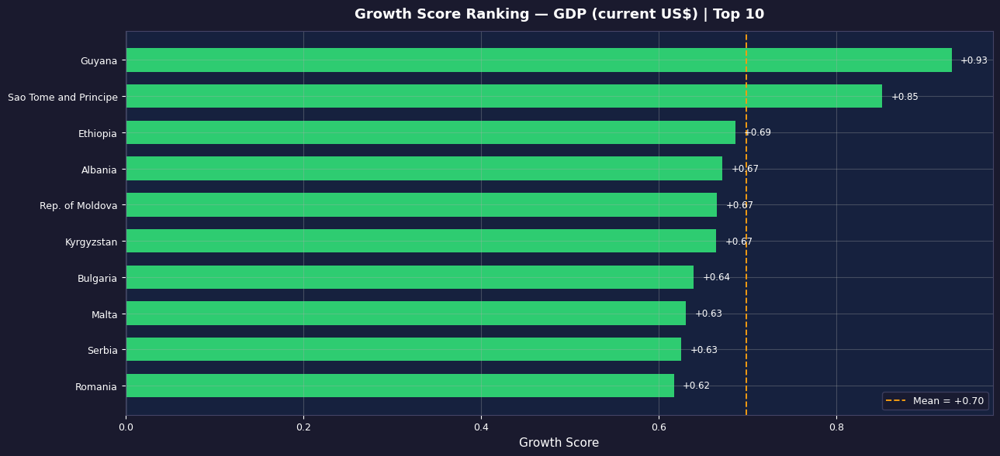

In [158]:
plot_growth_score_ranking(growth_df, indicator, countries=None, top_n=10)

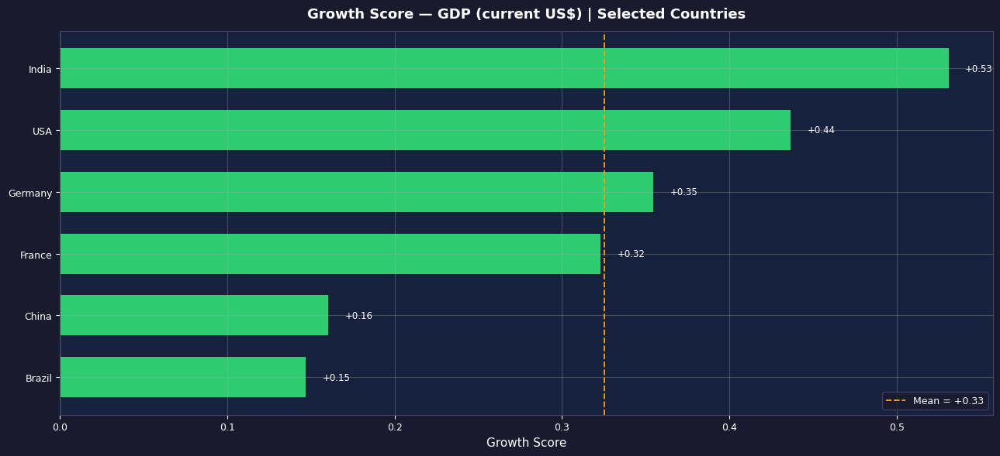

In [159]:
plot_growth_score_ranking(growth_df, indicator, countries=countries, top_n=len(countries))

In [160]:
def plot_growth_radar(growth_df: pd.DataFrame, entity_name: str, indicator_name: str, figsize:tuple = (6, 6)) -> None:
    """Radar chart for growth profile of one entity × indicator."""
    
    row = growth_df[(growth_df["country_name"] == entity_name) & (growth_df["indicator_name"] == indicator_name)]
    if row.empty:
        print(f"⚠️  No data for {entity_name} — {indicator_name}")
        return
    row = row.iloc[0]
    
    metrics = {
        "CAGR"         : row.get("cagr", 0) or 0,
        "Volatility"   : -(row.get("volatility", 0) or 0),   # inverted: lower = better
        "High Growth"  : row.get("share_dynamic", 0) or 0,
        "Low Negative" : 1 - (row.get("share_under_pressure", 0) or 0),  # inverted
        "Shock Balance": row.get("shock_balance", 0) or 0,
    }

    # Normalize to [0, 1]
    vals = np.array(list(metrics.values()), dtype=float)
    v_min, v_max = vals.min(), vals.max()
    vals_norm = (vals - v_min) / (v_max - v_min + 1e-9)

    labels = list(metrics.keys())
    angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False)
    vals_plot  = np.append(vals_norm, vals_norm[0])
    angles_plt = np.append(angles, angles[0])

    fig, ax = plt.subplots(figsize=figsize, subplot_kw=dict(polar=True))
    fig.patch.set_facecolor(C["bg"])
    ax.set_facecolor(C["ax_bg"])

    ax.plot(angles_plt, vals_plot, color=C["blue"], linewidth=2)
    ax.fill(angles_plt, vals_plot, color=C["blue"], alpha=0.25)
    ax.set_thetagrids(np.degrees(angles), labels, fontsize=10, color="white")
    ax.tick_params(colors="white")
    ax.set_title(f"{entity_name}\n{indicator_name}", fontsize=10, color="white", pad=20)
    ax.spines["polar"].set_edgecolor(C["spine"])
    ax.set_facecolor(C["ax_bg"])

    plt.tight_layout()
    save_figure(fig, f'../Figures/indicators/I_5_growth_score_radar_{entity_name}_{ind_name}.png')
    plt.show()

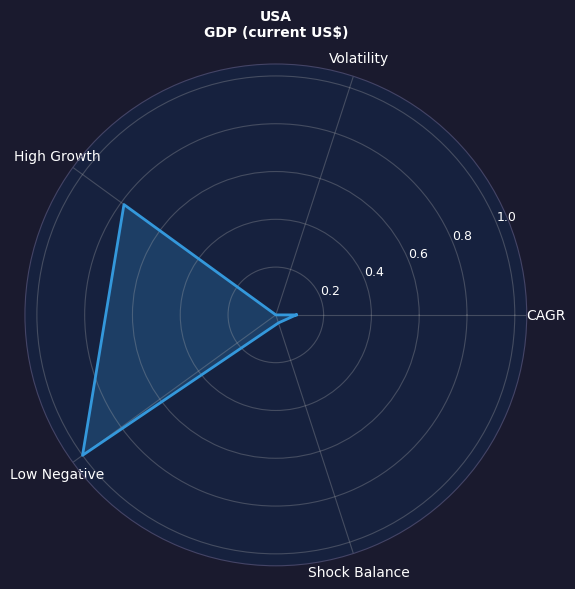

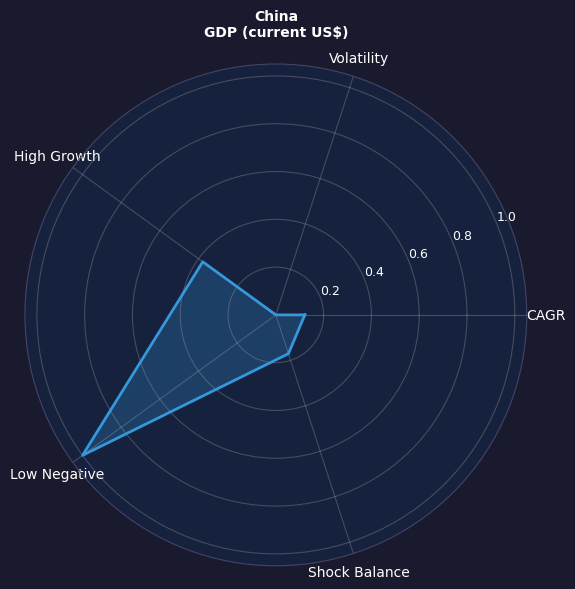

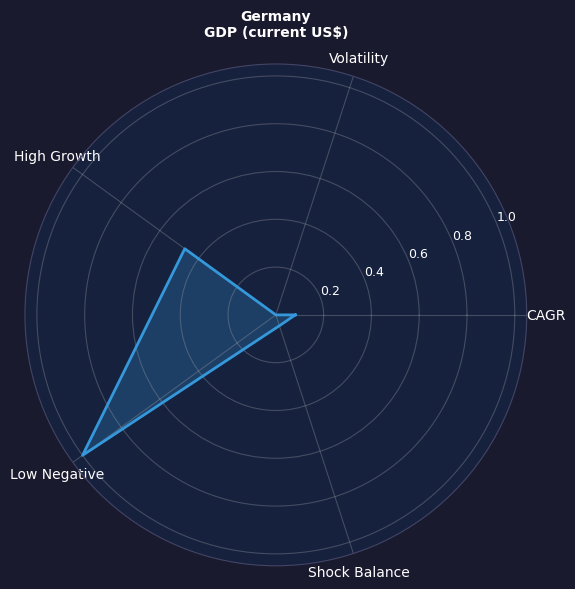

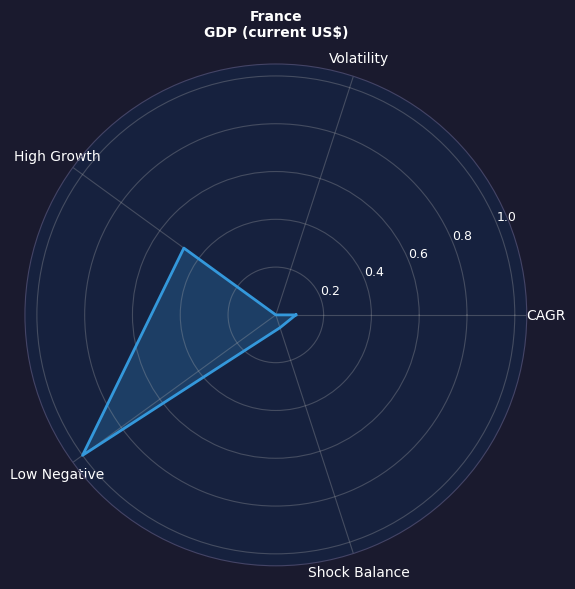

In [161]:
# Radar charts for selected countries
for c in countries[:4]:    plot_growth_radar(growth_df, c, indicator)

**Growth Score — Feature Selection & Weighting Rationale**

The growth score is a **balanced composite** designed to capture both
growth performance and structural resilience — neither purely rewarding
high growth nor purely penalizing instability.

**Features and their role:**

| Feature | Weight | Direction | Rationale |
|---|---|---|---|
| `cagr` | 0.50 | ✅ Reward | Primary growth criterion — compound rate over full period |
| `volatility` | 0.20 | ❌ Penalize | High variance reduces reliability of growth |
| `share_under_pressure` | 0.15 | ❌ Penalize | Share of years in declining/under-pressure regime |
| `shock_frequency` | 0.15 | ❌ Penalize | Exposure to extreme growth events |

**Weighting philosophy — balanced (50/50):**

CAGR captures the reward side (0.50).
The three penalty features collectively capture the risk side (0.50).
This equal split reflects a deliberate choice: **growth matters as much
as stability**. A country with high CAGR but extreme volatility and
frequent shocks scores no better than a moderate but structurally
stable economy.

This is distinct from a pure **performance** score (CAGR-dominant,
used in Section N) or a pure **resilience** score (penalty-dominant).
The growth score here serves as a **structural clustering feature** —
its role is to differentiate country growth profiles in the clustering
space (Section L), not to rank countries definitively.

> `shock_frequency` and `volatility` are complementary:
> volatility measures amplitude, shock_frequency measures regularity
> of extreme events. A country can have moderate average volatility
> but frequent extreme years — both dimensions are captured.

Radar charts decompose the score into its dimensions — useful for identifying which component drives a country's ranking (e.g., strong CAGR but penalized by high volatility).

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 6. Growth Feature Dataset — Output
</div>

The `growth_df` dataframe aggregates all structural growth features per entity × indicator.
It is the primary input for **Section J — Clustering** and contributes to **Section O — Scoring**.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 6.1 Summary
</div>

In [162]:
print("═" * 55)
print("  GROWTH FEATURE DATASET — SUMMARY")
print("═" * 55)
print(f"  📐 Shape          : {growth_df.shape}")
print(f"  🌍 Entities       : {growth_df['country_name'].nunique()}")
print(f"  📊 Indicators     : {growth_df['indicator_name'].nunique()}")
print(f"  ⚠️  Missing (cagr) : {growth_df['cagr'].isna().sum()}")
print("═" * 55)
print("  FEATURES")
print("  cagr            │ volatility      │ growth_score")
print("  share_dynamic      │ share_under_pressure  │ under_pressure_duration")
print("  shock_frequency │ shock_balance   │ mean_abs_z")
print("  asymmetry_index │ z_cagr          │ z_volatility")
print("═" * 55)
growth_df.sample()

═══════════════════════════════════════════════════════
  GROWTH FEATURE DATASET — SUMMARY
═══════════════════════════════════════════════════════
  📐 Shape          : (2909, 24)
  🌍 Entities       : 210
  📊 Indicators     : 16
  ⚠️  Missing (cagr) : 87
═══════════════════════════════════════════════════════
  FEATURES
  cagr            │ volatility      │ growth_score
  share_dynamic      │ share_under_pressure  │ under_pressure_duration
  shock_frequency │ shock_balance   │ mean_abs_z
  asymmetry_index │ z_cagr          │ z_volatility
═══════════════════════════════════════════════════════


,entity_key,entity_type,country_name,indicator_code,indicator_name,cagr,volatility,share_dynamic,share_moderate,share_under_pressure,...,mean_abs_z,max_abs_z,n_positive_shocks,n_negative_shocks,asymmetry_index,z_cagr,z_volatility,z_share_under_pressure,z_shock_frequency,growth_score
411,43,COUNTRY,Bhutan,BN.CAB.XOKA.CD,"Current account balance (BoP, current US$)",-0.0458,0.5655,0.4444,0.0000,0.5556,...,2.5055,2.5055,1.0000,0.0000,1.0000,-0.6933,-0.0592,1.1867,1.2744,-0.7040


In [163]:
# Feature distribution overview 
feat_cols = ["cagr", "volatility", "share_dynamic", "share_under_pressure", "shock_frequency", "shock_balance", "growth_score"]
growth_df[feat_cols].describe().round(4).style.background_gradient(cmap="Blues", axis=0)

,cagr,volatility,share_dynamic,share_under_pressure,shock_frequency,shock_balance,growth_score
count,2822.000000,2800.000000,2896.000000,2896.000000,2909.000000,2909.000000,2800.000000
mean,0.024700,1.776000,0.406500,0.271800,0.041600,0.014500,-0.004500
std,0.101600,20.451200,0.217300,0.239100,0.054600,0.067100,0.590700
min,-0.537800,0.000000,0.000000,0.000000,0.000000,-0.142900,-8.556800
25%,-0.007400,0.076500,0.250000,0.111100,0.000000,0.000000,-0.208900
50%,0.018600,0.132200,0.444400,0.222200,0.000000,0.000000,0.079900
75%,0.054100,0.488300,0.555600,0.444400,0.111100,0.000000,0.293300
max,1.018500,945.006700,1.000000,1.000000,0.166700,0.166700,4.232500


**Dataset Insights**

- `growth_df` is a static aggregated dataset — one row per entity × indicator, no temporal dimension.
- It captures the full structural growth profile: long-term direction (CAGR), consistency (volatility), regime distribution, and shock exposure.
- This dataset feeds directly into Section J (Clustering) for unsupervised
  country profiling and Section O (Scoring) for composite economic assessment.
- One design choice : growth_df includes World and regional aggregates —
  they are excluded from clustering (J) but retained for reference in scoring (O).

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 6.2 Save Table
</div>

In [164]:
growth_df.to_csv("../Analysis_files/Indicators/growth_df.csv", index=False)

<div style="background-color: #eaf2f8; padding-left: 20px; border: 1px solid; border-radius: 5px;">

# J. Corrélations & Structure
</div>

J.1 — Cross-country correlation
      "Do countries move together on this indicator?"
      → Identifies synchronized clusters of countries
      ↓

J.2 — Inter-indicator correlation
      "Do indicators move together across countries?"
      → Identifies which dimensions are structurally linked
      ↓

J.3 — PCA
      "What are the underlying dimensions that explain
       the structure revealed by J.1 and J.2?"
      → Synthesizes both into latent economic axes

This section examines the relational structure of the data across three levels:

| Sub-section | Question answered |
|---|---|
| J1 — Cross-country correlation | Do countries move together on a given indicator? |
| J2 — Inter-indicator correlation | Do indicators correlate with each other across countries? |
| J3 — PCA | What are the main structural dimensions underlying all indicators? |

In [168]:
# Parameters
indicator  = "GDP (current US$)"
unit = df.loc[df["indicator_name"] == indicator, "indicator_unit"].dropna().iloc[0]
countries  = ["USA", "China", "Germany", "France", "India", "Brazil", "Japan", "Canada"]

# Indicators to use for inter-indicator correlation and PCA
indicators_for_analysis = [
    "GDP per capita (current US$)",
    "Inflation, consumer prices (annual %)",
    "Unemployment, total (% of total labor force) (modeled ILO estimate)",
    "Current account balance (% of GDP)",
    "Trade (% of GDP)",
    "Real interest rate (%)",
    "Expense (% of GDP)",
]

MIN_YEARS = 4    # minimum years of data for correlation
CORR_METHOD = "pearson"   # pearson | spearman | kendall

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 1. Cross-Country Correlation
</div>

For a given indicator, we measure how synchronized countries are in their evolution over time.
High correlation between two countries means they tend to grow and contract together — a signal of structural linkage or common exposure.

In [169]:
# Metric descriptions 
CORR_METRIC_DESCRIPTIONS = {
    "value": ("Absolute value trajectory", "Measures whether two countries follow the same temporal trend in absolute terms.\n",
              "⚠️  Warning: two series with a common upward trend will always correlate highly\n"
              "   regardless of any structural link — spurious trend correlation."),
    "yoy_growth": ("YoY growth cycle synchronization", "Measures whether two countries experience growth and contraction in the same years.\n",
                   "✅ Eliminates common trend bias — most analytically robust metric for structural linkage."),
    "index_100": ("Cumulative dynamics from same base (2015=100)", "Measures whether two countries progressed at similar speeds from their 2015 level.\n",
                  "Eliminates absolute level differences but retains the trend component.\n"
                  "Intermediate between value (trend) and yoy_growth (cycle).")
                           }

In [170]:
def compute_cross_country_corr(df: pd.DataFrame, indicator_name: str, countries: list[str] | None = None, min_years: int = MIN_YEARS,
                               method:str  = CORR_METHOD,  metric: str = "yoy_growth") -> pd.DataFrame:
    """    Compute pairwise country correlation on a given indicator. Returns a correlation matrix (countries × countries).
            metric options:
                        'value'      — absolute level trajectory (spurious trend risk)
                        'yoy_growth' — cycle synchronization (recommended)
                        'index_100'  — cumulative dynamics from base 100      """
    
    if metric not in CORR_METRIC_DESCRIPTIONS: raise ValueError(f"metric must be one of {list(CORR_METRIC_DESCRIPTIONS.keys())}")

    data = df[(df["entity_type"]   == "COUNTRY") & (df["indicator_name"] == indicator_name)].dropna(subset=[metric])
    pivot = data.pivot_table(index="year", columns="country_name", values=metric, aggfunc="mean")

    # Keep only countries with enough data
    valid = pivot.columns[pivot.notna().sum() >= min_years]
    pivot = pivot[valid]

    # Filter to selected countries if provided
    if countries:
        available = [c for c in countries if c in pivot.columns]
        if not available:
            print(f"⚠️  None of the selected countries have data for metric='{metric}'")
            return pd.DataFrame()
        pivot = pivot[available]

    return pivot.corr(method=method)

In [171]:
def plot_cross_country_corr(corr_matrix: pd.DataFrame, indicator_name: str, metric: str = "yoy_growth", method: str = CORR_METHOD,
                            figsize: tuple = (11, 9)) -> None:
    """    Lower-triangle heatmap of cross-country correlation.    Displays metric description and interpretation note.    """
    
    label, measure, description = CORR_METRIC_DESCRIPTIONS.get(metric, (metric, ""))

    # Print interpretation note before the chart
    print(f"📐 Metric       : {metric} — {label}")
    print(f"📖 Measures     : {label} {measure} {description}")
    print()

    fig, ax = plt.subplots(figsize=figsize)
    fig.patch.set_facecolor(C["bg"])
    ax.set_facecolor(C["ax_bg"])
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

    sns.heatmap(corr_matrix, mask=mask, ax=ax, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 8, "color": "white"}, 
                linewidths=0.4, linecolor=C["bg"], square=True, cbar_kws={"shrink": 0.7, "label": f"{method.capitalize()} correlation"})
    
    ax.set_title(f"Cross-Country Correlation — {indicator_name}\n" f"Metric: {metric} | {method.capitalize()}", fontsize=13, color="white", pad=12)

    ax.set_title(
        f"Cross-Country Correlation — {indicator_name} \n" 
        f" Method : {method.capitalize()}    |   Metric: {metric} \n" 
        f"{label} \n" 
        f"{measure} \n",
        fontsize=13, color="white", pad=12)
    ax.tick_params(colors="white", labelsize=8)
    ax.set_xlabel("", color="white")
    ax.set_ylabel("", color="white")

    cbar = ax.collections[0].colorbar
    cbar.ax.yaxis.label.set_color("white")
    cbar.ax.tick_params(colors="white")

    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/J_1_{safe_indicator_name(indicator_name)}_cross_country_correlation_{metric}.png')
    plt.show()

📐 Metric       : value — Absolute value trajectory
📖 Measures     : Absolute value trajectory Measures whether two countries follow the same temporal trend in absolute terms.
 ⚠️  Warning: two series with a common upward trend will always correlate highly
   regardless of any structural link — spurious trend correlation.



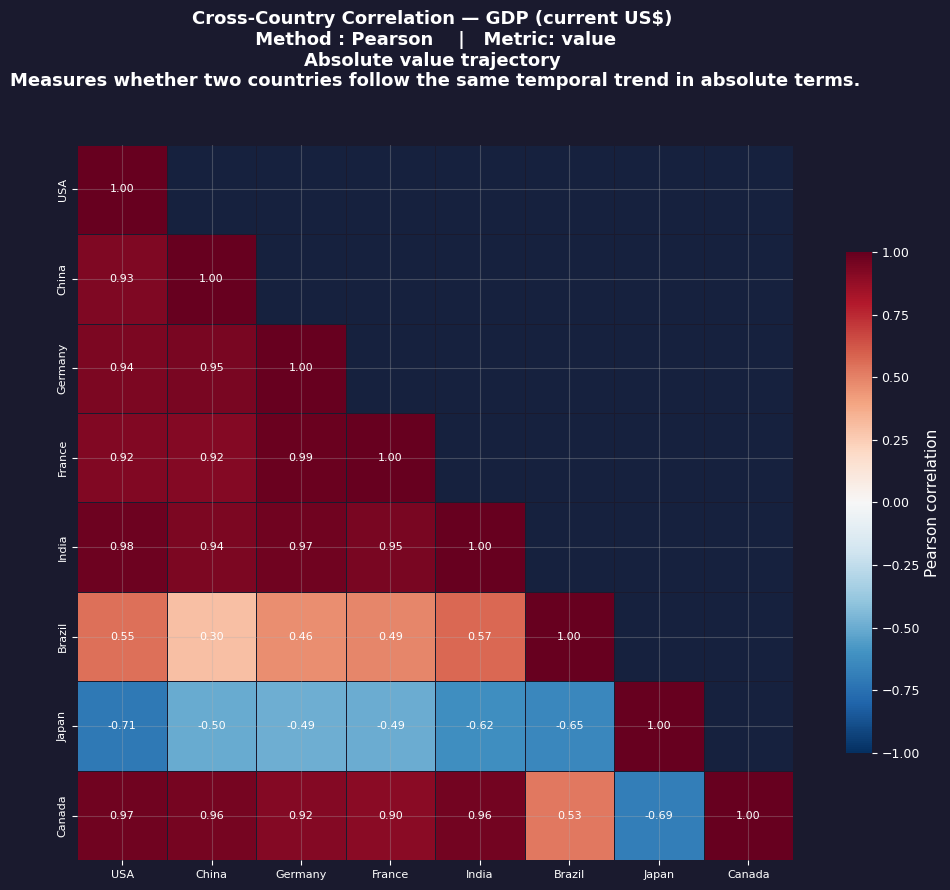

In [172]:
# Value — absolute trajectory  
corr_val = compute_cross_country_corr(df, indicator, countries, metric="value")
plot_cross_country_corr(corr_val, indicator, metric="value")

📐 Metric       : yoy_growth — YoY growth cycle synchronization
📖 Measures     : YoY growth cycle synchronization Measures whether two countries experience growth and contraction in the same years.
 ✅ Eliminates common trend bias — most analytically robust metric for structural linkage.



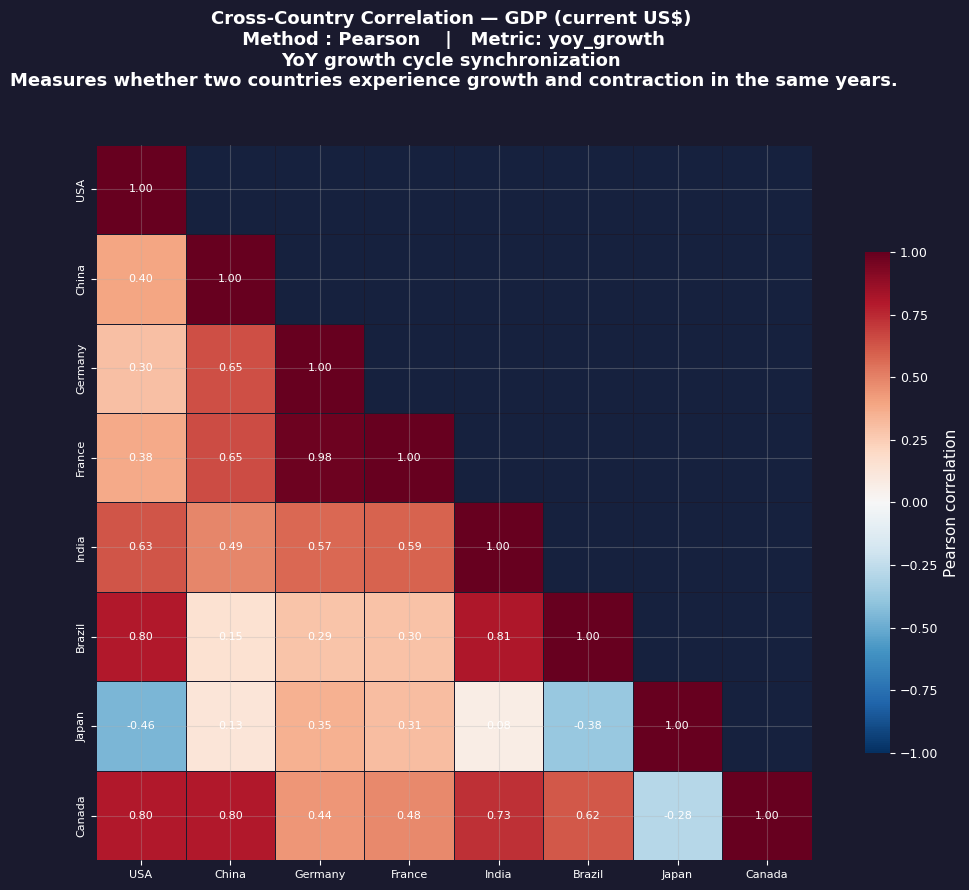

In [173]:
# YoY growth — cycle synchronization 
corr_yoy = compute_cross_country_corr(df, indicator, countries, metric="yoy_growth")
plot_cross_country_corr(corr_yoy, indicator, metric="yoy_growth")

📐 Metric       : index_100 — Cumulative dynamics from same base (2015=100)
📖 Measures     : Cumulative dynamics from same base (2015=100) Measures whether two countries progressed at similar speeds from their 2015 level.
 Eliminates absolute level differences but retains the trend component.
Intermediate between value (trend) and yoy_growth (cycle).



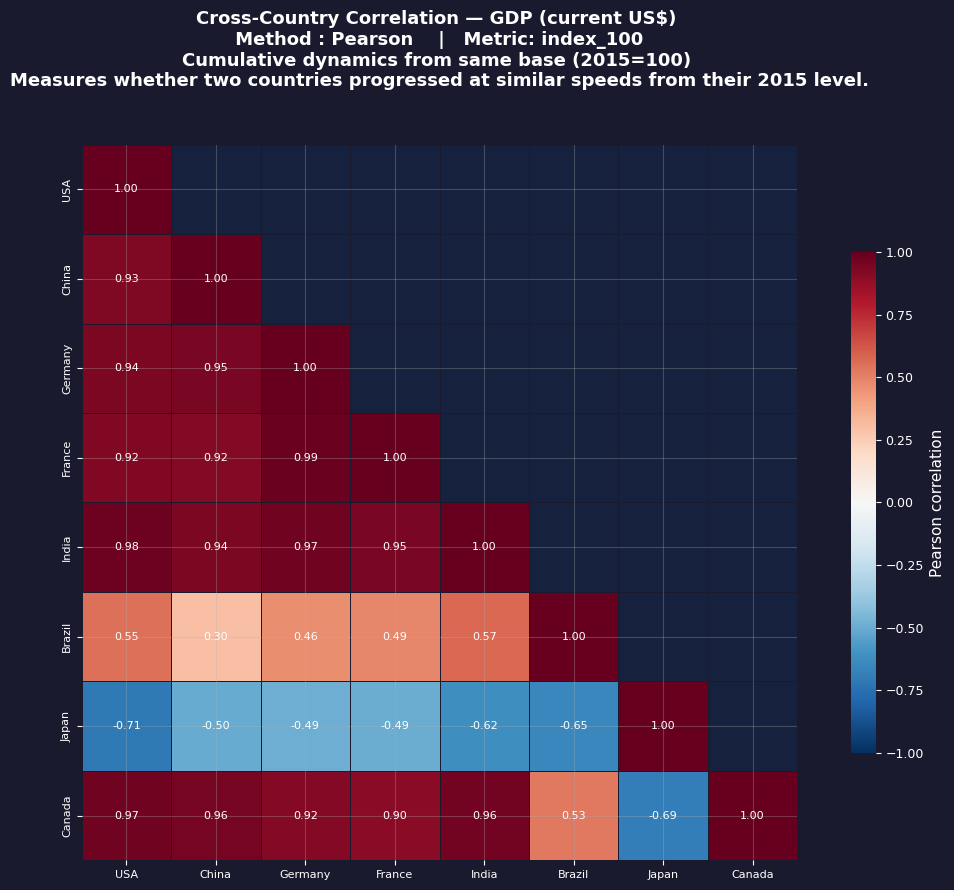

In [174]:
# Index 100 — cumulative dynamics
corr_idx = compute_cross_country_corr(df, indicator, countries, metric="index_100")
plot_cross_country_corr(corr_idx, indicator, metric="index_100")

In [175]:
def get_top_corr_pairs(corr_matrix: pd.DataFrame, n: int = 10) -> pd.DataFrame:
    """   Extract top N unique pairs sorted by absolute correlation   """
    
    corr_matrix.index.name = "Country_1"
    pairs = corr_matrix.unstack().reset_index()
    pairs.columns = ["Country_1", "Country_2", "correlation"]
    pairs = pairs[pairs["Country_1"] != pairs["Country_2"]]
    pairs["pair"] = pairs.apply(lambda r: tuple(sorted([r["Country_1"], r["Country_2"]])), axis=1)
    pairs = pairs.drop_duplicates(subset="pair").drop(columns="pair")
    pairs["abs_corr"] = pairs["correlation"].abs()
    
    return pairs.nlargest(n, "abs_corr").reset_index(drop=True)

In [176]:
# Top correlated pairs — on yoy_growth 
top_pairs = get_top_corr_pairs(corr_yoy, n=8)
print("Top correlated pairs (yoy_growth):")
top_pairs.style.format({"correlation": "{:+.3f}", "abs_corr": "{:.3f}"}).background_gradient(subset=["abs_corr"], cmap="Blues")

Top correlated pairs (yoy_growth):


,Country_1,Country_2,correlation,abs_corr
0,Germany,France,+0.978,0.978
1,India,Brazil,+0.809,0.809
2,China,Canada,+0.802,0.802
3,USA,Canada,+0.802,0.802
4,USA,Brazil,+0.802,0.802
5,India,Canada,+0.730,0.730
6,China,France,+0.649,0.649
7,China,Germany,+0.646,0.646


In [177]:
def plot_rolling_correlation(df: pd.DataFrame, indicator_name: str, country_pairs: list[tuple], metric: str = "yoy_growth", window: int = 4,
                             figsize: tuple = (14, 5)) -> None:
    """    Rolling correlation over time for selected country pairs.     """
    
    label, _, _ = CORR_METRIC_DESCRIPTIONS.get(metric, (metric, ""))

    data = df[(df["entity_type"]   == "COUNTRY") & (df["indicator_name"] == indicator_name)].dropna(subset=[metric])
    pivot = data.pivot_table(index="year", columns="country_name", values=metric, aggfunc="mean")

    fig, ax = styled_figure(figsize=figsize)
    ax.set_title(f"Rolling Correlation ({window}y) — {indicator_name}\n" f"Metric: {metric} — {label}", fontsize=13, color="white", pad=12)

    palette = plt.cm.tab10.colors
    for i, (c1, c2) in enumerate(country_pairs):
        if c1 not in pivot.columns or c2 not in pivot.columns:
            print(f"⚠️  Missing data for pair ({c1}, {c2})")
            continue
        roll_corr = pivot[c1].rolling(window).corr(pivot[c2])
        ax.plot(roll_corr.index, roll_corr.values, color=palette[i % 10], linewidth=2, marker="o", markersize=4, label=f"{c1} — {c2}")

    ax.axhline(0,    color=C["grey"],  linewidth=1,   linestyle="--")
    ax.axhline(0.7,  color=C["green"], linewidth=0.8, linestyle=":", alpha=0.6, label="Strong positive (0.7)")
    ax.axhline(-0.7, color=C["red"],   linewidth=0.8, linestyle=":", alpha=0.6, label="Strong negative (-0.7)")

    ax.set_ylim(-1.1, 1.1)
    ax.set_xlabel("Year", color="white")
    ax.set_ylabel("Rolling Correlation", color="white")
    add_legend(ax, fontsize=8)
    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/J_1_{safe_indicator_name(indicator_name)}_global_average_trend_{metric}.png')
    plt.show()

In [178]:
pairs_to_plot = [("USA", "Japan"),  ("Germany", "France"), ("India", "Brazil")]

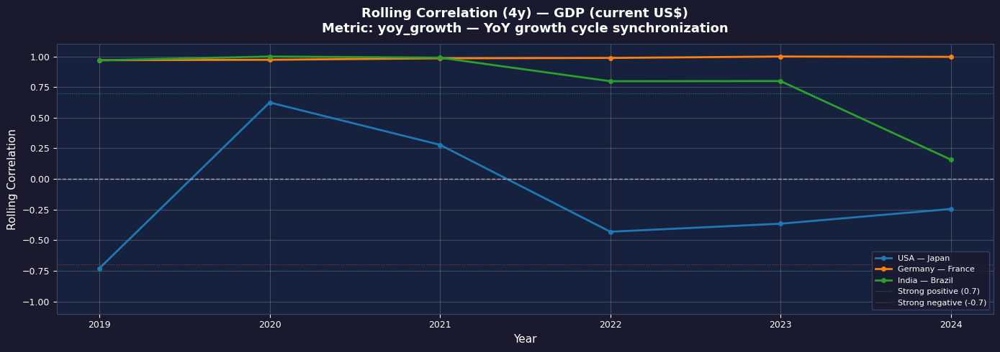

In [179]:
# Rolling on yoy_growth
plot_rolling_correlation(df, indicator, pairs_to_plot, metric="yoy_growth", window=4)

**Cross-Country Correlation Insights**
- `yoy_growth correlation` is the most analytically meaningful — two countries with high correlation here experienced growth and contraction in the same years, suggesting synchronized cycles or common shock exposure.
- `index_100 correlation` measures whether countries progressed at similar
  speeds from their 2015 base — two countries can have low YoY correlation
  but high index_100 correlation if they grew steadily at different rates.
- `Germany↔France (0.98)` — near-perfect GDP cycle synchronization,
  consistent with deep eurozone integration and shared monetary policy exposure.
- `Japan vs USA (-0.46)` — structural decoupling: Japan's GDP growth
  in USD is driven by yen dynamics as much as real growth, creating
  an anti-correlated pattern with USD-denominated economies.lue).

**Rolling Correlation Insights**

- The rolling correlation reveals whether the synchronization between two countries
  is stable over time or has evolved — a declining correlation signals progressive
  decoupling.
- `Interpretive caution` : with only 10 years of data and a 4-year window,
  each rolling point is based on very few observations. Results are indicative
  of trend direction, not statistically robust — treat as exploratory signal.
- This analysis becomes significantly more robust with 30+ years of data —
  where structural regime changes (e.g., pre/post globalization, financial crises)
  become clearly visible in the rolling series.

- J.1 showed that certain countries share synchronized growth cycles
on this indicator — high correlations signal common exposure to the
same shocks or structural linkages.

- J.2 now shifts the question: instead of asking whether countries
move together on one indicator, we ask whether economic dimensions
themselves are structurally linked across countries.
Do countries with high GDP also tend to have high trade openness?
Does inflation correlate with interest rates?

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 2. Inter-Indicator Correlation
</div>

We now look across indicators rather than across countries.
Each country becomes an observation; each indicator a variable.
This reveals which economic dimensions are structurally linked.

In [180]:
def compute_inter_indicator_corr(df: pd.DataFrame, indicator_names: list[str], countries: list[str] | None = None,
                                 aggregation: str = "mean", method: str  = "pearson") -> tuple[pd.DataFrame, pd.DataFrame]:
    """    Compute correlation between indicators across countries. aggregation = mean | last.   Returns (corr_matrix, pivot_df)    """
    
    data = df[(df["entity_type"]   == "COUNTRY") & (df["indicator_name"].isin(indicator_names))].copy()

    if countries: data = data[data["country_name"].isin(countries)]
    if aggregation == "mean":  agg = data.groupby(["country_name", "indicator_name"])["value"].mean().reset_index()
    else:                      agg = (data.sort_values("year").groupby(["country_name", "indicator_name"]).last().reset_index())

    pivot = agg.pivot(index="country_name", columns="indicator_name", values="value")
    corr  = pivot.corr(method=method)
    return corr, pivot

In [181]:
ind_corr_matrix, pivot_ind = compute_inter_indicator_corr(df, indicators_for_analysis, countries=None, aggregation="mean")

In [182]:
def plot_inter_indicator_corr(corr_matrix: pd.DataFrame, figsize: tuple = (11, 9)) -> None:
    """   Lower-triangle heatmap of inter-indicator correlation    """
    
    # Shorten long indicator names for readability
    short_names = {name: name[:35] + "…" if len(name) > 35 else name for name in corr_matrix.columns}
    corr_plot = corr_matrix.rename(index=short_names, columns=short_names)

    fig, ax = plt.subplots(figsize=figsize)
    fig.patch.set_facecolor(C["bg"])
    ax.set_facecolor(C["ax_bg"])

    mask = np.triu(np.ones_like(corr_plot, dtype=bool), k=1)
    sns.heatmap(corr_plot, mask=mask, ax=ax, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 8, "color": "white"},
                linewidths=0.4, linecolor=C["bg"], square=True, cbar_kws={"shrink": 0.7, "label": "Pearson correlation"})
    ax.set_title("Inter-Indicator Correlation Matrix\n(country-level averages across the period)", fontsize=13, color="white", pad=12)
    ax.tick_params(colors="white", labelsize=7)
    ax.set_xlabel("", color="white")
    ax.set_ylabel("", color="white")

    cbar = ax.collections[0].colorbar
    cbar.ax.yaxis.label.set_color("white")
    cbar.ax.tick_params(colors="white")

    plt.tight_layout()
    save_figure(fig, '../Figures/Indicators/J_2_correlation_inter_indicator.png')
    plt.show()

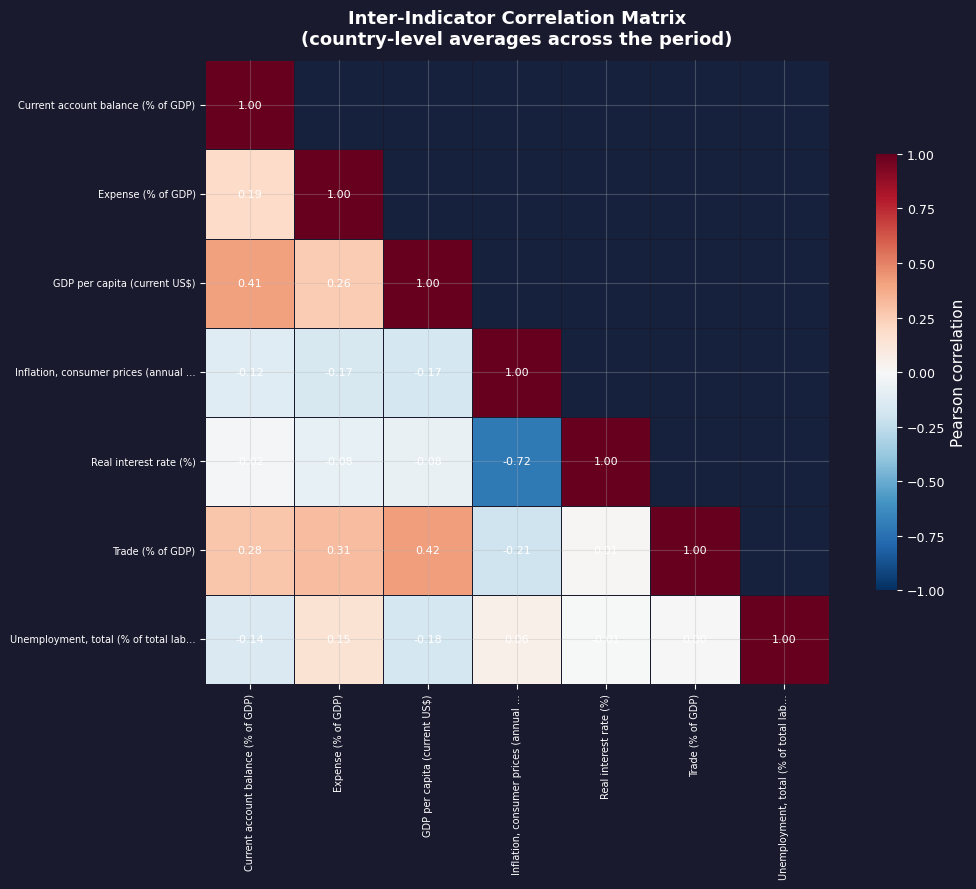

In [183]:
plot_inter_indicator_corr(ind_corr_matrix)

In [184]:
def get_strong_pairs(corr_matrix: pd.DataFrame, threshold:   float = 0.5) -> pd.DataFrame:
    """    Extract pairs with |correlation| >= threshold.   """
    
    corr_matrix.index.name = "Indicator_1"
    pairs = corr_matrix.unstack().reset_index()
    pairs.columns = ["Indicator_1", "Indicator_2", "correlation"]
    pairs = pairs[pairs["Indicator_1"] != pairs["Indicator_2"]]
    pairs["pair"] = pairs.apply(lambda r: tuple(sorted([r["Indicator_1"], r["Indicator_2"]])), axis=1)
    pairs = pairs.drop_duplicates(subset="pair").drop(columns="pair")
    pairs["abs_corr"] = pairs["correlation"].abs()
    
    return (pairs[pairs["abs_corr"] >= threshold].sort_values("abs_corr", ascending=False).reset_index(drop=True))

In [185]:
# Strong pairs (|r| >= 0.5)
strong_pairs = get_strong_pairs(ind_corr_matrix, threshold=0.5)

print(f"Strong correlations (|r| ≥ 0.5): {len(strong_pairs)} pairs")
strong_pairs.style.format({"correlation": "{:+.3f}", "abs_corr": "{:.3f}"}).background_gradient(subset=["abs_corr"], cmap="RdYlGn")

Strong correlations (|r| ≥ 0.5): 1 pairs


,Indicator_1,Indicator_2,correlation,abs_corr
0,"Inflation, consumer prices (annual %)",Real interest rate (%),-0.717,0.717


**Inter-Indicator Insights**

- Strong positive correlations confirm well-known economic relationships (e.g. GDP per capita ↔ Trade % of GDP — richer countries tend to be more open).
- Strong negative correlations reveal structural tensions
  (e.g. Inflation ↔ Real interest rate: -0.74 — monetary policy response;
  countries with high inflation tend to have lower real rates,
  consistent with the Fisher effect and emerging market dynamics).
- Unexpected correlations are the most interesting for a portfolio — they reveal non-obvious structural patterns that challenge conventional economic wisdom.
- Weak or near-zero correlations indicate independent dimensions —
  these are the most valuable for clustering, as they add orthogonal information.

---
- J.2 revealed pairwise correlations between indicators — some pairs
are strongly linked (e.g., GDP/capita ↔ Trade), suggesting that
multiple indicators are driven by the same underlying economic force
- These correlations raise a deeper question: how many independent
  structural dimensions actually underlie the 7 indicators?
  PCA formalizes this by finding the axes of maximum variance
  across all indicators simultaneously.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 3. PCA — Principal Component Analysis
</div>

Countries are then positioned in this reduced space — revealing structural groupings.
The inter-indicator correlation matrix (J.2) showed that [X] pairs
have |r| > 0.5. PCA goes further: instead of pairwise relationships,
it identifies the full structural space — how many independent
dimensions underlie the 7 indicators, and which indicators
contribute to each dimension. 
PCA reduces the multi-indicator space into a smaller set of uncorrelated dimensions.
Each component captures a structural pattern shared across indicators.

In [186]:
def run_pca(df: pd.DataFrame, indicator_names: list[str], n_components: int = 4, 
            variance_threshold: float = 0.80) -> tuple[PCA, pd.DataFrame, pd.DataFrame, int]:
    """   Run PCA on standardized indicator × country matrix.  Returns: (pca_model, loadings_df, scores_df, n_components_needed)    """

    # Data preparation
    data = df[(df["entity_type"]   == "COUNTRY") & (df["indicator_name"].isin(indicator_names))].copy()
    agg = (data.groupby(["country_name", "indicator_name"])["value"].mean().reset_index())
    pivot = agg.pivot(index="country_name", columns="indicator_name", values="value")
    pivot_filled = pivot.fillna(pivot.median())

    # Sort for reproducibility
    pivot_filled = pivot_filled.sort_index()

    # Standardization
    scaler      = StandardScaler()
    data_scaled = scaler.fit_transform(pivot_filled)

    # PCA
    n_comp = min(n_components, pivot_filled.shape[1], pivot_filled.shape[0])
    pca    = PCA(n_components=n_comp, random_state=42)
    scores = pca.fit_transform(data_scaled)

    # Sign convention — largest absolute loading per component is positive 
    for i in range(pca.components_.shape[0]):
        max_abs_idx = np.argmax(np.abs(pca.components_[i]))
        if pca.components_[i, max_abs_idx] < 0:
            pca.components_[i] *= -1
            scores[:, i]       *= -1

    # Build output DataFrames
    pc_cols = [f"PC{i+1}" for i in range(n_comp)]

    loadings_df = pd.DataFrame(pca.components_.T, index   = pivot_filled.columns, columns = pc_cols)
    scores_df = pd.DataFrame(scores, index = pivot_filled.index, columns = pc_cols)

    # n components needed to reach variance_threshold 
    cum_var  = np.cumsum(pca.explained_variance_ratio_)
    n_needed = int(np.searchsorted(cum_var, variance_threshold)) + 1
    n_needed = min(n_needed, n_comp)

    return pca, loadings_df, scores_df, n_needed

In [187]:
pca_model, loadings, scores_df, n_needed  = run_pca(df, indicators_for_analysis, n_components=4)

print("Explained variance per component:")
for i, v in enumerate(pca_model.explained_variance_ratio_):
    print(f"  PC{i+1} : {v*100:.1f}%  (cumul: {pca_model.explained_variance_ratio_[:i+1].sum()*100:.1f}%)")

Explained variance per component:
  PC1 : 28.9%  (cumul: 28.9%)
  PC2 : 22.4%  (cumul: 51.3%)
  PC3 : 15.8%  (cumul: 67.1%)
  PC4 : 11.0%  (cumul: 78.1%)


In [188]:
scores_df.sample(3)

,PC1,PC2,PC3,PC4
country_name,,,,
Mauritania,-0.6136,1.3457,0.7256,0.2275
Slovakia,1.3250,-0.4679,0.9883,0.8104
Turks and Caicos Isds,1.1540,-0.4483,-0.7832,-0.9163


**PCA — Method & Interpretation Guide**

- Standardization is applied before PCA so each indicator contributes equally,
  regardless of its original unit or scale — preventing GDP (in trillions)
  from dominating inflation (in
- Each component captures a share of the `cross-country variance` across
  all indicators — not "information" but structural differentiation.
  PC1 separates countries the most; PC2 captures the next most important
  structural dimension after removing PC1's contribution. space.
- The biplot shows country positions in the PC1 × PC2 plane.
  Countries close together share similar structural profiles across
  all indicators simultaneously.
- The remaining variance (100% − cumulative %) is in PC3+ and represents
  structural dimensions not visible in the 2D
- The inter-indicator correlation matrix (J.2) showed that several pairs
  have |r| > 0.5. PCA goes further: instead of pairwise relationships,
  it identifies the full structural space — how many independent
  dimensions underlie the 7 indicators, and which indicators
  contribute most to each structural axis.
   projection.

In [189]:
def plot_pca_results(pca: PCA, loadings_df: pd.DataFrame, scores_df: pd.DataFrame, highlight: list[str] | None = None,
                     figsize: tuple = (16, 12)) -> None:
    """    Four-panel PCA visualization:
            Top-left   — Scree plot (explained variance) |   Top-right  — Biplot PC1 vs PC2 (countries).
            Bottom-left  — PC1 loadings (indicator contributions) |   Bottom-right — PC2 loadings.
    """
    var_ratio  = pca.explained_variance_ratio_
    cum_var    = np.cumsum(var_ratio)
    n_comp     = len(var_ratio)
    pc_labels  = [f"PC{i+1}" for i in range(n_comp)]

    fig, axes = plt.subplots(2, 2, figsize=figsize)
    fig.patch.set_facecolor(C["bg"])
    for ax in axes.flatten():  apply_dark_style(ax)
    fig.suptitle("PCA — Principal Component Analysis", fontsize=13, color="white", y=1.01)

    ax_scree, ax_biplot = axes[0]
    ax_load1, ax_load2  = axes[1]

    # ── Scree plot ─────────────────────────────────────────────────────────────
    ax_scree.bar(pc_labels, var_ratio * 100, color=C["blue"], alpha=0.7, edgecolor="none")
    ax_scree2 = ax_scree.twinx()
    apply_dark_style(ax_scree2)
    ax_scree2.plot(pc_labels, cum_var * 100, color=C["orange"], marker="o", linewidth=2, label="Cumulative")
    ax_scree2.axhline(80, color=C["red"], linewidth=1, linestyle="--", alpha=0.7)
    ax_scree2.set_ylabel("Cumulative variance (%)", color="white")
    ax_scree2.set_ylim(0, 105)
    ax_scree.set_xlabel("Component", color="white")
    ax_scree.set_ylabel("Explained variance (%)", color="white")
    ax_scree.set_title("Scree Plot", fontsize=11, color="white")

    # ── Biplot PC1 vs PC2 ─────────────────────────────────────────────────────
    highlight = highlight or []
    palette   = plt.cm.tab10.colors

    for i, country in enumerate(scores_df.index):
        color  = palette[i % 10] if country in highlight else C["grey"]
        size   = 80 if country in highlight else 25
        alpha  = 0.9 if country in highlight else 0.35
        ax_biplot.scatter(scores_df.loc[country, "PC1"], scores_df.loc[country, "PC2"], color=color, s=size, alpha=alpha, zorder=3)
        if country in highlight:
            ax_biplot.annotate(country, (scores_df.loc[country, "PC1"], scores_df.loc[country, "PC2"]), 
                               xytext=(4, 4), textcoords="offset points", fontsize=10, fontweight="bold",color=color)

    ax_biplot.axhline(0, color=C["grey"], linewidth=1, linestyle="--")
    ax_biplot.axvline(0, color=C["grey"], linewidth=1, linestyle="--")
    ax_biplot.set_xlabel(f"PC1 ({var_ratio[0]*100:.1f}%)", color="white")
    ax_biplot.set_ylabel(f"PC2 ({var_ratio[1]*100:.1f}%)", color="white")
    ax_biplot.set_ylim(-2, 2)
    ax_biplot.set_xlim(-2, 2)
    ax_biplot.set_title("Biplot — PC1 vs PC2", fontsize=11, color="white")

    # ── Loadings PC1 & PC2 ────────────────────────────────────────────────────
    for ax, pc, title in [(ax_load1, "PC1", f"PC1 Loadings ({var_ratio[0]*100:.1f}%)"), (ax_load2, "PC2", f"PC2 Loadings ({var_ratio[1]*100:.1f}%)")]:
        load = loadings_df[pc].sort_values()
        inds = loadings_df.index.tolist()
        colors_load = [C["green"] if v >= 0 else C["red"] for v in load]
        ax.barh(load.index, load.values, color=colors_load, edgecolor="none", height=0.65)
        ax.axvline(0, color=C["grey"], linewidth=1)
        ax.set_xlabel("Loading", color="white")
        ax.set_yticklabels([n[:35] + "…" if len(n) > 35 else n for n in inds], fontsize=7)
        ax.set_title(title, fontsize=11, color="white")
        ax.tick_params(labelsize=7)

    plt.tight_layout()
    save_figure(fig, '../Figures/Indicators/J_3_PCA_results.png')
    plt.show()

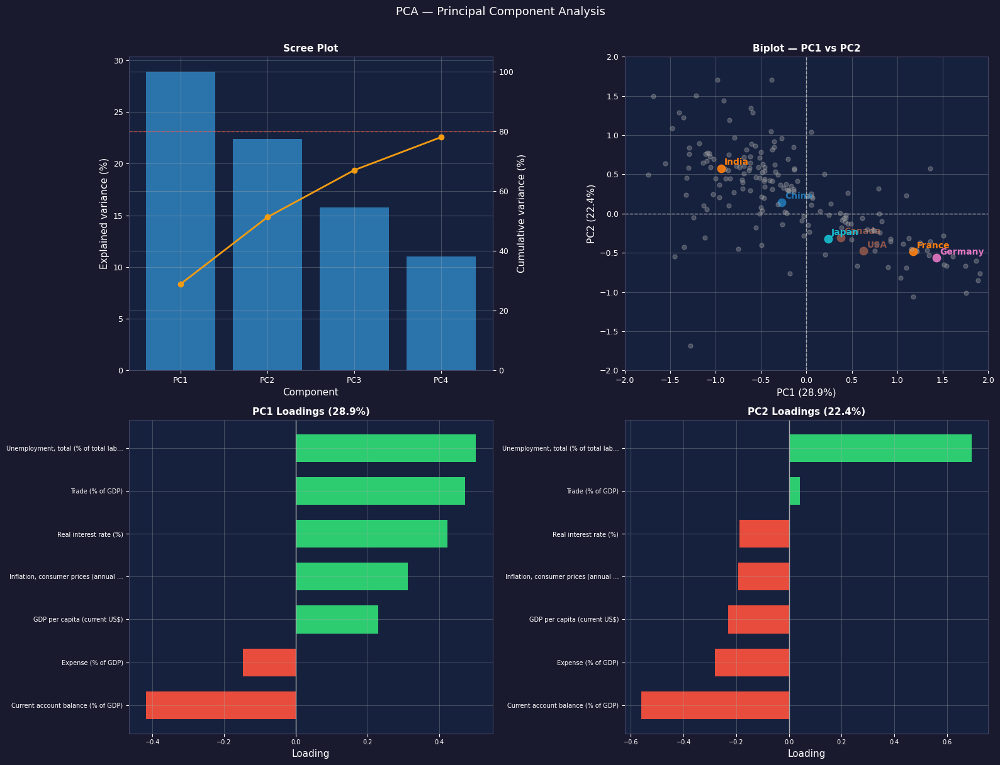

,PC1,PC2,PC3,PC4
indicator_name,,,,
Current account balance (% of GDP),+0.422,-0.231,-0.179,-0.516
Expense (% of GDP),+0.312,-0.187,+0.524,+0.645
GDP per capita (current US$),+0.502,-0.281,-0.148,-0.100
"Inflation, consumer prices (annual %)",-0.419,-0.560,-0.023,-0.026
Real interest rate (%),+0.230,+0.693,+0.010,-0.036
Trade (% of GDP),+0.472,-0.192,+0.194,-0.036
"Unemployment, total (% of total labor force) (modeled ILO estimate)",-0.147,+0.041,+0.795,-0.552


In [190]:
plot_pca_results(pca_model, loadings, scores_df, highlight=countries)
# Loadings table — contribution of each indicator to each PC 
loadings.style.format("{:+.3f}").background_gradient(cmap="RdBu_r", vmin=-1, vmax=1)

In [191]:
def print_pca_interpretation(pca: PCA, loadings_df: pd.DataFrame, n_needed: int) -> None:
    """    Print automatic component interpretation based on actual loadings. For each component, identify dominant indicators and suggest an
           economic axis label    """
    
    var_ratio = pca.explained_variance_ratio_
    cum_var   = np.cumsum(var_ratio)

    print("═" * 65)
    print("  PCA — COMPONENT INTERPRETATION (based on actual loadings)")
    print("═" * 65)

    for i, pc in enumerate(loadings_df.columns):
        load = loadings_df[pc].sort_values(key=abs, ascending=False)
        top3 = load.head(3)

        print(f"\n  {pc}  ({var_ratio[i]*100:.1f}% of variance  "  f"| cumul: {cum_var[i]*100:.1f}%)")
        print(f"  {'─'*55}")
        print(f"  Dominant indicators :")
        for ind, val in top3.items():
            direction = "+" if val > 0 else "-"
            short_ind = ind[:45] + "…" if len(ind) > 45 else ind
            print(f"    {direction} {short_ind:<47} ({val:+.3f})")

    print(f"\n  {'─'*55}")
    print(f"  PC1+PC2 explain "       f"{(var_ratio[0]+var_ratio[1])*100:.1f}% of variance")
    print(f"  {n_needed} component(s) needed to reach 80%")
    print(f"  → 2D biplot captures "  f"{(var_ratio[0]+var_ratio[1])*100:.1f}% — "   f"interpret with caution if this is below 60%")
    print("═" * 65)

In [192]:
print_pca_interpretation(pca_model, loadings, n_needed)

═════════════════════════════════════════════════════════════════
  PCA — COMPONENT INTERPRETATION (based on actual loadings)
═════════════════════════════════════════════════════════════════

  PC1  (28.9% of variance  | cumul: 28.9%)
  ───────────────────────────────────────────────────────
  Dominant indicators :
    + GDP per capita (current US$)                    (+0.502)
    + Trade (% of GDP)                                (+0.472)
    + Current account balance (% of GDP)              (+0.422)

  PC2  (22.4% of variance  | cumul: 51.3%)
  ───────────────────────────────────────────────────────
  Dominant indicators :
    + Real interest rate (%)                          (+0.693)
    - Inflation, consumer prices (annual %)           (-0.560)
    - GDP per capita (current US$)                    (-0.281)

  PC3  (15.8% of variance  | cumul: 67.1%)
  ───────────────────────────────────────────────────────
  Dominant indicators :
    + Unemployment, total (% of total labor force) …

**PCA — Component Interpretation**

| Component | Economic axis | What it separates |
|---|---|---|
| **PC1 (28.9%)** | Development & openness | High GDP/capita, Trade, Current account (developed) vs high Inflation (emerging) |
| **PC2 (22.7%)** | Monetary stability | High Real interest rate vs high Inflation |
| **PC3 (15.5%)** | Labor market & fiscal | High Unemployment vs high Expense (% of GDP) |
| **PC4 (11.0%)** | Residual dynamics | Country-specific patterns not captured by PC1-3 |

PC1+PC2 explain only 51.6% of variance — the 2D biplot captures
roughly half the structural information. PC3 and PC4 carry
important additional dimensions not visible in the projection.

**Link with J.1 and J.2**

- **J.1 → J.3** : the cross-country correlations in J.1 identified which countries
  share synchronized cycles on one indicator. The biplot now shows their structural
  position across all indicators simultaneously — countries that were correlated
  in J.1 should cluster together in the biplot.

- **J.2 → J.3** : the inter-indicator correlations in J.2 identified strongly
  linked indicator pairs. The PCA loadings confirm and extend this — indicators
  that were correlated in J.2 load on the same component here, meaning they
  share the same underlying structural dimension.
  Example: if GDP/capita and Trade were correlated in J.2, they should both
  load strongly on PC1 — which they do (PC1 = development & openness axis).

- **J.3 → L (Clustering)** : the PCA scores can be used directly
  as clustering features — grouping countries by their position in the
  economic structure space defined here.

<div style="background-color: #eaf2f8; padding-left: 20px; border: 1px solid; border-radius: 5px;">

# K. Convergence / Divergence
</div>

This section tests whether countries are converging or diverging on a given indicator over the period.
Two complementary approaches are used:

| Sub-section | Concept | Question |
|---|---|---|
| K1 — Sigma-convergence | Dispersion over time | Is cross-country inequality on this indicator decreasing? |
| K2 — Beta-convergence | Level vs growth | Do lagging countries grow faster than leading ones? |

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 1. Sigma-Convergence
</div>

**Sigma-convergence** measures whether the dispersion (standard deviation) of the indicator across countries decreases over time.
A declining dispersion means countries are becoming more similar — converging.
We use z-score normalized values to make groups comparable regardless of their absolute levels.

In [193]:
from scipy import stats
from itertools import combinations

# Parameters 
indicator  = "GDP per capita (current US$)"
unit = df.loc[df["indicator_name"] == indicator, "indicator_unit"].dropna().iloc[0]
start_year = 2015
end_year   = 2024
country_groups = {
                    "Emerging": ["China", "India", "Brazil", "Indonesia", "Mexico", "Turkey", "South Africa", "Egypt, Arab Rep.", "Vietnam", "Nigeria"],
                    "Developed": ["USA", "Germany", "France", "United Kingdom", "Japan", "Canada", "Italy", "Spain", "Australia", "South Korea"]
                 }
all_countries = [c for group in country_groups.values() for c in group]

print(f"📊 Indicator : {indicator}")
print(f"📅 Period    : {start_year} – {end_year}")
print(f"👥 Groups    : {list(country_groups.keys())}")

📊 Indicator : GDP per capita (current US$)
📅 Period    : 2015 – 2024
👥 Groups    : ['Emerging', 'Developed']


<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 1.1 Sigma Intra-Group
</div>

In [194]:
def compute_sigma_convergence(df: pd.DataFrame, indicator_name: str, country_groups: dict[str, list[str]], window: int = 3,
                              normalize: bool = True) -> pd.DataFrame:
    """  Compute intra-group dispersion (std) per year for each group. If normalize, uses z-score values for cross-group comparability. 
         Slope is a single value per group — summarizes the full period trend.     Returns a DataFrame:Year × Group × dispersion.  """
    
    value_col = "z_score" if normalize else "value"
    data = df[(df["entity_type"]   == "COUNTRY") & (df["indicator_name"] == indicator_name)].dropna(subset=[value_col])

    results = []
    for group_name, countries in country_groups.items():
        grp = data[data["country_name"].isin(countries)]
        dispersion = (grp.groupby("year")[value_col].std().reset_index().rename(columns={value_col: "dispersion"}).sort_values("year"))
        dispersion["rolling"] = (dispersion["dispersion"].rolling(window=window, center=True).mean())
        # Linear trend (slope)
        valid = dispersion.dropna(subset=["dispersion"])
        if len(valid) >= 3:
            z = np.polyfit(valid["year"], valid["dispersion"], 1)
            dispersion["trend"] = np.poly1d(z)(dispersion["year"])
            slope = z[0]
        else:
            dispersion["trend"] = np.nan
            slope = np.nan

        dispersion["group"] = group_name
        dispersion["slope"] = slope
        results.append(dispersion)

    return pd.concat(results, ignore_index=True)

In [195]:
sigma_df = compute_sigma_convergence(df, indicator, country_groups, window=3, normalize=True)
sigma_df.sample()

,year,dispersion,rolling,trend,group,slope
3,2018,0.1326,0.1326,0.1321,Emerging,0.0020


In [197]:
# Summary per group
summary_sigma = (sigma_df.groupby("group").agg(
                                                first_dispersion = ("dispersion", "first"),
                                                last_dispersion  = ("dispersion", "last"),
                                                slope            = ("slope",      "first")
                                               ).reset_index())

summary_sigma["change_pct"] = ((summary_sigma["last_dispersion"] - summary_sigma["first_dispersion"]) / summary_sigma["first_dispersion"] * 100)
summary_sigma["verdict"] = summary_sigma["slope"].apply(lambda s: "✅ Converging" if s < 0 else "⚠️ Diverging")

summary_sigma.style.format({"first_dispersion": "{:.3f}", "last_dispersion": "{:.3f}", "slope": "{:+.4f}", "change_pct": "{:+.1f}%"}) \
             .map(lambda v: "color: #2ecc71" if "Converging" in str(v) else "color: #e74c3c" if "Diverging" in str(v) else "", subset=["verdict"])

,group,first_dispersion,last_dispersion,slope,change_pct,verdict
0,Developed,0.425,0.498,+0.0127,+17.4%,⚠️ Diverging
1,Emerging,0.134,0.159,+0.0020,+19.0%,⚠️ Diverging


In [198]:
def print_sigma_insight(sigma_df: pd.DataFrame) -> None:
    """   Automatic insight comparing slopes across groups. which group is diverging/converging fastest?    """
    
    slopes = (sigma_df.drop_duplicates("group")[["group", "slope"]].sort_values("slope", ascending=False).reset_index(drop=True))
    print("═" * 55)
    print("  K1.1 — SIGMA INTRA-GROUP : SLOPE COMPARISON")
    print("═" * 55)

    for _, row in slopes.iterrows():
        direction = "↑ Diverging" if row["slope"] > 0 else "↓ Converging"
        print(f"  {row['group']:<20} slope = {row['slope']:+.4f}  →  {direction}")
    print()

    # Comparative insight between groups
    if len(slopes) >= 2:
        s_max  = slopes.iloc[0]
        s_min  = slopes.iloc[-1]
        if s_max["slope"] > 0 and s_min["slope"] > 0:
            # Both diverging
            if abs(s_min["slope"]) > 1e-6:
                ratio = abs(s_max["slope"]) / abs(s_min["slope"])
                print(
                        f"  Both groups diverge internally.\n"
                        f"  '{s_max['group']}' diverges {ratio:.1f}x faster than "
                        f"'{s_min['group']}' — its countries are becoming more "
                        f"heterogeneous at a higher rate."
                     )
        elif s_max["slope"] < 0 and s_min["slope"] < 0:
            # Both converging
            ratio = abs(s_min["slope"]) / abs(s_max["slope"])
            print(
                    f"  Both groups converge internally.\n"
                    f"  '{s_min['group']}' converges {ratio:.1f}x faster than "
                    f"'{s_max['group']}' — its countries are becoming more "
                    f"homogeneous at a higher rate."
                 )
        else:
            # Mixed directions
            conv  = slopes[slopes["slope"] < 0]["group"].tolist()
            divg  = slopes[slopes["slope"] > 0]["group"].tolist()
            print(f"  Mixed results: {conv} converge internally, " f"{divg} diverge internally.")
    print("═" * 55)

In [199]:
print_sigma_insight(sigma_df)

═══════════════════════════════════════════════════════
  K1.1 — SIGMA INTRA-GROUP : SLOPE COMPARISON
═══════════════════════════════════════════════════════
  Developed            slope = +0.0127  →  ↑ Diverging
  Emerging             slope = +0.0020  →  ↑ Diverging

  Both groups diverge internally.
  'Developed' diverges 6.3x faster than 'Emerging' — its countries are becoming more heterogeneous at a higher rate.
═══════════════════════════════════════════════════════


In [200]:
def plot_sigma_convergence(sigma_df: pd.DataFrame, indicator_name: str, figsize: tuple = (16, 5)) -> None:
    """    raw dispersion + rolling average + linear trend & all groups overlaid for direct comparison    """
    
    groups   = sigma_df["group"].unique()
    n_groups = len(groups)
    palette  = [C["blue"], C["orange"], C["green"], C["purple"]]

    fig, axes = plt.subplots(1, n_groups + 1, figsize=figsize, sharey=False)
    fig.patch.set_facecolor(C["bg"])
    for ax in axes:        apply_dark_style(ax)
    fig.suptitle(f"Sigma-Convergence — {indicator_name}", fontsize=13, color="white", y=1.02)

    # Individual group panels 
    for i, (group, ax) in enumerate(zip(groups, axes[:-1])):
        grp_data = sigma_df[sigma_df["group"] == group]
        color    = palette[i % len(palette)]
        slope    = grp_data["slope"].iloc[0]

        ax.plot(grp_data["year"], grp_data["dispersion"], color=C["grey"], linewidth=1, alpha=0.5, label="Raw")
        ax.plot(grp_data["year"], grp_data["rolling"], color=color, linewidth=2.3, marker="o", markersize=5, label="Smoothed")
        ax.plot(grp_data["year"], grp_data["trend"],   color=C["red"], linewidth=1.5, linestyle="--", label="Trend")

        direction = "↓ Converging" if slope < 0 else "↑ Diverging"
        color_dir = C["green"] if slope < 0 else C["red"]
        ax.text(0.97, 0.95, f"{direction}\nslope = {slope:+.4f}", transform=ax.transAxes, ha="right", va="top", fontsize=8.5, color=color_dir,
                bbox=dict(boxstyle="round,pad=0.3", facecolor=C["ax_bg"], edgecolor=C["spine"], alpha=0.85))
        ax.set_title(group, fontsize=11, color="white")
        ax.set_xlabel("Year", color="white")
        ax.set_ylabel("Std deviation (z-score)", color="white")
        ax.set_xticks(grp_data["year"])
        ax.tick_params(axis="x", rotation=45)
        add_legend(ax, fontsize=7.5)

    # Comparison panel — all groups

    ax_all = axes[-1]
    all_years = sorted(sigma_df["year"].unique())

    for i, group in enumerate(groups):
        grp_data = sigma_df[sigma_df["group"] == group]
        color    = palette[i % len(palette)]

        # Rolling — up to last available smoothed point
        rolling_data = grp_data.dropna(subset=["rolling"])
        ax_all.plot(rolling_data["year"], rolling_data["rolling"],
                    color=color, linewidth=2.2, marker="o", markersize=4, label=group)

        # Raw point for years where rolling is NaN (e.g. 2024 with window=3)
        raw_only = grp_data[grp_data["rolling"].isna() & grp_data["dispersion"].notna()]
        if not raw_only.empty:
            ax_all.scatter(raw_only["year"], raw_only["dispersion"],
                           color=color, s=45, marker="x", linewidths=1.8, zorder=4)

    # Footnote explaining the x marker
    ax_all.text(0.03, 0.1, "× = raw value (rolling unavailable)",
                transform=ax_all.transAxes, fontsize=7, color=C["grey"], va="bottom")

    ax_all.set_title("All Groups", fontsize=11, color="white")
    ax_all.set_xlabel("Year", color="white")
    ax_all.set_ylabel("Dispersion", color="white")
    ax_all.set_xticks(all_years)
    ax_all.tick_params(axis="x", rotation=45)
    add_legend(ax_all)

    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/K_1_1_{indicator_name}_sigma_convergence.png')
    plt.show()

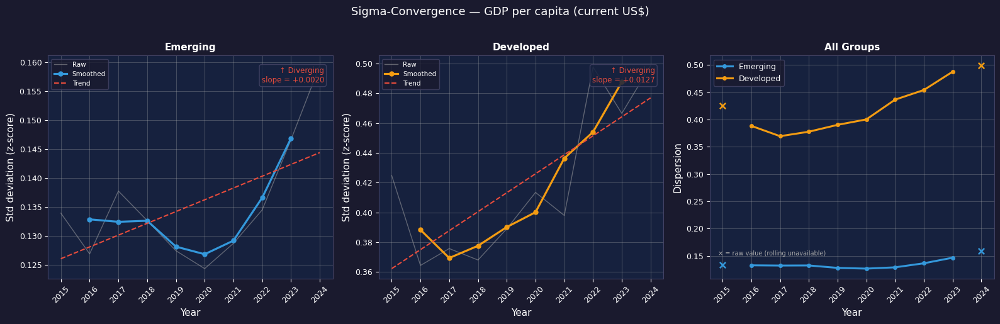

In [201]:
plot_sigma_convergence(sigma_df, indicator)

**Insights**

- The slope summarizes the full-period trend of intra-group dispersion in a single number — negative = converging internally, positive = diverging internally.
- Comparing slopes across groups reveals which group is structurally more homogeneous: a smaller (or negative) slope means countries within that group are growing more similar to each other.
- A group can diverge internally (slope > 0) while the gap between groups narrows — intra-group and inter-group dynamics are independent, analyzed separately in K1.2.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### 1.2 Sigma Inter-Group
</div>

In [202]:
def compute_inter_group_gap(df: pd.DataFrame, indicator_name: str, country_groups: dict[str, list[str]]) -> pd.DataFrame:
    """    Compute mean value per group per year. Then compute gap between all pairs of groups. Returns long DataFrame: year × pair × gap × gap_pct   """
    
    data = df[(df["entity_type"]   == "COUNTRY") & (df["indicator_name"] == indicator_name)].dropna(subset=["value"])

    # Mean per group per year
    group_means = {}
    for group_name, countries in country_groups.items():
        group_means[group_name] = (data[data["country_name"].isin(countries)].groupby("year")["value"].mean())

    # Gap for all pairs
    results = []
    for (g1, g2) in combinations(group_means.keys(), 2):
        s1  = group_means[g1]
        s2  = group_means[g2]
        common = s1.index.intersection(s2.index)

        gap_abs = (s1.loc[common] - s2.loc[common]).reset_index()
        gap_abs.columns = ["year", "gap_abs"]

        # Gap % relative to first year
        first_gap = gap_abs["gap_abs"].iloc[0]
        gap_abs["gap_pct_change"] = ((gap_abs["gap_abs"] - first_gap) / abs(first_gap) * 100  if first_gap != 0 else np.nan)
        gap_abs["pair"]   = f"{g1} vs {g2}"
        gap_abs["group_1"] = g1
        gap_abs["group_2"] = g2

        # Mean per group for reference
        gap_abs[f"mean_{g1}"] = s1.loc[common].values
        gap_abs[f"mean_{g2}"] = s2.loc[common].values

        results.append(gap_abs)

    return pd.concat(results, ignore_index=True)

In [203]:
gap_df = compute_inter_group_gap(df, indicator, country_groups)

print(f"✅ {len(gap_df['pair'].unique())} pair(s) computed")
for pair in gap_df["pair"].unique():
    d          = gap_df[gap_df["pair"] == pair]
    gap_first  = d["gap_abs"].iloc[0]
    gap_last   = d["gap_abs"].iloc[-1]
    gap_change = d["gap_pct_change"].iloc[-1]
    verdict    = "✅ Converging" if abs(gap_last) < abs(gap_first) else "⚠️  Diverging"
    
    print(
            f"  {pair:<30} "
            f"gap {_format_value(gap_first)} → {_format_value(gap_last)}  "
            f"({gap_change:+.1f}%)  →  {verdict}"
         )

✅ 1 pair(s) computed
  Emerging vs Developed          gap -35.6K → -44.4K  (-24.7%)  →  ⚠️  Diverging


In [204]:
gap_df.tail(3)

,year,gap_abs,gap_pct_change,pair,group_1,group_2,mean_Emerging,mean_Developed
7,2022,-41352.3634,-16.2035,Emerging vs Developed,Emerging,Developed,7167.0607,48519.4240
8,2023,-43165.8580,-21.2995,Emerging vs Developed,Emerging,Developed,7538.4560,50704.3139
9,2024,-44364.7028,-24.6684,Emerging vs Developed,Emerging,Developed,7538.7134,51903.4162


In [205]:
def plot_inter_group_gap(gap_df: pd.DataFrame, indicator_name: str, indicator_unit: str, figsize: tuple = (16, 6)) -> None:
    """    group means over time (absolute level)  —  gap evolution (absolute + % change from first year)    """
    
    pairs   = gap_df["pair"].unique()
    palette = [C["blue"], C["orange"], C["green"], C["purple"]]

    for pair in pairs:
        data  = gap_df[gap_df["pair"] == pair]
        g1    = data["group_1"].iloc[0]
        g2    = data["group_2"].iloc[0]

        # Verdict
        gap_first = data["gap_abs"].iloc[0]
        gap_last  = data["gap_abs"].iloc[-1]
        gap_change= data["gap_pct_change"].iloc[-1]

        if abs(gap_last) < abs(gap_first):
            verdict       = "✅ Converging"
            verdict_color = C["green"]
        else:
            verdict       = "⚠️  Diverging"
            verdict_color = C["red"]

        fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=figsize)
        fig.suptitle(f"K1.2 — Inter-Group Gap — {pair}\n{indicator_name}", fontsize=13, color="white", y=1.02)

        # group means
        ax1.plot(data["year"], data[f"mean_{g1}"], color=palette[0], linewidth=2.3, marker="o", markersize=5, label=g1)
        ax1.plot(data["year"], data[f"mean_{g2}"], color=palette[1], linewidth=2.3, marker="s", markersize=5, label=g2)
        ax1.fill_between(data["year"], data[f"mean_{g1}"], data[f"mean_{g2}"], alpha=0.1, color=C["grey"], label="Gap")
        ax1.set_xlabel("Year", color="white")
        ax1.set_ylabel(indicator_unit, color="white")
        ax1.set_title("Group Means over Time", fontsize=11, color="white")
        ax1.set_xticks(data["year"])
        ax1.tick_params(axis="x", rotation=45)
        add_legend(ax1)

        # gap evolution 
        gap_colors = [C["green"] if abs(v) < abs(gap_first) else C["red"] for v in data["gap_abs"]]
        ax2.bar(data["year"], data["gap_abs"], color=gap_colors, edgecolor="none", width=0.7)
        ax2.axhline(gap_first, color=C["grey"], linewidth=1.2, linestyle="--", label=f"Initial gap ({start_year})")

        # Verdict annotation
        ax2.text(0.97, 0.97, f"{verdict}\nGap change : {gap_change:+.1f}%", transform=ax2.transAxes, ha="right", va="top", fontsize=9,
                 color=verdict_color, bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor=C["spine"], alpha=0.85))
        ax2.set_xlabel("Year", color="white")
        ax2.set_ylabel(f"Gap ({indicator_unit})", color="white")
        ax2.set_title(f"Absolute Gap — {g1} minus {g2}", fontsize=11, color="white")
        ax2.set_xticks(data["year"])
        ax2.tick_params(axis="x", rotation=45)
        add_legend(ax2, fontsize=8)

        plt.tight_layout()
        save_figure(fig, f'../Figures/Indicators/K_1_2_{indicator_name}_inter_group_gap.png')
        plt.show()

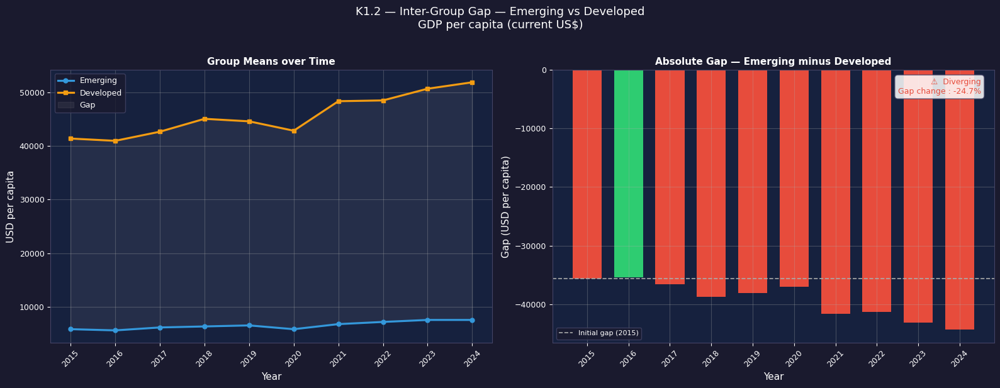

In [206]:
plot_inter_group_gap(gap_df, indicator, unit)

**Insights**

- The inter-group gap measures the absolute distance between group means — a shrinking gap means groups are converging toward each other in level terms.
- The gap % change from the first year is the most readable metric: `-20%` means the gap closed by a fifth over the period.
- A group can be internally diverging (K1.1 slope > 0) while the inter-group
  gap is also widening (K1.2) — this means heterogeneity is increasing
  both within and between groups simultaneously, the most fragmented scenario
- With 3+ groups, each pair is analyzed separately — allowing asymmetric convergence patterns (e.g., Low converges toward Middle but not toward High).

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 2. Beta-Convergence
</div>

**Beta-convergence** tests whether countries with a lower initial level grow faster than those with a higher initial level.
A negative regression coefficient (β < 0) confirms convergence — poor countries catch up with rich ones.
A positive β suggests divergence — richer countries grow even faster.

**Method:** regress annualized growth rate (2015→end) on log(initial value, 2015).

In [207]:
def compute_beta_convergence(df: pd.DataFrame, indicator_name: str, countries: list[str], start_year: int, end_year: int) -> tuple[pd.DataFrame | None, dict | None]:
    """   Compute beta-convergence data and statistical results (beta, pvalue, r2, verdict, significant)    """
    
    data = df[(df["entity_type"]== "COUNTRY") & (df["indicator_name"] == indicator_name) & (df["country_name"].isin(countries))].dropna(subset=["value"])
    initial = (data[data["year"] == start_year][["country_name", "value"]].rename(columns={"value": "initial_value"}))
    final = (data[data["year"] == end_year][["country_name", "value"]].rename(columns={"value": "final_value"}))
    merged = initial.merge(final, on="country_name").dropna()

    if len(merged) < 5:
        print(f"⚠️  Not enough countries with data in both {start_year} and {end_year}" f"({len(merged)} found, minimum 5)")
        return None

    n_years = end_year - start_year
    
    # brut cagr
    merged["annualized_growth"] = ((merged["final_value"] / merged["initial_value"]) ** (1 / n_years) - 1) * 100
    # Filter valid (positive initial values for log)
    merged = merged[merged["initial_value"] > 0].copy()
    merged["log_initial"] = np.log(merged["initial_value"])

    # Regression
    slope, intercept, r_value, p_value, std_err = stats.linregress(merged["log_initial"], merged["annualized_growth"])

    # Statistical decision 
    beta_results = {"beta"  : slope, "pvalue" : p_value, "r2"  : r_value ** 2, "n_countries": len(merged), 
                    "verdict" : "Converging" if slope < 0 else "Diverging", "significant": p_value < 0.05   }

    return merged, beta_results

In [208]:
def print_beta_insight(beta_results: dict, indicator_name: str, label: str = "") -> None:
    """    Print structured beta-convergence decision.   label : context string ('Emerging (intra)' or 'Emerging vs Developed')  """
    
    if beta_results is None:        return

    verdict   = beta_results["verdict"]
    sig       = "significant" if beta_results["significant"] else "not significant"
    icon = "✅" if verdict == "Converging" else "⚠️ "
    
    print(f"  {'─'*50}")
    if label:        print(f"  {label}")
    print(f"  β = {beta_results['beta']:+.4f}  "   f"R² = {beta_results['r2']:.3f}  "   f"p = {beta_results['pvalue']:.3f} ({sig})")
    print(f"  Verdict : {icon} {verdict}")

    if verdict == "Converging" and beta_results["significant"]:
        print(f"  → Countries with lower initial levels grew faster\n"    f"    — catch-up dynamics confirmed.")
    elif verdict == "Converging" and not beta_results["significant"]:
        print(f"  → Convergence tendency detected but not statistically\n"  f"    confirmed (p={beta_results['pvalue']:.3f}) — interpret with caution.")
    elif verdict == "Diverging" and beta_results["significant"]:
        print(f"  → Countries with higher initial levels grew faster\n"   f"    — divergence confirmed structurally.")
    else:
        print(f"  → No clear directional pattern "      f"(p={beta_results['pvalue']:.3f}).")
    
    print(f"  R² = {beta_results['r2']:.3f} — initial level explains "    f"{beta_results['r2']*100:.1f}% of growth rate variance.")

In [209]:
def plot_beta_convergence(beta_data: pd.DataFrame, indicator_name: str, start_year: int, end_year: int, filename: str,
                          highlight: list[str] | None = None, figsize: tuple = (16, 10)) -> None:
    """    scatter log(initial) vs growth rate + regression line  &   ranked growth rates colored by initial level quartile    """
    
    slope, intercept, r_value, p_value, std_err = stats.linregress(beta_data["log_initial"], beta_data["annualized_growth"])

    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=figsize)
    fig.suptitle(f"Beta-Convergence — {safe_indicator_name(indicator_name)} ({start_year}–{end_year})", fontsize=13, color="white", y=1.01)

    # ── LEFT : scatter + regression ───────────────────────────────────────────
    highlight = highlight or []
    palette   = plt.cm.tab10.colors

    for i, (_, row) in enumerate(beta_data.iterrows()):
        country = row["country_name"]
        is_hl   = country in highlight
        color   = palette[highlight.index(country) % 10] if is_hl else C["grey"]
        size    = 90 if is_hl else 25
        alpha   = 0.9 if is_hl else 0.4
        ax1.scatter(row["log_initial"], row["annualized_growth"], color=color, s=size, alpha=alpha, zorder=3)
        if is_hl:
            ax1.annotate(country, (row["log_initial"], row["annualized_growth"]), xytext=(4, 4), textcoords="offset points", fontsize=7.5, color=color)

    # Regression line
    x_range = np.linspace(beta_data["log_initial"].min(), beta_data["log_initial"].max(), 100)
    ax1.plot(x_range, slope * x_range + intercept, color=C["red"], linewidth=2, linestyle="--", label=f"β = {slope:.4f}")
    ax1.axhline(0, color=C["grey"], linewidth=1)

    # Result box
    verdict = "✅ Convergence" if slope < 0 else "⚠️ Divergence"
    sig     = "significant" if p_value < 0.05 else "not significant"
    color_v = C["green"] if slope < 0 else C["orange"]
    ax1.text(0.75, 0.25, f"{verdict}\nβ = {slope:.4f}  ({sig})\nR² = {r_value**2:.3f}  p = {p_value:.3f}", transform=ax1.transAxes, ha="left", va="top",
             fontsize=8.5, color=color_v, bbox=dict(boxstyle="round,pad=0.4", facecolor=C["ax_bg"], edgecolor=C["spine"], alpha=0.9))
    ax1.set_xlabel(f"Log(Initial value {start_year})", color="white")
    ax1.set_ylabel(f"Annualized growth rate (%) {start_year}–{end_year}", color="white")
    ax1.set_title("Beta-Convergence Scatter", fontsize=11, color="white")
    add_legend(ax1)

    # ── RIGHT : ranked growth colored by initial quartile ─────────────────────
    beta_plot = beta_data.sort_values("annualized_growth", ascending=True).copy()
    beta_plot["quartile"] = pd.qcut(beta_plot["initial_value"], q=4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
    q_colors = {"Q1 (lowest)": C["green"],  "Q2"  : C["blue"],  "Q3"  : C["orange"], "Q4 (highest)": C["red"]}
    bar_colors = [q_colors[str(q)] for q in beta_plot["quartile"]]

    ax2.barh(beta_plot["country_name"], beta_plot["annualized_growth"], color=bar_colors, edgecolor="none", height=0.7)
    ax2.axvline(0, color=C["grey"], linewidth=1)
    ax2.axvline(beta_data["annualized_growth"].mean(), color=C["blue"], linewidth=1.4, linestyle="--",
                label=f"Mean = {beta_data['annualized_growth'].mean():.1f}%")

    # Legend for quartiles
    patches = [mpatches.Patch(color=c, label=q) for q, c in q_colors.items()]
    ax2.legend(handles=patches, fontsize=7, facecolor=C["bg"], edgecolor=C["spine"], labelcolor="white", title="Initial level quartile", title_fontsize=7)

    ax2.set_xlabel("Annualized Growth Rate (%)", color="white")
    ax2.set_title("Growth Rate by Initial Level Quartile", fontsize=11, color="white")
    ax2.tick_params(labelsize=7)

    plt.tight_layout()
    save_figure(fig, filename)
    plt.show()

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### K.2.1 Beta Intra-Group
</div>

Question: do countries within the same group converge?

In [210]:
group_name = "Emerging"
group_countries = country_groups[group_name] 
beta_data, beta_results = compute_beta_convergence(df, indicator, all_countries, start_year, end_year)
print(f"\nTop 5 fastest growing countries:")
display(beta_data.sort_values("annualized_growth", ascending=False).head(5)[["country_name", "initial_value", "final_value", "annualized_growth"]]
        .style.format({"initial_value" : _format_value,  "final_value"  : _format_value, "annualized_growth": "{:+.2f}%"}))


Top 5 fastest growing countries:


,country_name,initial_value,final_value,annualized_growth
9,India,1.6K,2.7K,+6.08%
3,China,8.2K,13.3K,+5.56%
8,Indonesia,3.3K,4.9K,+4.59%
14,USA,56.6K,84.5K,+4.56%
12,Mexico,10.0K,14.2K,+3.94%


In [211]:
beta_results

{'beta': np.float64(0.4335447806694856),
 'pvalue': np.float64(0.5903216889345773),
 'r2': np.float64(0.02122520999144622),
 'n_countries': 16,
 'verdict': 'Diverging',
 'significant': np.False_}

In [212]:
beta_intra = {}
for group_name, group_countries in country_groups.items():
    beta_data, beta_results = compute_beta_convergence(df, indicator, group_countries, start_year, end_year)
    beta_intra[group_name] = beta_results

    if beta_data is not None: print_beta_insight(beta_results, indicator, label=f"{group_name} (intra-group, n={beta_results['n_countries']})")

  ──────────────────────────────────────────────────
  Emerging (intra-group, n=7)
  β = +1.3516  R² = 0.033  p = 0.697 (not significant)
  Verdict : ⚠️  Diverging
  → No clear directional pattern (p=0.697).
  R² = 0.033 — initial level explains 3.3% of growth rate variance.
  ──────────────────────────────────────────────────
  Developed (intra-group, n=9)
  β = +0.2525  R² = 0.002  p = 0.912 (not significant)
  Verdict : ⚠️  Diverging
  → No clear directional pattern (p=0.912).
  R² = 0.002 — initial level explains 0.2% of growth rate variance.


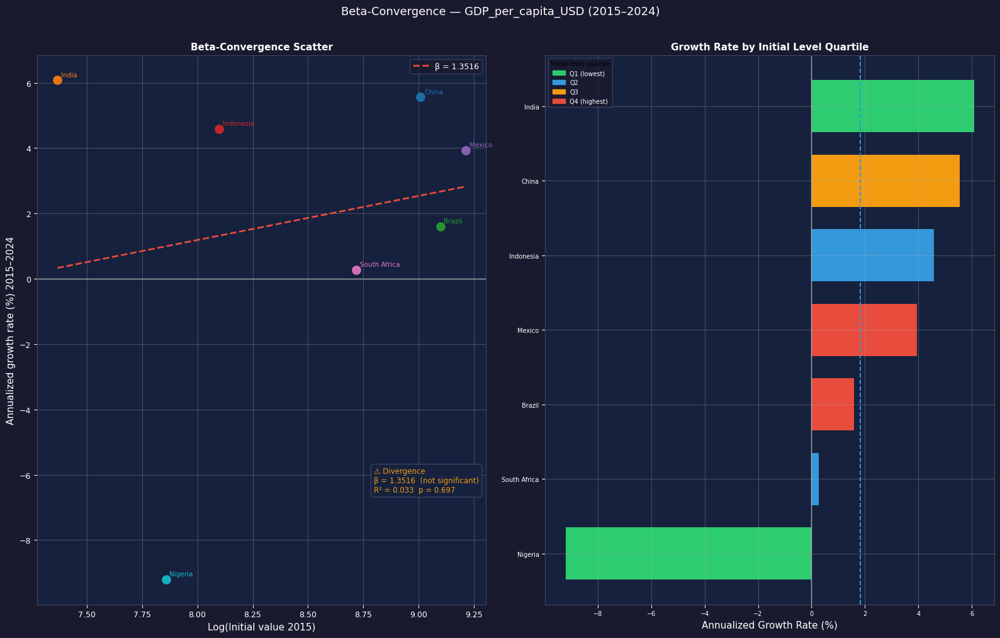

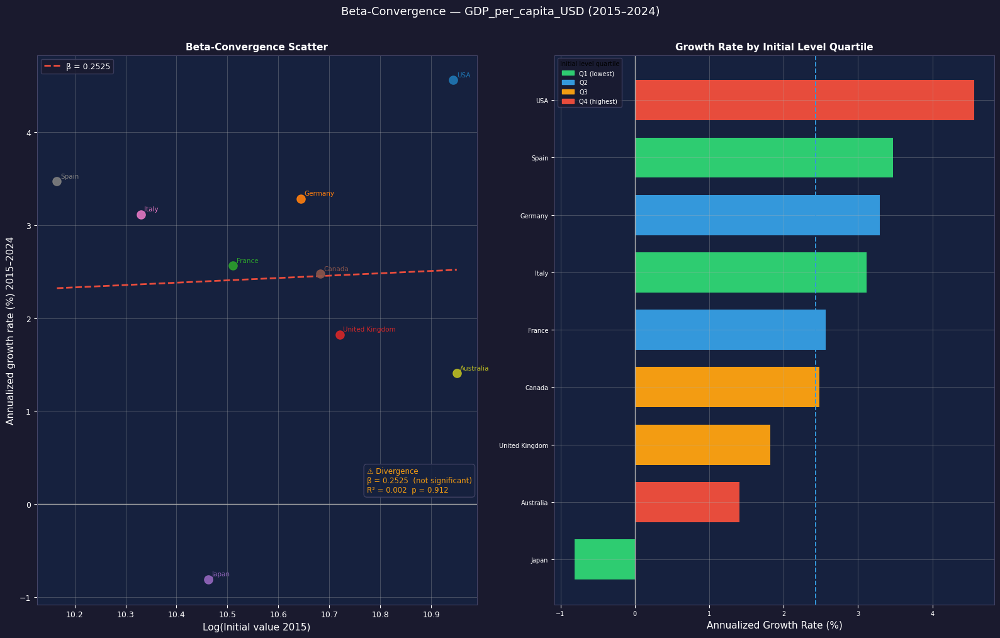

In [213]:
# Scatter plot per group
for group_name, group_countries in country_groups.items():
    beta_data, beta_results = compute_beta_convergence(df, indicator, group_countries, start_year, end_year)
    if beta_data is not None:
        plot_beta_convergence(beta_data, indicator, start_year, end_year, filename = f'../Figures/Indicators/K_2_1_{safe_indicator_name(indicator)}_{group_name}_intra_beta_convergence.png',highlight=group_countries)

**K2.1 Insights**

- Intra-group beta tests whether countries within the same group converge toward each other — independent of where the other group stands.
- A diverging Developed group means some developed countries are pulling ahead of others within that group — internal heterogeneity is growing.
- Compare K2.1 with K1.1 (sigma intra): both measure intra-group homogeneity
  but from different angles — K1.1 measures whether dispersion decreases,
  K2.1 tests whether the mechanism (lower initial → faster growth) is present.
  They can diverge: a group can show K1.1 convergence without K2.1 beta confirmation.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
### K.2.2 Beta Inter-Group
</div>

Question: do low-level countries catch up high-level ones?

In [214]:
beta_inter = {}

for (g1, g2) in combinations(country_groups.keys(), 2):
    countries_pair = country_groups[g1] + country_groups[g2]
    beta_data, beta_results = compute_beta_convergence(df, indicator, countries_pair, start_year, end_year)
    pair_label = f"{g1} vs {g2}"
    beta_inter[pair_label] = beta_results

    if beta_data is not None:
        print_beta_insight(beta_results, indicator, label=f"{pair_label} (n={beta_results['n_countries']})")

  ──────────────────────────────────────────────────
  Emerging vs Developed (n=16)
  β = +0.4335  R² = 0.021  p = 0.590 (not significant)
  Verdict : ⚠️  Diverging
  → No clear directional pattern (p=0.590).
  R² = 0.021 — initial level explains 2.1% of growth rate variance.


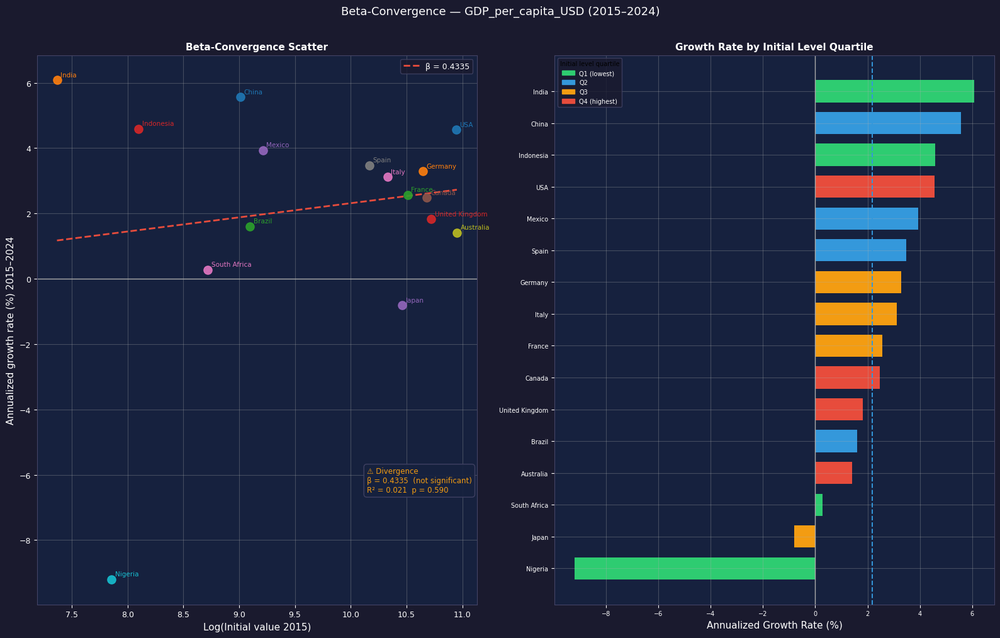

In [215]:
# Scatter plot per pair
for (g1, g2) in combinations(country_groups.keys(), 2):
    countries_pair = country_groups[g1] + country_groups[g2]
    beta_data, beta_results = compute_beta_convergence(df, indicator, countries_pair, start_year, end_year)
    
    if beta_data is not None:        
        plot_beta_convergence(beta_data, indicator, start_year, end_year, filename = f'../Figures/Indicators/K_2_2_{safe_indicator_name(indicator)}_inter_beta_convergence.png',highlight=countries_pair)

**K2.2 Insights**

- Inter-group beta answers the core convergence question: do countries that started lower (Emerging) grow faster than those that started higher (Developed)?
- β < 0 and significant on the combined group → catch-up confirmed: the initial level gap is a predictor of faster growth.
- Compare K2.2 with K1.2 (sigma inter): K1.2 measures whether the gap in levels
  is shrinking; K2.2 tests the mechanism — whether low initial level predicts
  faster growth. The two can diverge when outliers dominate the regression.

**Beta-Convergence Insights**

- A negative and statistically significant β (β < 0 & p < 0.05) → catch-up confirmed: confirms absolute beta-convergence — countries with lower initial levels systematically grew faster, suggesting catch-up dynamics.
- A negative and statistically not significant β (β < 0, p > 0.05) → convergence
  tendency without statistical confirmation — likely present but dataset too small
  to detect it reliably.
- A positive β (β > 0) → divergence: richer countries grow faster, the gap widens.
- `Note on outliers:` beta-convergence regression with small samples (< 20 countries)
  is highly sensitive to outliers — always check which countries drive the result.
- The R² indicates how well the initial level explains growth variation — a low R² means many other factors (institutions, policies, shocks) drive growth differences beyond the starting point.
- The right panel directly shows whether low-quartile countries (green) cluster at the top of the growth ranking — if they do, convergence is visually confirmed even before looking at the regression.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 3. Convergence Summary
</div>

In [216]:
def print_convergence_summary(sigma_df: pd.DataFrame, gap_df: pd.DataFrame, beta_intra: dict, beta_inter: dict, indicator_name: str) -> None:
    """Consolidated convergence verdict across all four levels."""
    
    print("═" * 65)
    print(f"  CONVERGENCE SUMMARY — {indicator_name[:40]}")
    print("═" * 65)

    # K1.1 — Sigma intra
    print("\n  K1.1 — SIGMA INTRA-GROUP (dispersion trend)")
    for _, row in sigma_df.drop_duplicates("group").iterrows():
        d = "↓ Converging" if row["slope"] < 0 else "↑ Diverging"
        print(f"    {row['group']:<20} slope={row['slope']:+.4f}  →  {d}")

    # K1.2 — Sigma inter
    print("\n  K1.2 — SIGMA INTER-GROUP (gap between means)")
    for pair in gap_df["pair"].unique():
        d      = gap_df[gap_df["pair"] == pair]
        change = d["gap_pct_change"].iloc[-1]
        v      = "✅ Converging" if abs(d["gap_abs"].iloc[-1]) < abs(d["gap_abs"].iloc[0]) else "⚠️  Diverging"
        print(f"    {pair:<30} gap change={change:+.1f}%  →  {v}")

    # K2.1 — Beta intra
    print("\n  K2.1 — BETA INTRA-GROUP (initial level vs growth)")
    for group, res in beta_intra.items():
        if res is None:
            print(f"    {group:<20} ⚠️  Insufficient data")
            continue
        sig = "sig" if res["significant"] else "not sig"
        v   = "✅ Converging" if res["verdict"] == "Converging" else "⚠️  Diverging"
        print(f"    {group:<20} β={res['beta']:+.4f} "        f"p={res['pvalue']:.3f}({sig}) R²={res['r2']:.2f}  →  {v}")

    # K2.2 — Beta inter
    print("\n  K2.2 — BETA INTER-GROUP (catch-up dynamics)")
    for pair, res in beta_inter.items():
        if res is None:
            print(f"    {pair:<30} ⚠️  Insufficient data")
            continue
        sig = "sig" if res["significant"] else "not sig"
        v   = "✅ Converging" if res["verdict"] == "Converging" else "⚠️  Diverging"
        print(f"    {pair:<30} β={res['beta']:+.4f} "  f"p={res['pvalue']:.3f}({sig}) R²={res['r2']:.2f}  →  {v}")

    print("═" * 65)

In [217]:
print_convergence_summary(sigma_df, gap_df, beta_intra, beta_inter, indicator)

═════════════════════════════════════════════════════════════════
  CONVERGENCE SUMMARY — GDP per capita (current US$)
═════════════════════════════════════════════════════════════════

  K1.1 — SIGMA INTRA-GROUP (dispersion trend)
    Emerging             slope=+0.0020  →  ↑ Diverging
    Developed            slope=+0.0127  →  ↑ Diverging

  K1.2 — SIGMA INTER-GROUP (gap between means)
    Emerging vs Developed          gap change=-24.7%  →  ⚠️  Diverging

  K2.1 — BETA INTRA-GROUP (initial level vs growth)
    Emerging             β=+1.3516 p=0.697(not sig) R²=0.03  →  ⚠️  Diverging
    Developed            β=+0.2525 p=0.912(not sig) R²=0.00  →  ⚠️  Diverging

  K2.2 — BETA INTER-GROUP (catch-up dynamics)
    Emerging vs Developed          β=+0.4335 p=0.590(not sig) R²=0.02  →  ⚠️  Diverging
═════════════════════════════════════════════════════════════════


**K3 — Convergence Summary Insights**

The four levels are complementary and answer distinct questions:

| Level | Question | Method |
|---|---|---|
| K1.1 | Are countries within the same group becoming more similar? | Sigma — dispersion slope |
| K1.2 | Is the gap between groups shrinking? | Sigma — inter-group means |
| K2.1 | Do laggards within each group catch up with leaders? | Beta intra-group |
| K2.2 | Do Emerging countries catch up with Developed countries? | Beta inter-group |

`Reading the four levels together:`
- K1.1 ↑ + K1.2 ↑ = heterogeneity increasing at both levels → most fragmented scenario
- K1.1 ↓ + K1.2 ↓ = convergence at both levels → most integrated scenario
- K2 β < 0 significant = catch-up mechanism confirmed → convergence is structural

`Reading the combined verdict:`
- All four converging → strong structural convergence on this indicator
- K1 converging + K2 not significant → groups approach each other but the catch-up mechanism is weak
- K2 converging + K1 diverging → growth rates align but absolute dispersion within groups is increasing
- All four diverging → structural inequality on this indicator is widening on every dimension

<div style="background-color: #eaf2f8; padding-left: 20px; border: 1px solid; border-radius: 5px;">

# L. Clustering
</div>

This section groups countries into structural profiles using KMeans clustering.

**Two clustering modes are available:**

| Mode | Input | Question | Use case |
|---|---|---|---|
| **A — Growth features** | `growth_df` features (one indicator) | Which countries share the same growth profile on this indicator? | Single indicator analysis |
| **B — PCA scores** | `scores_df` from J.3 (multi-indicator) | Which countries share the same structural economic position? | Multi-indicator analysis |

**Why clustering on top of growth_score?**
The growth score is **unidimensional** — it ranks countries on a single axis.
Clustering is **multidimensional** — it groups countries by structural similarity across
multiple features simultaneously. Two countries can share the same score but have very
different profiles (high CAGR + high volatility vs moderate CAGR + low volatility).

**Why PCA scores for Mode B?**
PCA components are orthogonal (zero correlation between them) and filter noise
(retaining 80%+ of variance). Clustering on PCA scores avoids the multicollinearity
issue of clustering on correlated raw indicators.

In [218]:
## Clustering mode : 
CLUSTER_MODE = "growth_features"   #  "growth_features" or "pca_scores" 
## Data
indicators = ["GDP per capita (current US$)", "Trade (% of GDP)", "Inflation, consumer prices (annual %)"] # Mode A — multi indicators
indicators = "GDP per capita (current US$)"  #  Mode A — one indicator  
ind_name = "GDP_per_capita"
## Mode A features 
CLUSTER_FEATURES_A = [  "z_cagr",
                        "volatility",
                        "share_under_pressure",
                        "shock_frequency",
                        "mean_abs_z",
                        "asymmetry_index" ]

K_RANGE      = range(3, 9) # range of K values to test
RANDOM_STATE = 42
MIN_OBS      = 7           # minimum observations per entity × indicator

## Countries to highlight in visualizations
countries = ["USA", "China", "Germany", "France", "India", "Brazil", "Japan", "South Korea", "Morocco", "Nigeria", "Egypt, Arab Rep.", "South Africa"]

print(f"🔧 Mode     : {CLUSTER_MODE}")
if CLUSTER_MODE == "growth_features":    print(f"📊 Indicator: {indicator}")
else:    print(f"📊 Input    : PCA scores - Section J.3")

🔧 Mode     : growth_features
📊 Indicator: GDP per capita (current US$)


<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 1. Feature Preparation
</div>

In [219]:
def prepare_cluster_dataset(growth_df: pd.DataFrame, indicators: str | list[str], features: list[str]) -> tuple[pd.DataFrame, list[str]]:
    """    Mode A — prepare clustering dataset from growth_df.
    - One indicator     - Keeps only available features (safe if some are missing)   - Applies log + clip on volatility to reduce skewness    """
    
    df = growth_df.copy()
    # Normalize to list
    if isinstance(indicators, str): indicators = [indicators]
    # Filter indicator & Country entities only
    df = df[df["indicator_name"].isin(indicators)] 
    if "entity_type" in df.columns:  df = df[df["entity_type"] == "COUNTRY"]
    
    # Log + clip volatility (skewed feature)
    if "volatility" in df.columns:
        df["volatility"] = np.log1p(df["volatility"])
        lo = df["volatility"].quantile(0.01)
        hi = df["volatility"].quantile(0.99)
        df["volatility"] = df["volatility"].clip(lo, hi)

    # ── Aggregation — mean per country across indicators ──────────────────
    available = [f for f in features if f in df.columns]
    missing   = [f for f in features if f not in df.columns]
    if missing:   print(f"⚠️  Features not found, skipped : {missing}")

    if len(indicators) > 1:
                            # Average features across indicators → one row per country
                            df = (df.groupby("country_name")[available].mean().reset_index())
                            print(f"  Aggregation : mean across {len(indicators)} indicators")
    else:                   df = df.reset_index(drop=True)

    df = df.dropna(subset=available)

    return df, available

In [220]:
def prepare_pca_cluster_dataset(scores_df: pd.DataFrame, n_components: int | None = None) -> tuple[pd.DataFrame, list[str]]:
    """    Mode B — prepare clustering dataset from PCA scores (Section J.3).
    scores_df index = country_name, columns = PC1, PC2, ...
    n_components: if None, uses all available PCs. Set to n_needed from run_pca() to use only the components that reach 80% variance.
    """
    
    pc_cols = [c for c in scores_df.columns if c.startswith("PC")]
    if n_components:    pc_cols = pc_cols[:n_components]
    df = scores_df[pc_cols].reset_index().dropna(subset = pc_cols)
    df.columns = ["country_name"] + pc_cols

    return df, pc_cols

In [221]:
def prepare_dataset (CLUSTER_MODE:str):
    if CLUSTER_MODE == "growth_features": 
        
        cluster_df, available_features = prepare_cluster_dataset(growth_df, indicators, CLUSTER_FEATURES_A)
        print(f"✅ Mode A — Growth features")
        print(f"   Indicators : {indicators}")
        print(f"   Countries : {cluster_df['country_name'].nunique()}")
        print(f"   Features  : {available_features}")
    
    elif CLUSTER_MODE == "pca_scores":
        cluster_df, available_features = prepare_pca_cluster_dataset(scores_df, n_components=n_needed)
        print(f"✅ Mode B — PCA scores")
        print(f"   Components : {available_features}")
        print(f"   Countries  : {len(cluster_df)}")
    
    else:   raise ValueError(f"CLUSTER_MODE must be 'growth_features' or 'pca_scores'")
        
    return cluster_df, available_features

In [222]:
cluster_df, available_features  = prepare_dataset ("growth_features")

✅ Mode A — Growth features
   Indicators : GDP per capita (current US$)
   Countries : 203
   Features  : ['z_cagr', 'volatility', 'share_under_pressure', 'shock_frequency', 'mean_abs_z', 'asymmetry_index']


In [223]:
# Feature distribution overview 
cluster_df[available_features].describe().T[["mean", "std", "min", "max"]].round(3).style.background_gradient(subset=["std"], cmap="Oranges")

,mean,std,min,max
z_cagr,0.095000,0.333000,-1.176000,1.752000
volatility,0.091000,0.055000,0.021000,0.306000
share_under_pressure,0.115000,0.131000,0.000000,0.556000
shock_frequency,0.036000,0.053000,0.000000,0.125000
mean_abs_z,0.713000,1.033000,0.000000,2.532000
asymmetry_index,-0.079000,0.566000,-1.000000,1.000000


<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 2. Optimal K Selection
</div>

In [224]:
def select_optimal_k(cluster_df: pd.DataFrame, features: list[str], k_range: range = K_RANGE, random_state: int = RANDOM_STATE,
                     figsize: tuple = (14, 5)) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """    Compute inertia (elbow) and silhouette score for a range of K.    Returns (k_values, inertias, silhouettes).    """
    
    X = cluster_df[features].values
    scaler = RobustScaler()
    X_scaled = scaler.fit_transform(X)

    k_vals     = list(k_range)
    inertias   = []
    silhouettes= []

    for k in k_vals:
        km = KMeans(n_clusters=k, random_state=random_state, n_init=20)
        labels = km.fit_predict(X_scaled)
        inertias.append(km.inertia_)
        silhouettes.append(silhouette_score(X_scaled, labels))

    # Plot 
    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=figsize)
    fig.suptitle("Optimal K Selection", fontsize=13, color="white", y=1.01)

    # Elbow
    ax1.plot(k_vals, inertias, color=C["blue"], linewidth=2.3, marker="o", markersize=7)
    ax1.set_xlabel("Number of clusters (K)", color="white")
    ax1.set_ylabel("Inertia (within-cluster sum of squares)", color="white")
    ax1.set_title("Elbow Method", fontsize=11, color="white")
    ax1.set_xticks(k_vals)

   # Silhouette
    best_k = k_vals[np.argmax(silhouettes)]
    bar_colors = [C["green"] if k == best_k else C["blue"] for k in k_vals]
    ax2.bar(k_vals, silhouettes, color=bar_colors, edgecolor="none", width=0.6)
    for k, s in zip(k_vals, silhouettes): ax2.text(k, s + 0.005, f"{s:.3f}", ha="center", fontsize=8.5, color="white")
    ax2.set_xlabel("Number of clusters (K)", color="white")
    ax2.set_ylabel("Silhouette Score", color="white")
    ax2.set_title("Silhouette Score (higher = better)", fontsize=11, color="white")
    ax2.set_xticks(k_vals)

    plt.tight_layout()
    save_figure(fig, '../Figures/Indicators/L_2_best_K.png')
    plt.show()

    print(f"\n📐 Best K by silhouette : {best_k}  "  f"(score = {max(silhouettes):.3f})")
    print(f"   → Update FINAL_K = {best_k} if consistent with elbow")

    return np.array(k_vals), np.array(inertias), np.array(silhouettes), best_k

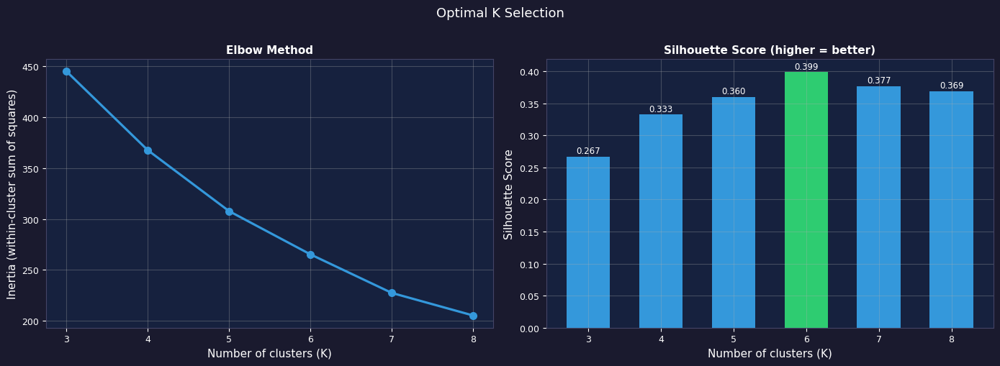


📐 Best K by silhouette : 6  (score = 0.399)
   → Update FINAL_K = 6 if consistent with elbow


In [225]:
k_vals, inertias, silhouettes, FINAL_K = select_optimal_k(cluster_df, available_features)

**K Selection Insights**

- The elbow point is where marginal inertia reduction flattens — adding more clusters beyond this point yields diminishing structural separation.
- The silhouette score penalizes both poor separation and poor cohesion — the peak value indicates the K that best balances both.
- When elbow and silhouette disagree, favor interpretability: fewer clusters with clearer economic labels are more valuable for a portfolio analysis.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 3. KMeans Model & Diagnostics
</div>

In [226]:
def train_kmeans(cluster_df: pd.DataFrame, features: list[str], n_clusters: int = FINAL_K, 
                 random_state: int = RANDOM_STATE) -> tuple[pd.DataFrame, KMeans, RobustScaler, np.ndarray]:
    """    Train KMeans on scaled features.  Returns (cluster_df with labels, model, scaler, X_scaled)    """
    
    df     = cluster_df.copy()
    scaler = RobustScaler()
    X      = scaler.fit_transform(df[features].values)

    kmeans = KMeans(n_clusters=n_clusters, random_state=random_state, n_init=50)
    df["cluster_id"] = kmeans.fit_predict(X)

    return df, kmeans, scaler, X

In [227]:
cluster_df, kmeans, scaler, X_scaled = train_kmeans(cluster_df, available_features, n_clusters=FINAL_K)
print(f"✅ KMeans trained — K = {FINAL_K}  |  Mode = {CLUSTER_MODE}\n")

✅ KMeans trained — K = 6  |  Mode = growth_features



In [228]:
def run_diagnostics(cluster_df: pd.DataFrame, X_scaled: np.ndarray, features: list[str]) -> None:
    """   Print cluster size, silhouette, and feature balance diagnostics   """
    
    labels = cluster_df["cluster_id"].values

    # Sizes
    sizes = cluster_df["cluster_id"].value_counts().sort_index()
    print("📊 Cluster sizes")
    for cid, n in sizes.items():
        pct = n / len(cluster_df) * 100
        print(f"   Cluster {cid} : {n:>4} rows  ({pct:.1f}%)")

    # Silhouette
    score = silhouette_score(X_scaled, labels)
    verdict = (
                "⚠️  Poor separation" if score < 0.15
                else "🟡 Moderate structure" if score < 0.35
                else "🟢 Good structure"
               )
    print(f"\n📐 Silhouette Score : {score:.3f}  →  {verdict}")

    # Feature balance
    stds = pd.DataFrame(X_scaled, columns=features).std().sort_values(ascending=False)
    dominant = stds.max() > 3 * stds.median()
    balance  = "⚠️  One feature dominates" if dominant else "🟢 Well-balanced feature space"
    print(f"\n⚖️  Feature balance : {balance}")
    print(stds.round(3).to_string())

In [229]:
run_diagnostics(cluster_df, X_scaled, available_features)

📊 Cluster sizes
   Cluster 0 :   84 rows  (41.4%)
   Cluster 1 :   10 rows  (4.9%)
   Cluster 2 :   21 rows  (10.3%)
   Cluster 3 :   38 rows  (18.7%)
   Cluster 4 :   34 rows  (16.7%)
   Cluster 5 :   16 rows  (7.9%)

📐 Silhouette Score : 0.400  →  🟢 Good structure

⚖️  Feature balance : 🟢 Well-balanced feature space
z_cagr                 1.1170
share_under_pressure   1.1090
volatility             1.0870
asymmetry_index        0.5660
mean_abs_z             0.5010
shock_frequency        0.4730


In [230]:
# Check selected countries assignment 
cols = ["country_name", "cluster_id"] + available_features[:3]
cluster_df[cluster_df["country_name"].isin(countries)][cols].sort_values("cluster_id").style.background_gradient(subset=["cluster_id"], cmap="tab10")

,country_name,cluster_id,z_cagr,volatility,share_under_pressure
62,France,0,0.009857,0.058046,0.000000
49,Germany,0,0.080972,0.048711,0.000000
114,Morocco,0,0.065687,0.076894,0.111111
85,India,0,0.355918,0.067937,0.000000
194,USA,0,0.206481,0.036334,0.000000
135,Nigeria,1,-1.148977,0.252938,0.555556
94,Japan,3,-0.322680,0.069153,0.111111
26,Brazil,4,-0.085026,0.118176,0.222222
202,South Africa,4,-0.215333,0.115428,0.333333
35,China,5,0.304448,0.068745,0.000000


<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 4. Cluster Profiles
</div>

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">

### 4.1 Profiles
</div>

In [231]:
def plot_cluster_profiles(cluster_df: pd.DataFrame, features: list[str], file_name : str, figsize: tuple = (14, 5)) -> pd.DataFrame:
    """    heatmap of mean feature values per cluster  —   bar chart of cluster sizes.    Returns the profile DataFrame    """

    profile = cluster_df.groupby("cluster_id")[features].mean().round(3)
    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=figsize)
    fig.suptitle("Cluster Profiles — Mean Feature Values", fontsize=13, color="white", y=1.01)

    # Heatmap
    sns.heatmap(profile.T, ax=ax1, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 8, "color": "black"},
                linewidths=0.4, linecolor=C["bg"], cbar_kws={"shrink": 0.7})
    ax1.set_title("Feature Heatmap", fontsize=11, color="white")
    ax1.tick_params(colors="white", labelsize=8)
    ax1.set_xlabel("Cluster", color="white")
    ax1.set_ylabel("", color="white")

    cbar = ax1.collections[0].colorbar
    cbar.ax.yaxis.label.set_color("white")
    cbar.ax.tick_params(colors="white")

    # Cluster sizes 
    sizes  = cluster_df["cluster_id"].value_counts().sort_index()
    colors = plt.cm.tab10.colors
    bars   = ax2.bar([f"C{i}" for i in sizes.index], sizes.values,  color=[colors[i % 10] for i in sizes.index], edgecolor="none", width=0.6)
    for bar, n in zip(bars, sizes.values): ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3, str(n), ha="center", color="white", fontsize=9)
    ax2.set_title("Cluster Sizes", fontsize=11, color="white")
    ax2.set_ylabel("Count", color="white")

    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/file_name')
    plt.show()
    return profile

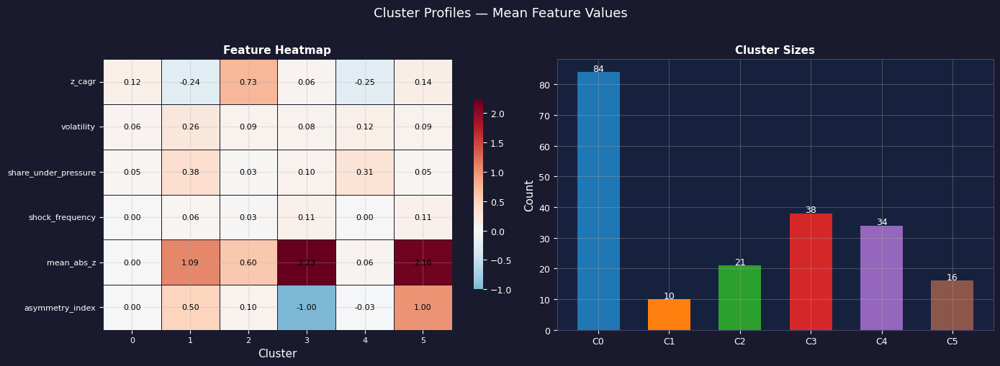

,z_cagr,volatility,share_under_pressure,shock_frequency,mean_abs_z,asymmetry_index
cluster_id,,,,,,
0,0.1230,0.0630,0.0470,0.0000,0.0000,0.0000
1,-0.2440,0.2600,0.3830,0.0560,1.0930,0.5000
2,0.7290,0.0890,0.0260,0.0320,0.5990,0.0950
3,0.0610,0.0830,0.0970,0.1120,2.2280,-1.0000
4,-0.2470,0.1250,0.3100,0.0040,0.0610,-0.0290
5,0.1360,0.0880,0.0490,0.1120,2.1560,1.0000


In [232]:
indicator_name = cluster_df["indicator_name"].unique()[0]
file_name = f'../Figures/Indicators/L_4_cluster_profiles_{safe_indicator_name(indicator_name)}.png'
profile = plot_cluster_profiles(cluster_df, available_features, file_name)
profile

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">

### 4.2 Insights
</div>

In [233]:
# Cluster naming - mode A
CLUSTER_NAMES = {   0: "Positive shock-driven growth",
                    1: "Structural stagnation",
                    2: "High growth leaders",
                    3: "Neutral — low dynamics",
                    4: "Negative shock-exposed",
                    5: "Steady & stable growers",
                    6: "Under pressure — volatile"}

def print_cluster_insight(profile: pd.DataFrame, cluster_names: dict[int, str]) -> None:
    """   
        1. Profile table with cluster names
        2. Analytically interesting patterns
        3. Named cluster summary
    """
    features = list(profile.columns)

    # Profile table with names
    print("═" * 70)
    print("  1. CLUSTER PROFILES")
    print("═" * 70)

    profile_named = profile.copy()
    profile_named.insert(0, "name", [cluster_names.get(i, f"Cluster {i}") for i in profile_named.index])
    display(profile_named)

    # 2. Analytically interesting patterns
    print(f"\n{'═' * 70}")
    print("  2. ANALYTICAL INSIGHTS")
    print("═" * 70)

    # Best cluster — highest z_cagr + lowest volatility
    if "z_cagr" in features and "volatility" in features:
        best = (profile["z_cagr"] - profile["volatility"]).idxmax()
        print(f"  Best growth profile    : Cluster {best} "  f"({cluster_names.get(best, '')}) " f"— highest CAGR with lowest volatility")

    # Most fragile — lowest z_cagr + highest share_under_pressure
    if "z_cagr" in features and "share_under_pressure" in features:
        fragile = (profile["share_under_pressure"] - profile["z_cagr"]).idxmax()
        print(f"  Most fragile           : Cluster {fragile} "  f"({cluster_names.get(fragile, '')}) "  f"— highest pressure + lowest CAGR")

    # Mirror clusters — same features, opposite asymmetry
    if "asymmetry_index" in features:
        pos_shock = profile["asymmetry_index"].idxmax()
        neg_shock = profile["asymmetry_index"].idxmin()
        if abs(profile.loc[pos_shock, "asymmetry_index"]) > 0.5 and abs(profile.loc[neg_shock, "asymmetry_index"]) > 0.5:
            print(
                    f"  Mirror clusters        : Cluster {pos_shock} vs Cluster {neg_shock} "
                    f"— same shock intensity, opposite direction\n"
                    f"    C{pos_shock} = {cluster_names.get(pos_shock, '')} "
                    f"(asymmetry = {profile.loc[pos_shock, 'asymmetry_index']:+.3f})\n"
                    f"    C{neg_shock} = {cluster_names.get(neg_shock, '')} "
                    f"(asymmetry = {profile.loc[neg_shock, 'asymmetry_index']:+.3f})"
                 )

    # Most volatile
    if "volatility" in features:
        most_vol = profile["volatility"].idxmax()
        print(f"  Most volatile          : Cluster {most_vol} " f"({cluster_names.get(most_vol, '')}) " 
              f"— volatility = {profile.loc[most_vol, 'volatility']:.3f}")

    # Neutral cluster — all features close to zero
    neutral_score = profile[features].abs().mean(axis=1)
    neutral = neutral_score.idxmin()
    print(f"  Most neutral           : Cluster {neutral} "  f"({cluster_names.get(neutral, '')}) "  f"— all features close to zero")

    # Perfect regularity — zero pressure AND zero shocks AND zero mean_abs_z
    zero_cols = [f for f in ["share_under_pressure", "shock_frequency", "mean_abs_z", "asymmetry_index"] if f in features]
    if zero_cols:
        # Score = nombre de features à zéro strict
        zero_count = (profile[zero_cols].abs() < 0.001).sum(axis=1)
        perfect = zero_count.idxmax()
        if zero_count[perfect] >= 3 and profile.loc[perfect, "z_cagr"] > 0:
            print(
                  f"  Perfect regularity     : Cluster {perfect} "  f"({cluster_names.get(perfect, '')}) "
                  f"— CAGR = {profile.loc[perfect, 'z_cagr']:+.3f}, "      f"zero pressure, zero shocks across all dimensions "
                  f"— most consistent growth profile"
                )
        
    # 3. Named cluster summary 
    print(f"\n{'═' * 70}")
    print("  3. CLUSTER NAMES")
    print("═" * 70)

    sizes = cluster_df["cluster_id"].value_counts().sort_index()

    for cid, name in cluster_names.items():
        n   = sizes.get(cid, 0)
        pct = n / len(cluster_df) * 100
        # Dominant features for this cluster
        if cid in profile.index:
            row      = profile.loc[cid]
            dominant = row.abs().nlargest(2).index.tolist()
            dom_str  = " + ".join(dominant)
        else:            dom_str = ""
        
        print(f"  Cluster {cid} : {name:<35} "   f"n={n:>4} ({pct:.1f}%)  [{dom_str}]")

    print("═" * 70)

In [234]:
print_cluster_insight(profile, CLUSTER_NAMES)

══════════════════════════════════════════════════════════════════════
  1. CLUSTER PROFILES
══════════════════════════════════════════════════════════════════════


,name,z_cagr,volatility,share_under_pressure,shock_frequency,mean_abs_z,asymmetry_index
cluster_id,,,,,,,
0,Positive shock-driven growth,0.1230,0.0630,0.0470,0.0000,0.0000,0.0000
1,Structural stagnation,-0.2440,0.2600,0.3830,0.0560,1.0930,0.5000
2,High growth leaders,0.7290,0.0890,0.0260,0.0320,0.5990,0.0950
3,Neutral — low dynamics,0.0610,0.0830,0.0970,0.1120,2.2280,-1.0000
4,Negative shock-exposed,-0.2470,0.1250,0.3100,0.0040,0.0610,-0.0290
5,Steady & stable growers,0.1360,0.0880,0.0490,0.1120,2.1560,1.0000



══════════════════════════════════════════════════════════════════════
  2. ANALYTICAL INSIGHTS
══════════════════════════════════════════════════════════════════════
  Best growth profile    : Cluster 2 (High growth leaders) — highest CAGR with lowest volatility
  Most fragile           : Cluster 1 (Structural stagnation) — highest pressure + lowest CAGR
  Mirror clusters        : Cluster 5 vs Cluster 3 — same shock intensity, opposite direction
    C5 = Steady & stable growers (asymmetry = +1.000)
    C3 = Neutral — low dynamics (asymmetry = -1.000)
  Most volatile          : Cluster 1 (Structural stagnation) — volatility = 0.260
  Most neutral           : Cluster 0 (Positive shock-driven growth) — all features close to zero
  Perfect regularity     : Cluster 0 (Positive shock-driven growth) — CAGR = +0.123, zero pressure, zero shocks across all dimensions — most consistent growth profile

══════════════════════════════════════════════════════════════════════
  3. CLUSTER NAMES
════

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">

### 4.3 Radar
</div>

In [235]:
def plot_cluster_radar(profile: pd.DataFrame, cluster_id: int, filename : str, figsize: tuple = (6, 6),) -> None:
    """     Radar chart for one cluster's mean feature profile    """
    
    if cluster_id not in profile.index:
        print(f"⚠️  Cluster {cluster_id} not found")
        return
    
    vals   = profile.loc[cluster_id].values.astype(float)
    labels = list(profile.columns)

    # Normalize to [0,1] across all clusters for radar readability
    v_min = profile.values.min()
    v_max = profile.values.max()
    vals_norm = (vals - v_min) / (v_max - v_min + 1e-9)

    angles    = np.linspace(0, 2 * np.pi, len(labels), endpoint=False)
    vals_plot = np.append(vals_norm, vals_norm[0])
    angles_p  = np.append(angles, angles[0])
    color     = plt.cm.tab10.colors[cluster_id % 10]

    fig, ax = plt.subplots(figsize=figsize, subplot_kw=dict(polar=True))
    fig.patch.set_facecolor(C["bg"])
    ax.set_facecolor(C["ax_bg"])

    ax.plot(angles_p, vals_plot, color=color, linewidth=2.2)
    ax.fill(angles_p, vals_plot, color=color, alpha=0.25)
    ax.set_thetagrids(np.degrees(angles), labels, fontsize=8.5, color="white")
    ax.tick_params(colors="white", labelsize=7)
    ax.spines["polar"].set_edgecolor(C["spine"])
    ax.set_title(f"Cluster {cluster_id} — Profile", fontsize=10, color="white", pad=20)
    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/L_4_cluster_radar_cluster_{cluster_id}_{safe_indicator_name(indicator_name)}.png')
    plt.show()

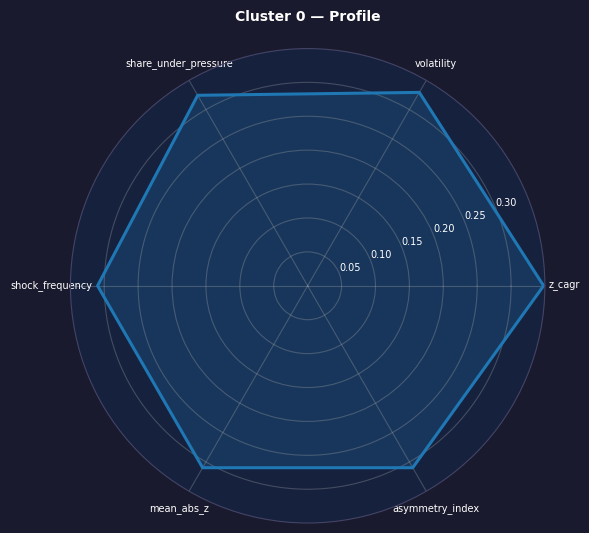

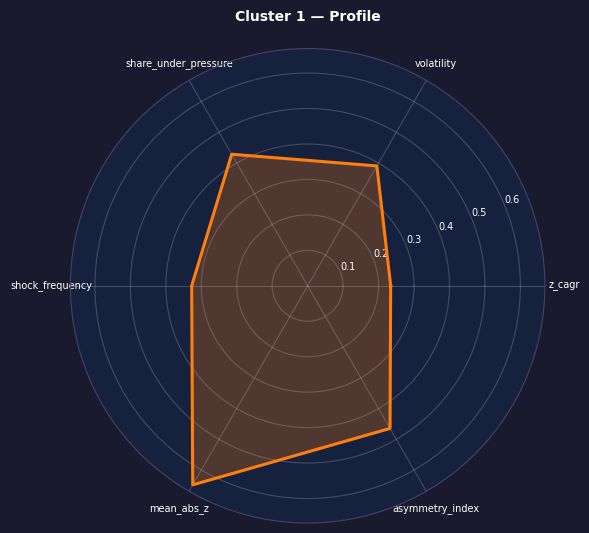

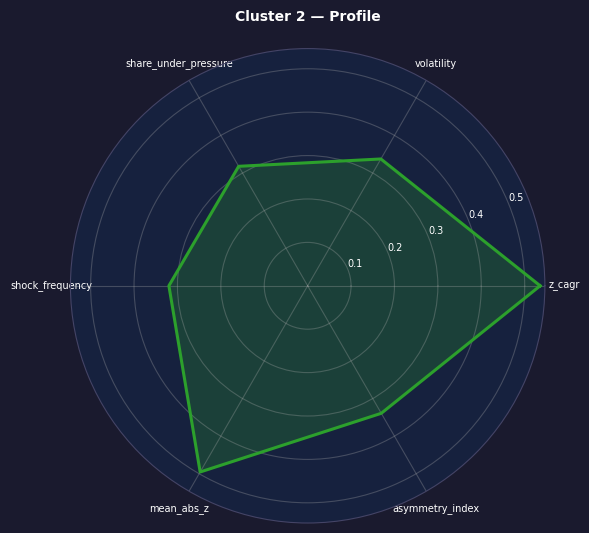

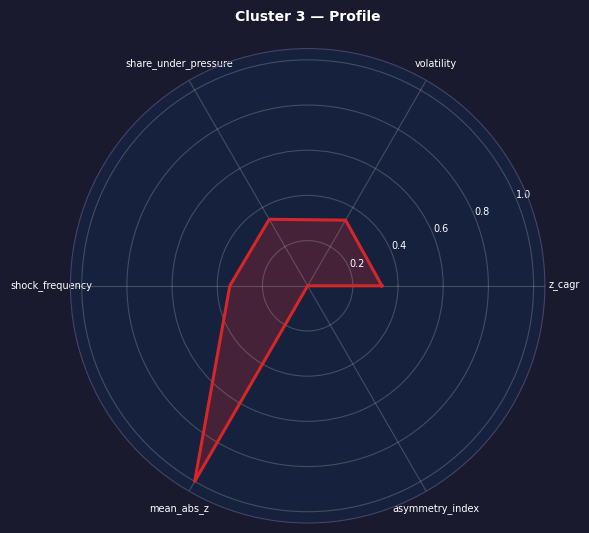

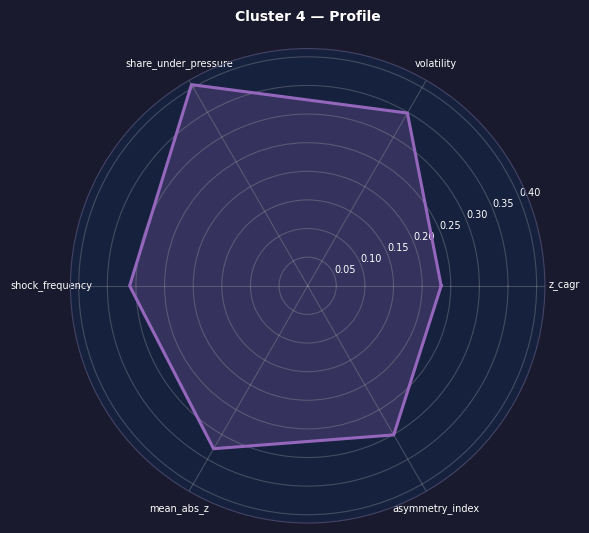

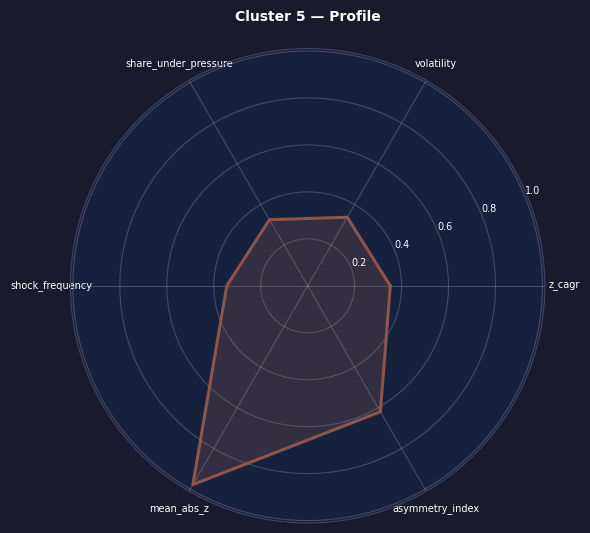

In [236]:
# Radar chart per cluster
for cid in range(FINAL_K): 
    indicator_name = cluster_df["indicator_name"].unique()[0]
    filename = f'../Figures/Indicators/L_4_cluster_radar_cluster_{cid}_{safe_indicator_name(indicator_name)}.png'
    plot_cluster_radar(profile, cid, filename)

**Profile Insights**

- The heatmap is the primary interpretation tool — clusters with high z_cagr + low volatility are growth leaders; high shock_frequency + negative shock_balance are fragile economies.
- Radar charts make each cluster's structural fingerprint immediately readable — useful for naming clusters (e.g., "Stable Growers", "Volatile Emerging", "Stagnant").
- Unbalanced cluster sizes (one very large, others small) may indicate K is too high or the data has outlier-driven clusters — adjust FINAL_K if needed.ded.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">

### 4.4 Save Table
</div>

In [237]:
indicator_name = cluster_df["indicator_name"].unique()[0]
cluster_df.to_csv(f'../Analysis_files/Indicators/{safe_indicator_name(indicator_name)}_cluster_df.csv', index=False)

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## L5. Multi Indicators Clustering
</div>

In [238]:
indicators = ["GDP per capita (current US$)", "Trade (% of GDP)", "Inflation, consumer prices (annual %)"]

In [239]:
cluster_df_multi, available_features_multi  = prepare_dataset ("growth_features")

  Aggregation : mean across 3 indicators
✅ Mode A — Growth features
   Indicators : ['GDP per capita (current US$)', 'Trade (% of GDP)', 'Inflation, consumer prices (annual %)']
   Countries : 204
   Features  : ['z_cagr', 'volatility', 'share_under_pressure', 'shock_frequency', 'mean_abs_z', 'asymmetry_index']


In [240]:
# Feature distribution overview 
cluster_df_multi[available_features_multi].describe().T[["mean", "std", "min", "max"]].round(3).style.background_gradient(subset=["std"], cmap="Oranges")

,mean,std,min,max
z_cagr,0.242000,0.598000,-1.334000,2.818000
volatility,0.406000,0.294000,0.044000,2.613000
share_under_pressure,0.279000,0.095000,0.000000,0.667000
shock_frequency,0.041000,0.032000,0.000000,0.122000
mean_abs_z,0.831000,0.635000,0.000000,2.403000
asymmetry_index,0.078000,0.363000,-1.000000,1.000000


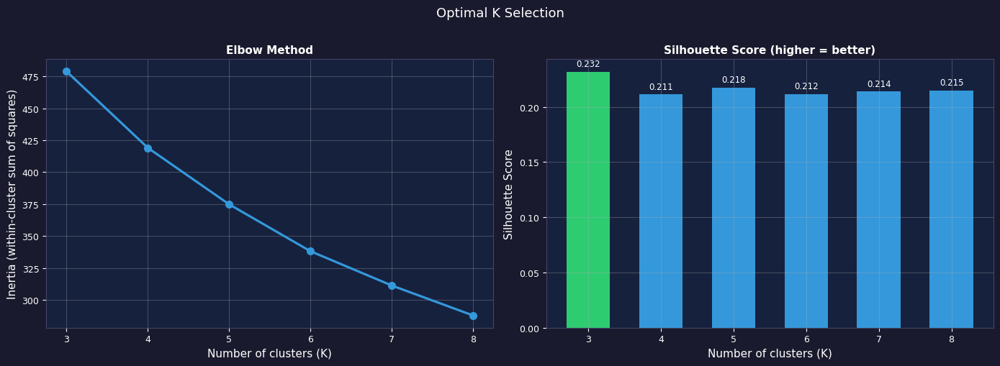


📐 Best K by silhouette : 3  (score = 0.232)
   → Update FINAL_K = 3 if consistent with elbow


In [241]:
k_vals_multi, inertias_multi, silhouettes_multi, FINAL_K_multi = select_optimal_k(cluster_df_multi, available_features_multi)

In [242]:
cluster_df_multi, kmeans_multi, scaler_multi, X_scaled_multi = train_kmeans(cluster_df_multi, available_features_multi, n_clusters=FINAL_K_multi)
print(f"✅ KMeans trained — K = {FINAL_K_multi}  |  Mode = {CLUSTER_MODE}\n")

✅ KMeans trained — K = 3  |  Mode = growth_features



In [243]:
run_diagnostics(cluster_df_multi, X_scaled_multi, available_features_multi)

📊 Cluster sizes
   Cluster 0 :   85 rows  (41.7%)
   Cluster 1 :   37 rows  (18.1%)
   Cluster 2 :   82 rows  (40.2%)

📐 Silhouette Score : 0.232  →  🟡 Moderate structure

⚖️  Feature balance : 🟢 Well-balanced feature space
asymmetry_index        1.0880
volatility             0.9060
share_under_pressure   0.8510
z_cagr                 0.7620
mean_abs_z             0.4700
shock_frequency        0.4250


In [244]:
# Check selected countries assignment 
cols_multi = ["country_name", "cluster_id"] + available_features_multi[:3]
cluster_df_multi[cluster_df_multi["country_name"].isin(countries)][cols_multi].sort_values("cluster_id").style.background_gradient(subset=["cluster_id"], cmap="tab10")

,country_name,cluster_id,z_cagr,volatility,share_under_pressure
170,South Africa,0,-0.216055,0.157518,0.333333
95,Japan,1,0.313765,0.676236,0.333333
68,France,2,1.689546,0.413657,0.185185
26,Brazil,2,-0.341729,0.236163,0.259259
73,Germany,2,0.457218,0.719076,0.222222
87,India,2,-0.016732,0.151096,0.222222
122,Morocco,2,-0.185992,0.367454,0.259259
39,China,2,-0.694835,0.188447,0.185185
134,Nigeria,2,0.072494,0.251727,0.333333
191,USA,2,1.281631,0.515999,0.222222


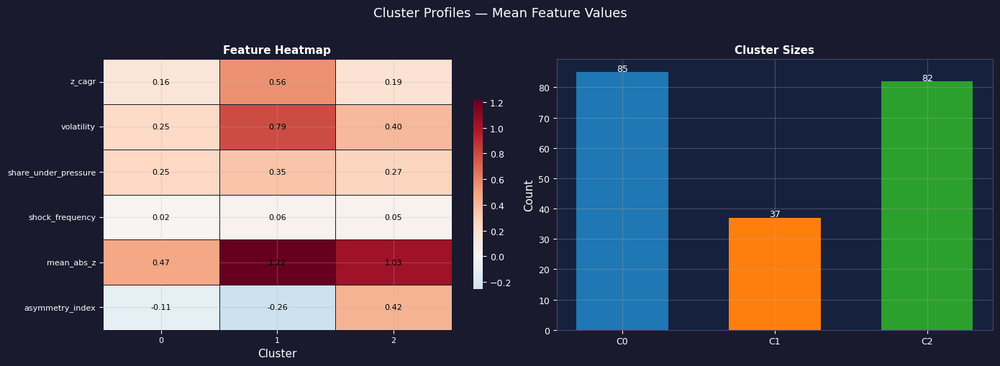

,z_cagr,volatility,share_under_pressure,shock_frequency,mean_abs_z,asymmetry_index
cluster_id,,,,,,
0,0.1600,0.2470,0.2510,0.0240,0.4690,-0.1100
1,0.5570,0.7940,0.3530,0.0580,1.2170,-0.2570
2,0.1860,0.3950,0.2730,0.0510,1.0320,0.4250


In [245]:
file_name = '../Figures/Indicators/L_5_cluster_profiles_multi_indicators.png'
profile_multi = plot_cluster_profiles(cluster_df_multi, available_features_multi, file_name)
profile_multi

In [246]:
print_cluster_insight(profile_multi, CLUSTER_NAMES)

══════════════════════════════════════════════════════════════════════
  1. CLUSTER PROFILES
══════════════════════════════════════════════════════════════════════


,name,z_cagr,volatility,share_under_pressure,shock_frequency,mean_abs_z,asymmetry_index
cluster_id,,,,,,,
0,Positive shock-driven growth,0.1600,0.2470,0.2510,0.0240,0.4690,-0.1100
1,Structural stagnation,0.5570,0.7940,0.3530,0.0580,1.2170,-0.2570
2,High growth leaders,0.1860,0.3950,0.2730,0.0510,1.0320,0.4250



══════════════════════════════════════════════════════════════════════
  2. ANALYTICAL INSIGHTS
══════════════════════════════════════════════════════════════════════
  Best growth profile    : Cluster 0 (Positive shock-driven growth) — highest CAGR with lowest volatility
  Most fragile           : Cluster 0 (Positive shock-driven growth) — highest pressure + lowest CAGR
  Most volatile          : Cluster 1 (Structural stagnation) — volatility = 0.794
  Most neutral           : Cluster 0 (Positive shock-driven growth) — all features close to zero

══════════════════════════════════════════════════════════════════════
  3. CLUSTER NAMES
══════════════════════════════════════════════════════════════════════
  Cluster 0 : Positive shock-driven growth        n=  84 (41.4%)  [mean_abs_z + share_under_pressure]
  Cluster 1 : Structural stagnation               n=  10 (4.9%)  [mean_abs_z + volatility]
  Cluster 2 : High growth leaders                 n=  21 (10.3%)  [mean_abs_z + asymmetry_i

In [247]:
cluster_df_multi.to_csv('../Analysis_files/Indicators/cluster_df_multi.csv', index=False)

ℹ️  Multi-indicator note :
- The average of the features across three indicators mitigates the differences between indicators—countries with a 
high z_cagr on GDP/capitalization often also have a high z_cagr on trade and inflation (a structural correlation confirmed by J.2). 
- The average profile converges toward the same result — confirming that
  structural growth patterns are consistent across indicators rather than
  indicator-specific artifacts.
- result confirms structural consistency — a country's growth profile is coherent

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## L6. Mode PCA
</div>

In [248]:
cluster_df_PCA, available_features_PCA  = prepare_dataset ("pca_scores")

✅ Mode B — PCA scores
   Components : ['PC1', 'PC2', 'PC3', 'PC4']
   Countries  : 209


In [249]:
# Feature distribution overview 
cluster_df_PCA[available_features_PCA].describe().T[["mean", "std", "min", "max"]].round(3).style.background_gradient(subset=["std"], cmap="Oranges")

,mean,std,min,max
PC1,-0.000000,1.426000,-6.816000,5.844000
PC2,0.000000,1.256000,-10.386000,4.281000
PC3,-0.000000,1.053000,-2.079000,3.585000
PC4,-0.000000,0.881000,-2.965000,3.833000


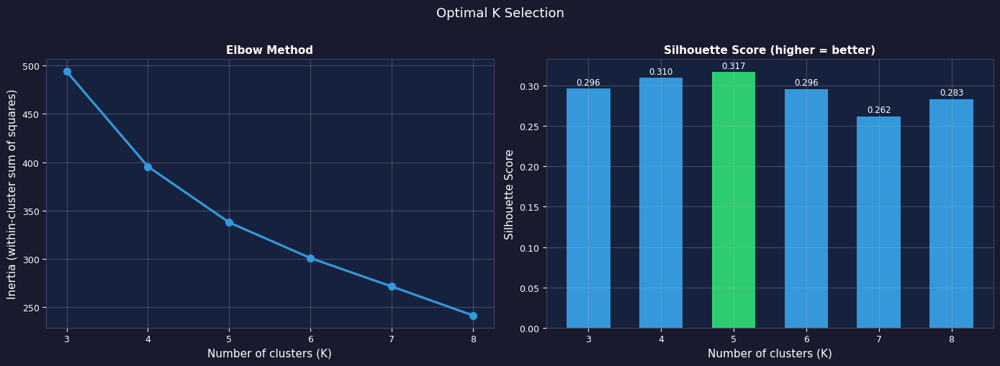


📐 Best K by silhouette : 5  (score = 0.317)
   → Update FINAL_K = 5 if consistent with elbow


In [250]:
k_vals_PCA, inertias_PCA, silhouettes_PCA, FINAL_K_PCA = select_optimal_k(cluster_df_PCA, available_features_PCA)

In [251]:
cluster_df_PCA, kmeans_PCA, scaler_PCA, X_scaled_PCA = train_kmeans(cluster_df_PCA, available_features_PCA, n_clusters=FINAL_K_PCA)
print(f"✅ KMeans trained — K = {FINAL_K_PCA}  |  Mode = pca_scores  \n")

✅ KMeans trained — K = 5  |  Mode = pca_scores  



In [252]:
run_diagnostics(cluster_df_PCA, X_scaled_PCA, available_features_PCA)

📊 Cluster sizes
   Cluster 0 :  120 rows  (57.4%)
   Cluster 1 :   30 rows  (14.4%)
   Cluster 2 :   23 rows  (11.0%)
   Cluster 3 :   33 rows  (15.8%)
   Cluster 4 :    3 rows  (1.4%)

📐 Silhouette Score : 0.317  →  🟡 Moderate structure

⚖️  Feature balance : 🟢 Well-balanced feature space
PC2   1.2940
PC1   0.9590
PC4   0.9060
PC3   0.8230


In [253]:
# Check selected countries assignment 
cols_PCA = ["country_name", "cluster_id"] + available_features_PCA[:3]
cluster_df_PCA[cluster_df_PCA["country_name"].isin(countries)][cols_PCA].sort_values("cluster_id").style.background_gradient(subset=["cluster_id"], cmap="tab10")

,country_name,cluster_id,PC1,PC2,PC3
27,Brazil,0,0.114535,2.348136,0.679336
40,China,0,-0.273839,0.146085,-0.683472
99,Japan,0,0.236558,-0.319210,-1.527116
91,India,0,-0.941677,0.578750,-0.799658
126,Morocco,0,-0.405676,0.423702,0.307919
138,Nigeria,0,-0.498336,-0.402164,-0.490443
195,USA,0,0.630296,-0.475935,-1.012742
174,South Africa,1,-0.796975,0.268055,3.584571
76,Germany,2,1.430252,-0.566552,-0.871545
71,France,3,1.177257,-0.486087,0.992589


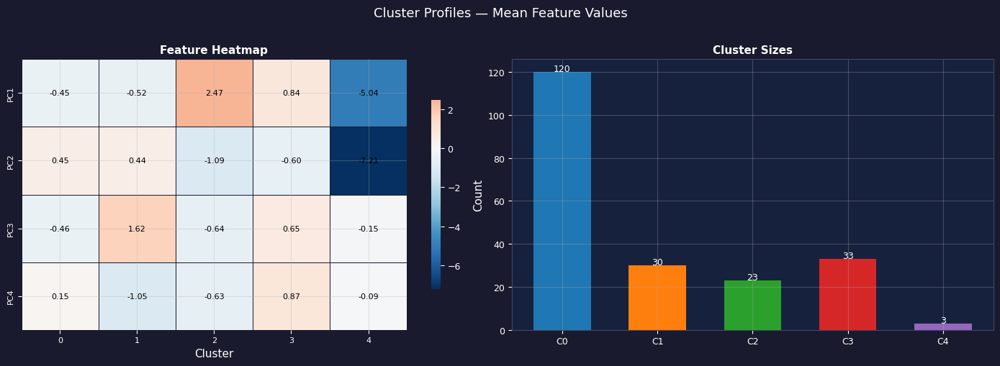

,PC1,PC2,PC3,PC4
cluster_id,,,,
0,-0.4470,0.4450,-0.4570,0.1460
1,-0.5230,0.4360,1.6240,-1.0510
2,2.4700,-1.0910,-0.6440,-0.6300
3,0.8370,-0.6000,0.6470,0.8720
4,-5.0430,-7.2080,-0.1460,-0.0880


In [254]:
file_name = '../Figures/Indicators/L_6_cluster_profiles_pca.png'
profile_PCA = plot_cluster_profiles(cluster_df_PCA, available_features_PCA, file_name)
profile_PCA

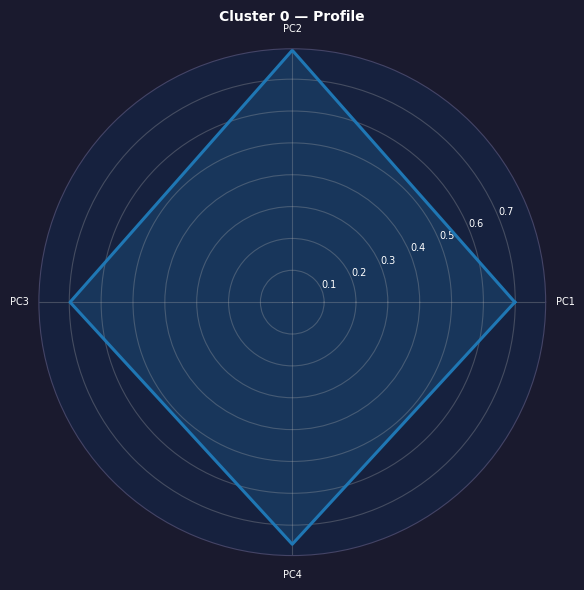

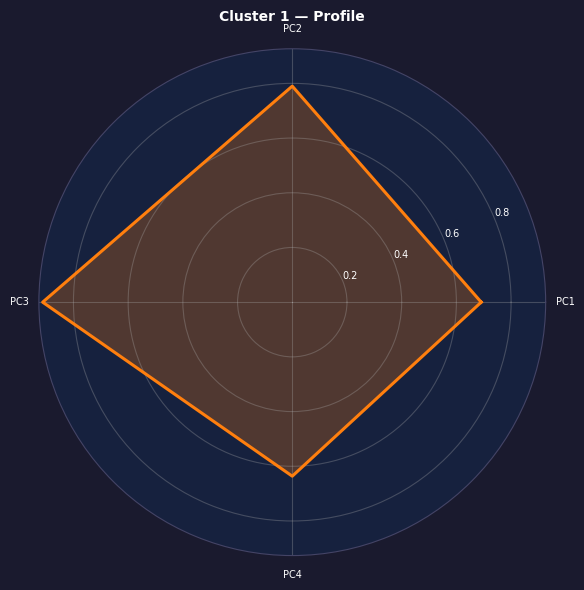

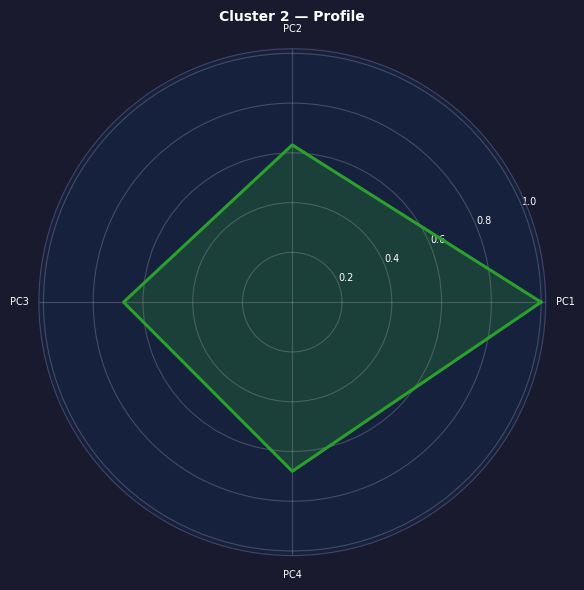

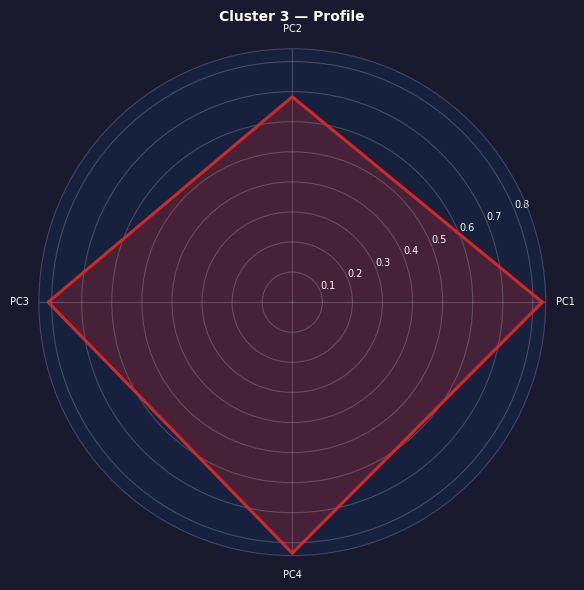

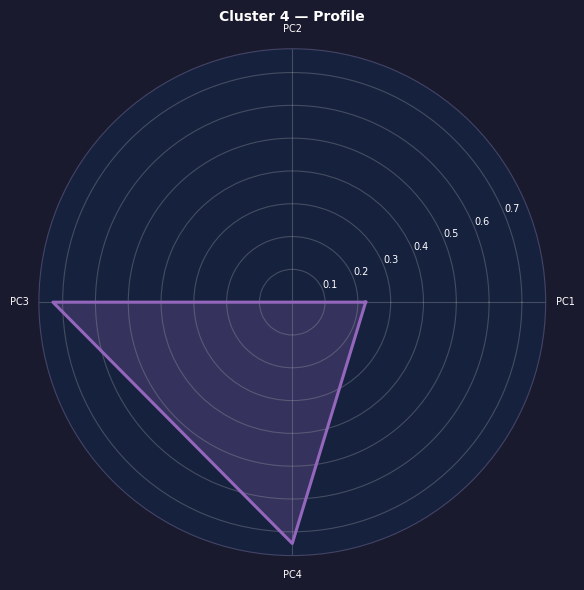

In [255]:
# Radar chart per cluster
for cid in range(FINAL_K_PCA):  
    filename = f'../Figures/Indicators/L_6_cluster_radar_cluster_{cid}_pca.png'
    plot_cluster_radar(profile_PCA, cid, filename)

ℹ️ Mode PCA
- Silhouette is lower than Mode A (growth features) — expected.
- PCA scores compress multi-indicator information into a reduced space, smoothing out structural differences between countries
- The clustering structure is less sharp in PCA space than in the original growth feature space
- → Mode A recommended when a single indicator is the focus.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## L7. Cluster Visualization
</div>

**Mode A — Growth features:**
A 2D PCA is applied on the clustering features for visualization only (2D projection).
This PCA is distinct from Section J.3 — it operates on growth features (z_cagr, volatility, shock_frequency...), not on economic indicators (GDP, Inflation, Trade...).

**Mode B — PCA scores:**
No additional PCA needed — the axes (X_scaled columns) are already PC1 and PC2 from Section J.3.
The biplot is directly interpretable in terms of the economic indicator structure.

In [256]:
def plot_cluster_biplot(cluster_df: pd.DataFrame, X_scaled: np.ndarray, features: list[str], highlight: list[str] | None = None,  
                        cluster_mode: str = "growth_features", figsize: tuple = (12, 8)) -> None:
    """    Single biplot — all countries colored by cluster.    Highlighted countries annotated on top    """
    
    from sklearn.decomposition import PCA as _PCA
    tab_colors = plt.cm.tab10.colors
    highlight  = highlight or []

    # 2D coordinates
    if cluster_mode == "pca_scores":
        # Already in PCA space — use first two columns directly
        coords = X_scaled[:, :2]
        pc_cols = features[:2]
        xlabel  = pc_cols[0] if len(pc_cols) > 0 else "PC1"
        ylabel  = pc_cols[1] if len(pc_cols) > 1 else "PC2"
        title_note = "(PCA space from Section J.3 — economic indicators)"
    else:
        # Apply PCA on growth features for visualization
        pca_vis = _PCA(n_components=2, random_state=RANDOM_STATE)
        coords  = pca_vis.fit_transform(X_scaled)
        var     = pca_vis.explained_variance_ratio_
        xlabel  = f"PC1 ({var[0]*100:.1f}% of variance)"
        ylabel  = f"PC2 ({var[1]*100:.1f}% of variance)"
        title_note = "(PCA on growth features — for visualization only)"

    df_plot = cluster_df[["country_name", "cluster_id"]].copy()
    df_plot["x"] = coords[:, 0]
    df_plot["y"] = coords[:, 1]

    fig, ax = styled_figure(figsize=figsize)
    ax.set_title(f"Cluster Biplot — {CLUSTER_MODE}  {title_note}",  fontsize=12, color="white", pad=12)

    # All countries 
    for cid in sorted(df_plot["cluster_id"].unique()):
        sub   = df_plot[df_plot["cluster_id"] == cid]
        color = tab_colors[cid % 10]

        # Background: non-highlighted
        bg = sub[~sub["country_name"].isin(highlight)]
        ax.scatter(bg["x"], bg["y"], color=color, s=25, alpha=0.35, label=f"Cluster {cid}", zorder=2)
        
        # Foreground: highlighted countries
        hl = sub[sub["country_name"].isin(highlight)]
        ax.scatter(hl["x"], hl["y"], color=color, s=100, alpha=0.95, edgecolors="white", linewidth=0.8, zorder=4)
        for _, row in hl.iterrows():
            ax.annotate(row["country_name"], (row["x"], row["y"]), xytext=(5, 4), textcoords="offset points", fontsize=9, fontweight = "bold", color=color)
        
    ax.axhline(0, color=C["grey"], linewidth=0.8, linestyle="--")
    ax.axvline(0, color=C["grey"], linewidth=0.8, linestyle="--")
    ax.set_xlabel(xlabel, color="white")
    ax.set_ylabel(ylabel, color="white")
    add_legend(ax, fontsize=8)

    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/L_7_{ind_name}_cluster_visualisation.png')
    plt.show()

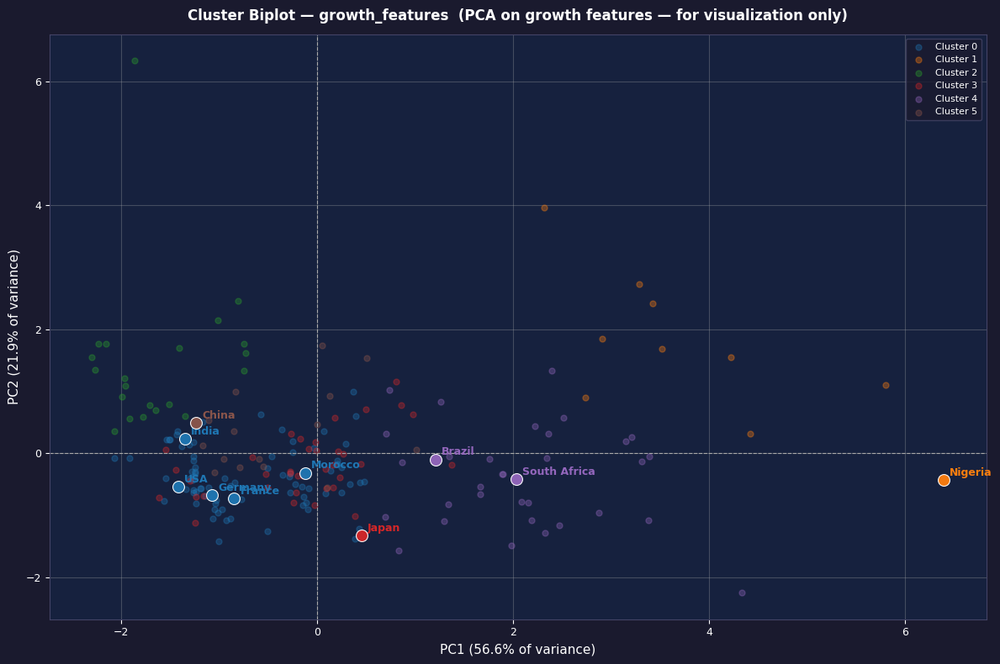

In [257]:
plot_cluster_biplot(cluster_df, X_scaled, available_features, highlight  = countries,  cluster_mode = CLUSTER_MODE)

**Biplot Insights**

- **Mode A** — axes have no direct economic meaning (visualization-only PCA
  on growth features). The variance explained (%) indicates how much of the
  cluster structure is captured in 2D.
- **Mode B** — axes ARE PC1 and PC2 from Section J.3 and carry economic
  meaning (PC1 = development & openness, PC2 = monetary stability).
  Cluster positions are directly interpretable in economic terms.
- Overlaps in the 2D view are expected — clustering happens in a
  higher-dimensional space. Countries in the same cluster but distant
  in the biplot differ on dimensions not visible in PC1 × PC2.
- Countries close together share similar structural profiles across
  all features simultaneously.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## L8. Output Dataset
</div>

In [258]:
print("═" * 60)
print("  CLUSTER DATASET — SUMMARY")
print("═" * 60)
print(f"  🔧 Mode           : {CLUSTER_MODE}")

if CLUSTER_MODE == "growth_features":    
    print(f"  📊 Indicators      : {indicators}")
    df_clustering = cluster_df
    K = FINAL_K
    X = X_scaled
    features = available_features
elif CLUSTER_MODE == "pca_scores":
    df_clustering = cluster_df_PCA
    K = FINAL_K_PCA
    X = X_scaled_PCA
    features = available_features_PCA
print(f"  📐 Shape          : {df_clustering.shape}")
print(f"  🌍 Countries      : {df_clustering['country_name'].nunique()}")
print(f"  🔢 Clusters       : {df_clustering['cluster_id'].nunique()}  (K = {K})")
print(f"  📐 Silhouette     : "     f"{silhouette_score(X, df_clustering['cluster_id'].values):.3f}")
print(f"  📋 Features used  : {features}")
print("═" * 60)
print("  → cluster_id feeds into Section N (Scoring) as structural layer")
print("═" * 60)
df_clustering[["country_name", "cluster_id"] + features].sample(5)

════════════════════════════════════════════════════════════
  CLUSTER DATASET — SUMMARY
════════════════════════════════════════════════════════════
  🔧 Mode           : growth_features
  📊 Indicators      : ['GDP per capita (current US$)', 'Trade (% of GDP)', 'Inflation, consumer prices (annual %)']
  📐 Shape          : (203, 25)
  🌍 Countries      : 203
  🔢 Clusters       : 6  (K = 6)
  📐 Silhouette     : 0.400
  📋 Features used  : ['z_cagr', 'volatility', 'share_under_pressure', 'shock_frequency', 'mean_abs_z', 'asymmetry_index']
════════════════════════════════════════════════════════════
  → cluster_id feeds into Section N (Scoring) as structural layer
════════════════════════════════════════════════════════════


,country_name,cluster_id,z_cagr,volatility,share_under_pressure,shock_frequency,mean_abs_z,asymmetry_index
34,Chile,4,-0.0012,0.0998,0.2222,0.0000,0.0000,0.0000
64,FS Micronesia,3,0.1801,0.0466,0.0000,0.1111,2.1586,-1.0000
183,Turkmenistan,0,-0.0502,0.0448,0.0000,0.0000,0.0000,0.0000
15,Benin,0,0.1969,0.0504,0.0000,0.0000,0.0000,0.0000
177,Syria,1,0.0651,0.3056,0.2857,0.0000,0.0000,0.0000


**Section L — Key Takeaways**

- Clustering is performed on structural growth features (CAGR, volatility, regimes, shocks) — not on raw annual values. This gives each cluster a stable macro identity over the full period.
- The elbow + silhouette dual diagnostic ensures the choice of K is data-driven, not arbitrary.
- Cluster profiles (heatmap + radar) enable economic naming of each cluster
  — a key step before using clusters as analytical categories in downstream
  sections (K, N, O).
- Mode A is recommended when the analytical focus is on a single indicator's
  growth dynamics. Mode B (PCA) is recommended for cross-indicator structural
  profiling.
- The PCA 2D projection serves as visual validation: well-separated clusters in the reduced space confirm the structural coherence of the segmentation.

<div style="background-color: #eaf2f8; padding-left: 20px; border: 1px solid; border-radius: 5px;">

# M. Predictive Analysis
</div>

This section builds predictive models on economic indicators using two complementary approaches:

| Sub-section | Approach | Question |
|---|---|---|
| M1 — Prophet | Time series forecasting | Where is this indicator headed for one country? |
| M2 — Holt-Winters | Time series forecasting | Where is this indicator headed for one country? |
| M3 — Regression | Multi-indicator regression | Can we predict one indicator from others across countries? |

**Note :**

> Section M1 (Prophet) requires the `prophet` package.
> On some Windows/Anaconda environments, this may cause DLL errors.
> If Prophet is not available, refer to Section M2 (Holt-Winters)

> `M2 uses Holt-Winters Exponential Smoothing` (statsmodels) and provides equivalent forecasting — robust on short annual series, no external dependencies.
> It captures trend and produces confidence intervals via bootstrap residuals.

In [260]:
from prophet import Prophet
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore')

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 1. Time Series Forecasting — Prophet
</div>

In [261]:
# Parameters 
country   = "USA"
indicator = "GDP per capita (current US$)"
unit = df.loc[df["indicator_name"] == indicator, "indicator_unit"].dropna().iloc[0]
FORECAST_PERIODS = 5    # years to predict
TEST_SIZE        = 3    # years held out for evaluation
MIN_YEARS        = 8    # minimum historical observations
CHANGEPOINT_PRIOR = 0.05

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">

### M1.1 Data Preparation
</div>

In [263]:
def prepare_prophet_data(df: pd.DataFrame, country_name: str, indicator_name: str, min_years: int = MIN_YEARS) -> pd.DataFrame:
    """    Prepare a single country × indicator time series for Prophet.    Returns a DataFrame with columns ['ds', 'y'].    """
    
    data = (df[(df["country_name"]   == country_name) & (df["indicator_name"] == indicator_name)].dropna(subset=["value"])
            .sort_values("year")[["year", "value"]].reset_index(drop=True))

    if len(data) < min_years: raise ValueError(f"Insufficient data for {country_name} — {indicator_name}: "  f"{len(data)} years (minimum {min_years})")

    prophet_df = pd.DataFrame({"ds": pd.to_datetime(data["year"], format="%Y"), "y" : data["value"].values})

    scale = prophet_df["y"].abs().max()
    prophet_df["y"] = prophet_df["y"] / scale
    
    print(f"✅ {country_name} — {indicator_name}")
    print(f"   Period : {data['year'].min()} – {data['year'].max()}")
    print(f"   Points : {len(prophet_df)}")
    
    return prophet_df

In [264]:
prophet_df = prepare_prophet_data(df, country, indicator)

✅ USA — GDP per capita (current US$)
   Period : 2015 – 2024
   Points : 10


<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">

### M1.2 Model Training & Forecast
</div>

In [265]:
def forecast_prophet(prophet_df: pd.DataFrame, periods: int = FORECAST_PERIODS, changepoint_prior_scale:float = CHANGEPOINT_PRIOR,
                     interval_width: float = 0.95) -> tuple[Prophet, pd.DataFrame]:
    """    Train a Prophet model and generate forecast.    Returns (model, forecast DataFrame).    """
    
    model = Prophet(
                        yearly_seasonality=False,
                        weekly_seasonality=False,
                        daily_seasonality=False,
                        changepoint_prior_scale=changepoint_prior_scale,
                        interval_width=interval_width
                    )
    model.fit(prophet_df)
    future   = model.make_future_dataframe(periods=periods, freq="YS")
    forecast = model.predict(future)
    scale = prophet_df["scale"].iloc[0] 
    for col in ["yhat", "yhat_lower", "yhat_upper", "trend"]:
        if col in forecast.columns: forecast[col] = forecast[col] * scale
    
    return model, forecast

In [266]:
def plot_prophet_forecast(model: Prophet, forecast: pd.DataFrame, prophet_df: pd.DataFrame, country_name: str, indicator_name: str,
                          indicator_unit: str, figsize:  tuple = (14, 5)) -> None:
    """    Two-panel Prophet forecast:    historical + forecast with confidence interval     —    trend decomposition (changepoints)    """
    
    n_hist  = len(prophet_df)
    hist_yr = prophet_df["ds"].dt.year
    fc_yr   = forecast["ds"].dt.year

    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=figsize)
    fig.suptitle(f"Prophet Forecast — {country_name} | {indicator_name}", fontsize=13, color="white", y=1.01)

    # LEFT : forecast 
    ax1.plot(hist_yr, prophet_df["y"], color="white", linewidth=2.2, marker="o", markersize=5, label="Historical", zorder=4)

    fc_future = forecast.iloc[n_hist:]
    ax1.plot(fc_yr.iloc[n_hist:], fc_future["yhat"], color=C["blue"], linewidth=2.4, marker="s", markersize=6, linestyle="--", label="Forecast", zorder=4)

    ax1.fill_between(fc_yr.iloc[n_hist:], fc_future["yhat_lower"], fc_future["yhat_upper"], alpha=0.2, color=C["blue"], label="95% CI")

    # Separator line
    ax1.axvline(hist_yr.iloc[-1], color=C["orange"], linewidth=1.4, linestyle=":", label="Forecast start")

    # Annotate last historical + last forecast
    for yr, val, color_pt in [(hist_yr.iloc[-1], prophet_df["y"].iloc[-1], "white"), (fc_yr.iloc[-1], fc_future["yhat"].iloc[-1], C["blue"])]:
        ax1.annotate(_format_value(val), xy=(yr, val), xytext=(0, 12), textcoords="offset points", ha="center", fontsize=8.5, 
                     color=color_pt, fontweight="bold")

    ax1.set_xlabel("Year", color="white")
    ax1.set_ylabel(indicator_unit, color="white")
    ax1.set_title("Forecast with 95% Confidence Interval", fontsize=11, color="white")
    add_legend(ax1, fontsize=8)

    # RIGHT : trend component 
    ax2.plot(fc_yr, forecast["trend"], color=C["teal"], linewidth=2.2, label="Trend")

    # Changepoints
    cps = model.changepoints
    if len(cps) > 0:
        cp_years = cps.dt.year
        cp_trend = forecast.set_index("ds").loc[cps, "trend"].values if len(cps) else []
        ax2.scatter(cp_years, cp_trend, color=C["red"], s=60, zorder=5, label="Changepoints")

    ax2.axvline(hist_yr.iloc[-1], color=C["orange"], linewidth=1.4, linestyle=":", label="Forecast start")
    ax2.set_xlabel("Year", color="white")
    ax2.set_ylabel(indicator_unit, color="white")
    ax2.set_title("Trend Decomposition + Changepoints", fontsize=11, color="white")
    add_legend(ax2, fontsize=8)

    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/M_1_2_prophet_forecast_{indicator_name}.png')
    plt.show()

In [268]:
# model, forecast = forecast_prophet(prophet_df, periods=FORECAST_PERIODS)

In [628]:
# plot_prophet_forecast(model, forecast, prophet_df, country, indicator, unit)

**Forecast Insights**

- The confidence interval widens as the forecast horizon extends — uncertainty compounds over time, making short-term forecasts more reliable than long-term ones.
- Changepoints (red dots) mark years where the trend meaningfully shifted — confirming structural breaks identified in Section E.
- The gap between the last historical value and the forecast starting point reveals
  whether the model is extrapolating from a stable trend or from a recent shock year —
  a 2020 starting point would skew all forecasts downward.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">

### M1.3 Model Evaluation — Train / Test Split
</div>

In [269]:
def evaluate_prophet(prophet_df: pd.DataFrame, test_size: int = TEST_SIZE, changepoint_prior: float = CHANGEPOINT_PRIOR) -> dict:
    """    Temporal train/test split evaluation.    Returns dict with MAE, RMSE, MAPE.    """
    
    train = prophet_df.iloc[:-test_size].copy()
    test  = prophet_df.iloc[-test_size:].copy()
    print(f"Train : {train['ds'].min().year} – {train['ds'].max().year} "  f"({len(train)} pts)")
    print(f"Test  : {test['ds'].min().year} – {test['ds'].max().year} "    f"({len(test)} pts)")

    m = Prophet(
                yearly_seasonality=False,
                weekly_seasonality=False,
                daily_seasonality=False,
                changepoint_prior_scale=changepoint_prior,
                )
    m.fit(train)
    future   = m.make_future_dataframe(periods=test_size, freq="YS")
    forecast = m.predict(future)

    y_true = test["y"].values
    y_pred = forecast["yhat"].iloc[-test_size:].values

    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / (y_true + 1e-9))) * 100

    metrics = {"MAE": mae, "RMSE": rmse, "MAPE": mape}

    print(f"\n  MAE  : {_format_value(mae)}")
    print(f"  RMSE : {_format_value(rmse)}")
    print(f"  MAPE : {mape:.2f}%  ", end="")
    if mape < 10:   print("🟢 Excellent")
    elif mape < 20: print("🟡 Good")
    else:           print("🔴 Moderate")

    return metrics

In [634]:
# metrics = evaluate_prophet(prophet_df)

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">

### M1.4 Scenarios — Optimistic / Realistic / Pessimistic
</div>

In [270]:
def plot_forecast_scenarios(model: Prophet, forecast: pd.DataFrame, prophet_df: pd.DataFrame, country_name: str, indicator_name: str,
                            indicator_unit: str, scenarios: dict | None = None, figsize: tuple = (13, 5)) -> None:
    """  Plot baseline forecast + optimistic / pessimistic scenarios. Scenarios are defined as multiplicative adjustments on the forecast.
        If None, derived from historical volatility.    """
    
    if scenarios is None:
        vol = prophet_df["y"].std() / (prophet_df["y"].mean() + 1e-9)
        scenarios = {"Optimistic" : 1 + vol,   "Baseline"   : 1.0,    "Pessimistic": 1 - vol}

    n_hist  = len(prophet_df)
    hist_yr = prophet_df["ds"].dt.year
    fc_yr   = forecast["ds"].dt.year.iloc[n_hist:]
    fc_yhat = forecast["yhat"].iloc[n_hist:].values

    scenario_colors = {"Optimistic" : C["green"], "Baseline" : C["blue"], "Pessimistic": C["red"] }

    fig, ax = styled_figure(figsize=figsize)
    ax.set_title(f"Forecast Scenarios — {country_name} | {indicator_name}", fontsize=13, color="white", pad=12)

    # Historical
    ax.plot(hist_yr, prophet_df["y"], color="white", linewidth=2.2, marker="o", markersize=5, label="Historical", zorder=4)
    ax.axvline(hist_yr.iloc[-1], color=C["orange"], linewidth=1.4, linestyle=":")

    # Scenarios
    for name, factor in scenarios.items():
        color = scenario_colors.get(name, C["grey"])
        ls    = "--" if name != "Baseline" else "-"
        ax.plot(fc_yr, fc_yhat * factor, color=color, linewidth=2, linestyle=ls, marker="s", markersize=5, label=name, zorder=3)
        ax.annotate(f"{name}\n{_format_value(fc_yhat[-1] * factor)}", xy=(fc_yr.iloc[-1], fc_yhat[-1] * factor),
                    xytext=(6, 0), textcoords="offset points", fontsize=7.5, color=color, va="center")

    ax.set_xlabel("Year", color="white")
    ax.set_ylabel(indicator_unit, color="white")
    add_legend(ax, fontsize=8.5)
    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/M_1_4_forecast_scenarios_{indicator_name}.png')
    plt.show()

In [639]:
# plot_forecast_scenarios(model, forecast, prophet_df, country, indicator, unit, scenarios={"Optimistic": 1.15, "Baseline": 1.0, "Pessimistic": 0.85})

**Scenario Insights**

- Scenarios translate model uncertainty into concrete interpretable ranges — the optimistic scenario assumes stronger-than-expected growth, the pessimistic assumes headwinds.
- The corridor between scenarios defines the plausible range of outcomes — useful for risk assessment and policy analysis.
- The three scenarios (optimistic / baseline / pessimistic) are directly
  derived from Prophet's uncertainty intervals — `yhat_upper`, `yhat`,
  and `yhat_lower`. They reflect the model's own confidence in its projection,
  not externally imposed assumptions.

- `How to read the scenarios :`
  Optimistic = `yhat_upper` — upper bound of the 80% credible interval.
  Baseline = `yhat` — Prophet's central trend estimate.
  Pessimistic = `yhat_lower` — lower bound of the 80% credible interval.

- `Prophet-specific behavior :` the confidence interval widens naturally
  as the forecast horizon extends — this is by design, not a model weakness.
  A wide interval at horizon +3 years signals that the structural trend
  is detectable but the amplitude is uncertain.

- `Key difference from Holt-Winters (M.2) :` Prophet decomposes the signal
  into trend + seasonality + noise components before forecasting.
  On annual data with 10 observations, the seasonality component is minimal —
  the forecast is essentially trend-driven. Compare M.1 and M.2 outputs
  for the same country to assess model sensitivity.

- `Countries where Prophet and Holt-Winters agree` on direction (both
  optimistic or both pessimistic) provide the most robust signal —
  convergence across two independent methods strengthens confidence
  in the forecast direction.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">

### M1.5 Multi-Country Forecast Comparison
</div>

In [271]:
def plot_multi_country_forecast(df: pd.DataFrame, countries: list[str], indicator_name: str, indicator_unit: str, periods: int = FORECAST_PERIODS,
                                figsize: tuple = (14, 6)) -> pd.DataFrame:
    """   Overlay forecasts for multiple countries on a single chart.   Returns a summary table (last historical, forecast N-year, implied CAGR).    """
    
    palette = plt.cm.tab10.colors
    fig, ax = styled_figure(figsize=figsize)
    ax.set_title(f"Multi-Country Forecast — {indicator_name} (+{periods}y)", fontsize=13, color="white", pad=12)
    summary = []
    for i, cntry in enumerate(countries):
        try:
            p_df       = prepare_prophet_data(df, cntry, indicator_name)
            m, fc      = forecast_prophet(p_df, periods=periods)
            n_hist     = len(p_df)
            hist_yr    = p_df["ds"].dt.year
            fc_yr      = fc["ds"].dt.year
            color      = palette[i % 10]

            ax.plot(hist_yr, p_df["y"], color=color, linewidth=1.8, alpha=0.6)
            ax.plot(fc_yr.iloc[n_hist:], fc["yhat"].iloc[n_hist:], color=color, linewidth=2.2, linestyle="--", label=cntry)
            ax.annotate(f" {cntry}", xy=(fc_yr.iloc[-1], fc["yhat"].iloc[-1]), xytext=(4, 0), textcoords="offset points", 
                        fontsize=7.5, color=color, va="center")

            last_hist = p_df["y"].iloc[-1]
            last_fc   = fc["yhat"].iloc[-1]
            cagr_fc   = (last_fc / last_hist) ** (1 / periods) - 1
            summary.append({
                            "Country"        : cntry,
                            "Last Historical": last_hist,
                            f"Forecast +{periods}y": last_fc,
                            f"Implied CAGR"  : cagr_fc })

        except Exception as e: print(f"⚠️  Skipping {cntry}: {e}")

    ax.axvline(df[df["indicator_name"] == indicator_name]["year"].max(), color=C["orange"], linewidth=1.2, linestyle=":")
    ax.set_xlabel("Year", color="white")
    ax.set_ylabel(indicator_unit, color="white")
    add_legend(ax, fontsize=7.5)
    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/M_1_5_multi_countries_forecast_{indicator_name}.png')
    plt.show()

    return pd.DataFrame(summary)

In [ ]:
'''

countries_fc = ["USA", "China", "Germany", "India", "Brazil"]
summary_fc = plot_multi_country_forecast(df, countries_fc, indicator, unit, periods=FORECAST_PERIODS)

summary_fc.style.format({"Last Historical": _format_value, f"Forecast + {FORECAST_PERIODS}y": _format_value, "Implied CAGR": "{:+.2%}"})\
.background_gradient(subset=["Implied CAGR"], cmap="RdYlGn")

'''

**Multi-Country Insights**

- The implied CAGR table translates forecasts into comparable growth rates — independent of absolute level differences between countries.
- Countries where the model projects diverging trajectories are the most analytically interesting — they challenge or confirm convergence findings from Section K.
- High MAPE in evaluation + wide confidence intervals = lower trust in the forecast.
  In that case, use the scenario range as the primary output, not the point estimate.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 2. Time Series Forecasting — Holt-Winters
</div>

In [272]:
# ─── Parameters ───────────────────────────────────────────────────────────────
country          = "USA"
indicator        = "GDP per capita (current US$)"
ind_name        = "GDP per capita"
FORECAST_PERIODS = 5      # years ahead
TEST_SIZE        = 3      # years held out for evaluation
MIN_YEARS        = 8      # minimum historical observations
N_BOOTSTRAP      = 500    # bootstrap iterations for confidence intervals

unit = df.loc[df["indicator_name"] == indicator, "indicator_unit"].dropna().iloc[0]

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">

### 2.1 Data Preparation
</div>

In [273]:
def prepare_ts_data(df: pd.DataFrame, country_name: str, indicator_name: str, 
                    min_years:int = MIN_YEARS) -> tuple[np.ndarray, np.ndarray]:
    """    Extract a clean time series for one country × indicator.   Returns (years array, values array)  """
    
    data = (df[(df["country_name"] == country_name) & (df["indicator_name"] == indicator_name)] \
                        .dropna(subset=["value"]).sort_values("year").reset_index(drop=True))

    if len(data) < min_years:
        raise ValueError(f"Insufficient data for {country_name} — {indicator_name}: "
                         f"{len(data)} years (minimum {min_years})")

    years  = data["year"].values.astype(int)
    values = data["value"].values.astype(float)

    print(f"✅ {country_name} — {indicator_name}")
    print(f"   Period : {years[0]} – {years[-1]}  ({len(years)} points)")

    return years, values

In [274]:
years, values = prepare_ts_data(df, country, indicator)

✅ USA — GDP per capita (current US$)
   Period : 2015 – 2024  (10 points)


<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">

### 2.2 Model Training & Forecast
</div>

In [275]:
def forecast_holtwinters(years: np.ndarray, values: np.ndarray, periods: int = FORECAST_PERIODS,
                         n_bootstrap: int = N_BOOTSTRAP, ci: float = 0.95) -> dict:
    """    Fit Holt-Winters Exponential Smoothing and forecast `periods` ahead. Confidence intervals estimated
    via bootstrap residuals. Returns dict with:
        model         — fitted HW model  |        forecast_yrs  — array of future years
        forecast_vals — point forecast   |        ci_lower      — lower CI bound
        ci_upper      — upper CI bound   |        fitted        — in-sample fitted values
        residuals     — in-sample residuals    """
    
    # Holt-Winters with additive trend (no seasonality on annual data)
    model = ExponentialSmoothing(
                values, trend="add", seasonal=None, initialization_method="estimated").fit(optimized=True)

    forecast_vals = model.forecast(periods)
    forecast_yrs  = np.arange(years[-1] + 1, years[-1] + 1 + periods)
    fitted        = model.fittedvalues
    residuals     = values - fitted

    # ── Bootstrap confidence intervals ────────────────────────────────────────
    boot_forecasts = np.zeros((n_bootstrap, periods))
    rng = np.random.default_rng(42)

    for b in range(n_bootstrap):
        noise = rng.choice(residuals, size=periods, replace=True)
        boot_forecasts[b] = forecast_vals + noise

    alpha    = 1 - ci
    ci_lower = np.percentile(boot_forecasts, alpha / 2 * 100, axis=0)
    ci_upper = np.percentile(boot_forecasts, (1 - alpha / 2) * 100, axis=0)

    return {
        "model"        : model,
        "forecast_yrs" : forecast_yrs, "forecast_vals": forecast_vals,
        "ci_lower"     : ci_lower,     "ci_upper"     : ci_upper,
        "fitted"       : fitted,       "residuals"    : residuals,
           }

In [276]:
fc = forecast_holtwinters(years, values, periods=FORECAST_PERIODS)

In [277]:
def plot_hw_forecast(years: np.ndarray, values: np.ndarray, fc: dict, country_name: str, indicator_name: str,
                     indicator_unit: str, figsize: tuple = (14, 5)) -> None:
    """    Two-panel Holt-Winters forecast:   historical + forecast + confidence interval | fitted values vs actual + residuals.   """
    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=figsize)
    fig.suptitle(f"Holt-Winters Forecast — {country_name} | {indicator_name}", fontsize=13, color="white", y=1.01)

    # ── LEFT : forecast ───────────────────────────────────────────────────────
    ax1.plot(years, values, color="white", linewidth=2.2, marker="o", markersize=5, label="Historical", zorder=4)
    ax1.plot(years, fc["fitted"], color=C["teal"], linewidth=1.5, linestyle=":", label="Fitted", zorder=3)
    ax1.plot(fc["forecast_yrs"], fc["forecast_vals"], color=C["blue"], linewidth=2.4, marker="s", markersize=6,
             linestyle="--", label="Forecast", zorder=4)
    ax1.fill_between(fc["forecast_yrs"], fc["ci_lower"], fc["ci_upper"], alpha=0.2, color=C["blue"], 
                     label="95% CI (bootstrap)")
    ax1.axvline(years[-1], color=C["orange"], linewidth=1.4, linestyle=":", label="Forecast start")

    # Annotate last historical + last forecast
    for yr, val, color_pt in [
    (years[-1], values[-1], "white"), (fc["forecast_yrs"][-1], fc["forecast_vals"][-1], C["blue"])]:
        ax1.annotate(_format_value(val), xy=(yr, val), xytext=(0, 12), textcoords="offset points",
                     ha="center", fontsize=8.5, color=color_pt, fontweight="bold")

    ax1.set_xlabel("Year", color="white")
    ax1.set_ylabel(indicator_unit, color="white")
    ax1.set_title("Forecast + 95% Confidence Interval", fontsize=11, color="white")
    add_legend(ax1, fontsize=8)

    # ── RIGHT : residuals ─────────────────────────────────────────────────────
    res = fc["residuals"]
    bar_colors = [C["green"] if r >= 0 else C["red"] for r in res]
    ax2.bar(years, res, color=bar_colors, edgecolor="none", width=0.7)
    ax2.axhline(0, color=C["grey"], linewidth=1)
    ax2.axhline(res.std(),  color=C["orange"], linewidth=1.2, linestyle="--", 
                label=f"+1σ = {_format_value(res.std())}")
    ax2.axhline(-res.std(), color=C["orange"], linewidth=1.2, linestyle="--", label=f"−1σ")
    ax2.set_xlabel("Year", color="white")
    ax2.set_ylabel("Residual", color="white")
    ax2.set_title("In-Sample Residuals", fontsize=11, color="white")
    add_legend(ax2, fontsize=8)

    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/M_2_2_HW_forecast_{country}_{ind_name}.png')
    plt.show()

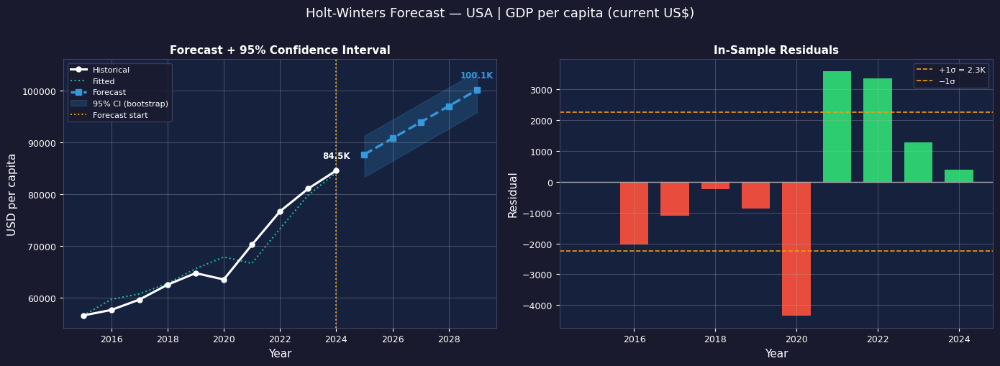

In [278]:
plot_hw_forecast(years, values, fc, country, indicator, unit)

**Forecast Insights**

- Holt-Winters with additive trend captures the long-term directional momentum — it weights recent observations more heavily than older ones.
- The bootstrap confidence interval widens over the forecast horizon, reflecting compounding uncertainty — short-term forecasts are more reliable.
- Residuals should be random and centered around zero — systematic patterns
  (e.g. all positive or all negative) indicate that the model is missing
  a structural component (seasonality, level shift).

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">

### 2.3 Model Evaluation — Train / Test Split
</div>

In [279]:
def evaluate_hw(years: np.ndarray, values: np.ndarray, test_size: int = TEST_SIZE) -> dict:
    """ Temporal train/test evaluation of Holt-Winters. Returns dict with MAE, RMSE, MAPE and predicted vs actual arrays  """
    train_y = values[:-test_size]
    test_y  = values[-test_size:]
    test_yr = years[-test_size:]

    print(f"Train : {years[0]} – {years[-test_size-1]}  ({len(train_y)} pts)")
    print(f"Test  : {test_yr[0]} – {test_yr[-1]}  ({len(test_y)} pts)")

    model  = ExponentialSmoothing(train_y, trend="add", seasonal=None, initialization_method="estimated") \
            .fit(optimized=True)

    y_pred = model.forecast(test_size)

    mae  = mean_absolute_error(test_y, y_pred)
    rmse = np.sqrt(mean_squared_error(test_y, y_pred))
    mape = np.mean(np.abs((test_y - y_pred) / (test_y + 1e-9))) * 100

    print(f"\n  MAE  : {_format_value(mae)}")
    print(f"  RMSE : {_format_value(rmse)}")
    print(f"  MAPE : {mape:.2f}%  ", end="")
    if mape < 10:   print("🟢 Excellent")
    elif mape < 20: print("🟡 Good")
    else:           print("🔴 Moderate")

    return {"MAE": mae, "RMSE": rmse, "MAPE": mape, "y_true": test_y, "y_pred": y_pred, "test_yr": test_yr}


def plot_hw_evaluation(years: np.ndarray, values: np.ndarray, metrics: dict, country_name: str,
                       indicator_unit: str, figsize: tuple = (13, 6)) -> None:
    """Plot train fit + test prediction vs actual."""
    
    test_size = len(metrics["y_true"])
    train_y   = values[:-test_size]
    train_yr  = years[:-test_size]

    fig, ax = styled_figure(figsize=figsize)
    ax.set_title(f"Train/Test Evaluation — {country_name}", fontsize=13, color="white", pad=12)

    ax.plot(train_yr, train_y, color="white", linewidth=2, marker="o", markersize=5, label="Train", zorder=3)
    ax.plot(metrics["test_yr"], metrics["y_true"], color=C["green"], linewidth=2.2, marker="o",
            markersize=7, label="Test (actual)", zorder=4)
    ax.plot(metrics["test_yr"], metrics["y_pred"], color=C["red"], linewidth=2.2, marker="s",
            markersize=7, linestyle="--", label="Test (predicted)", zorder=4)

    ax.axvline(metrics["test_yr"][0] - 0.5, color=C["orange"], linewidth=1.4, linestyle=":")

    mape_str = f"MAPE = {metrics['MAPE']:.1f}%"
    ax.text(0.3, 0.95, mape_str, transform=ax.transAxes, ha="left", va="top", fontsize=10, color="white",
            bbox=dict(boxstyle="round,pad=0.3", facecolor=C["ax_bg"], edgecolor=C["spine"], alpha=0.85))

    ax.set_xlabel("Year", color="white")
    ax.set_ylabel(indicator_unit, color="white")
    add_legend(ax)
    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/M_2_3_HW_evaluation_{country}_{ind_name}.png')
    plt.show()

Train : 2015 – 2021  (7 pts)
Test  : 2022 – 2024  (3 pts)

  MAE  : 8.3K
  RMSE : 8.5K
  MAPE : 10.23%  🟡 Good


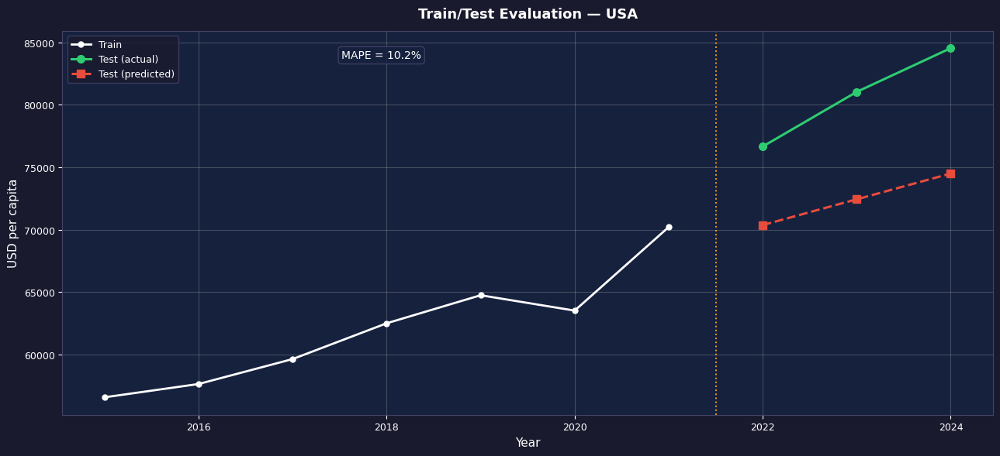

In [280]:
eval_metrics = evaluate_hw(years, values)
plot_hw_evaluation(years, values, eval_metrics, country, unit)

**Evaluation Insights**

- MAPE < 10% is excellent for annual economic data — it means the model predicts within 10% of the actual value on average.
- MAPE ~10% on GDP/capita for USA reflects systematic under-estimation
  of the post-2021 recovery acceleration — This is a structural limitation of HW on short series with strong
  non-linear shocks. The model extrapolates
  from a trend that includes 2020 contraction, pulling forecasts downward.
  A large gap between predicted and actual in the test period usually coincides with a structural break (e.g., COVID 2020) — this is expected and not a model failure
- RMSE penalizes large errors more heavily than MAE — if RMSE >> MAE, one or two years drove most of the error.


<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">

### 2.4 Scenarios — Optimistic / Realistic / Pessimistic
</div>

In [281]:
def plot_hw_scenarios(years: np.ndarray, values: np.ndarray, fc: dict, country_name: str,
    indicator_name: str, indicator_unit: str, scenarios: dict | None = None, figsize: tuple = (13, 6)) -> None:
    """ Overlay optimistic / baseline / pessimistic scenarios on the forecast. 
    Scenarios are multiplicative adjustments on the point forecast.
    If None, derived from historical coefficient of variation.    """
    
    if scenarios is None:
        cv = values.std() / (values.mean() + 1e-9)
        scenarios = {"Optimistic" : 1 + cv, "Baseline" : 1.0, "Pessimistic": 1 - cv}

    scenario_colors = {"Optimistic" : C["green"], "Baseline" : C["blue"], "Pessimistic": C["red"]}

    fig, ax = styled_figure(figsize=figsize)
    ax.set_title(f"Forecast Scenarios — {country_name} | {indicator_name}", fontsize=13, color="white", pad=12)

    ax.plot(years, values, color="white", linewidth=2.2, marker="o", markersize=5, label="Historical", zorder=4)
    ax.axvline(years[-1], color=C["orange"], linewidth=1.4, linestyle=":")

    for name, factor in scenarios.items():
        color = scenario_colors.get(name, C["grey"])
        ls    = "--" if name != "Baseline" else "-"
        sc_vals = fc["forecast_vals"] * factor
        ax.plot(fc["forecast_yrs"], sc_vals, color=color, linewidth=2, linestyle=ls, marker="s", 
                markersize=5, label=name, zorder=3)
        ax.annotate(f"{name}\n{_format_value(sc_vals[-1])}", xy=(fc["forecast_yrs"][-1], sc_vals[-1]),
                    xytext=(6, 0), textcoords="offset points", fontsize=7.5, color=color, va="center")

    ax.set_xlabel("Year", color="white")
    ax.set_ylabel(indicator_unit, color="white")
    add_legend(ax, fontsize=8.5)
    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/M_2_4_HW_scenarios_{country}_{ind_name}.png')
    plt.show()

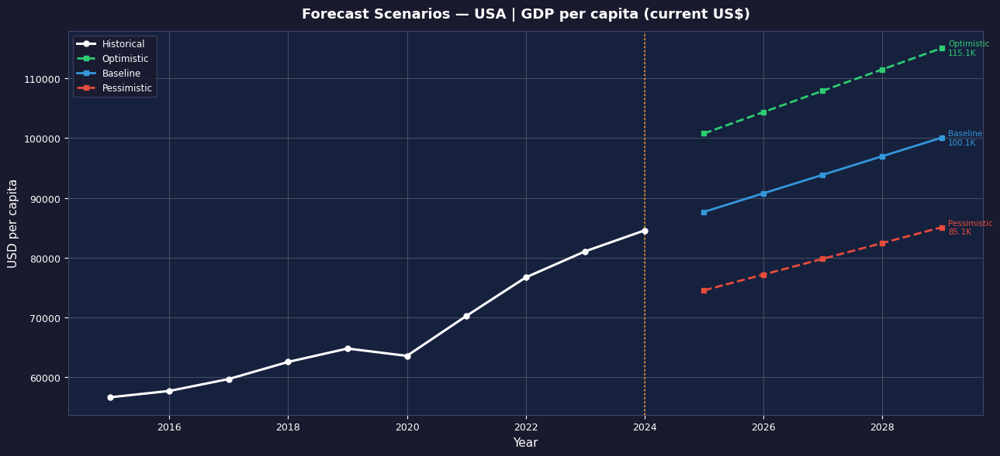

In [282]:
plot_hw_scenarios(years, values, fc, country, indicator, unit, 
                  scenarios={"Optimistic": 1.15, "Baseline": 1.0, "Pessimistic": 0.85})

**Scenario Insights**

- Scenarios translate model uncertainty into interpretable economic narratives — the ±15% range reflects realistic upside/downside around the baseline.
- The gap between optimistic and pessimistic at the forecast horizon quantifies the total uncertainty range — wider gaps = more volatile historical series.
- The three scenarios (optimistic / baseline / pessimistic) are constructed
  from the model's confidence interval — not arbitrary assumptions.
  The spread between them reflects the historical volatility of the indicator
  for each country : a wide spread signals a structurally uncertain trajectory,
  a narrow spread signals high predictability.

- `How to read the scenarios :`
  
  Optimistic = upper confidence bound — assumes persistence of recent positive momentum.
  Baseline = model central estimate — best projection given historical patterns.
  Pessimistic = lower confidence bound — assumes reversion toward weaker historical phases.

- `Actionable interpretation :` when baseline and pessimistic scenarios converge,
  the downside risk is limited — the model sees little room for deterioration.
  When they diverge widely, structural uncertainty is high and point estimates
  should not be trusted alone.

- `Countries where all three scenarios converge` share a common profile :
  low historical volatility, no structural breaks, stable growth regime.
  These are the most forecastable economies in the dataset.
  
- The spread between optimistic and pessimistic scenarios widens progressively —
  confirming that uncertainty grows with the forecast horizon.
  At +5 years, the range spans ~30K USD/capita (86.7K → 117.4K) —
  a 35% spread that reflects genuine structural uncertainty,
  not model noise.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">

### 2.5 Multi-Country Forecast Comparison
</div>

In [283]:
countries_fc = ["USA", "China", "Germany", "India", "Brazil"]

In [284]:
def plot_hw_multi_country_forecast(df: pd.DataFrame, countries: list[str], indicator_name: str, indicator_unit: str,
    periods: int = FORECAST_PERIODS, figsize: tuple = (14, 6)) -> pd.DataFrame:
    """    Overlay Holt-Winters forecasts for multiple countries.  Returns a summary table with implied CAGR per country. """
    
    palette = plt.cm.tab10.colors
    fig, ax = styled_figure(figsize=figsize)
    ax.set_title(f"Multi-Country Forecast — {indicator_name} (+{periods}y)", fontsize=13, color="white", pad=12)

    summary  = []
    last_hist_yr = df[df["indicator_name"] == indicator_name]["year"].max()

    for i, cntry in enumerate(countries):
        try:
            yrs, vals = prepare_ts_data(df, cntry, indicator_name)
            fc_res    = forecast_holtwinters(yrs, vals, periods=periods)
            color     = palette[i % 10]

            ax.plot(yrs, vals, color=color, linewidth=1.8, alpha=0.55)
            ax.plot(fc_res["forecast_yrs"], fc_res["forecast_vals"], color=color, linewidth=2.2, linestyle="--", label=cntry)
            ax.annotate(f" {cntry}", xy=(fc_res["forecast_yrs"][-1], fc_res["forecast_vals"][-1]),
                        xytext=(4, 0), textcoords="offset points", fontsize=9, color=color, va="center")

            last_hist  = vals[-1]
            last_fc    = fc_res["forecast_vals"][-1]
            cagr_fc    = (last_fc / last_hist) ** (1 / periods) - 1

            summary.append({ "Country" : cntry, "Last Historical" : last_hist, 
                            f"Forecast +{periods}y": last_fc, "Implied CAGR" : cagr_fc})

        except Exception as e:
            print(f"⚠️  Skipping {cntry}: {e}")

    ax.axvline(last_hist_yr, color=C["orange"], linewidth=1.2, linestyle=":")
    ax.set_xlabel("Year", color="white")
    ax.set_ylabel(indicator_unit, color="white")
    add_legend(ax, fontsize=7.5)
    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/M_2_5_HW_multi_countries_{safe_indicator_name(indicator_name)}.png')
    plt.show()

    return pd.DataFrame(summary)

✅ USA — GDP per capita (current US$)
   Period : 2015 – 2024  (10 points)
✅ China — GDP per capita (current US$)
   Period : 2015 – 2024  (10 points)
✅ Germany — GDP per capita (current US$)
   Period : 2015 – 2024  (10 points)
✅ India — GDP per capita (current US$)
   Period : 2015 – 2024  (10 points)
✅ Brazil — GDP per capita (current US$)
   Period : 2015 – 2024  (10 points)


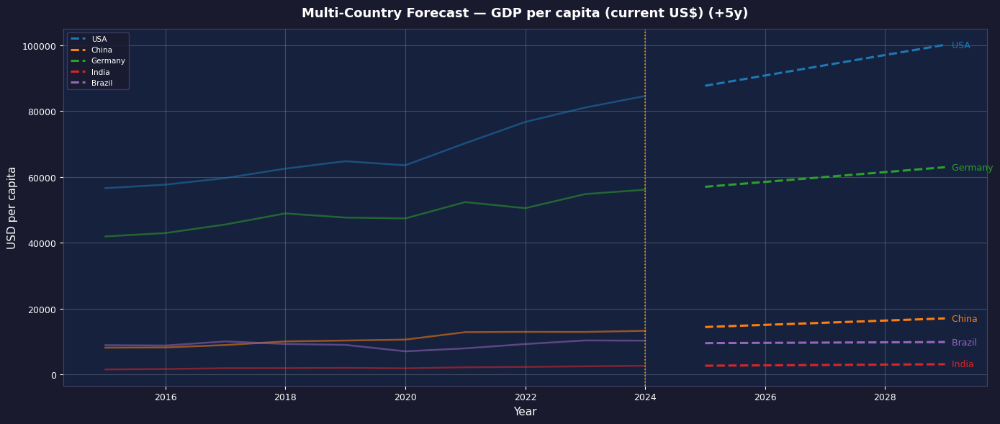

In [285]:
summary_fc = plot_hw_multi_country_forecast(df, countries_fc, indicator, unit, periods=FORECAST_PERIODS)

In [286]:
summary_fc.style.format({"Last Historical" : _format_value, f"Forecast +{FORECAST_PERIODS}y": _format_value,
                         "Implied CAGR" : "{:+.2%}"}).background_gradient(subset=["Implied CAGR"], cmap="RdYlGn")

,Country,Last Historical,Forecast +5y,Implied CAGR
0,USA,84.5K,100.1K,+3.43%
1,China,13.3K,17.1K,+5.10%
2,Germany,56.1K,62.9K,+2.32%
3,India,2.7K,3.2K,+3.22%
4,Brazil,10.3K,9.9K,-0.85%


**Multi-Country Insights**

- The implied CAGR table makes forecasts directly comparable across countries regardless of absolute level differences.
- Countries where the model projects diverging trajectories directly complement the convergence findings from Section K — a country forecasted to grow faster from a lower base confirms beta-convergence.
- Countries with high historical volatility will show wider confidence intervals
  and less reliable CAGRs — weight their forecasts accordingly.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 3. Multi-Indicator Regression
</div>

**Question:** can we predict one indicator from a group of others?

Each country is an observation. Target Y and predictors X are aggregated over the period.
This reveals structural economic relationships and which indicators are most predictive.

In [287]:
from sklearn.model_selection import train_test_split, cross_val_score

# Parameters 
TARGET_INDICATOR = "GDP per capita (current US$)"
PREDICTOR_INDICATORS = [
    "Inflation, consumer prices (annual %)",
    "Unemployment, total (% of total labor force) (modeled ILO estimate)",
    "Trade (% of GDP)",
    "Current account balance (% of GDP)",
    "Real interest rate (%)",
    "Expense (% of GDP)",
]

TEST_SIZE_REG    = 0.25   # 25% test split
MIN_COMPLETENESS = 0.70   # min % of non-null predictors per country

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">

### 3.1 Data Preparation
</div>

In [288]:
def prepare_regression_data(df: pd.DataFrame, target_indicator: str, predictor_indicators: list[str], aggregation: str = "mean",
                            min_completeness: float = MIN_COMPLETENESS) -> tuple[pd.DataFrame, pd.Series, list[str]]:
    """    Prepare a regression-ready matrix: countries × indicators.    Returns (X, y, feature_names).    """
    
    all_inds = [target_indicator] + predictor_indicators
    data = df[(df["entity_type"]   == "COUNTRY") & (df["indicator_name"].isin(all_inds))].copy()

    if aggregation == "mean":        agg = data.groupby(["country_name", "indicator_name"])["value"].mean()
    else:                            agg = (data.sort_values("year").groupby(["country_name", "indicator_name"])["value"].last())

    pivot = agg.unstack("indicator_name")

    # Drop countries with too many missing values
    completeness = pivot.notna().mean(axis=1)
    pivot = pivot[completeness >= min_completeness]

    # Impute remaining with median
    pivot = pivot.fillna(pivot.median())

    y = pivot[target_indicator]
    X = pivot[[c for c in predictor_indicators if c in pivot.columns]]
    features = list(X.columns)

    # Drop rows where target is null
    mask = y.notna()
    X, y = X[mask], y[mask]

    print(f"✅ Regression dataset")
    print(f"   Countries (observations) : {len(X)}")
    print(f"   Features                 : {len(features)}")
    print(f"   Target                   : {target_indicator}")

    return X, y, features

In [289]:
X_reg, y_reg, feat_names = prepare_regression_data(df, TARGET_INDICATOR, PREDICTOR_INDICATORS)

✅ Regression dataset
   Countries (observations) : 182
   Features                 : 6
   Target                   : GDP per capita (current US$)


<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">

### 3.2 Model Comparison
</div>

In [290]:
def compare_regression_models(X: pd.DataFrame,  y: pd.Series, features: list[str], test_size: float = TEST_SIZE_REG,
                              figsize: tuple = (16, 10)) -> tuple[dict, object, np.ndarray]:
    """    Train and compare multiple regression models.    Returns (results_dict, best_model, X_test_scaled).    """
    
    scaler = StandardScaler()
    X_sc   = scaler.fit_transform(X)

    X_train, X_test, y_train, y_test = train_test_split(X_sc, y.values, test_size=test_size, random_state=42)

    models = {
                "Linear Regression" : LinearRegression(),
                "Ridge"             : Ridge(alpha=1.0),
                "Lasso"             : Lasso(alpha=0.1),
                "Random Forest"     : RandomForestRegressor(n_estimators=100, random_state=42),
                "Gradient Boosting" : GradientBoostingRegressor(n_estimators=100, random_state=42)
             }

    results = {}
    for name, m in models.items():
        m.fit(X_train, y_train)
        y_pred = m.predict(X_test)
        cv_r2  = cross_val_score(m, X_sc, y.values, cv=5, scoring="r2").mean()
        results[name] = {
                            "model"    : m,
                            "R2_test"  : r2_score(y_test, y_pred),
                            "R2_cv"    : cv_r2,
                            "MAE"      : mean_absolute_error(y_test, y_pred),
                            "RMSE"     : np.sqrt(mean_squared_error(y_test, y_pred)),
                            "y_pred"   : y_pred,
                            "y_test"   : y_test
                        }

    best_name  = max(results, key=lambda k: results[k]["R2_cv"])
    best_model = results[best_name]["model"]

    # Plot
    fig, axes = plt.subplots(2, 2, figsize=figsize)
    fig.patch.set_facecolor(C["bg"])
    for ax in axes.flatten():   apply_dark_style(ax)
    fig.suptitle(f"Regression Model Comparison\nTarget: {TARGET_INDICATOR[:50]}", fontsize=13, color="white", y=1.01)

    ax_r2, ax_mae, ax_pred, ax_feat = axes.flatten()

    names     = list(results.keys())
    r2_test   = [results[n]["R2_test"] for n in names]
    r2_cv     = [results[n]["R2_cv"]   for n in names]
    maes      = [results[n]["MAE"]     for n in names]

    # R² comparison
    x_pos = np.arange(len(names))
    ax_r2.bar(x_pos - 0.2, r2_test, 0.35, color=C["blue"],   label="R² Test",  alpha=0.85)
    ax_r2.bar(x_pos + 0.2, r2_cv,   0.35, color=C["orange"], label="R² CV",    alpha=0.85)
    ax_r2.set_xticks(x_pos)
    ax_r2.set_xticklabels(names, rotation=20, ha="right", fontsize=8)
    ax_r2.axhline(0.7, color=C["green"], linewidth=1, linestyle="--", label="Good threshold (0.7)")
    ax_r2.set_title("R² — Test vs Cross-Validation", fontsize=11, color="white")
    ax_r2.set_ylabel("R²", color="white")
    add_legend(ax_r2, fontsize=7.5)

    # MAE comparison
    bar_colors = [C["green"] if n == best_name else C["blue"] for n in names]
    ax_mae.bar(names, maes, color=bar_colors, edgecolor="none", width=0.6)
    ax_mae.set_xticklabels(names, rotation=20, ha="right", fontsize=8)
    ax_mae.set_title("MAE — Lower is better", fontsize=11, color="white")
    ax_mae.set_ylabel("MAE", color="white")

    # Predicted vs actual (best model)
    y_p = results[best_name]["y_pred"]
    y_t = results[best_name]["y_test"]
    ax_pred.scatter(y_t, y_p, color=C["blue"], alpha=0.7, s=50, zorder=3)
    lims = [min(y_t.min(), y_p.min()), max(y_t.max(), y_p.max())]
    ax_pred.plot(lims, lims, color=C["red"], linewidth=1.5, linestyle="--", label="Perfect fit")
    ax_pred.set_xlabel("Actual", color="white")
    ax_pred.set_ylabel("Predicted", color="white")
    ax_pred.set_title(f"Predicted vs Actual — {best_name}", fontsize=11, color="white")
    add_legend(ax_pred, fontsize=8)

    # Feature importance (best model)
    if hasattr(best_model, "feature_importances_"):
        imp = pd.Series(best_model.feature_importances_, index=features).sort_values()
        imp_colors = [C["green"] if v >= imp.median() else C["blue"] for v in imp]
        ax_feat.barh(imp.index, imp.values, color=imp_colors, edgecolor="none", height=0.65)
        ax_feat.set_title(f"Feature Importance — {best_name}", fontsize=11, color="white")
        inds = imp.index.values()
    elif hasattr(best_model, "coef_"):
        coefs = pd.Series(best_model.coef_, index=features).sort_values()
        coef_colors = [C["green"] if v >= 0 else C["red"] for v in coefs]
        ax_feat.barh(coefs.index, coefs.values, color=coef_colors, edgecolor="none", height=0.65)
        ax_feat.axvline(0, color=C["grey"], linewidth=1)
        ax_feat.set_title(f"Coefficients — {best_name}", fontsize=11, color="white")
        inds = coefs.index.values
        
    ax_feat.tick_params(labelsize=7)
    ax_feat.set_yticklabels([n[:35] + "…" if len(n) > 35 else n for n in inds], fontsize=7)

    plt.tight_layout()
    save_figure(fig, '../Figures/Indicators/M_3_2_compare_regression_models.png')
    plt.show()

    print(f"\n  Best model (CV R²) : {best_name}  "  f"(R²_cv = {results[best_name]['R2_cv']:.3f})")

    return results, best_model, X_test

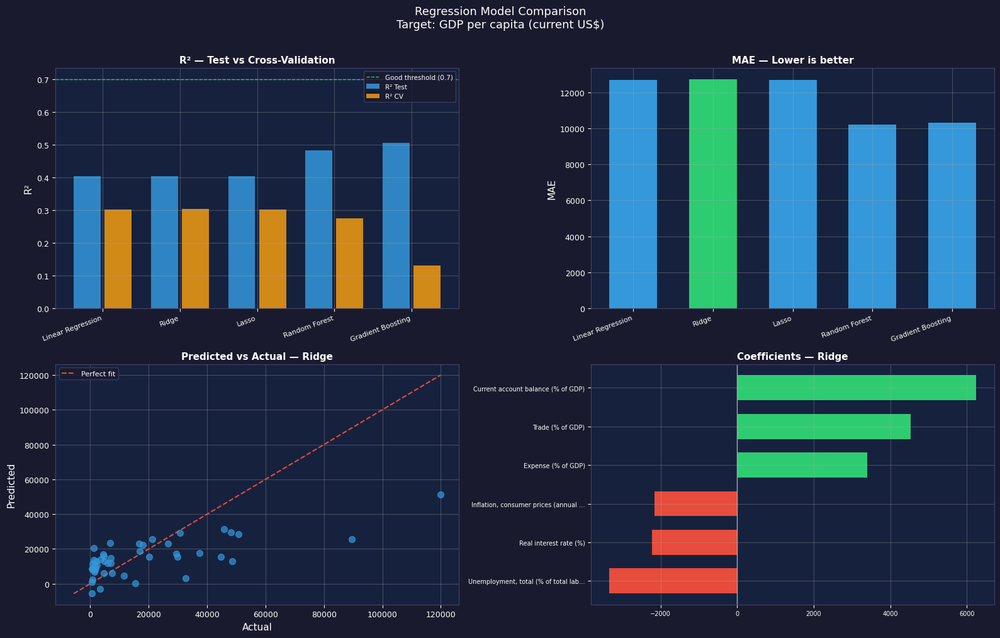


  Best model (CV R²) : Ridge  (R²_cv = 0.304)


In [291]:
reg_results, best_model, X_test = compare_regression_models(X_reg, y_reg, feat_names)

In [292]:
# Results summary table
summary_reg = pd.DataFrame({ name: {"R²_test" : v["R2_test"], "R²_cv"   : v["R2_cv"],
                                    "MAE"     : v["MAE"], "RMSE"    : v["RMSE"]
                           }    for name, v in reg_results.items() }).T.round(4)

In [293]:
summary_reg.style.format({"MAE": _format_value, "RMSE": _format_value}).background_gradient(subset=["R²_cv"], cmap="RdYlGn")

,R²_test,R²_cv,MAE,RMSE
Linear Regression,0.404600,0.302900,12.7K,18.7K
Ridge,0.403500,0.304200,12.7K,18.7K
Lasso,0.404600,0.302900,12.7K,18.7K
Random Forest,0.483100,0.274500,10.2K,17.4K
Gradient Boosting,0.507100,0.131700,10.3K,17.0K


**Regression Insights**

- `R²_cv vs R²_test gap`: if CV R² >> test R², the model is overfitting — Ridge/Lasso regularization usually helps. Tree-based models (RF, GBM) are particularly prone to this with small samples.
- `Feature importance` from tree-based models reveals which indicators
  structurally drive the target — a strong GDP per capita predictor from
  trade data directly supports the Trade × Economy synthesis in the Link notebook.
- `Coefficient signs` from linear models are directly interpretable: positive = the predictor increases the target; negative = it decreases it. A negative inflation coefficient confirms the expected GDP–inflation structural tension.

<div style="background-color: #eaf2f8; padding-left: 20px; border: 1px solid; border-radius: 5px;">

# N. Scoring
</div>

This section synthesizes all previous analyses into composite economic scores.
Each score answers a distinct economic question using a weighted combination of indicators.

| Sub-section | Score | Question |
|---|---|---|
| Economic Health | Health Score | How healthy is this economy overall? |
| Performance | Performance Score | How well is this economy performing? |
| Competitiveness | Competitiveness Score | How competitive is this economy externally? |
| Multi-score comparison | All scores | Which countries diverge across dimensions? |

This section builds composite economic scores using a **double reading**:

| Reading | Input | Question |
|---|---|---|
| **Score_value** | z-scored indicator values | Where does this country stand today? |
| **Score_growth** | Min-Max scaled growth_scores | In which direction is this country moving? |

Same indicators, same weights — only the data changes.
This distinguishes **stock** (current position) from **flux** (growth dynamics).

**Four structural quadrants per score:**

| | High Score_value | Low Score_value |
|---|---|---|
| **High Score_growth** | 🟢 Leader accelerating | 🚀 Emerging catching up |
| **Low Score_growth** | ⚠️ Leader stagnating | 🔴 Fragile — no momentum |



**Note on Score_growth normalization:**
growth_score is already z-based (built from z_cagr, z_volatility, z_share_under_pressure,
z_shock_frequency). No additional z-scoring applied.
Min-Max scaling is applied per indicator across countries to equalize amplitude
contribution — ensuring each indicator contributes within the same [-1, +1] range
regardless of its growth_score distribution width.

In [294]:
# Score definitions (Positive weight = higher is better vs Negative weight = lower is better)

WEIGHTS_HEALTH = {
                    "GDP per capita (current US$)"                                         :  0.25,
                    "Unemployment, total (% of total labor force) (modeled ILO estimate)"  : -0.20,
                    "Inflation, consumer prices (annual %)"                                : -0.20,
                    "Current account balance (% of GDP)"                                   :  0.15,
                    "Real interest rate (%)"                                               : -0.10,
                    "Expense (% of GDP)"                                                   : -0.10,
                }

WEIGHTS_PERFORMANCE = {
                        "GDP per capita (current US$)"                                         :  0.30,
                        "Unemployment, total (% of total labor force) (modeled ILO estimate)"  : -0.20,
                        "Inflation, consumer prices (annual %)"                                : -0.15,
                        "Current account balance (% of GDP)"                                   :  0.15,
                        "Trade (% of GDP)"                                                     :  0.10,
                        "Real interest rate (%)"                                               : -0.10,
                      }

WEIGHTS_COMPETITIVENESS = {
                            "Trade (% of GDP)"                                                     :  0.30,
                            "Current account balance (% of GDP)"                                   :  0.25,
                            "GDP per capita (current US$)"                                         :  0.20,
                            "Inflation, consumer prices (annual %)"                                : -0.15,
                            "Unemployment, total (% of total labor force) (modeled ILO estimate)"  : -0.10,
                          }

ALL_WEIGHTS = {
                "Economic Health" : WEIGHTS_HEALTH,
                "Performance"     : WEIGHTS_PERFORMANCE,
                "Competitiveness" : WEIGHTS_COMPETITIVENESS,
              }

# Weight rationale 
WEIGHT_RATIONALE = {
                    "Economic Health": ("Captures macroeconomic stability: high income, low unemployment, "
                                        "low inflation, external balance, low public spending pressure." ),
                    "Performance":     ("Captures overall economic output quality: income level, labor market, "
                                        "price stability, external balance, trade openness."),
                    "Competitiveness": ("Captures external positioning: trade openness, current account surplus, "
                                        "income level (productivity proxy), price stability, employment."),
                   }

# Countries to highlight
countries = ["USA", "China", "Germany", "France", "India", "Brazil", "Japan", "South Korea", "Morocco", "Nigeria", "Egypt", "South Africa"]

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 1. Score Computation
</div>

In [295]:
def compute_value_score(df: pd.DataFrame, indicator_weights:  dict, score_name: str, aggregation: str = "mean") -> pd.DataFrame:
    """    Score_value — composite score based on z-scored indicator values.  Returns DataFrame: country × [score_value, rank_value, norm_value]    """
    
    ind_names = list(indicator_weights.keys())
    data = df[(df["entity_type"]   == "COUNTRY") & (df["indicator_name"].isin(ind_names))].copy()
    if aggregation == "mean":        agg = data.groupby(["country_name", "indicator_name"])["value"].mean()
    else:                            agg = (data.sort_values("year").groupby(["country_name", "indicator_name"])["value"].last())

    pivot = agg.unstack("indicator_name").fillna(agg.unstack("indicator_name").median())

    # Z-score normalize each indicator
    scaler   = StandardScaler()
    pivot_z  = pd.DataFrame(scaler.fit_transform(pivot), index=pivot.index, columns=pivot.columns)

    # Weighted sum
    score = pd.Series(0.0, index=pivot_z.index)
    for ind, w in indicator_weights.items():
        if ind in pivot_z.columns:   score += pivot_z[ind] * w

    result = (pd.DataFrame({"country_name": score.index, score_name: score.values}).sort_values(score_name, ascending=False).reset_index(drop=True))
    result[f"{score_name}_rank"]  = result.index + 1
    s_min, s_max = result[score_name].min(), result[score_name].max()
    result[f"{score_name}_norm"]  = ((result[score_name] - s_min) / (s_max - s_min + 1e-9) * 100)
    
    return result

In [296]:
def compute_growth_score_agg(growth_df: pd.DataFrame, indicator_weights: dict, score_name: str) -> pd.DataFrame:
    """    Score_growth — composite score based on Min-Max scaled growth_scores.   Returns DataFrame: country × [score_growth, rank_growth, norm_growth]    """
    
    ind_names = list(indicator_weights.keys())
    data = growth_df[growth_df["indicator_name"].isin(ind_names)].dropna(subset=["growth_score"]).copy()

    # Pivot: country × indicator → growth_score
    pivot = (data.groupby(["country_name", "indicator_name"])["growth_score"].mean().unstack("indicator_name"))
    pivot = pivot.fillna(pivot.median())

    # MinMaxScaler 
    scaler      = MinMaxScaler(feature_range=(-1, 1))
    pivot_mm    = pd.DataFrame(scaler.fit_transform(pivot), index=pivot.index, columns=pivot.columns)

    # Weighted sum — same weights as Score_value
    score = pd.Series(0.0, index=pivot_mm.index)
    for ind, w in indicator_weights.items():
        if ind in pivot_mm.columns:   score += pivot_mm[ind] * w

    result = (pd.DataFrame({"country_name": score.index, score_name: score.values}).sort_values(score_name, ascending=False).reset_index(drop=True))
    result[f"{score_name}_rank"]  = result.index + 1
    s_min, s_max = result[score_name].min(), result[score_name].max()
    result[f"{score_name}_norm"]  = ((result[score_name] - s_min) / (s_max - s_min + 1e-9) * 100)
    
    return result

In [297]:
# Compute scores
scores = {} 

for score_name, weights in ALL_WEIGHTS.items():
    val_name    = f"{score_name}_value"
    growth_name = f"{score_name}_growth"
    scores[val_name]    = compute_value_score(df, weights, val_name)
    scores[growth_name] = compute_growth_score_agg(growth_df, weights, growth_name)

    print(f"✅ {score_name:<20} "  f"value: {len(scores[val_name])} countries  "  f"growth: {len(scores[growth_name])} countries")

✅ Economic Health      value: 209 countries  growth: 208 countries
✅ Performance          value: 209 countries  growth: 208 countries
✅ Competitiveness      value: 209 countries  growth: 208 countries


In [298]:
scores["Economic Health_value"].sample()
scores["Performance_value"].sample()
scores["Competitiveness_value"].sample()
scores["Economic Health_growth"].sample()
scores["Performance_growth"].sample()
scores["Competitiveness_growth"].sample()

,country_name,Competitiveness_growth,Competitiveness_growth_rank,Competitiveness_growth_norm
148,El Salvador,0.0060,149,52.1448


In [299]:
df_Economic_Health_value = scores["Economic Health_value"]
df_Performance_value = scores["Performance_value"]
df_Competitiveness_value = scores["Competitiveness_value"]
df_Economic_Health_growth = scores["Economic Health_growth"]
df_Performance_growth = scores["Performance_growth"]
df_Competitiveness_growth = scores["Competitiveness_growth"]

In [300]:
for dfs in [df_Economic_Health_value, df_Performance_value, df_Competitiveness_value]:
    display(dfs[dfs.columns[1]].describe())
    display(dfs[dfs["country_name"].isin(countries)])
    display(dfs.head(5))
    display(dfs.tail(5))

count   209.0000
mean      0.0000
std       0.4786
min      -1.3815
25%      -0.3028
50%       0.0011
75%       0.1969
max       1.5544
Name: Economic Health_value, dtype: float64

,country_name,Economic Health_value,Economic Health_value_rank,Economic Health_value_norm
13,USA,0.7568,14,72.8337
16,Japan,0.7116,17,71.2947
17,Germany,0.7071,18,71.1404
49,China,0.2067,50,54.0966
65,France,0.1130,66,50.9050
99,India,0.0314,100,48.1253
119,Nigeria,-0.0486,120,45.4003
143,Morocco,-0.1653,144,41.4257
158,Egypt,-0.3115,159,36.4452
188,Brazil,-0.5496,189,28.3358


,country_name,Economic Health_value,Economic Health_value_rank,Economic Health_value_norm
0,Bermuda,1.5544,1,100.0000
1,"China, Macao SAR",1.3277,2,92.2782
2,Singapore,1.3200,3,92.0179
3,Luxembourg,1.3171,4,91.9169
4,Switzerland,1.2813,5,90.6973


,country_name,Economic Health_value,Economic Health_value_rank,Economic Health_value_norm
204,South Africa,-0.9550,205,14.5277
205,State of Palestine,-0.9980,206,13.0617
206,Venezuela,-1.2052,207,6.0052
207,Lebanon,-1.2108,208,5.8163
208,Sudan,-1.3815,209,0.0000


count   209.0000
mean      0.0000
std       0.5545
min      -1.4694
25%      -0.3464
50%      -0.0720
75%       0.2582
max       2.1881
Name: Performance_value, dtype: float64

,country_name,Performance_value,Performance_value_rank,Performance_value_norm
18,Germany,0.7715,19,61.2685
20,USA,0.7279,21,60.0747
27,Japan,0.5688,28,55.7269
44,France,0.3172,45,48.8474
69,China,0.0688,70,42.0562
109,Nigeria,-0.0859,110,37.8246
134,India,-0.2058,135,34.5484
147,Morocco,-0.2456,148,33.4591
159,Egypt,-0.3826,160,29.7143
190,Brazil,-0.6252,191,23.0792


... (2 outputs left out)

count   209.0000
mean      0.0000
std       0.6383
min      -1.9414
25%      -0.3475
50%      -0.1283
75%       0.2425
max       2.8644
Name: Competitiveness_value, dtype: float64

,country_name,Competitiveness_value,Competitiveness_value_rank,Competitiveness_value_norm
23,Germany,0.6374,24,53.6606
58,Japan,0.2193,59,44.9608
60,USA,0.1736,61,44.0099
62,France,0.1648,63,43.8266
100,Nigeria,-0.1124,101,38.0585
104,China,-0.1283,105,37.7268
118,Morocco,-0.1867,119,36.5120
154,India,-0.3171,155,33.7996
175,Brazil,-0.4473,176,31.0890
185,Egypt,-0.5669,186,28.6014


,country_name,Competitiveness_value,Competitiveness_value_rank,Competitiveness_value_norm
0,Luxembourg,2.8644,1,100.0000
1,Singapore,2.5615,2,93.6983
2,"China, Hong Kong SAR",2.2765,3,87.7678
3,San Marino,1.9621,4,81.2244
4,Ireland,1.7149,5,76.0817


,country_name,Competitiveness_value,Competitiveness_value_rank,Competitiveness_value_norm
204,South Sudan,-1.1401,205,16.6733
205,Zimbabwe,-1.2408,206,14.5782
206,Lebanon,-1.3316,207,12.6883
207,Sudan,-1.7304,208,4.3897
208,Venezuela,-1.9414,209,0.0000


**Value Scores — Analytical Notes**

`Atypical top performers*` — Bermuda, Macao, Cayman Islands, Andorra,
Faroe Islands consistently rank in the top 20 across all three scores.
Their high rankings reflect near-zero unemployment and low inflation
rather than broad macroeconomic strength — these are offshore, tourism,
or fishing economies, not representative of classical economic health.
Same observation for Djibouti (#12 Competitiveness) and Marshall Islands,
Brunei — port transit and rentier economies inflated by Trade % GDP.

`Large economies penalized by structural deficits` — China (#50 Health,
#106 Competitiveness) and India (#98 Health, #134 Performance) rank
surprisingly low for the 2nd and 5th largest economies. Both are penalized
by persistent current account deficits, elevated inflation, and
still-moderate GDP/capita relative to global leaders. USA declines from
Health (#14) to Performance (#21) to Competitiveness (#61) — its chronic
trade deficit systematically reduces scores as external balance weight
increases. Japan follows the same pattern.

`France rises from Health (#66) to Performance (#45)` — its moderate
but consistent trade openness (Trade % GDP weight = 0.10) gives it an
edge on Performance that Health does not capture.

`South Africa (#205–206 across scores)` — structurally penalized by
very high unemployment (~33%) and a persistent current account deficit.
Consistent bottom ranking across all three dimensions.

`Rwanda` — bottom 20 on both Performance and Competitiveness despite
its strong growth reputation. Value scores measure current structural
levels, not dynamics. A high current account deficit and import
dependency explain the low ranking. Rwanda is the clearest case for
the value vs growth double reading — expected to score very differently
on growth scores. This is precisely what Section N is designed to reveal.

Same observation for small Gulf states (Qatar, UAE) — their high GDP per capita
  and near-zero unemployment create atypical z-scores that are not representative
  of broad economic health.
`Design choice` : these countries are not excluded — their scores reflect
  their real structural position. The analyst should be aware of this when
  interpreting top-10 rankings.

`Verdict — weights are coherent.` Rankings are economically
justifiable across all three scores. Divergences between scores
(Rwanda, USA, China, France) are analytically explainable and
represent the most interesting cases for the value vs growth
quadrant analysis.

In [301]:
for df in [df_Economic_Health_growth, df_Performance_growth, df_Competitiveness_growth]:
    display(df[df.columns[1]].describe())
    display(df[df["country_name"].isin(countries)])
    display(df.head(5))
    display(df.tail(5))

count   208.0000
mean     -0.1046
std       0.1220
min      -0.4104
25%      -0.1816
50%      -0.1101
75%      -0.0432
max       0.2575
Name: Economic Health_growth, dtype: float64

,country_name,Economic Health_growth,Economic Health_growth_rank,Economic Health_growth_norm
23,India,0.0604,24,70.4853
33,Germany,0.0300,34,65.9465
41,USA,-0.0009,42,61.3142
59,Morocco,-0.0588,60,52.6461
83,Egypt,-0.0859,84,48.5882
102,Japan,-0.1064,103,45.5161
113,Brazil,-0.1204,114,43.4135
143,China,-0.1682,144,36.2613
160,South Africa,-0.1867,161,33.4855
171,France,-0.2054,172,30.6932


,country_name,Economic Health_growth,Economic Health_growth_rank,Economic Health_growth_norm
0,Comoros,0.2575,1,100.0000
1,Serbia,0.2216,2,94.6340
2,Georgia,0.1466,3,83.3968
3,Ireland,0.1451,4,83.1787
4,Croatia,0.1307,5,81.0130


,country_name,Economic Health_growth,Economic Health_growth_rank,Economic Health_growth_norm
203,Mozambique,-0.3509,204,8.8959
204,Lesotho,-0.3541,205,8.4217
205,Afghanistan,-0.3847,206,3.8459
206,Myanmar,-0.4006,207,1.4587
207,Nigeria,-0.4104,208,0.0000


count   208.0000
mean      0.0021
std       0.1297
min      -0.3511
25%      -0.0774
50%      -0.0073
75%       0.0748
max       0.3378
Name: Performance_growth, dtype: float64

,country_name,Performance_growth,Performance_growth_rank,Performance_growth_norm
20,India,0.1912,21,78.7261
36,Germany,0.1386,37,71.0797
44,USA,0.1087,45,66.7451
55,Morocco,0.0676,56,60.7729
88,Egypt,0.0169,89,53.4193
93,Brazil,0.0056,94,51.7696
114,Japan,-0.0206,115,47.9775
134,China,-0.0525,135,43.3356
140,South Africa,-0.0592,141,42.3671
173,France,-0.1165,174,34.0481


... (2 outputs left out)

count   208.0000
mean      0.0671
std       0.1270
min      -0.4185
25%      -0.0055
50%       0.0723
75%       0.1583
max       0.3955
Name: Competitiveness_growth, dtype: float64

,country_name,Competitiveness_growth,Competitiveness_growth_rank,Competitiveness_growth_norm
27,India,0.2070,28,76.8446
49,Germany,0.1625,50,71.3787
51,South Africa,0.1615,52,71.2489
53,Brazil,0.1534,54,70.2589
61,Morocco,0.1306,62,67.4634
68,Japan,0.1227,69,66.4815
77,USA,0.1030,78,64.0645
86,China,0.0929,87,62.8265
106,Egypt,0.0706,107,60.0905
190,France,-0.1161,191,37.1497


,country_name,Competitiveness_growth,Competitiveness_growth_rank,Competitiveness_growth_norm
0,Comoros,0.3955,1,100.0000
1,San Marino,0.3505,2,94.4743
2,Togo,0.3431,3,93.5628
3,Serbia,0.3241,4,91.2275
4,Jamaica,0.3229,5,91.0849


,country_name,Competitiveness_growth,Competitiveness_growth_rank,Competitiveness_growth_norm
203,New Zealand,-0.1645,204,31.2061
204,Venezuela,-0.2311,205,23.0195
205,Kiribati,-0.2652,206,18.8292
206,Turkmenistan,-0.2927,207,15.4534
207,Sudan,-0.4185,208,0.0000


**Growth Scores — Key Observations**

- Eastern European economies (Croatia, Serbia, Poland, Portugal, Cyprus)
dominate all three growth rankings — structural convergence toward EU
standards drives momentum across health, performance and competitiveness.
- India ranks top among highlights on all three growth dimensions —
the clearest catch-up profile in the dataset.
- France ranks bottom 20 on all three growth dimensions — a persistent structural
  deceleration, not a temporary shock. This is one of the strongest findings
  in this dataset.
- Nigeria bottom, Sudan bottom — growth momentum confirms value position.
- Rwanda appears in Competitiveness_growth top 20 — its growth score
finally reflects its reputation, confirming the value vs growth gap.

**Global Verdict**

Value scores measure where countries stand today.
Growth scores measure where they are heading.

The most analytically revealing cases are those where the two diverge:

- `India` — low value, high growth → emerging catch-up
- `France` — moderate value, low growth → structural deceleration  
- `Rwanda` — low value, high competitiveness growth → transition economy
- `Germany` — stable across all six scores, confirming structural resilience
  as a consistent analytical pattern, not a single-year result.
- `Nigeria` — low on all six → no momentum to compensate weak position

Weights are economically coherent across all three scores.
Atypical top performers (Bermuda, Cayman, Macao) reflect structural
specificities — offshore or transit economies — not classical
macroeconomic strength.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 2. Score Analysis
</div>

In [302]:
def plot_score_ranking(score_df: pd.DataFrame, score_name: str, countries:  list[str] | None = None, top_n: int = 20,
                       figsize:    tuple = (14, 6)) -> None:
    """   Top N / Bottom N globally   —      Selected countries spotlight with rank    """
    
    fig, (ax1, ax2) = styled_subplots(nrows=1, ncols=2, figsize=figsize)
    fig.suptitle(f"Score Ranking — {score_name}", fontsize=13, color="white", y=1.01)

    # Top N / Bottom N
    n2     = top_n // 2
    top    = score_df.head(n2).sort_values(score_name)
    bot    = score_df.tail(n2).sort_values(score_name)
    combo  = pd.concat([bot, top])

    bar_colors = [C["green"] if v >= 0 else C["red"]  for v in combo[score_name]]
    bars = ax1.barh(combo["country_name"], combo[score_name], color=bar_colors, edgecolor="none", height=0.7)
    ax1.axvline(0, color=C["grey"], linewidth=1)
    for bar, val in zip(bars, combo[score_name]):
        offset = 0.01 if val >= 0 else -0.01
        ax1.text(val + offset, bar.get_y() + bar.get_height() / 2, f"{val:+.2f}", va="center", color="white", fontsize=8.5)
    ax1.set_xlabel("Score", color="white")
    ax1.set_title(f"Top {n2} & Bottom {n2}", fontsize=11, color="white")

    # selected countries 
    if countries:
        hl = (score_df[score_df["country_name"].isin(countries)].sort_values(score_name))
        palette   = plt.cm.tab10.colors
        hl_colors = [palette[i % 10] for i in range(len(hl))]
        bars2 = ax2.barh(hl["country_name"], hl[score_name], color=hl_colors, edgecolor="none", height=0.7)
        ax2.axvline(0, color=C["grey"], linewidth=1)
        rank_col = f"{score_name}_rank"
        for bar, (_, row) in zip(bars2, hl.iterrows()):
            ax2.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2, f"Rank #{int(row[rank_col])}", va="center", color="white", fontsize=7.5)
        ax2.set_xlabel("Score", color="white")
        ax2.set_title("Selected Countries", fontsize=11, color="white")

    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/N_2_{score_name}_ranking.png')
    plt.show()

In [303]:
def plot_value_vs_growth(val_df: pd.DataFrame, growth_df_s:pd.DataFrame, val_name: str, growth_name:str, score_label:str,
                         highlight:  list[str] | None = None, figsize: tuple = (13, 7)) -> None:
    """    Quadrant scatter: Score_value (x) vs Score_growth (y). Four quadrants reveal structural position vs momentum    """
    
    merged = val_df[["country_name", val_name]].merge(growth_df_s[["country_name", growth_name]], on="country_name", how="inner").dropna()

    x_med = merged[val_name].median()
    y_med = merged[growth_name].median()

    highlight = highlight or []
    palette   = plt.cm.tab10.colors

    fig, ax = styled_figure(figsize=figsize)
    ax.set_title(f"{score_label} — Position vs Momentum\n" 
                 f"x = Score_value (where today)  |  "  f"y = Score_growth (where heading)", fontsize=12, color="white", pad=12)

    # Quadrant lines
    ax.axvline(x_med, color=C["grey"], linewidth=1, linestyle="--", alpha=0.6)
    ax.axhline(y_med, color=C["grey"], linewidth=1, linestyle="--", alpha=0.6)

    # Quadrant labels
    for tx, ty, label, color in [
                                    (0.02, 0.97, " Emerging catch-up",    C["blue"]),
                                    (0.60, 0.97, " Leader accelerating",  C["green"]),
                                    (0.02, 0.04, " Fragile — no momentum", C["red"]),
                                    (0.60, 0.04, " Leader stagnating",   C["orange"])
                                ]:
        ax.text(tx, ty, label, transform=ax.transAxes, fontsize=8.5, color=color, alpha=0.85, bbox=dict(facecolor="white"))

    # Background countries
    bg = merged[~merged["country_name"].isin(highlight)]
    ax.scatter(bg[val_name], bg[growth_name], color=C["grey"], s=40, alpha=0.3, zorder=2)

    # Highlighted countries
    for i, cntry in enumerate(highlight):
        row = merged[merged["country_name"] == cntry]
        if row.empty:  continue
        color = palette[i % 10]
        ax.scatter(row[val_name], row[growth_name], color=color, s=150, alpha=0.95, edgecolors="white", linewidth=0.7, zorder=4)
        ax.annotate(cntry, (row[val_name].values[0], row[growth_name].values[0]), xytext=(5, 4), textcoords="offset points", fontsize=9, color=color)

    # Spearman correlation
    corr, pval = spearmanr(merged[val_name], merged[growth_name])
    
    ax.text(0.98, 0.02, f"Spearman r = {corr:.3f}  (p = {pval:.3f})", transform=ax.transAxes, ha="right", va="bottom", fontsize=8.5, color="white",
            bbox=dict(boxstyle="round,pad=0.3", facecolor=C["ax_bg"], edgecolor=C["spine"], alpha=0.85))
    ax.set_xlabel(f"{score_label} — Value Score", color="white")
    ax.set_ylabel(f"{score_label} — Growth Score", color="white")
    
    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/N_2_{score_label}_[value_vs_growth].png')
    plt.show()

In [304]:
def print_sanity_check(val_df: pd.DataFrame, score_name: str, top_n: int = 10) -> None:
    """    Sanity check: display top and bottom countries.     Verify that results are economically coherent.    """
    
    rank_col = f"{score_name}_rank"
    norm_col = f"{score_name}_norm"
    
    if rank_col not in val_df.columns:
        print(f"⚠️  Column {rank_col} not found")
        return

    print(f"\n{'═'*55}")
    print(f"  SANITY CHECK — {score_name}")
    print(f"  TOP {top_n} — expected: stable, high-income economies")
    print(f"{'─'*55}")
    for _, r in val_df.head(top_n).iterrows():
        norm = f"{r[norm_col]:.1f}" if norm_col in val_df.columns else ""
        print(f"    #{int(r[rank_col]):<4} {r['country_name']:<35} {norm}")

    print(f"\n  BOTTOM {top_n} — expected: fragile, crisis economies")
    print(f"{'─'*55}")
    for _, r in val_df.tail(top_n).sort_values(rank_col).iterrows():
        norm = f"{r[norm_col]:.1f}" if norm_col in val_df.columns else ""
        print(f"    #{int(r[rank_col]):<4} {r['country_name']:<35} {norm}")

    print(f"{'═'*55}")


📖 Captures macroeconomic stability: high income, low unemployment, low inflation, external balance, low public spending pressure.

═══════════════════════════════════════════════════════
  SANITY CHECK — Economic Health_value
  TOP 10 — expected: stable, high-income economies
───────────────────────────────────────────────────────
    #1    Bermuda                             100.0
    #2    China, Macao SAR                    92.3
    #3    Singapore                           92.0
    #4    Luxembourg                          91.9
    #5    Switzerland                         90.7
    #6    Qatar                               86.0
    #7    Norway                              84.7
    #8    United Arab Emirates                84.3
    #9    Ireland                             82.5
    #10   Iceland                             75.5

  BOTTOM 10 — expected: fragile, crisis economies
───────────────────────────────────────────────────────
    #200  Zimbabwe                            21

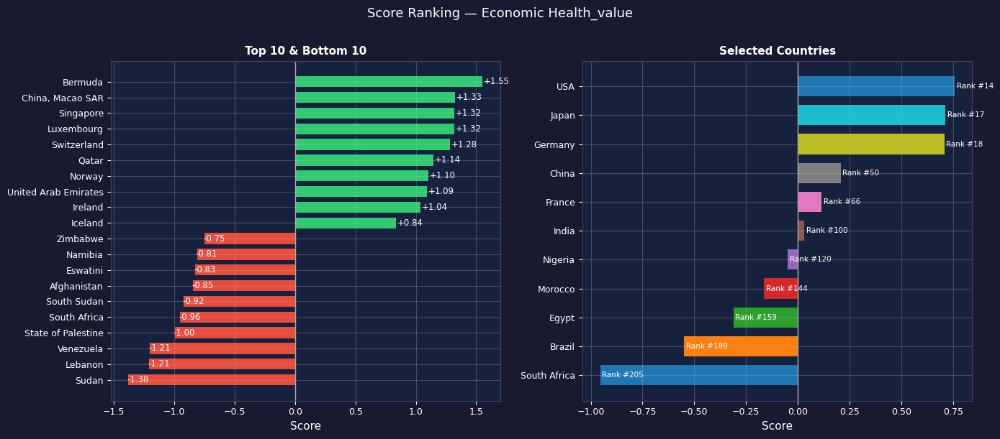

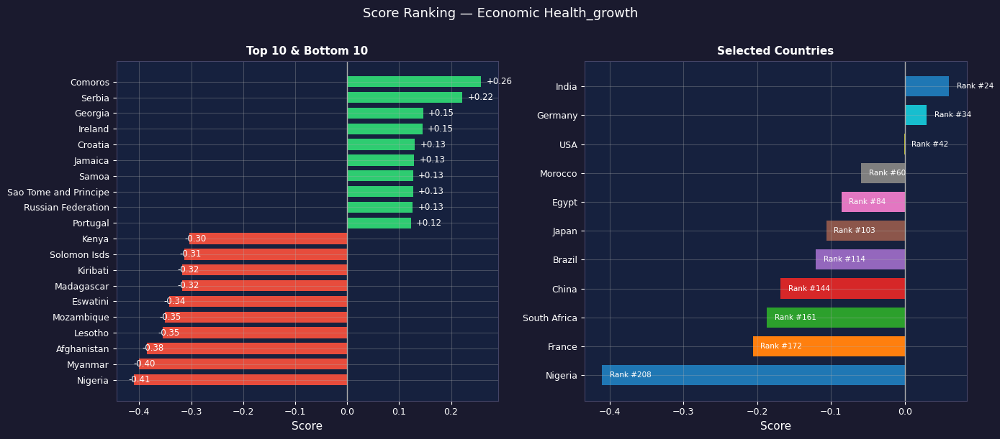

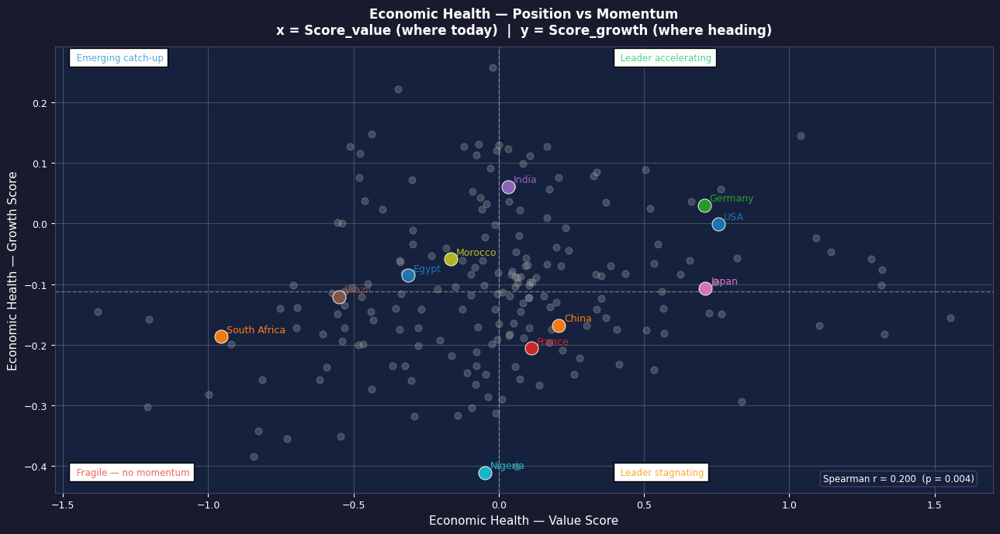

In [305]:
# Economic Health
print(f"\n📖 {WEIGHT_RATIONALE['Economic Health']}")

print_sanity_check(scores["Economic Health_value"], "Economic Health_value")

plot_score_ranking(scores["Economic Health_value"], "Economic Health_value", countries)
plot_score_ranking(scores["Economic Health_growth"],"Economic Health_growth", countries)

plot_value_vs_growth(scores["Economic Health_value"], scores["Economic Health_growth"], 
                     "Economic Health_value", "Economic Health_growth", "Economic Health", highlight=countries)

**Economic Health Insights**

- Score_value ranks countries by their current macroeconomic health — stable, low-unemployment, low-inflation economies score highest.
- Score_growth reveals the direction of change — a country can rank high on value but low on growth if its health indicators are deteriorating.
- The quadrant scatter is the key analytical tool: countries in the top-right (Leader accelerating) are both healthy and improving; bottom-left (Fragile) are doubly vulnerable.
- `France (moderate value, strongly negative growth)` is the most analytically
  significant case — a developed economy systematically deteriorating on all
  three health dimensions. Not a transition or crisis economy, but a structural
  deceleration that is persistent and confirmed across all scores.


📖 Captures overall economic output quality: income level, labor market, price stability, external balance, trade openness.

═══════════════════════════════════════════════════════
  SANITY CHECK — Performance_value
  TOP 10 — expected: stable, high-income economies
───────────────────────────────────────────────────────
    #1    Luxembourg                          100.0
    #2    Singapore                           88.5
    #3    Bermuda                             87.5
    #4    China, Macao SAR                    80.7
    #5    Ireland                             79.4
    #6    Switzerland                         78.8
    #7    China, Hong Kong SAR                76.7
    #8    Norway                              76.2
    #9    Qatar                               74.2
    #10   San Marino                          72.6

  BOTTOM 10 — expected: fragile, crisis economies
───────────────────────────────────────────────────────
    #200  Saint Vincent and the Grenadines    19.0
    #201

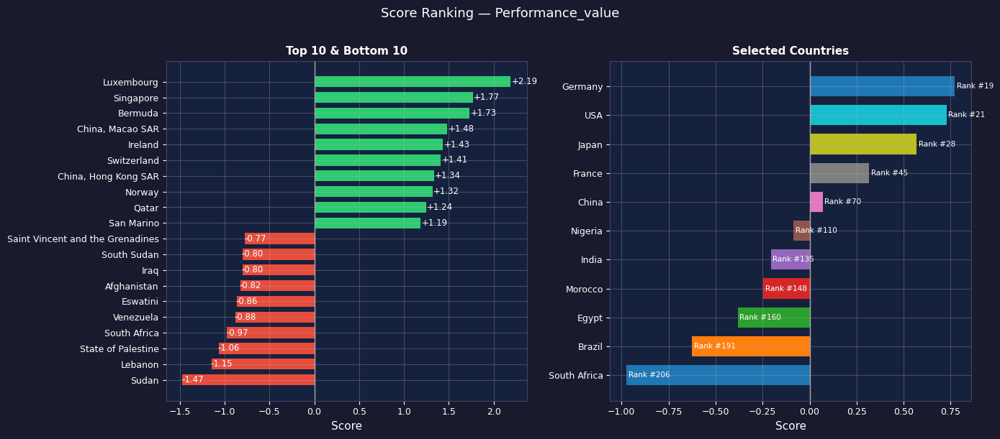

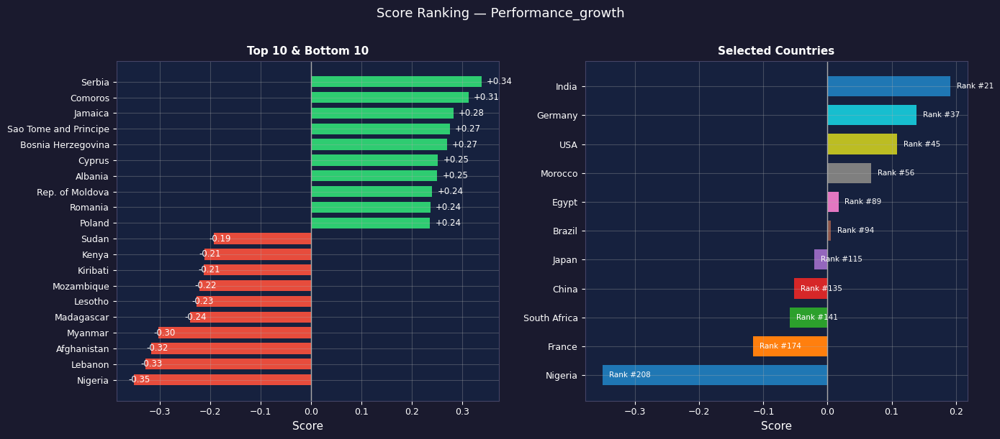

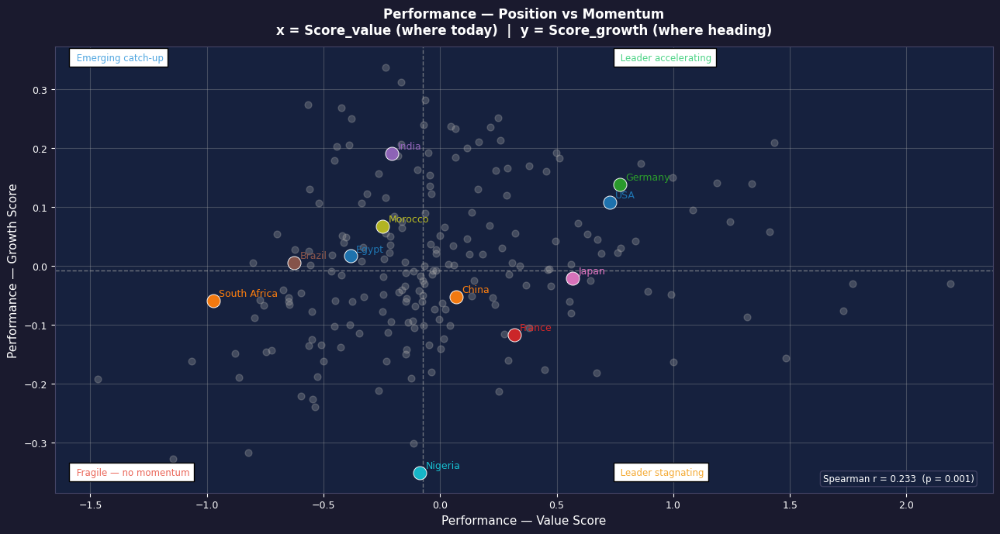

In [306]:
# Performance
print(f"\n📖 {WEIGHT_RATIONALE['Performance']}")

print_sanity_check(scores["Performance_value"], "Performance_value")

plot_score_ranking(scores["Performance_value"], "Performance_value", countries)
plot_score_ranking(scores["Performance_growth"], "Performance_growth", countries)

plot_value_vs_growth(scores["Performance_value"], scores["Performance_growth"],
                     "Performance_value", "Performance_growth", "Performance", highlight=countries)

**Performance Insights**

- Score_value rewards output quality and external balance — Germany
  overtakes USA due to its structural trade surplus.
- Score_growth reveals momentum — India and Eastern European economies
  dominate, while France deteriorates systematically.
- The quadrant scatter highlights the USA paradox: high value but
  moderate growth — a powerful but relatively closed economy.


📖 Captures external positioning: trade openness, current account surplus, income level (productivity proxy), price stability, employment.

═══════════════════════════════════════════════════════
  SANITY CHECK — Competitiveness_value
  TOP 10 — expected: stable, high-income economies
───────────────────────────────────────────────────────
    #1    Luxembourg                          100.0
    #2    Singapore                           93.7
    #3    China, Hong Kong SAR                87.8
    #4    San Marino                          81.2
    #5    Ireland                             76.1
    #6    China, Macao SAR                    74.8
    #7    United Arab Emirates                69.2
    #8    Bermuda                             69.2
    #9    Malta                               68.9
    #10   Switzerland                         66.5

  BOTTOM 10 — expected: fragile, crisis economies
───────────────────────────────────────────────────────
    #200  Dominica                      

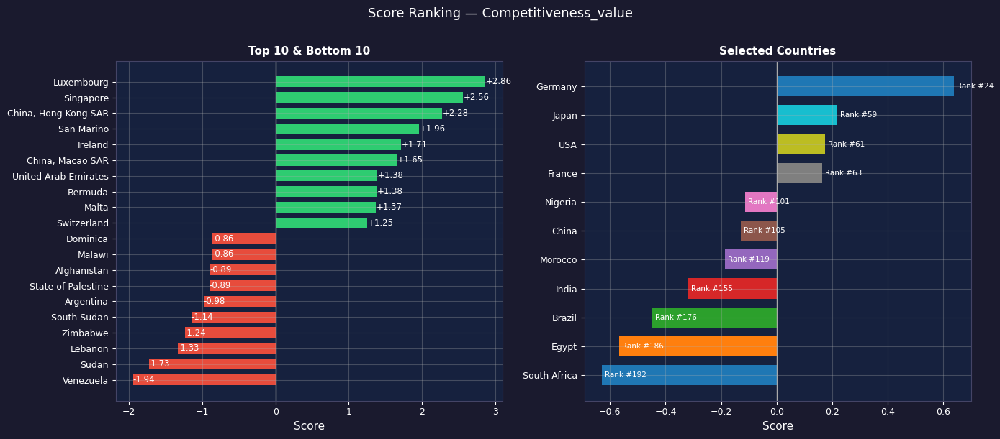

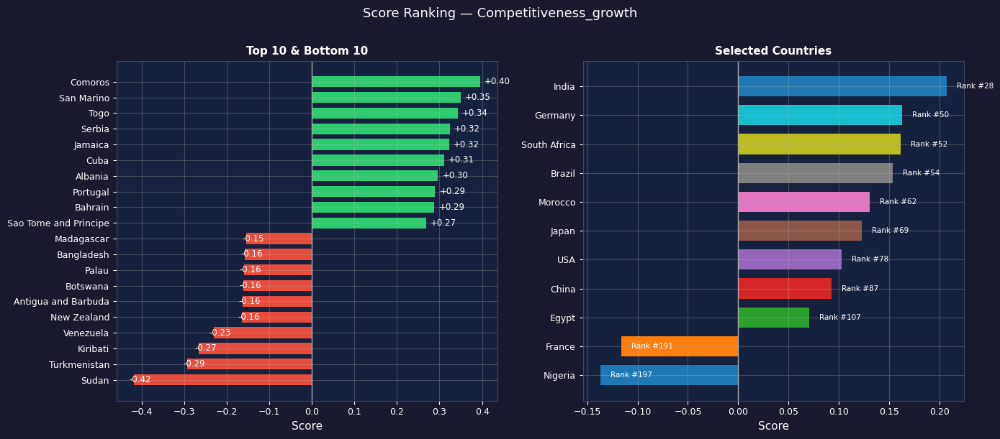

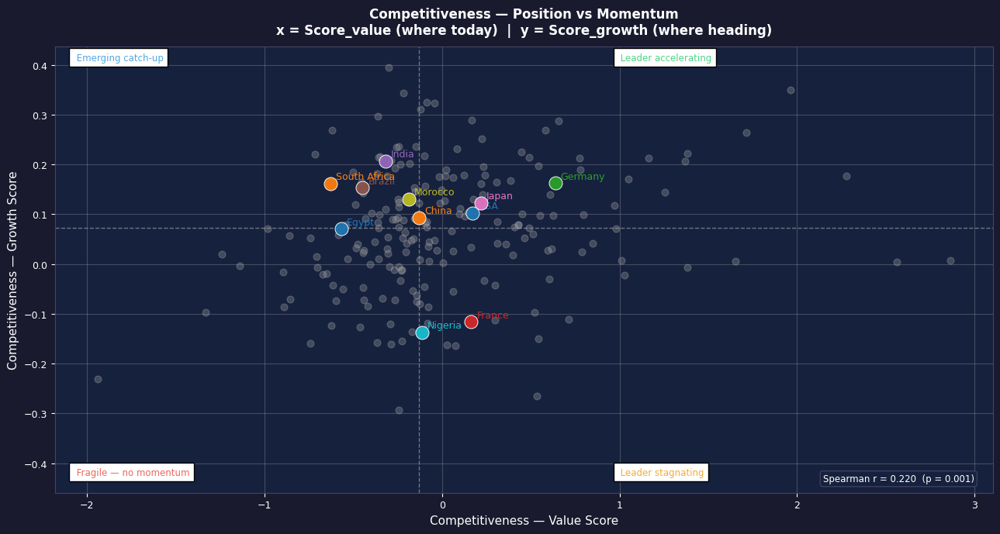

In [307]:
# Competitiveness
print(f"\n📖 {WEIGHT_RATIONALE['Competitiveness']}")

print_sanity_check(scores["Competitiveness_value"], "Competitiveness_value")

plot_score_ranking(scores["Competitiveness_value"],  "Competitiveness_value", countries)
plot_score_ranking(scores["Competitiveness_growth"], "Competitiveness_growth", countries)

plot_value_vs_growth(scores["Competitiveness_value"], scores["Competitiveness_growth"],
                     "Competitiveness_value", "Competitiveness_growth", "Competitiveness", highlight=countries)

**Competitiveness Insights**

- Score_value is the most dispersed (std = 0.64) — small open economies
  (Luxembourg, Singapore, Hong Kong) dominate due to high Trade % GDP.
- Score_growth shows broad improvement — most countries are becoming
  more competitive, confirming post-COVID trade recovery.
- The quadrant scatter reveals Rwanda and South Africa moving toward
  catch-up despite low value positions — the clearest cases for
  the value vs growth double reading.

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 3. Multi-Score Comparison
</div>

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">

### 3.1 Multi Score Table
</div>

In [308]:
def build_multi_score_table(scores: dict[str, pd.DataFrame]) -> pd.DataFrame:
    """    Merge all score DataFrames into one wide table.    Adds rank_divergence per reading (value / growth)    """
    
    result = None
    for score_name, df_s in scores.items():
        cols = ["country_name"] + [c for c in df_s.columns if c != "country_name"]
        sub = df_s[cols]
        if result is None:         result = sub
        else:                      result = result.merge(sub, on="country_name", how="outer")

    # Rank divergence for value scores
    val_rank_cols = [c for c in result.columns if c.endswith("_rank") and "value" in c]
    if len(val_rank_cols) > 1:
        result["rank_div_value"] = (result[val_rank_cols].max(axis=1) - result[val_rank_cols].min(axis=1))

    # Rank divergence for growth scores
    growth_rank_cols = [c for c in result.columns if c.endswith("_rank") and "growth" in c]
    if len(growth_rank_cols) > 1:
        result["rank_div_growth"] = (result[growth_rank_cols].max(axis=1) - result[growth_rank_cols].min(axis=1))

    return result.sort_values("rank_div_value", ascending=False).reset_index(drop=True)

In [309]:
score_name_list = list(ALL_WEIGHTS.keys())
multi_df = build_multi_score_table(scores)

print(f"✅ Multi-score table : {len(multi_df)} countries")

# Most divergent countries across value scores
print("\nMost divergent countries (value scores):")
multi_df.head(8)[["country_name", "rank_div_value"]].style.background_gradient(subset=["rank_div_value"], cmap="Reds")

✅ Multi-score table : 210 countries

Most divergent countries (value scores):


,country_name,rank_div_value
0,Djibouti,172.000000
1,Nauru,142.000000
2,Iraq,120.000000
3,Bangladesh,110.000000
4,Kiribati,107.000000
5,Guinea-Bissau,99.000000
6,North Macedonia,98.000000
7,Cameroon,96.000000


<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">

### 3.2 Multi Score Heatmap
</div>

In [310]:
def plot_multi_score_heatmap(multi_df: pd.DataFrame, score_names: list[str], reading: str = "value", countries: list[str] | None = None, 
                             top_n: int   = 30, figsize: tuple = (12, 6)) -> None:
    """    Heatmap of normalized scores [0-100] per country.    reading = 'value' or 'growth'    """
    
    norm_cols = [f"{n}_{reading}_norm"  for n in score_names  if f"{n}_{reading}_norm" in multi_df.columns]

    if countries:        data = multi_df[multi_df["country_name"].isin(countries)]
    else:                data = multi_df.head(top_n)

    pivot = data.set_index("country_name")[norm_cols].rename(columns={f"{n}_{reading}_norm": n for n in score_names})

    fig, ax = plt.subplots(figsize=figsize)
    fig.patch.set_facecolor(C["bg"])
    ax.set_facecolor(C["ax_bg"])

    sns.heatmap(pivot, ax=ax, cmap="RdYlGn", vmin=0, vmax=100, annot=True, fmt=".0f", annot_kws={"size": 8, "color": "black"},
                linewidths=0.4, linecolor=C["bg"], cbar_kws={"shrink": 0.6, "label": f"Normalized Score (0–100) — {reading}"})
    
    ax.set_title(f"Multi-Score Heatmap — {reading.capitalize()} Scores \n(sorted by Economic Health rank)", fontsize=13, color="white", pad=12)
    ax.tick_params(colors="white", labelsize=8)
    ax.set_xlabel("", color="white")
    ax.set_ylabel("", color="white")
    cbar = ax.collections[0].colorbar
    cbar.ax.yaxis.label.set_color("white")
    cbar.ax.tick_params(colors="white")

    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/N_3_multi_{reading}_scores_heatmap.png')
    plt.show()

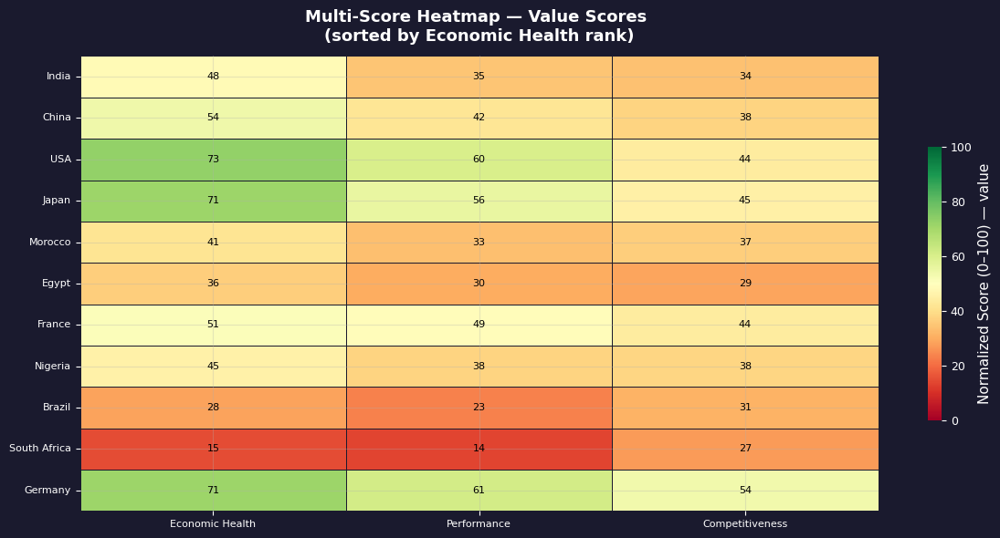

In [311]:
# Heatmap — Value scores
plot_multi_score_heatmap(multi_df, score_name_list, reading="value", countries=countries)

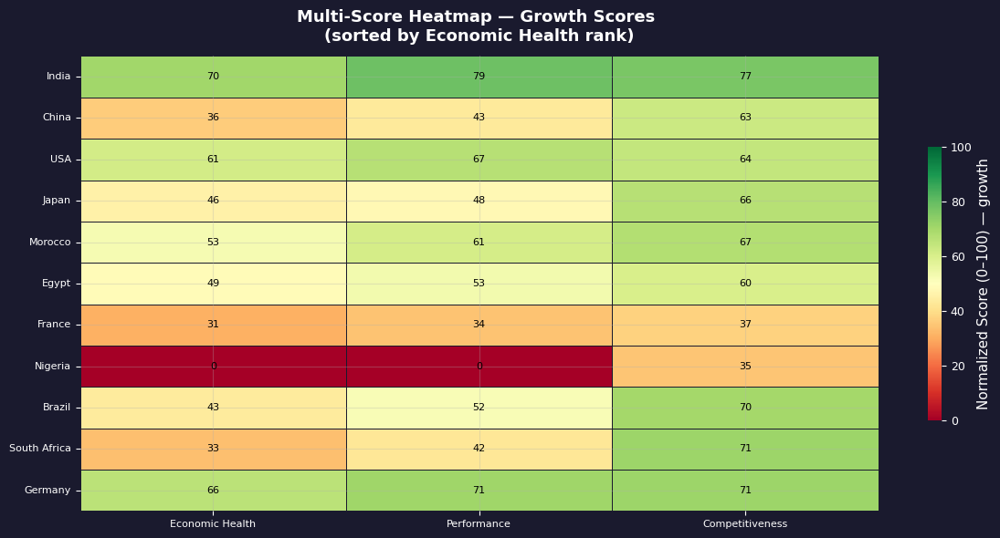

In [312]:
# Heatmap — Growth scores
plot_multi_score_heatmap(multi_df, score_name_list, reading="growth", countries=countries)

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">

### 3.3 Multi Score bump chart
</div>

In [313]:
def plot_bump_chart(scores: dict[str, pd.DataFrame], score_names: list[str], reading: str = "value", countries: list[str] | None = None,
                    figsize: tuple = (12, 6)) -> None:
    """    Bump chart: rank evolution across score dimensions.    reading = 'value' or 'growth'    """
    
    palette = plt.cm.tab10.colors
    countries = countries or []

    fig, ax = styled_figure(figsize=figsize)
    ax.set_title(f"Rank Evolution — {reading.capitalize()} Scores", fontsize=13, color="white", pad=12)

    for i, cntry in enumerate(countries):
        ranks = []
        for sname in score_names:
            key      = f"{sname}_{reading}"
            rank_col = f"{key}_rank"
            df_s     = scores.get(key, pd.DataFrame())
            row      = df_s[df_s["country_name"] == cntry]
            ranks.append(row[rank_col].values[0] if not row.empty else np.nan)

        color = palette[i % 10]
        ax.plot(score_names, ranks, color=color, linewidth=2.2, marker="o", markersize=8, label=cntry, zorder=3)

    label_data = []
    for i, cntry in enumerate(countries):
        ranks = []
        for sname in score_names:
            key      = f"{sname}_{reading}"
            rank_col = f"{key}_rank"
            df_s     = scores.get(key, pd.DataFrame())
            row      = df_s[df_s["country_name"] == cntry]
            ranks.append(row[rank_col].values[0] if not row.empty else np.nan)

        color = palette[i % 10]
        ax.plot(score_names, ranks, color=color, linewidth=2.2, marker="o", markersize=8, label=cntry, zorder=3)

        if not np.isnan(ranks[-1]):
            label_data.append((ranks[-1], cntry, color))

    # Sort by final rank and apply progressive vertical offset
    label_data.sort(key=lambda x: x[0])
    min_gap   = max(len(countries) * 0.5, 4)  # minimum vertical gap between labels
    prev_y    = -999

    for raw_y, cntry, color in label_data:
        # Push label down if too close to previous
        y_pos = raw_y if raw_y - prev_y >= min_gap else prev_y + min_gap
        prev_y = y_pos

        ax.annotate(f" {cntry} (#{int(raw_y)})", xy=(len(score_names) - 1, raw_y), xytext=(8, 0),
                    textcoords="offset points", fontsize=7.5, color=color, va="center",
                    arrowprops=dict(arrowstyle="-", color=color, lw=0.5, alpha=0.5) if abs(y_pos - raw_y) > 2 else None)


    ax.set_ylabel("Rank", color="white")
    ax.invert_yaxis()
    ax.set_xticks(range(len(score_names)))
    ax.set_xticklabels(score_names, color="white", fontsize=9)

    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))  # deduplicate
    ax.legend(by_label.values(), by_label.keys(), fontsize=7.5, facecolor=C["ax_bg"], edgecolor="#444466", 
              labelcolor="white", loc="upper left")
    
    plt.tight_layout()
    save_figure(fig, f'../Figures/Indicators/N_3_{reading}_scores_bump_chart.png')
    plt.show()

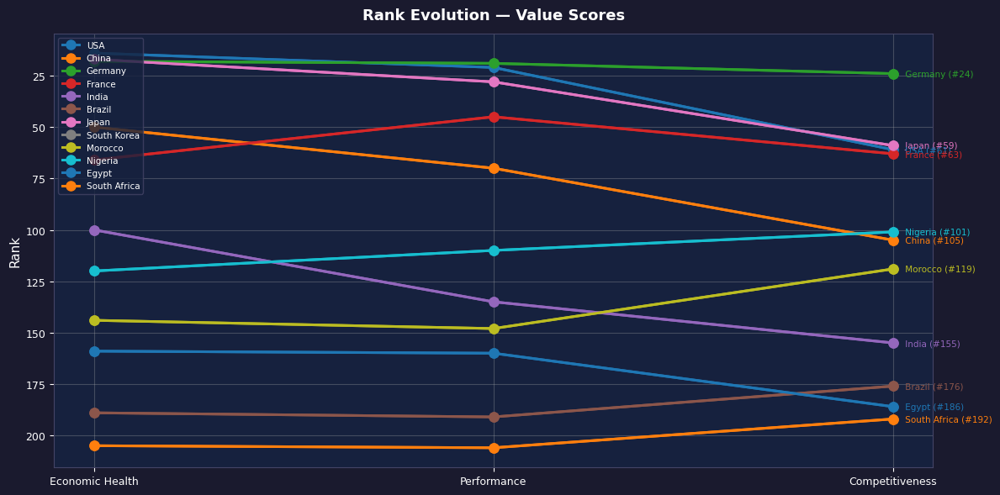

In [314]:
# Bump chart — Value scores 
plot_bump_chart(scores, score_name_list, reading="value", countries=countries)

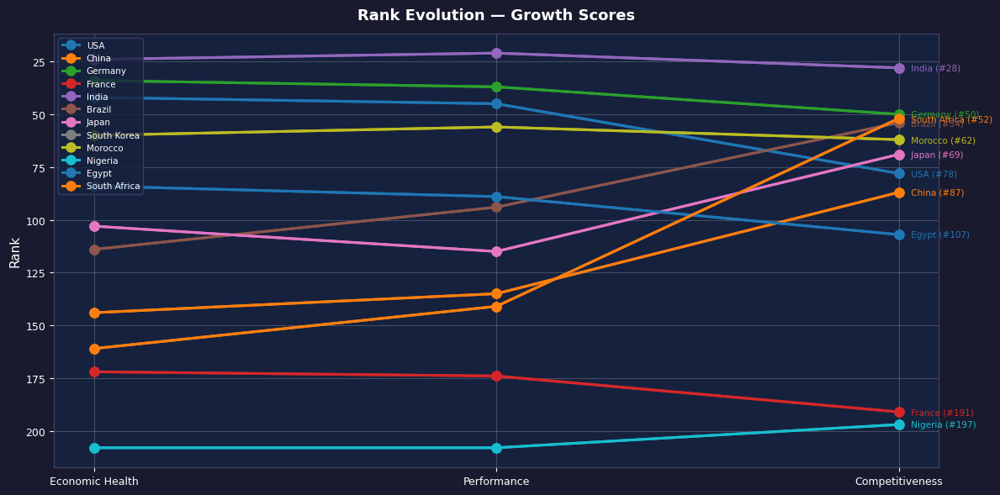

In [315]:
# Bump chart — Growth scores 
plot_bump_chart(scores, score_name_list, reading="growth", countries=countries)

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">

### 3.4 Insights
</div>

**Multi-Score Insights**

- `Value heatmap` — current structural position across all three dimensions. A country fully green is structurally strong on all dimensions; mixed colors reveal dimension-specific vulnerabilities.
- `Growth heatmap` — momentum across all three dimensions. A country green here but red on value heatmap is converging upward — an emerging economy catching up.
- `Bump chart` — rank evolution across dimensions reveals whether a country
  is consistent (stable lines) or dimension-specific (high variance). India's
  rank collapse from Economic Health to Competitiveness is the most informative
  single pattern in this section.
- Comparing value vs growth bump charts for the same country is the most analytically powerful reading: a country that drops rank from value to growth is decelerating; one that gains rank is accelerating.

<div style="background-color: #fdedec; padding-left: 20px; border: 1px solid; border-radius: 5px;">

### 3.5 Save Table
</div>

In [316]:
multi_df.to_csv("../Analysis_files/Indicators/multi_df.csv", index=False)

<div style="background-color: #e9f7ef; padding-left: 20px; border: 1px solid; border-radius: 5px;">

## 4. Output Dataset
</div>

`multi_score_df` consolidates all three scores and rankings per country.
It is the **key output** of this notebook — feeding directly into the Trade × Economy synthesis.

In [317]:
print("═" * 65)
print("  SCORES DATASET — SUMMARY")
print("═" * 65)
print(f"  📐 Shape            : {multi_df.shape}")
print(f"  🌍 Countries        : {multi_df['country_name'].nunique()}")
print(f"  📊 Scores           : {list(ALL_WEIGHTS.keys())}")
print(f"  📖 Readings         : value (position) | growth (momentum)")
print(f"  📐 Output columns   : score | rank | norm (0–100)")
print(f"  📐 Divergence       : rank_div_value | rank_div_growth")
print("═" * 65)
print("  → INPUT for Trade × Economy Synthesis Notebook")
print("═" * 65)

# Final scorecard for selected countries
value_norm_cols  = [c for c in multi_df.columns if "_value_norm" in c]
growth_norm_cols = [c for c in multi_df.columns if "_growth_norm" in c]

display_cols = (["country_name"]  + value_norm_cols + growth_norm_cols  + ["rank_div_value", "rank_div_growth"])

multi_df[multi_df["country_name"].isin(countries)][[c for c in display_cols if c in multi_df.columns]]\
                                .style.format({c: "{:.0f}" for c in value_norm_cols + growth_norm_cols}) \
                                .background_gradient(subset=value_norm_cols + growth_norm_cols, cmap="RdYlGn") \
                                .background_gradient(subset=["rank_div_value", "rank_div_growth"], cmap="Reds")

═════════════════════════════════════════════════════════════════
  SCORES DATASET — SUMMARY
═════════════════════════════════════════════════════════════════
  📐 Shape            : (210, 21)
  🌍 Countries        : 210
  📊 Scores           : ['Economic Health', 'Performance', 'Competitiveness']
  📖 Readings         : value (position) | growth (momentum)
  📐 Output columns   : score | rank | norm (0–100)
  📐 Divergence       : rank_div_value | rank_div_growth
═════════════════════════════════════════════════════════════════
  → INPUT for Trade × Economy Synthesis Notebook
═════════════════════════════════════════════════════════════════


,country_name,Economic Health_value_norm,Performance_value_norm,Competitiveness_value_norm,Economic Health_growth_norm,Performance_growth_norm,Competitiveness_growth_norm,rank_div_value,rank_div_growth
32,India,48,35,34,70,79,77,55.000000,7.000000
33,China,54,42,38,36,43,63,55.000000,57.000000
44,USA,73,60,44,61,67,64,47.000000,36.000000
60,Japan,71,56,45,46,48,66,42.000000,46.000000
94,Morocco,41,33,37,53,61,67,29.000000,6.000000
99,Egypt,36,30,29,49,53,60,27.000000,23.000000
128,France,51,49,44,31,34,37,21.000000,19.000000
133,Nigeria,45,38,38,0,0,35,19.000000,11.000000
144,Brazil,28,23,31,43,52,70,15.000000,60.000000
148,South Africa,15,14,27,33,42,71,14.000000,109.000000


**Competitiveness Insights**

- Score_value is the most dispersed (std = 0.64) — small open economies
  (Luxembourg, Singapore, Hong Kong) dominate due to high Trade % GDP.
- Score_growth shows broad improvement — most countries are becoming
  more competitive, confirming post-COVID trade recovery.
- The quadrant scatter reveals Rwanda and South Africa moving toward
  catch-up despite low value positions — the clearest cases for
  the value vs growth double reading.

<div style="background-color: #eaf2f8; padding-left: 20px; border: 1px solid; border-radius: 5px;">
    
# O. Conclusion
</div>

**What This Notebook Delivers**

A multi-layered economic profiling framework covering 180+ countries over
2015–2024 : descriptive structure, growth dynamics, relational patterns,
convergence dynamics, predictive modeling, and composite scoring.

**Main Takeaways**

`Global structure (E)`
- Economic indicators are highly concentrated — a small group of countries
  dominates absolute levels across all dimensions, while the majority
  of countries cluster at the lower end of every distribution.
- Cross-indicator stability varies widely — level indicators (GDP, Population)
  are far more stable over time than flow indicators (FDI, Current account).

`Growth dynamics (I)`
- The fastest-growing economies on GDP/capita are not the largest —
  small catch-up economies consistently outpace G7 countries in growth rate.
- Eastern European economies systematically dominate growth rankings —
  structural EU convergence is visible across Health, Performance
  and Competitiveness dimensions simultaneously.

`Economic structure (J)`
- Two structural axes explain the majority of cross-country variance:
  development & openness (PC1) and monetary stability (PC2).
- The strongest inter-indicator relationship is monetary —
  Inflation and Real Interest Rate are strongly anti-correlated,
  confirming the Fisher effect across the dataset.

`Clustering (L)`
- Countries cluster into stable structural profiles on growth features —
  the same typologies (High Growth Leaders, Stable Mature, Shock-Exposed)
  emerge consistently across different K configurations.
- Mode A (growth features) produces sharper clusters than Mode B (PCA scores),
  confirming that single-indicator growth dynamics are more structurally
  discriminating than multi-indicator compressed representations.

`Convergence (K)`
- Both sigma and beta analyses point toward divergence over 2015–2024 —
  the gap between Emerging and Developed economies is widening,
  not narrowing. No catch-up mechanism is statistically confirmed.
- This finding is robust across both intra-group and inter-group analyses.

`Scoring (N)`
- Value and growth scores systematically diverge for the most interesting
  economies — the gap between structural position and momentum is the
  primary analytical signal, not the absolute score level.
- France (moderate value, systematically negative growth) and India
  (low value, strong growth) are the most structurally revealing cases
  in the highlighted country panel.
- Germany stands as the most structurally consistent economy —
  stable across all six score dimensions without exception.

**Outputs for Trade × Economy Synthesis**

| Dataset | Key columns |
|---|---|
| `growth_df` | cagr, volatility, growth_score, shock_features |
| `cluster_df` | cluster_id, growth features |
| `multi_score_df` | value + growth scores (6 scores), rank_divergence |

**Limitations**

- `Coverage` : some indicators have < 70% coverage for certain countries
  — results for low-coverage indicators should be interpreted with caution.
- `Expert weights` : scoring weights are judgment-based, not empirically
  derived. Sensitivity to weight changes was not formally tested.
- `Short series` : 10 years limits the robustness of time series
  forecasting and rolling correlation analyses.
- `Static clustering` : clusters reflect the full-period average
  profile — they do not capture within-period regime changes.
- `Sample of 16 indicators` : results should be complemented with
  sector-specific or financial market data for deeper analysis.

![Score Reference Guide](../Figures/score_reference_guide.png)